In [1]:
import sys

print(sys.executable)

c:\CricIQ\venv\Scripts\python.exe


In [2]:
from pathlib import Path

PROJECT_ROOT = Path(r"C:\CricIQ")
DATA_DIR = PROJECT_ROOT / "data"

print("=" * 70)
print("CRICKETIQ — DATA DIRECTORY INSPECTION")
print("=" * 70)

for path in sorted(DATA_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(PROJECT_ROOT)}")

CRICKETIQ — DATA DIRECTORY INSPECTION
data\features\cricketiq_engineered_features.csv
data\features\cricketiq_integrated_match_features.csv
data\features\player_data\cricketiq_player_match_features.csv
data\features\player_data\cricketiq_team_match_player_features.csv
data\processed\afghanistan_odi\afghanistan_odi_batting_clean.csv
data\processed\afghanistan_odi\afghanistan_odi_bowling_clean.csv
data\processed\afghanistan_odi\afghanistan_odi_match_level.csv
data\processed\afghanistan_odi\afghanistan_odi_official_innings.csv
data\processed\afghanistan_odi\afghanistan_odi_venue_recovery_log.csv
data\processed\afghanistan_odi\dismissal_correction_log.csv
data\processed\afghanistan_odi\espn_toss_recovery_test.csv
data\processed\cricsheet_odi\cricsheet_odi_deliveries.csv
data\processed\cricsheet_odi\cricsheet_odi_innings.csv
data\processed\cricsheet_odi\cricsheet_odi_matches.csv
data\processed\integrated\cricketiq_integrated_matches.csv
data\processed\player_data\afghanistan_innings_team_ma

In [3]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

PROJECT_ROOT = Path(r"C:\CricIQ")
DATA_DIR = PROJECT_ROOT / "data"

print("=" * 75)
print("CRICKETIQ — RAW DATA AND PROCESSED DATA INSPECTION")
print("=" * 75)

# 1. Inspect ZIP archive contents without extracting
zip_files = [
    DATA_DIR / "raw" / "cricsheet_json" / "odis_json.zip",
    DATA_DIR / "raw" / "Mendsley.zip"
]

for zip_path in zip_files:
    print(f"\nARCHIVE: {zip_path.name}")

    if zip_path.exists():
        with ZipFile(zip_path, "r") as archive:
            members = archive.namelist()

            print("Total files:", len(members))
            print("First 15 files:")

            for member in members[:15]:
                print(" ", member)
    else:
        print("Archive not found.")

# 2. Inspect important processed CSV datasets
csv_files = [
    DATA_DIR / "processed/cricsheet_odi/cricsheet_odi_matches.csv",
    DATA_DIR / "processed/cricsheet_odi/cricsheet_odi_innings.csv",
    DATA_DIR / "processed/cricsheet_odi/cricsheet_odi_deliveries.csv",
    DATA_DIR / "processed/afghanistan_odi/afghanistan_odi_match_level.csv",
    DATA_DIR / "processed/afghanistan_odi/afghanistan_odi_batting_clean.csv",
    DATA_DIR / "processed/afghanistan_odi/afghanistan_odi_bowling_clean.csv",
    DATA_DIR / "processed/integrated/cricketiq_integrated_matches.csv"
]

for file_path in csv_files:
    print("\n" + "-" * 75)
    print("FILE:", file_path.name)

    if file_path.exists():
        df = pd.read_csv(file_path, low_memory=False)

        print("Shape:", df.shape)
        print("Columns:")
        print(df.columns.tolist())
    else:
        print("File not found.")

CRICKETIQ — RAW DATA AND PROCESSED DATA INSPECTION

ARCHIVE: odis_json.zip
Total files: 3228
First 15 files:
  README.txt
  1000887.json
  1000889.json
  1000891.json
  1000893.json
  1000895.json
  1001371.json
  1001373.json
  1001375.json
  1004283.json
  1004285.json
  1007649.json
  1007651.json
  1007653.json
  1019973.json

ARCHIVE: Mendsley.zip
Total files: 6
First 15 files:
  Mendsley/
  Mendsley/odi_all_roundersV2.xlsx
  Mendsley/odi_battingV2.xlsx
  Mendsley/odi_bowlingV2.xlsx
  Mendsley/odi_fieldingV2.xlsx
  Mendsley/odi_partnershipV2.xlsx

---------------------------------------------------------------------------
FILE: cricsheet_odi_matches.csv
Shape: (2600, 17)
Columns:
['match_id', 'date', 'team_1', 'team_2', 'venue', 'city', 'season', 'event', 'toss_winner', 'toss_decision', 'winner', 'win_by_runs', 'win_by_wickets', 'gender', 'match_type', 'team_type', 'result_type']

---------------------------------------------------------------------------
FILE: cricsheet_odi_innin

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path(r"C:\CricIQ")
DATA_DIR = PROJECT_ROOT / "data"

# Cricsheet datasets
cricsheet_matches = pd.read_csv(
    DATA_DIR / "processed/cricsheet_odi/cricsheet_odi_matches.csv",
    low_memory=False
)

cricsheet_innings = pd.read_csv(
    DATA_DIR / "processed/cricsheet_odi/cricsheet_odi_innings.csv",
    low_memory=False
)

cricsheet_deliveries = pd.read_csv(
    DATA_DIR / "processed/cricsheet_odi/cricsheet_odi_deliveries.csv",
    low_memory=False
)

# Afghanistan ODI datasets
afg_matches = pd.read_csv(
    DATA_DIR / "processed/afghanistan_odi/afghanistan_odi_match_level.csv",
    low_memory=False
)

afg_batting = pd.read_csv(
    DATA_DIR / "processed/afghanistan_odi/afghanistan_odi_batting_clean.csv",
    low_memory=False
)

afg_bowling = pd.read_csv(
    DATA_DIR / "processed/afghanistan_odi/afghanistan_odi_bowling_clean.csv",
    low_memory=False
)

# Integrated historical dataset
integrated_matches = pd.read_csv(
    DATA_DIR / "processed/integrated/cricketiq_integrated_matches.csv",
    low_memory=False
)

print("=" * 70)
print("CRICKETIQ — EDA DATASETS LOADED")
print("=" * 70)

datasets = {
    "Cricsheet Matches": cricsheet_matches,
    "Cricsheet Innings": cricsheet_innings,
    "Cricsheet Deliveries": cricsheet_deliveries,
    "Afghanistan Matches": afg_matches,
    "Afghanistan Batting": afg_batting,
    "Afghanistan Bowling": afg_bowling,
    "Integrated Matches": integrated_matches
}

for name, df in datasets.items():
    print(f"{name:25} | Shape: {df.shape}")

CRICKETIQ — EDA DATASETS LOADED
Cricsheet Matches         | Shape: (2600, 17)
Cricsheet Innings         | Shape: (5143, 7)
Cricsheet Deliveries      | Shape: (1379686, 13)
Afghanistan Matches       | Shape: (153, 45)
Afghanistan Batting       | Shape: (2719, 13)
Afghanistan Bowling       | Shape: (1765, 15)
Integrated Matches        | Shape: (2753, 11)


In [5]:
print("=" * 85)
print("CRICKETIQ — EDA DATA QUALITY AUDIT")
print("=" * 85)

for name, df in datasets.items():

    print("\n" + "=" * 85)
    print(f"DATASET: {name}")
    print("=" * 85)

    # 1. Dataset dimensions
    print("\nShape:", df.shape)

    # 2. Data types
    print("\nDATA TYPES:")
    print(df.dtypes.value_counts())

    # 3. Missing values
    missing = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    missing = missing[missing["Missing Count"] > 0]

    print("\nMISSING VALUES:")

    if missing.empty:
        print("No missing values found.")
    else:
        print(missing.sort_values(
            "Missing Percentage",
            ascending=False
        ))

    # 4. Duplicate rows
    duplicate_count = df.duplicated().sum()

    print("\nDuplicate rows:", duplicate_count)

    # 5. Unique values
    print("\nUNIQUE VALUES:")
    print(df.nunique().sort_values(ascending=False).head(10))

CRICKETIQ — EDA DATA QUALITY AUDIT

DATASET: Cricsheet Matches

Shape: (2600, 17)

DATA TYPES:
object     14
float64     2
int64       1
Name: count, dtype: int64

MISSING VALUES:
                Missing Count  Missing Percentage
win_by_runs              1393               53.58
win_by_wickets           1336               51.38
city                      281               10.81
winner                    129                4.96
event                      14                0.54

Duplicate rows: 0

UNIQUE VALUES:
match_id       2600
date           2228
venue           319
event           283
win_by_runs     223
city            149
season           50
team_2           24
team_1           24
toss_winner      24
dtype: int64

DATASET: Cricsheet Innings

Shape: (5143, 7)

DATA TYPES:
int64      5
object     1
float64    1
Name: count, dtype: int64

MISSING VALUES:
             Missing Count  Missing Percentage
target_runs           2616               50.87

Duplicate rows: 0

UNIQUE VALUES:
ma

In [6]:
# Check exact duplicate delivery rows
exact_duplicates = cricsheet_deliveries[
    cricsheet_deliveries.duplicated(keep=False)
].copy()

print("=" * 75)
print("CRICKETIQ — DELIVERY DUPLICATE INVESTIGATION")
print("=" * 75)

print("\nExact duplicate rows:", 
      cricsheet_deliveries.duplicated().sum())

print("Rows involved in duplicate groups:", len(exact_duplicates))

# Check whether delivery identifiers are duplicated
delivery_key = [
    "match_id",
    "innings_number",
    "over",
    "delivery"
]

duplicate_keys = cricsheet_deliveries[
    cricsheet_deliveries.duplicated(
        subset=delivery_key,
        keep=False
    )
].copy()

print("\nDuplicate delivery keys:", len(duplicate_keys))

# Show most affected matches
print("\nMatches with the most duplicate delivery rows:")

if not exact_duplicates.empty:
    print(
        exact_duplicates.groupby("match_id")
        .size()
        .sort_values(ascending=False)
        .head(10)
    )

# Display sample duplicate records
print("\nSAMPLE EXACT DUPLICATES:")

if not exact_duplicates.empty:
    print(
        exact_duplicates.sort_values(
            ["match_id", "innings_number", "over", "delivery"]
        ).head(15).to_string(index=False)
    )
else:
    print("No exact duplicate rows found.")

CRICKETIQ — DELIVERY DUPLICATE INVESTIGATION

Exact duplicate rows: 1189
Rows involved in duplicate groups: 2311

Duplicate delivery keys: 72268

Matches with the most duplicate delivery rows:
match_id
297802     10
636533      9
1358080     9
64827       8
64852       8
66196       8
249739      8
1348646     7
65254       7
736441      7
dtype: int64

SAMPLE EXACT DUPLICATES:
 match_id  innings_number batting_team  over  delivery           batter        bowler      non_striker  batter_runs  extra_runs  total_runs         extras wickets
    64820               1    Australia     0       0.4        ML Hayden      M Dillon     AC Gilchrist            0           1           1   {'wides': 1}     NaN
    64820               1    Australia     0       0.4        ML Hayden      M Dillon     AC Gilchrist            0           1           1   {'wides': 1}     NaN
    64827               1    Sri Lanka    18      18.2    KC Sangakkara    DE Bernard RS Kaluwitharana            0           1   

In [7]:
# Create a temporary view of exact duplicate groups
duplicate_analysis = cricsheet_deliveries[
    cricsheet_deliveries.duplicated(keep=False)
].copy()

# Get match dates
match_dates = cricsheet_matches[
    ["match_id", "date"]
].drop_duplicates()

duplicate_analysis = duplicate_analysis.merge(
    match_dates,
    on="match_id",
    how="left"
)

duplicate_analysis["year"] = pd.to_datetime(
    duplicate_analysis["date"],
    errors="coerce"
).dt.year

print("=" * 75)
print("CRICKETIQ — DUPLICATE DISTRIBUTION ANALYSIS")
print("=" * 75)

print("\n1. DUPLICATE ROWS BY YEAR")

print(
    duplicate_analysis.groupby("year")
    .size()
    .sort_index()
)

print("\n2. MATCHES WITH MOST EXACT DUPLICATES")

print(
    duplicate_analysis.groupby("match_id")
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\n3. DUPLICATES BY EXTRAS TYPE")

print(
    duplicate_analysis["extras"]
    .value_counts(dropna=False)
    .head(15)
)

print("\n4. DUPLICATES BY INNINGS")

print(
    duplicate_analysis["innings_number"]
    .value_counts()
    .sort_index()
)

CRICKETIQ — DUPLICATE DISTRIBUTION ANALYSIS

1. DUPLICATE ROWS BY YEAR
year
2003    147
2004     82
2005     70
2006    146
2007    176
2008     73
2009     92
2010     53
2011    113
2012     48
2013     87
2014     96
2015    109
2016     51
2017     72
2018     59
2019    105
2020     32
2021     73
2022    138
2023    227
2024     83
2025    109
2026     70
dtype: int64

2. MATCHES WITH MOST EXACT DUPLICATES
match_id
297802     10
636533      9
1358080     9
64827       8
64852       8
66196       8
249739      8
1348646     7
65254       7
736441      7
350048      7
247480      7
667723      7
1445037     7
1288987     7
dtype: int64

3. DUPLICATES BY EXTRAS TYPE
extras
{'wides': 1}      2212
{'noballs': 1}      87
{'wides': 5}        10
{'wides': 3}         2
Name: count, dtype: int64

4. DUPLICATES BY INNINGS
innings_number
1    1262
2    1049
Name: count, dtype: int64


In [8]:
from zipfile import ZipFile
import json

zip_path = (
    DATA_DIR / "raw" / "cricsheet_json" / "odis_json.zip"
)

match_id = "64820"

with ZipFile(zip_path, "r") as archive:

    json_path = f"{match_id}.json"

    if json_path in archive.namelist():

        with archive.open(json_path) as file:
            match_json = json.load(file)

        print("MATCH ID:", match_id)
        print("TEAMS:", match_json["info"]["teams"])

        print("\nORIGINAL JSON DELIVERIES:")

        for innings_index, innings in enumerate(
            match_json["innings"], start=1
        ):

            for over_data in innings["overs"]:

                for delivery_index, delivery in enumerate(
                    over_data["deliveries"], start=1
                ):

                    extras = delivery.get("extras", {})

                    if extras.get("wides", 0) > 0:
                        print({
                            "innings": innings_index,
                            "over": over_data["over"],
                            "delivery_index": delivery_index,
                            "batter": delivery["batter"],
                            "bowler": delivery["bowler"],
                            "extras": extras,
                            "runs": delivery["runs"]["total"]
                        })
    else:
        print("Original JSON file not found:", json_path)

MATCH ID: 64820
TEAMS: ['Australia', 'West Indies']

ORIGINAL JSON DELIVERIES:
{'innings': 1, 'over': 0, 'delivery_index': 5, 'batter': 'ML Hayden', 'bowler': 'M Dillon', 'extras': {'wides': 1}, 'runs': 1}
{'innings': 1, 'over': 0, 'delivery_index': 7, 'batter': 'ML Hayden', 'bowler': 'M Dillon', 'extras': {'wides': 1}, 'runs': 1}
{'innings': 1, 'over': 6, 'delivery_index': 6, 'batter': 'RT Ponting', 'bowler': 'M Dillon', 'extras': {'wides': 1}, 'runs': 1}
{'innings': 1, 'over': 22, 'delivery_index': 3, 'batter': 'RT Ponting', 'bowler': 'CH Gayle', 'extras': {'wides': 1}, 'runs': 1}
{'innings': 1, 'over': 24, 'delivery_index': 1, 'batter': 'DS Lehmann', 'bowler': 'CH Gayle', 'extras': {'wides': 1}, 'runs': 1}
{'innings': 1, 'over': 39, 'delivery_index': 3, 'batter': 'MG Bevan', 'bowler': 'OAC Banks', 'extras': {'wides': 1}, 'runs': 1}
{'innings': 1, 'over': 39, 'delivery_index': 7, 'batter': 'MG Bevan', 'bowler': 'OAC Banks', 'extras': {'wides': 1}, 'runs': 1}
{'innings': 1, 'over': 47

In [9]:
from zipfile import ZipFile
import json

match_id = "64820"

# 1. Extract original JSON
with ZipFile(zip_path, "r") as archive:
    with archive.open(f"{match_id}.json") as file:
        original_match = json.load(file)

# 2. Display original JSON deliveries from first innings, over 0
print("=" * 85)
print("ORIGINAL CRICSHEET JSON — MATCH 64820")
print("=" * 85)

for innings_number, innings in enumerate(
    original_match["innings"], start=1
):
    for over_data in innings["overs"]:
        if over_data["over"] == 0:
            for index, delivery in enumerate(
                over_data["deliveries"], start=1
            ):
                print({
                    "innings": innings_number,
                    "over": 0,
                    "json_delivery_index": index,
                    "batter": delivery["batter"],
                    "bowler": delivery["bowler"],
                    "runs": delivery["runs"]["total"],
                    "extras": delivery.get("extras", {})
                })

# 3. Display corresponding processed CSV records
print("\n" + "=" * 85)
print("PROCESSED CSV — MATCH 64820")
print("=" * 85)

csv_match = cricsheet_deliveries[
    cricsheet_deliveries["match_id"].astype(str) == match_id
]

print("Total CSV delivery records:", len(csv_match))

print("\nFirst innings, over 0:")
print(
    csv_match[
        (csv_match["innings_number"] == 1) &
        (csv_match["over"] == 0)
    ].to_string(index=False)
)

# 4. Inspect the suspicious repeated record
print("\n" + "=" * 85)
print("REPEATED WIDE RECORD")
print("=" * 85)

suspicious = csv_match[
    (csv_match["innings_number"] == 1) &
    (csv_match["over"] == 0) &
    (csv_match["batter"] == "ML Hayden") &
    (csv_match["bowler"] == "M Dillon")
]

print(suspicious.to_string(index=False))
print("\nOccurrences:", len(suspicious))

ORIGINAL CRICSHEET JSON — MATCH 64820
{'innings': 1, 'over': 0, 'json_delivery_index': 1, 'batter': 'AC Gilchrist', 'bowler': 'M Dillon', 'runs': 0, 'extras': {}}
{'innings': 1, 'over': 0, 'json_delivery_index': 2, 'batter': 'AC Gilchrist', 'bowler': 'M Dillon', 'runs': 0, 'extras': {}}
{'innings': 1, 'over': 0, 'json_delivery_index': 3, 'batter': 'AC Gilchrist', 'bowler': 'M Dillon', 'runs': 1, 'extras': {'noballs': 1}}
{'innings': 1, 'over': 0, 'json_delivery_index': 4, 'batter': 'AC Gilchrist', 'bowler': 'M Dillon', 'runs': 1, 'extras': {}}
{'innings': 1, 'over': 0, 'json_delivery_index': 5, 'batter': 'ML Hayden', 'bowler': 'M Dillon', 'runs': 1, 'extras': {'wides': 1}}
{'innings': 1, 'over': 0, 'json_delivery_index': 6, 'batter': 'ML Hayden', 'bowler': 'M Dillon', 'runs': 1, 'extras': {'noballs': 1}}
{'innings': 1, 'over': 0, 'json_delivery_index': 7, 'batter': 'ML Hayden', 'bowler': 'M Dillon', 'runs': 1, 'extras': {'wides': 1}}
{'innings': 1, 'over': 0, 'json_delivery_index': 8, 

In [10]:
# Preserve original dataset
deliveries_eda = cricsheet_deliveries.copy()

# Assign sequential event position within each over
deliveries_eda["event_sequence_in_over"] = (
    deliveries_eda
    .groupby(
        ["match_id", "innings_number", "over"],
        sort=False
    )
    .cumcount() + 1
)

# Create a unique event identifier
deliveries_eda["delivery_event_id"] = (
    deliveries_eda["match_id"].astype(str) + "_" +
    deliveries_eda["innings_number"].astype(str) + "_" +
    deliveries_eda["over"].astype(str) + "_" +
    deliveries_eda["event_sequence_in_over"].astype(str)
)

# Validate
event_key = [
    "match_id",
    "innings_number",
    "over",
    "event_sequence_in_over"
]

print("=" * 75)
print("CRICKETIQ — DELIVERY EVENT IDENTIFIER VALIDATION")
print("=" * 75)

print("Original records:", len(cricsheet_deliveries))
print("Analytical records:", len(deliveries_eda))

print(
    "Duplicate event identifiers:",
    deliveries_eda.duplicated(subset=event_key).sum()
)

print(
    "Unique event identifiers:",
    deliveries_eda["delivery_event_id"].nunique()
)

print("\nMATCH 64820 — FIRST INNINGS, OVER 0")

print(
    deliveries_eda[
        (deliveries_eda["match_id"].astype(str) == "64820") &
        (deliveries_eda["innings_number"] == 1) &
        (deliveries_eda["over"] == 0)
    ][
        [
            "delivery",
            "event_sequence_in_over",
            "batter",
            "bowler",
            "batter_runs",
            "extras",
            "total_runs",
            "delivery_event_id"
        ]
    ].to_string(index=False)
)

CRICKETIQ — DELIVERY EVENT IDENTIFIER VALIDATION
Original records: 1379686
Analytical records: 1379686
Duplicate event identifiers: 0
Unique event identifiers: 1379686

MATCH 64820 — FIRST INNINGS, OVER 0
 delivery  event_sequence_in_over       batter   bowler  batter_runs         extras  total_runs delivery_event_id
      0.1                       1 AC Gilchrist M Dillon            0            NaN           0       64820_1_0_1
      0.2                       2 AC Gilchrist M Dillon            0            NaN           0       64820_1_0_2
      0.3                       3 AC Gilchrist M Dillon            0 {'noballs': 1}           1       64820_1_0_3
      0.3                       4 AC Gilchrist M Dillon            1            NaN           1       64820_1_0_4
      0.4                       5    ML Hayden M Dillon            0   {'wides': 1}           1       64820_1_0_5
      0.4                       6    ML Hayden M Dillon            0 {'noballs': 1}           1       64820_1_0

YEAR-WISE ODI MATCH DISTRIBUTION
year
2002      3
2003    119
2004     79
2005     63
2006    119
2007    148
2008     99
2009    116
2010    105
2011    137
2012     84
2013    124
2014    104
2015    127
2016     85
2017    107
2018    105
2019    127
2020     44
2021     65
2022    148
2023    195
2024     89
2025    108
2026    100
dtype: int64


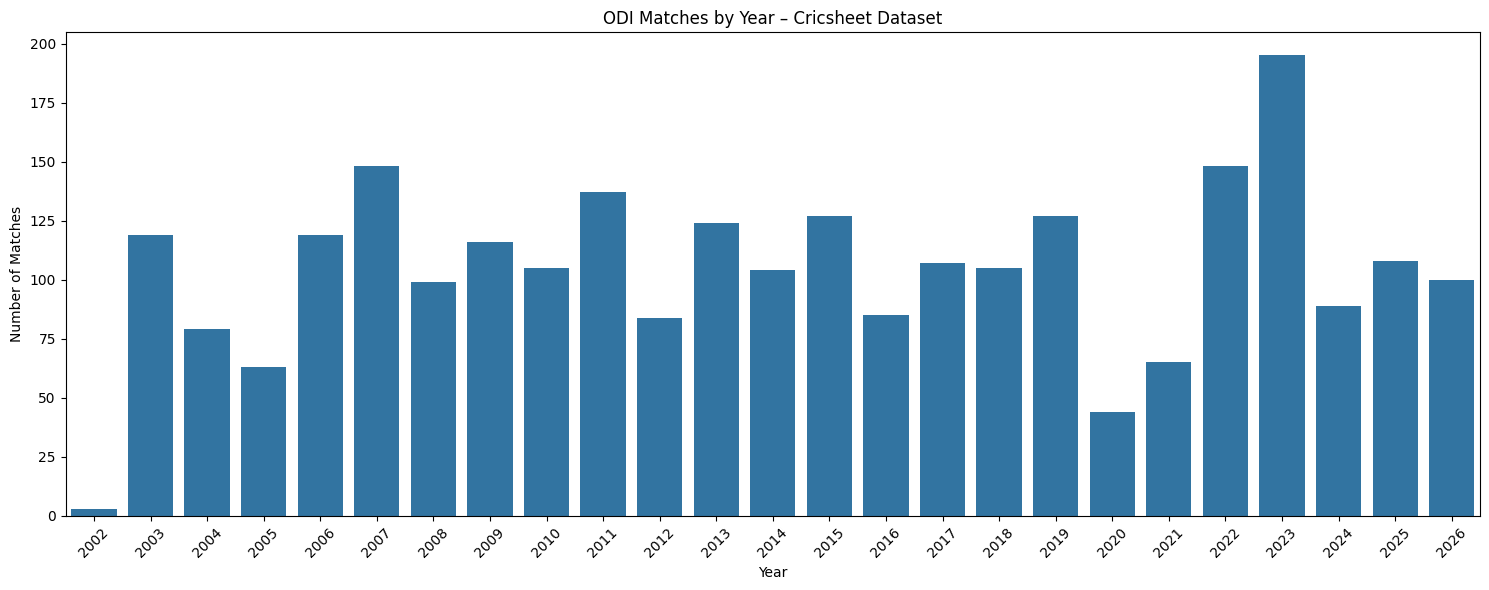

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert date to datetime
match_eda = cricsheet_matches.copy()

match_eda["date"] = pd.to_datetime(
    match_eda["date"],
    errors="coerce"
)

match_eda["year"] = match_eda["date"].dt.year

# Count matches per year
matches_per_year = (
    match_eda.groupby("year")
    .size()
    .sort_index()
)

print("YEAR-WISE ODI MATCH DISTRIBUTION")
print(matches_per_year)

# Visualization
plt.figure(figsize=(15, 6))

sns.barplot(
    x=matches_per_year.index,
    y=matches_per_year.values
)

plt.title("ODI Matches by Year – Cricsheet Dataset")
plt.xlabel("Year")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [12]:
# Team participation analysis

team_appearances = pd.concat([
    cricsheet_matches["team_1"],
    cricsheet_matches["team_2"]
]).value_counts()

# Recorded wins
team_wins = (
    cricsheet_matches["winner"]
    .dropna()
    .value_counts()
)

# Combine both metrics
team_performance = pd.DataFrame({
    "Matches Played": team_appearances,
    "Matches Won": team_wins
}).fillna(0)

team_performance["Win Percentage"] = (
    team_performance["Matches Won"] /
    team_performance["Matches Played"] * 100
).round(2)

team_performance = team_performance.sort_values(
    "Matches Played",
    ascending=False
)

print("=" * 75)
print("CRICKETIQ — TEAM PARTICIPATION AND PERFORMANCE")
print("=" * 75)

print("\nTEAM PERFORMANCE TABLE:")
print(team_performance.to_string())

print("\nTOTAL TEAMS:", len(team_performance))
print("TOTAL TEAM APPEARANCES:", team_appearances.sum())
print("TOTAL RECORDED WINNERS:", team_wins.sum())

CRICKETIQ — TEAM PARTICIPATION AND PERFORMANCE

TEAM PERFORMANCE TABLE:
                          Matches Played  Matches Won  Win Percentage
India                                529          315           59.55
Sri Lanka                            493          229           46.45
Australia                            480          296           61.67
England                              452          225           49.78
Pakistan                             422          216           51.18
New Zealand                          398          212           53.27
West Indies                          396          145           36.62
South Africa                         395          232           58.73
Bangladesh                           334          133           39.82
Zimbabwe                             285           65           22.81
Ireland                              139           49           35.25
United Arab Emirates                 122           41           33.61
Scotland          

In [13]:
# Team participation using integrated dataset

team_appearances = pd.concat([
    integrated_matches["team_1"],
    integrated_matches["team_2"]
]).value_counts()

team_wins = (
    integrated_matches["winner"]
    .dropna()
    .value_counts()
)

team_performance_combined = pd.DataFrame({
    "Matches Played": team_appearances,
    "Matches Won": team_wins
}).fillna(0)

team_performance_combined["Win Percentage"] = (
    team_performance_combined["Matches Won"] /
    team_performance_combined["Matches Played"] * 100
).round(2)

team_performance_combined = (
    team_performance_combined
    .sort_values("Matches Played", ascending=False)
)

print("=" * 75)
print("CRICKETIQ — COMBINED TEAM PARTICIPATION AND PERFORMANCE")
print("=" * 75)

print(team_performance_combined.to_string())

print("\nTOTAL TEAMS:", len(team_performance_combined))
print("TOTAL MATCHES:", len(integrated_matches))
print("TOTAL TEAM APPEARANCES:", team_appearances.sum())
print("TOTAL RECORDED WINNERS:", team_wins.sum())

CRICKETIQ — COMBINED TEAM PARTICIPATION AND PERFORMANCE
                          Matches Played  Matches Won  Win Percentage
India                                536          321           59.89
Sri Lanka                            508          239           47.05
Australia                            485          300           61.86
England                              456          227           49.78
Pakistan                             430          223           51.86
West Indies                          405          150           37.04
New Zealand                          401          215           53.62
South Africa                         401          236           58.85
Bangladesh                           357          144           40.34
Zimbabwe                             318           75           23.58
Ireland                              179           62           34.64
Afghanistan                          153           68           44.44
United Arab Emirates              

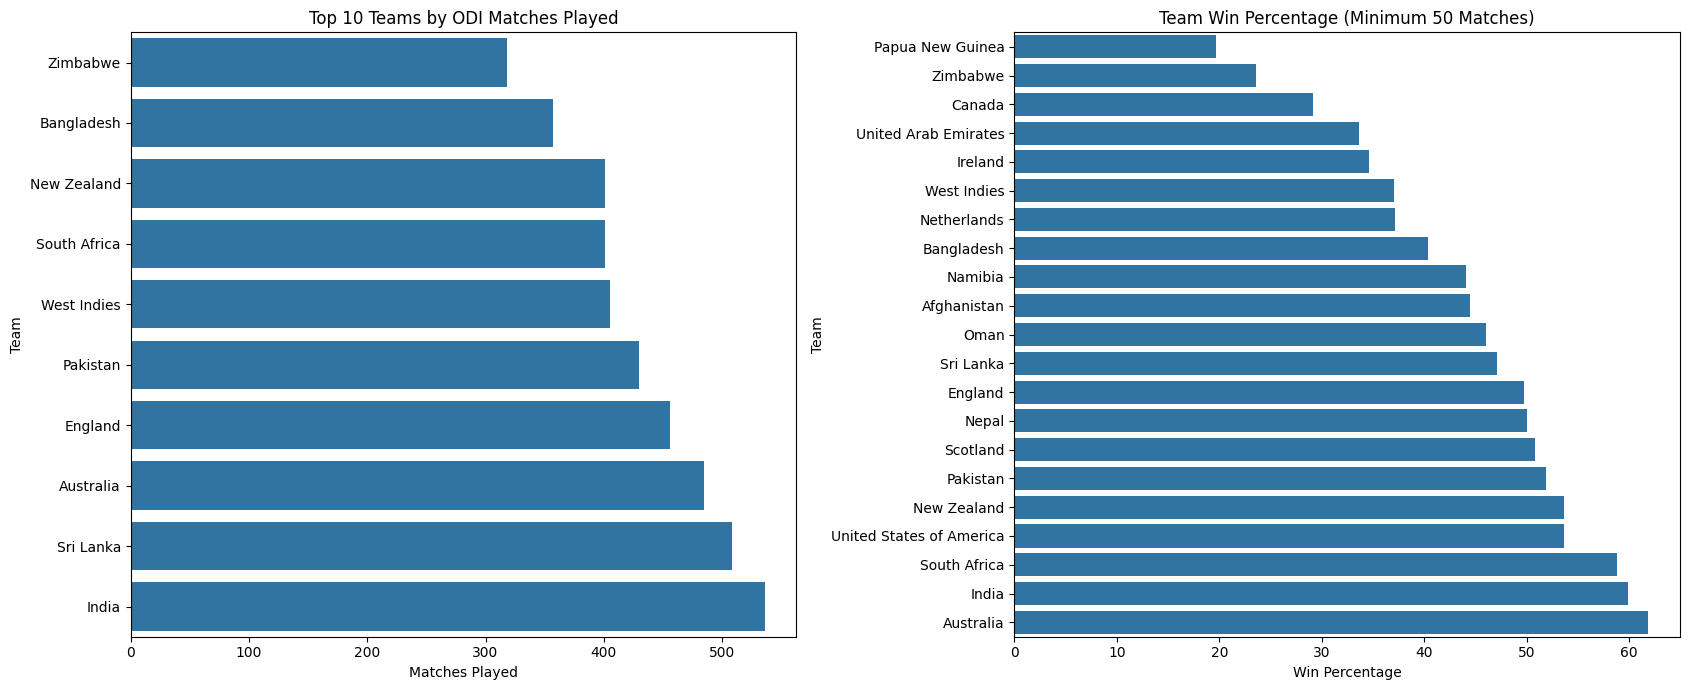

In [14]:
# Top 10 teams by matches played
top_10_matches = (
    team_performance_combined
    .nlargest(10, "Matches Played")
    .sort_values("Matches Played")
)

# Teams with at least 50 matches
reliable_team_comparison = (
    team_performance_combined[
        team_performance_combined["Matches Played"] >= 50
    ]
    .sort_values("Win Percentage")
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Chart 1: Matches played
sns.barplot(
    data=top_10_matches.reset_index(),
    x="Matches Played",
    y="index",
    ax=axes[0]
)

axes[0].set_title("Top 10 Teams by ODI Matches Played")
axes[0].set_xlabel("Matches Played")
axes[0].set_ylabel("Team")

# Chart 2: Win percentage
sns.barplot(
    data=reliable_team_comparison.reset_index(),
    x="Win Percentage",
    y="index",
    ax=axes[1]
)

axes[1].set_title("Team Win Percentage (Minimum 50 Matches)")
axes[1].set_xlabel("Win Percentage")
axes[1].set_ylabel("Team")

plt.tight_layout()
plt.show()

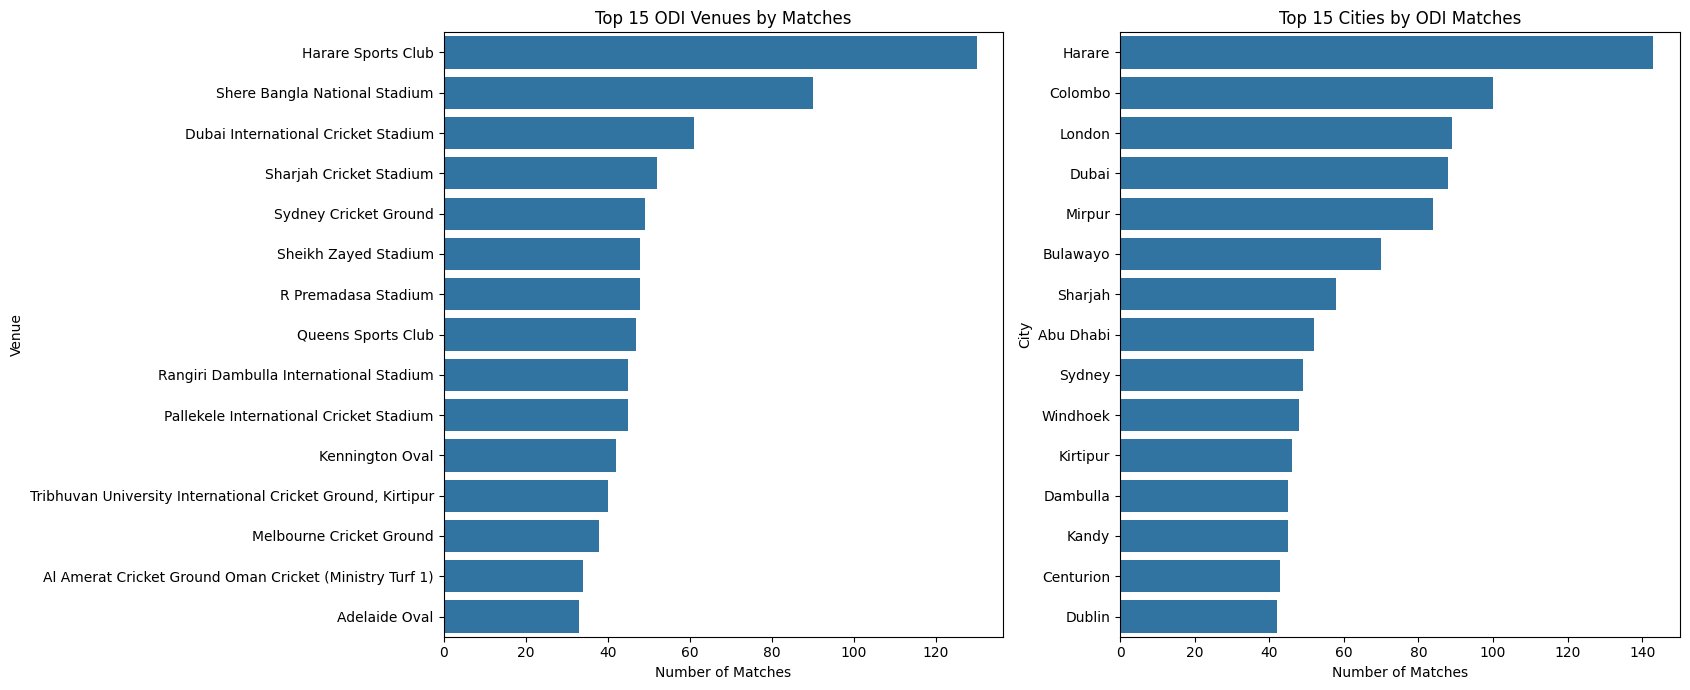

TOP 15 VENUES:
venue
Harare Sports Club                                             130
Shere Bangla National Stadium                                   90
Dubai International Cricket Stadium                             61
Sharjah Cricket Stadium                                         52
Sydney Cricket Ground                                           49
Sheikh Zayed Stadium                                            48
R Premadasa Stadium                                             48
Queens Sports Club                                              47
Rangiri Dambulla International Stadium                          45
Pallekele International Cricket Stadium                         45
Kennington Oval                                                 42
Tribhuvan University International Cricket Ground, Kirtipur     40
Melbourne Cricket Ground                                        38
Al Amerat Cricket Ground Oman Cricket (Ministry Turf 1)         34
Adelaide Oval                            

In [15]:
# Venue analysis using integrated dataset

venue_matches = (
    integrated_matches["venue"]
    .value_counts()
    .head(15)
)

city_matches = (
    integrated_matches["city"]
    .value_counts()
    .head(15)
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.barplot(
    x=venue_matches.values,
    y=venue_matches.index,
    ax=axes[0]
)

axes[0].set_title("Top 15 ODI Venues by Matches")
axes[0].set_xlabel("Number of Matches")
axes[0].set_ylabel("Venue")

sns.barplot(
    x=city_matches.values,
    y=city_matches.index,
    ax=axes[1]
)

axes[1].set_title("Top 15 Cities by ODI Matches")
axes[1].set_xlabel("Number of Matches")
axes[1].set_ylabel("City")

plt.tight_layout()
plt.show()

print("TOP 15 VENUES:")
print(venue_matches)

print("\nTOP 15 CITIES:")
print(city_matches)

CRICKETIQ — TOSS AND MATCH OUTCOME ANALYSIS

VALID MATCHES ANALYSED: 2614

TOSS DECISION DISTRIBUTION:
toss_decision
field    1319
bat      1295
Name: count, dtype: int64

DID THE TOSS WINNER ALSO WIN THE MATCH?
toss_winner_match_winner
False    1310
True     1304
Name: count, dtype: int64

TOSS DECISION VS MATCH VICTORY:
               count  sum      mean  win_percentage
toss_decision                                      
bat             1295  621  0.479537           47.95
field           1319  683  0.517817           51.78


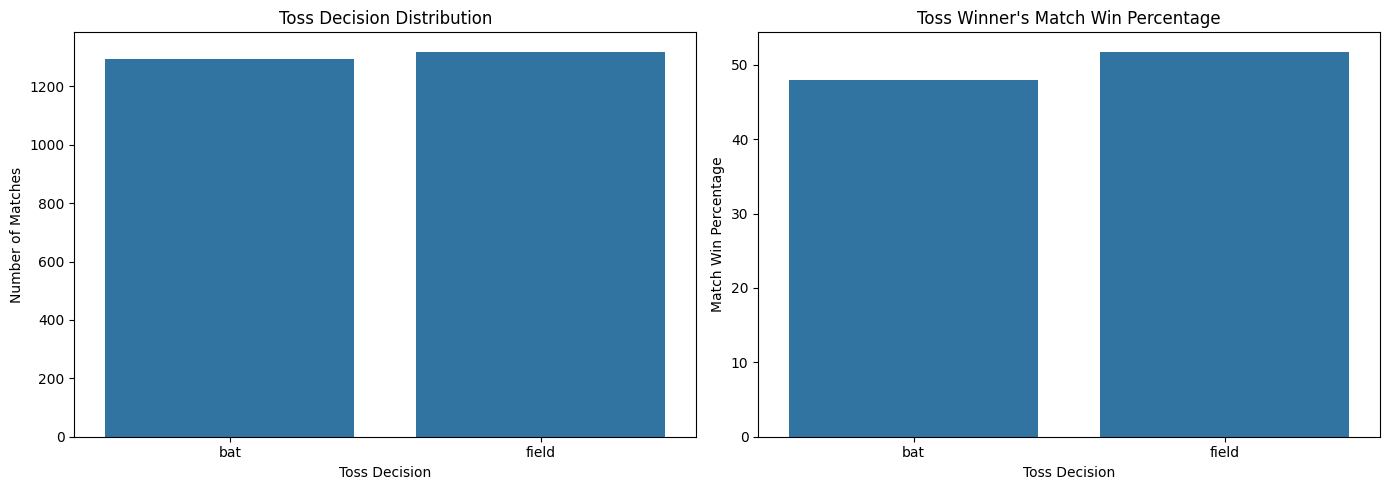

In [16]:
# Toss analysis using integrated historical matches

toss_eda = integrated_matches.copy()

# Remove records with missing toss or winner information
toss_valid = toss_eda.dropna(
    subset=["toss_winner", "toss_decision", "winner"]
).copy()

# Check whether toss winner also won the match
toss_valid["toss_winner_match_winner"] = (
    toss_valid["toss_winner"] == toss_valid["winner"]
)

# Toss decision distribution
toss_decision_counts = (
    toss_valid["toss_decision"]
    .value_counts()
)

# Toss winner match outcome
toss_outcome = (
    toss_valid["toss_winner_match_winner"]
    .value_counts()
)

# Toss decision versus match victory
decision_performance = (
    toss_valid.groupby("toss_decision")
    ["toss_winner_match_winner"]
    .agg(["count", "sum", "mean"])
)

decision_performance["win_percentage"] = (
    decision_performance["mean"] * 100
).round(2)

print("=" * 75)
print("CRICKETIQ — TOSS AND MATCH OUTCOME ANALYSIS")
print("=" * 75)

print("\nVALID MATCHES ANALYSED:", len(toss_valid))

print("\nTOSS DECISION DISTRIBUTION:")
print(toss_decision_counts)

print("\nDID THE TOSS WINNER ALSO WIN THE MATCH?")
print(toss_outcome)

print("\nTOSS DECISION VS MATCH VICTORY:")
print(decision_performance)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=toss_valid,
    x="toss_decision",
    ax=axes[0]
)

axes[0].set_title("Toss Decision Distribution")
axes[0].set_xlabel("Toss Decision")
axes[0].set_ylabel("Number of Matches")

sns.barplot(
    data=decision_performance.reset_index(),
    x="toss_decision",
    y="win_percentage",
    ax=axes[1]
)

axes[1].set_title("Toss Winner's Match Win Percentage")
axes[1].set_xlabel("Toss Decision")
axes[1].set_ylabel("Match Win Percentage")

plt.tight_layout()
plt.show()

In [17]:
# Toss decision analysis by data source

source_toss = integrated_matches.dropna(
    subset=["source", "toss_winner", "toss_decision", "winner"]
).copy()

source_toss["toss_winner_won"] = (
    source_toss["toss_winner"] == source_toss["winner"]
)

source_analysis = (
    source_toss.groupby(["source", "toss_decision"])
    ["toss_winner_won"]
    .agg(["count", "sum", "mean"])
)

source_analysis["win_percentage"] = (
    source_analysis["mean"] * 100
).round(2)

print("=" * 75)
print("CRICKETIQ — TOSS PERFORMANCE BY DATA SOURCE")
print("=" * 75)

print(source_analysis)

CRICKETIQ — TOSS PERFORMANCE BY DATA SOURCE
                         count  sum      mean  win_percentage
source    toss_decision                                      
Crickrida bat               91   47  0.516484           51.65
          field             52   23  0.442308           44.23
Cricsheet bat             1204  574  0.476744           47.67
          field           1267  660  0.520916           52.09


In [18]:
from scipy.stats import chi2_contingency, fisher_exact

print("=" * 75)
print("CRICKETIQ — TOSS DECISION STATISTICAL TESTING")
print("=" * 75)

for source_name, group in source_toss.groupby("source"):

    table = pd.crosstab(
        group["toss_decision"],
        group["toss_winner_won"]
    ).reindex(
        index=["bat", "field"],
        columns=[False, True],
        fill_value=0
    )

    chi2, p_value, dof, expected = chi2_contingency(table)

    odds_ratio, fisher_p = fisher_exact(table)

    print(f"\nSOURCE: {source_name}")
    print("\nContingency table:")
    print(table)

    print(f"\nChi-square statistic: {chi2:.4f}")
    print(f"Chi-square p-value: {p_value:.4f}")
    print(f"Fisher exact p-value: {fisher_p:.4f}")
    print(f"Odds ratio: {odds_ratio:.4f}")

CRICKETIQ — TOSS DECISION STATISTICAL TESTING

SOURCE: Crickrida

Contingency table:
toss_winner_won  False  True 
toss_decision                
bat                 44     47
field               29     23

Chi-square statistic: 0.4620
Chi-square p-value: 0.4967
Fisher exact p-value: 0.4870
Odds ratio: 0.7425

SOURCE: Cricsheet

Contingency table:
toss_winner_won  False  True 
toss_decision                
bat                630    574
field              607    660

Chi-square statistic: 4.6430
Chi-square p-value: 0.0312
Fisher exact p-value: 0.0298
Odds ratio: 1.1934


CRICKETIQ — ODI INNINGS SCORING ANALYSIS

OVERALL INNINGS STATISTICS:
       total_runs  wickets_lost  delivery_records
count     5143.00       5143.00           5143.00
mean       226.89          7.33            268.26
std         70.80          2.77             58.12
min          2.00          0.00              3.00
25%        182.00          5.00            248.00
50%        230.00          8.00            296.00
75%        275.00         10.00            306.00
max        498.00         10.00            326.00

SCORING COMPARISON BY INNINGS:
                count    mean  median  min  max    std
innings_number                                        
1                2600  245.31   250.0    6  498  71.11
2                2531  208.98   212.0    4  438  64.05
3                   6   12.17    11.5    2   30  10.19
4                   6    9.33     8.5    3   15   4.50

TOP 10 HIGHEST INNINGS SCORES:
 match_id  innings_number batting_team  total_runs  wickets_lost
  1281444            

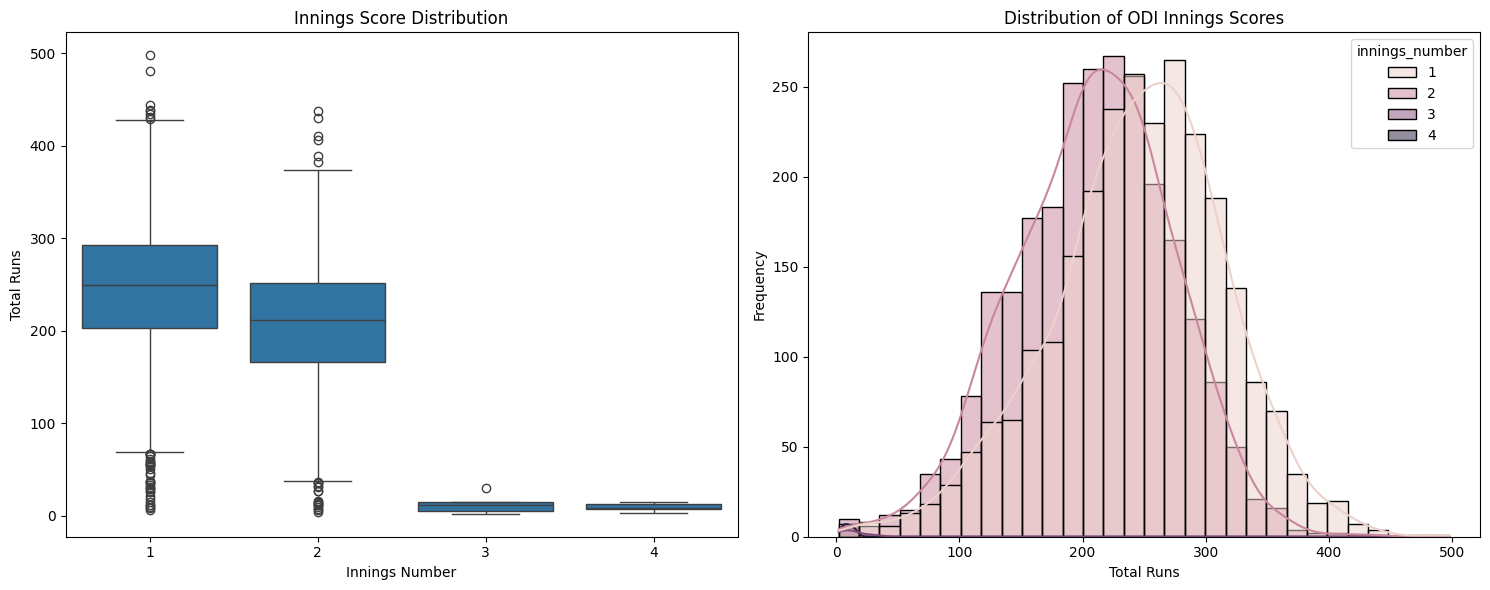

In [19]:
# CRICKETIQ — INNINGS SCORING ANALYSIS

innings_eda = cricsheet_innings.copy()

print("=" * 75)
print("CRICKETIQ — ODI INNINGS SCORING ANALYSIS")
print("=" * 75)

# Overall innings statistics
print("\nOVERALL INNINGS STATISTICS:")

print(
    innings_eda[
        ["total_runs", "wickets_lost", "delivery_records"]
    ].describe().round(2)
)

# First and second innings comparison
innings_comparison = (
    innings_eda.groupby("innings_number")
    ["total_runs"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

print("\nSCORING COMPARISON BY INNINGS:")
print(innings_comparison)

# Highest scoring innings
print("\nTOP 10 HIGHEST INNINGS SCORES:")

print(
    innings_eda.nlargest(10, "total_runs")[
        [
            "match_id",
            "innings_number",
            "batting_team",
            "total_runs",
            "wickets_lost"
        ]
    ].to_string(index=False)
)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(
    data=innings_eda,
    x="innings_number",
    y="total_runs",
    ax=axes[0]
)

axes[0].set_title("Innings Score Distribution")
axes[0].set_xlabel("Innings Number")
axes[0].set_ylabel("Total Runs")

sns.histplot(
    data=innings_eda,
    x="total_runs",
    hue="innings_number",
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of ODI Innings Scores")
axes[1].set_xlabel("Total Runs")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [20]:
# CRICKETIQ — UNUSUAL INNINGS INVESTIGATION

print("=" * 75)
print("CRICKETIQ — UNUSUAL INNINGS ANALYSIS")
print("=" * 75)

# 1. Inspect innings 3 and 4
unusual_innings = cricsheet_innings[
    cricsheet_innings["innings_number"].isin([3, 4])
].copy()

unusual_details = unusual_innings.merge(
    cricsheet_matches[
        ["match_id", "date", "team_1", "team_2", "result_type"]
    ],
    on="match_id",
    how="left"
)

print("\nTHIRD AND FOURTH INNINGS:")
print(
    unusual_details[
        [
            "match_id",
            "date",
            "innings_number",
            "batting_team",
            "total_runs",
            "wickets_lost",
            "team_1",
            "team_2",
            "result_type"
        ]
    ].to_string(index=False)
)

# 2. Identify matches without a second innings
first_innings_ids = set(
    cricsheet_innings.loc[
        cricsheet_innings["innings_number"] == 1,
        "match_id"
    ]
)

second_innings_ids = set(
    cricsheet_innings.loc[
        cricsheet_innings["innings_number"] == 2,
        "match_id"
    ]
)

missing_second_ids = first_innings_ids - second_innings_ids

missing_second_matches = cricsheet_matches[
    cricsheet_matches["match_id"].isin(missing_second_ids)
]

print("\nMATCHES WITHOUT A SECOND INNINGS:")
print("Count:", len(missing_second_ids))

print(
    missing_second_matches[
        [
            "match_id",
            "date",
            "team_1",
            "team_2",
            "winner",
            "result_type"
        ]
    ].to_string(index=False)
)

CRICKETIQ — UNUSUAL INNINGS ANALYSIS

THIRD AND FOURTH INNINGS:
 match_id       date  innings_number             batting_team  total_runs  wickets_lost      team_1                   team_2 result_type
  1144530 2019-07-14               3                  England          15             0     England              New Zealand         Tie
  1144530 2019-07-14               4              New Zealand          15             1     England              New Zealand         Tie
  1233463 2020-11-03               3                 Pakistan           2             2    Zimbabwe                 Pakistan         Tie
  1233463 2020-11-03               4                 Zimbabwe           3             0    Zimbabwe                 Pakistan         Tie
  1377763 2023-06-26               3              Netherlands          30             0 West Indies              Netherlands         Tie
  1377763 2023-06-26               4              West Indies           8             2 West Indies              N

In [21]:
# CRICKETIQ — REGULAR INNINGS VALIDATION

regular_innings = cricsheet_innings[
    cricsheet_innings["innings_number"].isin([1, 2])
].copy()

super_overs = cricsheet_innings[
    cricsheet_innings["innings_number"].isin([3, 4])
].copy()

# Count matches by innings availability
innings_per_match = (
    cricsheet_innings.groupby("match_id")
    ["innings_number"]
    .agg(list)
)

matches_with_one_innings = innings_per_match[
    innings_per_match.apply(lambda x: 1 in x and 2 not in x)
]

matches_with_two_innings = innings_per_match[
    innings_per_match.apply(lambda x: 1 in x and 2 in x)
]

print("=" * 75)
print("CRICKETIQ — REGULAR INNINGS VALIDATION")
print("=" * 75)

print("\nRegular innings records:", len(regular_innings))
print("Super Over records:", len(super_overs))
print("Matches with one regular innings:", len(matches_with_one_innings))
print("Matches with two regular innings:", len(matches_with_two_innings))

print("\nREGULAR INNINGS SCORING STATISTICS:")

print(
    regular_innings.groupby("innings_number")["total_runs"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .round(2)
)

print("\nSUPER OVER MATCHES:", super_overs["match_id"].nunique())

print("\nVALIDATION:")
print(
    "All Super Overs belong to innings 3 or 4:",
    super_overs["innings_number"].isin([3, 4]).all()
)

print(
    "Regular innings contain only innings 1 and 2:",
    regular_innings["innings_number"].isin([1, 2]).all()
)

CRICKETIQ — REGULAR INNINGS VALIDATION

Regular innings records: 5131
Super Over records: 12
Matches with one regular innings: 69
Matches with two regular innings: 2531

REGULAR INNINGS SCORING STATISTICS:
                count    mean  median  min  max    std
innings_number                                        
1                2600  245.31   250.0    6  498  71.11
2                2531  208.98   212.0    4  438  64.05

SUPER OVER MATCHES: 6

VALIDATION:
All Super Overs belong to innings 3 or 4: True
Regular innings contain only innings 1 and 2: True


In [22]:
import ast
import numpy as np

# Use regular ODI deliveries only
batting_eda = deliveries_eda[
    deliveries_eda["innings_number"].isin([1, 2])
].copy()

# Convert extras into dictionaries
def parse_extras(value):
    if pd.isna(value):
        return {}
    if isinstance(value, dict):
        return value
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return {}

batting_eda["extras_dict"] = (
    batting_eda["extras"].apply(parse_extras)
)

# Calculate balls faced
# Wide deliveries are excluded; no-balls are included
batting_eda["balls_faced"] = (
    ~batting_eda["extras_dict"].apply(
        lambda x: "wides" in x
    )
).astype(int)

# Identify boundaries using batter runs
batting_eda["fours"] = (
    batting_eda["batter_runs"] == 4
).astype(int)

batting_eda["sixes"] = (
    batting_eda["batter_runs"] == 6
).astype(int)

# Aggregate individual batting performance
batter_stats = (
    batting_eda.groupby("batter")
    .agg(
        total_runs=("batter_runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum"),
        innings_played=(
            "delivery_event_id",
            "nunique"
        )
    )
)

# Calculate strike rate
batter_stats["strike_rate"] = np.where(
    batter_stats["balls_faced"] > 0,
    batter_stats["total_runs"] /
    batter_stats["balls_faced"] * 100,
    np.nan
)

# Sort by total runs
batter_stats = batter_stats.sort_values(
    "total_runs",
    ascending=False
)

print("=" * 75)
print("CRICKETIQ — BATTER PERFORMANCE ANALYSIS")
print("=" * 75)

print("\nTOTAL BATTERS:", len(batter_stats))

print("\nTOP 15 RUN SCORERS:")
print(batter_stats.head(15).round(2).to_string())

print("\nOVERALL BATTING STATISTICS:")
print(
    batter_stats[
        ["total_runs", "balls_faced", "fours", "sixes", "strike_rate"]
    ].describe().round(2)
)

CRICKETIQ — BATTER PERFORMANCE ANALYSIS

TOTAL BATTERS: 1934

TOP 15 RUN SCORERS:
                  total_runs  balls_faced  fours  sixes  innings_played  strike_rate
batter                                                                              
V Kohli                14987        15892   1392    183           16205        94.31
RG Sharma              11757        12673   1110    369           12914        92.77
KC Sangakkara          11530        14170   1105     76           14507        81.37
MS Dhoni               10100        11681    770    203           11948        86.47
AB de Villiers          9324         9225    813    196            9388       101.07
TM Dilshan              9212        10538   1022     50           10777        87.42
LRPL Taylor             8126         9791    674    133           10040        82.99
DPMD Jayawardene        7852         9781    723     48           10052        80.28
HM Amla                 7834         8861    796     49            9

In [23]:
# Calculate actual batting innings per batter
batter_innings_count = (
    batting_eda[
        ["batter", "match_id", "innings_number"]
    ]
    .drop_duplicates()
    .groupby("batter")
    .size()
    .rename("innings_played")
)

# Replace the incorrect innings count
batter_stats = batter_stats.drop(
    columns=["innings_played"]
)

batter_stats = batter_stats.join(
    batter_innings_count
)

# Recalculate strike rate for verification
batter_stats["strike_rate"] = (
    batter_stats["total_runs"] /
    batter_stats["balls_faced"] * 100
).round(2)

print("=" * 75)
print("CRICKETIQ — CORRECTED BATTER STATISTICS")
print("=" * 75)

print("\nTOP 15 RUN SCORERS:")

print(
    batter_stats.head(15).round(2).to_string()
)

print("\nCORRECTED OVERALL STATISTICS:")

print(
    batter_stats[
        [
            "total_runs",
            "balls_faced",
            "innings_played",
            "fours",
            "sixes",
            "strike_rate"
        ]
    ].describe().round(2)
)

CRICKETIQ — CORRECTED BATTER STATISTICS

TOP 15 RUN SCORERS:
                  total_runs  balls_faced  fours  sixes  strike_rate  innings_played
batter                                                                              
V Kohli                14987        15892   1392    183        94.31             302
RG Sharma              11757        12673   1110    369        92.77             276
KC Sangakkara          11530        14170   1105     76        81.37             280
MS Dhoni               10100        11681    770    203        86.47             276
AB de Villiers          9324         9225    813    196       101.07             209
TM Dilshan              9212        10538   1022     50        87.42             259
LRPL Taylor             8126         9791    674    133        82.99             209
DPMD Jayawardene        7852         9781    723     48        80.28             260
HM Amla                 7834         8861    796     49        88.41             174
JE R

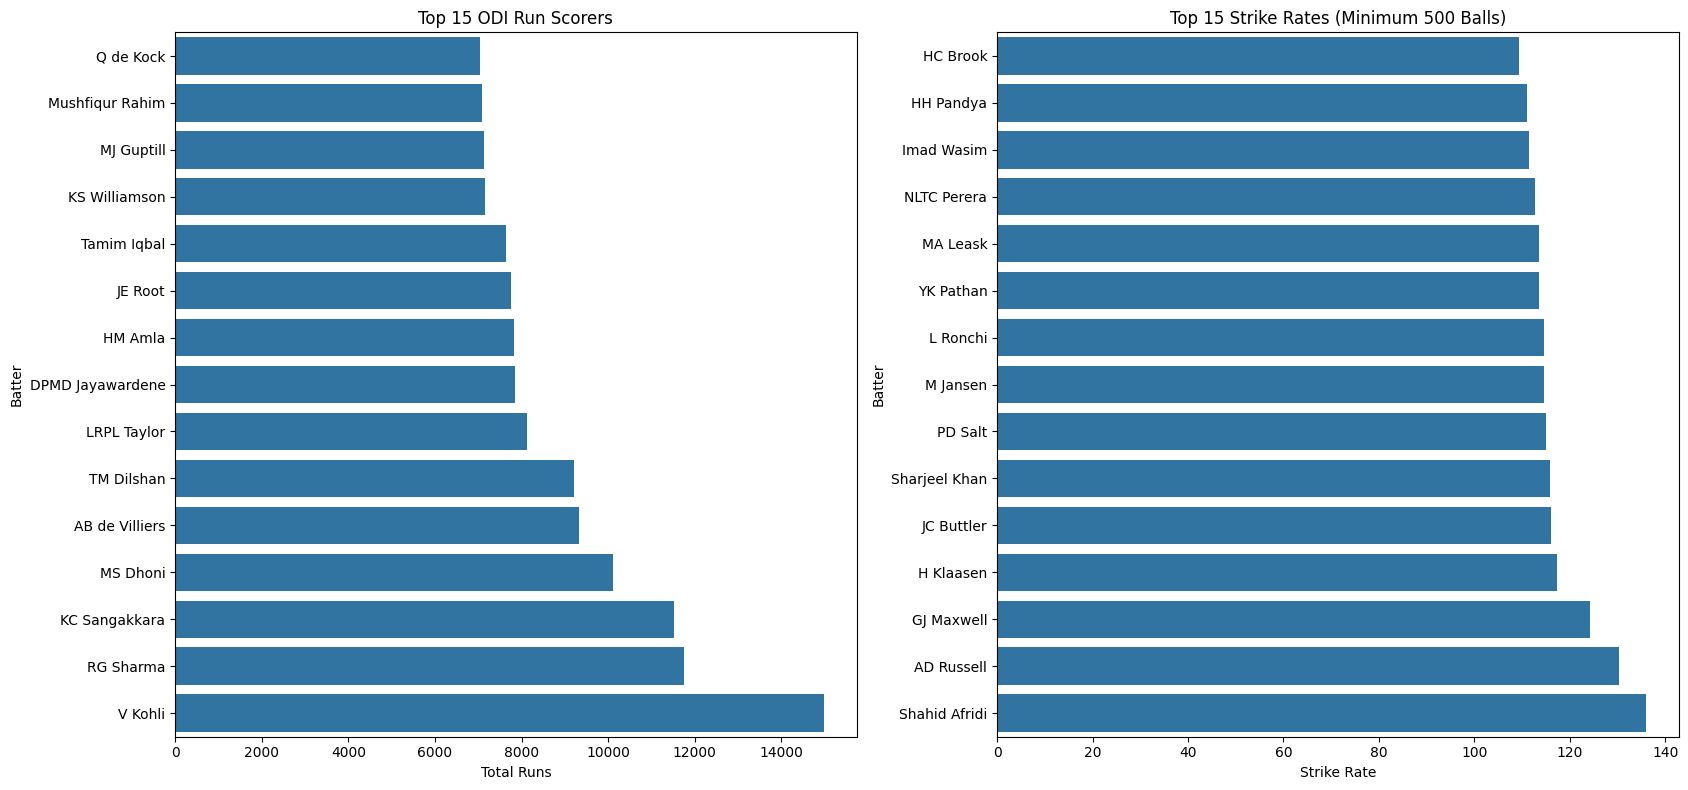

TOP 15 RUN SCORERS:
                  total_runs  innings_played  strike_rate
batter                                                   
Q de Kock               7043             162        96.69
Mushfiqur Rahim         7096             227        80.79
MJ Guptill              7124             190        87.26
KS Williamson           7145             165        81.67
Tamim Iqbal             7648             215        79.00
JE Root                 7762             183        87.35
HM Amla                 7834             174        88.41
DPMD Jayawardene        7852             260        80.28
LRPL Taylor             8126             209        82.99
TM Dilshan              9212             259        87.42
AB de Villiers          9324             209       101.07
MS Dhoni               10100             276        86.47
KC Sangakkara          11530             280        81.37
RG Sharma              11757             276        92.77
V Kohli                14987             302        

In [24]:
# CRICKETIQ — BATTING PERFORMANCE VISUALIZATION

# Top 15 run scorers
top_run_scorers = (
    batter_stats.nlargest(15, "total_runs")
    .sort_values("total_runs")
)

# Top 15 strike rates among batters with at least 500 balls
qualified_batters = batter_stats[
    batter_stats["balls_faced"] >= 500
]

top_strike_rates = (
    qualified_batters.nlargest(15, "strike_rate")
    .sort_values("strike_rate")
)

fig, axes = plt.subplots(1, 2, figsize=(17, 8))

# Total runs
sns.barplot(
    x=top_run_scorers["total_runs"],
    y=top_run_scorers.index,
    ax=axes[0]
)

axes[0].set_title("Top 15 ODI Run Scorers")
axes[0].set_xlabel("Total Runs")
axes[0].set_ylabel("Batter")

# Strike rates
sns.barplot(
    x=top_strike_rates["strike_rate"],
    y=top_strike_rates.index,
    ax=axes[1]
)

axes[1].set_title("Top 15 Strike Rates (Minimum 500 Balls)")
axes[1].set_xlabel("Strike Rate")
axes[1].set_ylabel("Batter")

plt.tight_layout()
plt.show()

print("TOP 15 RUN SCORERS:")
print(top_run_scorers[["total_runs", "innings_played", "strike_rate"]])

print("\nTOP 15 QUALIFIED STRIKE RATES:")
print(
    top_strike_rates[
        ["total_runs", "balls_faced", "innings_played", "strike_rate"]
    ]
)

In [25]:
# CRICKETIQ — DISMISSAL DATA INSPECTION

print("=" * 75)
print("CRICKETIQ — WICKET DATA STRUCTURE")
print("=" * 75)

print("\nWICKETS COLUMN DATA TYPE:")
print(deliveries_eda["wickets"].dtype)

print("\nNON-NULL WICKET RECORDS:")
print(deliveries_eda["wickets"].notna().sum())

print("\nSAMPLE WICKET VALUES:")

sample_wickets = (
    deliveries_eda.loc[
        deliveries_eda["wickets"].notna(),
        ["match_id", "innings_number", "over",
         "batter", "wickets"]
    ]
    .head(15)
)

print(sample_wickets.to_string(index=False))

print("\nUNIQUE SAMPLE VALUE TYPES:")
print(
    deliveries_eda["wickets"]
    .dropna()
    .map(type)
    .value_counts()
)

CRICKETIQ — WICKET DATA STRUCTURE

WICKETS COLUMN DATA TYPE:
object

NON-NULL WICKET RECORDS:
37770

SAMPLE WICKET VALUES:
 match_id  innings_number  over             batter                                                                                                            wickets
  1000887               1     4          DA Warner                                                                    [{'kind': 'bowled', 'player_out': 'DA Warner'}]
  1000887               1     4          SPD Smith                         [{'kind': 'caught', 'player_out': 'SPD Smith', 'fielders': [{'name': 'Mohammad Rizwan'}]}]
  1000887               1     9            CA Lynn                           [{'kind': 'caught', 'player_out': 'CA Lynn', 'fielders': [{'name': 'Mohammad Rizwan'}]}]
  1000887               1    12            TM Head                           [{'kind': 'caught', 'player_out': 'TM Head', 'fielders': [{'name': 'Mohammad Rizwan'}]}]
  1000887               1    16           MR Ma

In [26]:
import ast
from collections import Counter

# Parse wicket records
wicket_kinds = Counter()
dismissed_players = []

for value in deliveries_eda["wickets"].dropna():

    try:
        wicket_events = (
            value if isinstance(value, list)
            else ast.literal_eval(value)
        )

        for wicket in wicket_events:

            kind = wicket.get("kind", "unknown")
            player_out = wicket.get("player_out")

            wicket_kinds[kind] += 1

            dismissed_players.append({
                "player_out": player_out,
                "dismissal_kind": kind
            })

    except (ValueError, SyntaxError, TypeError):
        continue

print("=" * 75)
print("CRICKETIQ — DISMISSAL TYPE ANALYSIS")
print("=" * 75)

print("\nDISMISSAL TYPES AND FREQUENCIES:")

for kind, count in wicket_kinds.most_common():
    print(f"{kind:25} {count}")

print("\nTOTAL DISMISSAL EVENTS:", sum(wicket_kinds.values()))

print(
    "\nUNIQUE DISMISSED PLAYER NAMES:",
    len(set(
        item["player_out"]
        for item in dismissed_players
        if item["player_out"]
    ))
)

CRICKETIQ — DISMISSAL TYPE ANALYSIS

DISMISSAL TYPES AND FREQUENCIES:
caught                    21628
bowled                    7087
lbw                       4188
run out                   2729
caught and bowled         1138
stumped                   898
retired hurt              61
hit wicket                36
obstructing the field     6
timed out                 1

TOTAL DISMISSAL EVENTS: 37772

UNIQUE DISMISSED PLAYER NAMES: 1843


In [27]:
# CRICKETIQ — CRICSHEET VENUE DATA AVAILABILITY

venue_eda = cricsheet_matches.copy()

# Identify missing and blank venue values
venue_eda["venue_missing"] = (
    venue_eda["venue"].isna() |
    venue_eda["venue"].astype("string").str.strip().eq("").fillna(True)
)

total_matches = len(venue_eda)

matches_with_venue = (~venue_eda["venue_missing"]).sum()
matches_without_venue = venue_eda["venue_missing"].sum()

venue_coverage = (
    matches_with_venue / total_matches * 100
)

venue_missing_percentage = (
    matches_without_venue / total_matches * 100
)

print("=" * 75)
print("CRICKETIQ — CRICSHEET VENUE DATA AVAILABILITY")
print("=" * 75)

print(f"\nTotal matches: {total_matches}")
print(f"Matches with venue: {matches_with_venue}")
print(f"Matches without venue: {matches_without_venue}")

print(f"\nVenue coverage: {venue_coverage:.2f}%")
print(f"Missing venue percentage: {venue_missing_percentage:.2f}%")

print("\nVENUE DATA VALIDATION:")
print("Unique venues:", venue_eda.loc[
    ~venue_eda["venue_missing"], "venue"
].nunique())

print("\nMATCHES WITHOUT VENUE INFORMATION:")

print(
    venue_eda.loc[
        venue_eda["venue_missing"],
        ["match_id", "date", "team_1", "team_2", "city"]
    ].to_string(index=False)
)

CRICKETIQ — CRICSHEET VENUE DATA AVAILABILITY

Total matches: 2600
Matches with venue: 2600
Matches without venue: 0

Venue coverage: 100.00%
Missing venue percentage: 0.00%

VENUE DATA VALIDATION:
Unique venues: 319

MATCHES WITHOUT VENUE INFORMATION:
Empty DataFrame
Columns: [match_id, date, team_1, team_2, city]
Index: []


In [28]:
# CRICKETIQ — VENUE AND CITY DATA QUALITY

venue_city_eda = cricsheet_matches.copy()

# Check missing and blank values
for column in ["venue", "city"]:
    venue_city_eda[column] = (
        venue_city_eda[column].astype("string").str.strip()
    )

print("=" * 75)
print("CRICKETIQ — VENUE AND CITY DATA QUALITY")
print("=" * 75)

for column in ["venue", "city"]:

    missing = (
        venue_city_eda[column].isna() |
        venue_city_eda[column].eq("")
    )

    print(f"\n{column.upper()} ANALYSIS")
    print("Total records:", len(venue_city_eda))
    print("Available:", (~missing).sum())
    print("Missing:", missing.sum())
    print(
        "Coverage:",
        round((~missing).mean() * 100, 2),
        "%"
    )
    print(
        "Unique values:",
        venue_city_eda.loc[~missing, column].nunique()
    )

# Check repeated venue-city combinations
venue_city_combinations = (
    venue_city_eda.groupby(
        ["venue", "city"],
        dropna=False
    )
    .size()
    .reset_index(name="match_count")
    .sort_values("match_count", ascending=False)
)

print("\nTOP 15 VENUE-CITY COMBINATIONS:")
print(venue_city_combinations.head(15).to_string(index=False))

print("\nVENUES ASSOCIATED WITH MULTIPLE CITIES:")

venue_city_counts = (
    venue_city_eda.groupby("venue")["city"]
    .nunique()
)

print(venue_city_counts[venue_city_counts > 1])

CRICKETIQ — VENUE AND CITY DATA QUALITY

VENUE ANALYSIS
Total records: 2600
Available: 2600
Missing: 0
Coverage: 100.0 %
Unique values: 319

CITY ANALYSIS
Total records: 2600
Available: 2319
Missing: 281
Coverage: 89.19 %
Unique values: 149

TOP 15 VENUE-CITY COMBINATIONS:
                                                      venue       city  match_count
                              Shere Bangla National Stadium     Mirpur           83
                                         Harare Sports Club       <NA>           62
                                         Harare Sports Club     Harare           54
                                        R Premadasa Stadium    Colombo           47
                                            Kennington Oval     London           42
Tribhuvan University International Cricket Ground, Kirtipur   Kirtipur           40
                                         Queens Sports Club   Bulawayo           37
                                       Sheikh Zayed St

In [29]:
# CRICKETIQ — MISSING CITY INVESTIGATION

missing_city_records = venue_city_eda[
    venue_city_eda["city"].isna() |
    venue_city_eda["city"].eq("")
].copy()

# Add year
missing_city_records["year"] = pd.to_datetime(
    missing_city_records["date"],
    errors="coerce"
).dt.year

print("=" * 75)
print("CRICKETIQ — MISSING CITY INVESTIGATION")
print("=" * 75)

print("\nMISSING CITY RECORDS BY YEAR:")

print(
    missing_city_records["year"]
    .value_counts()
    .sort_index()
)

print("\nTOP 20 VENUES WITH MISSING CITY:")

print(
    missing_city_records["venue"]
    .value_counts()
    .head(20)
)

print("\nMISSING CITY RECORDS BY TEAM:")

missing_teams = pd.concat([
    missing_city_records["team_1"],
    missing_city_records["team_2"]
]).value_counts()

print(missing_teams.head(20))

print("\nSAMPLE MISSING CITY MATCHES:")

print(
    missing_city_records[
        ["match_id", "date", "team_1", "team_2", "venue"]
    ].head(20).to_string(index=False)
)

CRICKETIQ — MISSING CITY INVESTIGATION

MISSING CITY RECORDS BY YEAR:
year
2005     9
2006    13
2007    18
2008    19
2009    12
2010    29
2011    20
2012    19
2013    21
2014    22
2015    34
2016    14
2017    15
2018    31
2020     5
Name: count, dtype: int64

TOP 20 VENUES WITH MISSING CITY:
venue
Harare Sports Club                         62
Rangiri Dambulla International Stadium     36
Sydney Cricket Ground                      35
Melbourne Cricket Ground                   29
Adelaide Oval                              27
Dubai International Cricket Stadium        25
Pallekele International Cricket Stadium    24
Sharjah Cricket Stadium                    15
Multan Cricket Stadium                      5
Rawalpindi Cricket Stadium                  5
Queenstown Events Centre                    5
Chittagong Divisional Stadium               3
Galle International Stadium                 2
Perth Stadium                               2
Mombasa Sports Club Ground                  2
Duba

In [30]:
# CRICKETIQ — COMPLETE MISSING CITY VENUE INVENTORY

# Identify records with missing city
missing_city_records = venue_city_eda[
    venue_city_eda["city"].isna() |
    venue_city_eda["city"].eq("")
].copy()

# Count missing-city matches for each venue
missing_venue_summary = (
    missing_city_records
    .groupby("venue")
    .agg(
        matches_missing_city=("match_id", "count"),
        first_occurrence=("date", "min"),
        last_occurrence=("date", "max")
    )
)

# Identify cities recorded for these venues elsewhere
known_cities = (
    venue_city_eda[
        venue_city_eda["city"].notna() &
        venue_city_eda["city"].ne("")
    ]
    .groupby("venue")["city"]
    .agg(lambda x: sorted(x.unique().tolist()))
    .rename("known_cities_elsewhere")
)

# Combine results
missing_venue_summary = (
    missing_venue_summary
    .join(known_cities)
    .sort_values("matches_missing_city", ascending=False)
)

missing_venue_summary["known_cities_elsewhere"] = (
    missing_venue_summary["known_cities_elsewhere"]
    .apply(lambda x: x if isinstance(x, list) else [])
)

print("=" * 85)
print("CRICKETIQ — COMPLETE MISSING CITY VENUE INVENTORY")
print("=" * 85)

print("\nTOTAL MATCHES WITH MISSING CITY:",
      len(missing_city_records))

print("UNIQUE VENUES WITH MISSING CITY:",
      len(missing_venue_summary))

print("\nALL AFFECTED VENUES:")
print(missing_venue_summary.to_string())

print("\nVENUES WITH NO CITY RECORDED ANYWHERE:",
      (missing_venue_summary["known_cities_elsewhere"].str.len() == 0).sum())

print("\nVENUES WITH CITY AVAILABLE IN OTHER MATCHES:",
      (missing_venue_summary["known_cities_elsewhere"].str.len() > 0).sum())

CRICKETIQ — COMPLETE MISSING CITY VENUE INVENTORY

TOTAL MATCHES WITH MISSING CITY: 281
UNIQUE VENUES WITH MISSING CITY: 18

ALL AFFECTED VENUES:
                                         matches_missing_city first_occurrence last_occurrence known_cities_elsewhere
venue                                                                                                                
Harare Sports Club                                         62       2005-08-29      2018-03-22               [Harare]
Rangiri Dambulla International Stadium                     36       2005-07-31      2018-10-13             [Dambulla]
Sydney Cricket Ground                                      35       2006-01-22      2020-11-29               [Sydney]
Melbourne Cricket Ground                                   29       2005-02-04      2018-01-14            [Melbourne]
Adelaide Oval                                              27       2005-01-26      2018-11-09             [Adelaide]
Dubai International Cricket 

In [31]:
# Create a clean copy — preserve the original EDA dataset
venue_city_clean = venue_city_eda.copy()

# Venue-to-city mapping based on the information you provided
venue_city_mapping = {
    "Harare Sports Club": "Harare",
    "Rangiri Dambulla International Stadium": "Dambulla",
    "Sydney Cricket Ground": "Sydney",
    "Melbourne Cricket Ground": "Melbourne",
    "Adelaide Oval": "Adelaide",
    "Dubai International Cricket Stadium": "Dubai",
    "Pallekele International Cricket Stadium": "Kandy",
    "Sharjah Cricket Stadium": "Sharjah",
    "Rawalpindi Cricket Stadium": "Rawalpindi",
    "Multan Cricket Stadium": "Multan",
    "Queenstown Events Centre": "Queenstown",
    "Chittagong Divisional Stadium": "Chittagong",
    "Mombasa Sports Club Ground": "Mombasa",
    "Dubai Sports City Cricket Stadium": "Dubai",
    "Perth Stadium": "Perth",
    "Galle International Stadium": "Galle",
    "Bulawayo Athletic Club": "Bulawayo",
    "Sheikhupura Stadium": "Sheikhupura"
}

# Identify missing city values
missing_city_mask = (
    venue_city_clean["city"].isna() |
    venue_city_clean["city"].astype(str).str.strip().eq("")
)

# Fill missing cities using the venue mapping
venue_city_clean.loc[missing_city_mask, "city"] = (
    venue_city_clean.loc[missing_city_mask, "venue"]
    .map(venue_city_mapping)
)

# Validate the result
remaining_missing = (
    venue_city_clean["city"].isna() |
    venue_city_clean["city"].astype(str).str.strip().eq("")
)

print("CRICKETIQ — VENUE CITY MAPPING VALIDATION")
print("=" * 60)

print("Original records:", len(venue_city_eda))
print("Cleaned records:", len(venue_city_clean))
print("Cities filled:", missing_city_mask.sum())
print("Remaining missing cities:", remaining_missing.sum())
print("Unique venues:", venue_city_clean["venue"].nunique())
print("Unique cities:", venue_city_clean["city"].nunique())

print("\nRemaining venues with missing city:")
print(
    venue_city_clean.loc[remaining_missing, "venue"]
    .value_counts()
)

# Confirm original dataset was not modified
print("\nOriginal dataset missing cities:",
      venue_city_eda["city"].isna().sum())

CRICKETIQ — VENUE CITY MAPPING VALIDATION
Original records: 2600
Cleaned records: 2600
Cities filled: 281
Remaining missing cities: 0
Unique venues: 319
Unique cities: 152

Remaining venues with missing city:
Series([], Name: count, dtype: Int64)

Original dataset missing cities: 281


In [32]:
# Check whether any venue is associated with multiple cities

venue_city_consistency = (
    venue_city_clean
    .groupby("venue")["city"]
    .nunique()
    .reset_index(name="unique_city_count")
)

inconsistent_venues = venue_city_consistency[
    venue_city_consistency["unique_city_count"] > 1
]

print("TOTAL UNIQUE VENUES:", len(venue_city_consistency))
print("VENUES WITH MULTIPLE CITIES:", len(inconsistent_venues))

if len(inconsistent_venues) > 0:
    for venue in inconsistent_venues["venue"]:
        cities = sorted(
            venue_city_clean.loc[
                venue_city_clean["venue"] == venue, "city"
            ].unique()
        )
        print(f"\n{venue}: {cities}")
else:
    print("All venues are consistently associated with one city.")

TOTAL UNIQUE VENUES: 319
VENUES WITH MULTIPLE CITIES: 5

Himachal Pradesh Cricket Association Stadium: ['Dharamsala', 'Dharmasala']

Maple Leaf North-West Ground: ['King City', 'Toronto']

Nehru Stadium: ['Guwahati', 'Kochi', 'Pune']

Shere Bangla National Stadium: ['Dhaka', 'Mirpur']

Zahur Ahmed Chowdhury Stadium: ['Chattogram', 'Chittagong']


In [33]:
import pandas as pd

# Load the Afghanistan match-level dataset
afghanistan_matches = pd.read_csv(
    r"C:\CricIQ\data\processed\afghanistan_odi\afghanistan_odi_match_level.csv"
)

print("=" * 65)
print("CRICKETIQ — ORIGINAL DATASET COMPARISON")
print("=" * 65)

print("\nCRICSHEET DATASET")
print("Shape:", cricsheet_matches.shape)
print("Columns:", cricsheet_matches.columns.tolist())

print("\nAFGHANISTAN DATASET")
print("Shape:", afghanistan_matches.shape)
print("Columns:", afghanistan_matches.columns.tolist())

print("\nCRICSHEET VENUE/CITY SAMPLE")
print(cricsheet_matches[["venue", "city"]].head(10).to_string(index=False))

print("\nAFGHANISTAN VENUE/CITY SAMPLE")
print(afghanistan_matches[["venue", "city"]].head(10).to_string(index=False))

print("\nMISSING VENUE/CITY COUNTS")
print("Cricsheet:")
print(cricsheet_matches[["venue", "city"]].isna().sum())

print("\nAfghanistan:")
print(afghanistan_matches[["venue", "city"]].isna().sum())

CRICKETIQ — ORIGINAL DATASET COMPARISON

CRICSHEET DATASET
Shape: (2600, 17)
Columns: ['match_id', 'date', 'team_1', 'team_2', 'venue', 'city', 'season', 'event', 'toss_winner', 'toss_decision', 'winner', 'win_by_runs', 'win_by_wickets', 'gender', 'match_type', 'team_type', 'result_type']

AFGHANISTAN DATASET
Shape: (153, 45)
Columns: ['date', 'match', 'format', 'result', 'match_url', 'batting_innings_count', 'bowling_innings_count', 'scorecard_status', 'venue', 'city', 'toss_winner', 'toss_decision', 'result_type', 'result_margin', 'team_1', 'team_2', 'afghanistan_innings_number', 'afghanistan_runs', 'afghanistan_wickets', 'afghanistan_extras', 'afghanistan_batter_runs', 'afghanistan_balls_faced', 'afghanistan_fours', 'afghanistan_sixes', 'afghanistan_legal_balls', 'opponent_innings_number', 'opponent', 'opponent_runs', 'opponent_wickets', 'opponent_extras', 'opponent_batter_runs', 'opponent_balls_faced', 'opponent_fours', 'opponent_sixes', 'opponent_legal_balls', 'innings_status', 'a

In [34]:
# Create venue-city reference tables from both original datasets

cricsheet_venue_cities = (
    cricsheet_matches
    .dropna(subset=["venue"])
    .groupby("venue")["city"]
    .agg(lambda x: sorted(x.dropna().astype(str).str.strip().unique()))
    .rename("cricsheet_cities")
)

afghanistan_venue_cities = (
    afghanistan_matches
    .dropna(subset=["venue"])
    .groupby("venue")["city"]
    .agg(lambda x: sorted(x.dropna().astype(str).str.strip().unique()))
    .rename("afghanistan_cities")
)

# Combine both sources by venue name
venue_source_comparison = pd.concat(
    [cricsheet_venue_cities, afghanistan_venue_cities],
    axis=1
)

# Identify venues present in both datasets
common_venues = venue_source_comparison[
    venue_source_comparison["cricsheet_cities"].notna() &
    venue_source_comparison["afghanistan_cities"].notna()
].copy()

# Identify venues present in only one dataset
cricsheet_only = venue_source_comparison[
    venue_source_comparison["cricsheet_cities"].notna() &
    venue_source_comparison["afghanistan_cities"].isna()
]

afghanistan_only = venue_source_comparison[
    venue_source_comparison["cricsheet_cities"].isna() &
    venue_source_comparison["afghanistan_cities"].notna()
]

print("=" * 70)
print("CRICKETIQ — VENUE COMPARISON ACROSS DATA SOURCES")
print("=" * 70)

print("\nUNIQUE VENUES")
print("Cricsheet:", len(cricsheet_venue_cities))
print("Afghanistan:", len(afghanistan_venue_cities))
print("Common venues:", len(common_venues))
print("Cricsheet-only venues:", len(cricsheet_only))
print("Afghanistan-only venues:", len(afghanistan_only))

print("\nCOMMON VENUES — CITY INFORMATION FROM BOTH SOURCES")
print(common_venues.to_string())

print("\nVENUES ONLY IN CRICSHEET:", len(cricsheet_only))
print(cricsheet_only.to_string())

print("\nVENUES ONLY IN AFGHANISTAN DATASET:", len(afghanistan_only))
print(afghanistan_only.to_string())

CRICKETIQ — VENUE COMPARISON ACROSS DATA SOURCES

UNIQUE VENUES
Cricsheet: 319
Afghanistan: 39
Common venues: 27
Cricsheet-only venues: 292
Afghanistan-only venues: 12

COMMON VENUES — CITY INFORMATION FROM BOTH SOURCES
                                                      cricsheet_cities       afghanistan_cities
venue                                                                                          
Arun Jaitley Stadium                                           [Delhi]                  [Delhi]
Clontarf Cricket Club Ground                                  [Dublin]                 [Dublin]
County Ground                                                [Bristol]       [Bristol, Taunton]
Daren Sammy National Cricket Stadium                      [Gros Islet]             [Gros Islet]
Dubai International Cricket Stadium                            [Dubai]                  [Dubai]
Gaddafi Stadium                                               [Lahore]                 [Lahore]
Harare Sport

In [35]:
# Investigate County Ground records in both datasets

print("=" * 70)
print("CRICKETIQ — COUNTY GROUND INVESTIGATION")
print("=" * 70)

print("\nCRICSHEET RECORDS")

cricsheet_county = cricsheet_matches[
    cricsheet_matches["venue"].str.strip().eq("County Ground")
]

print(
    cricsheet_county[
        ["date", "team_1", "team_2", "venue", "city"]
    ].sort_values("date").to_string(index=False)
)

print("\nAFGHANISTAN DATASET RECORDS")

afghanistan_county = afghanistan_matches[
    afghanistan_matches["venue"].str.strip().eq("County Ground")
]

print(
    afghanistan_county[
        ["date", "match", "venue", "city"]
    ].sort_values("date").to_string(index=False)
)

print("\nCITY DISTRIBUTION")

print("\nCricsheet:")
print(cricsheet_county["city"].value_counts(dropna=False))

print("\nAfghanistan:")
print(afghanistan_county["city"].value_counts(dropna=False))

CRICKETIQ — COUNTY GROUND INVESTIGATION

CRICSHEET RECORDS
      date  team_1      team_2         venue    city
2007-08-24 England       India County Ground Bristol
2008-06-21 England New Zealand County Ground Bristol
2009-05-24 England West Indies County Ground Bristol
2010-07-10 England  Bangladesh County Ground Bristol
2016-06-26 England   Sri Lanka County Ground Bristol
2017-05-05 England     Ireland County Ground Bristol
2017-09-24 England West Indies County Ground Bristol
2019-05-14 England    Pakistan County Ground Bristol

AFGHANISTAN DATASET RECORDS
      date                     match         venue    city
2019-06-01   Afghanistan v Australia County Ground Bristol
2019-06-08 Afghanistan v New Zealand County Ground Taunton

CITY DISTRIBUTION

Cricsheet:
city
Bristol    8
Name: count, dtype: int64

Afghanistan:
city
Bristol    1
Taunton    1
Name: count, dtype: int64


In [36]:
venues_to_investigate = [
    "Himachal Pradesh Cricket Association Stadium",
    "Maple Leaf North-West Ground",
    "Nehru Stadium",
    "Shere Bangla National Stadium",
    "Zahur Ahmed Chowdhury Stadium"
]

for venue in venues_to_investigate:

    print("\n" + "=" * 80)
    print("VENUE:", venue)
    print("=" * 80)

    print("\nCRICSHEET RECORDS:")

    cricsheet_records = cricsheet_matches[
        cricsheet_matches["venue"].str.contains(
            venue, case=False, regex=False, na=False
        )
    ]

    print(
        cricsheet_records[
            ["date", "team_1", "team_2", "venue", "city"]
        ].sort_values("date").to_string(index=False)
    )

    print("\nAFGHANISTAN RECORDS:")

    afghanistan_records = afghanistan_matches[
        afghanistan_matches["venue"].str.contains(
            venue, case=False, regex=False, na=False
        )
    ]

    if not afghanistan_records.empty:
        print(
            afghanistan_records[
                ["date", "match", "venue", "city"]
            ].sort_values("date").to_string(index=False)
        )
    else:
        print("No matching records in Afghanistan dataset.")


VENUE: Himachal Pradesh Cricket Association Stadium

CRICSHEET RECORDS:
      date      team_1       team_2                                                    venue       city
2013-01-27       India      England             Himachal Pradesh Cricket Association Stadium Dharamsala
2014-10-17       India  West Indies             Himachal Pradesh Cricket Association Stadium Dharmasala
2016-10-16       India  New Zealand             Himachal Pradesh Cricket Association Stadium Dharmasala
2017-12-10       India    Sri Lanka             Himachal Pradesh Cricket Association Stadium Dharamsala
2023-10-10     England   Bangladesh Himachal Pradesh Cricket Association Stadium, Dharamsala Dharamsala
2023-10-17 Netherlands South Africa Himachal Pradesh Cricket Association Stadium, Dharamsala Dharamsala
2023-10-22 New Zealand        India Himachal Pradesh Cricket Association Stadium, Dharamsala Dharamsala
2023-10-28   Australia  New Zealand Himachal Pradesh Cricket Association Stadium, Dharamsala Dh

In [37]:
import ast
import pandas as pd

# Extract dismissal events from regular ODI innings
dismissal_records = []

for _, row in batting_eda.iterrows():

    wickets = row["wickets"]

    # Handle missing values
    if wickets is None or (
        isinstance(wickets, float) and pd.isna(wickets)
    ):
        continue

    # Handle string representations of lists
    if isinstance(wickets, str):
        try:
            wickets = ast.literal_eval(wickets)
        except (ValueError, SyntaxError):
            continue

    if not isinstance(wickets, list):
        continue

    # A delivery can contain multiple dismissal events
    for wicket in wickets:

        if not isinstance(wicket, dict):
            continue

        dismissal_records.append({
            "match_id": row["match_id"],
            "innings_number": row["innings_number"],
            "over": row["over"],
            "batter": row["batter"],
            "bowler": row["bowler"],
            "player_out": wicket.get("player_out"),
            "dismissal_kind": wicket.get("kind")
        })

dismissal_eda = pd.DataFrame(dismissal_records)

print("CRICKETIQ — DISMISSAL EVENT EXTRACTION")
print("=" * 60)

print("Total dismissal events:", len(dismissal_eda))
print("Unique dismissed players:",
      dismissal_eda["player_out"].nunique())

print("\nDISMISSAL TYPES:")
print(dismissal_eda["dismissal_kind"].value_counts())

print("\nMISSING PLAYER OUT VALUES:",
      dismissal_eda["player_out"].isna().sum())

print("\nSAMPLE DISMISSAL RECORDS:")
print(dismissal_eda.head(10).to_string(index=False))

CRICKETIQ — DISMISSAL EVENT EXTRACTION
Total dismissal events: 37763
Unique dismissed players: 1843

DISMISSAL TYPES:
dismissal_kind
caught                   21621
bowled                    7086
lbw                       4188
run out                   2728
caught and bowled         1138
stumped                    898
retired hurt                61
hit wicket                  36
obstructing the field        6
timed out                    1
Name: count, dtype: int64

MISSING PLAYER OUT VALUES: 0

SAMPLE DISMISSAL RECORDS:
 match_id  innings_number  over        batter             bowler    player_out dismissal_kind
  1000887               1     4     DA Warner      Mohammad Amir     DA Warner         bowled
  1000887               1     4     SPD Smith      Mohammad Amir     SPD Smith         caught
  1000887               1     9       CA Lynn          Hasan Ali       CA Lynn         caught
  1000887               1    12       TM Head         Imad Wasim       TM Head         caught
  10

In [38]:
print("BATTER_STATS COLUMNS:")
print(batter_stats.columns.tolist())

print("\nPLAYER_DISMISSALS INDEX NAME:")
print(player_dismissals.index.name)

print("\nPLAYER_DISMISSALS NAME:")
print(player_dismissals.name)

print("\nMERGED DATAFRAME COLUMNS:")
print(batting_average_eda.columns.tolist())

BATTER_STATS COLUMNS:
['total_runs', 'balls_faced', 'fours', 'sixes', 'strike_rate', 'innings_played']

PLAYER_DISMISSALS INDEX NAME:


NameError: name 'player_dismissals' is not defined

In [ ]:
# Exclude retired hurt from batting-average dismissals
valid_dismissals = dismissal_eda[
    dismissal_eda["dismissal_kind"] != "retired hurt"
].copy()

# Count dismissals for each player
player_dismissals = (
    valid_dismissals
    .groupby("player_out")
    .size()
    .rename("times_dismissed")
)

# Convert batter index into a regular column
batter_stats_reset = (
    batter_stats
    .rename_axis("batter")
    .reset_index()
)

# Merge batting statistics with dismissal counts
batting_average_eda = batter_stats_reset.merge(
    player_dismissals,
    left_on="batter",
    right_index=True,
    how="left"
)

# Fill missing dismissal counts
batting_average_eda["times_dismissed"] = (
    batting_average_eda["times_dismissed"]
    .fillna(0)
    .astype(int)
)

# Calculate not-outs
batting_average_eda["not_outs"] = (
    batting_average_eda["innings_played"] -
    batting_average_eda["times_dismissed"]
)

# Calculate batting average
batting_average_eda["batting_average"] = (
    batting_average_eda["total_runs"] /
    batting_average_eda["times_dismissed"].replace(0, pd.NA)
)

# Select players with at least 20 innings
qualified_batters = batting_average_eda[
    batting_average_eda["innings_played"] >= 20
].copy()

# Rank by batting average
top_average_batters = qualified_batters.sort_values(
    "batting_average",
    ascending=False
)

print("CRICKETIQ — ODI BATTING AVERAGE ANALYSIS")
print("=" * 70)

print("Total batters:", len(batting_average_eda))
print("Batters with 20+ innings:", len(qualified_batters))

print("\nTOP 20 BATTERS BY BATTING AVERAGE")

print(
    top_average_batters[
        [
            "batter",
            "total_runs",
            "innings_played",
            "times_dismissed",
            "not_outs",
            "batting_average"
        ]
    ].head(20).round(2).to_string(index=False)
)

print("\nVALIDATION")
print("Negative not-out counts:",
      (batting_average_eda["not_outs"] < 0).sum())

CRICKETIQ — ODI BATTING AVERAGE ANALYSIS
Total batters: 1934
Batters with 20+ innings: 616

TOP 20 BATTERS BY BATTING AVERAGE
           batter  total_runs  innings_played  times_dismissed  not_outs batting_average
     Milind Kumar        1375              30               21         9        65.47619
     Shubman Gill        3475              67               57        10       60.964912
          V Kohli       14987             302              256        46       58.542969
      DJ Mitchell        2810              56               48         8       58.541667
         DJ Malan        1418              29               25         4           56.72
   AB de Villiers        9324             209              171        38       54.526316
       Babar Azam        6417             137              121        16       53.033058
         KL Rahul        3412              87               66        21        51.69697
        IJL Trott        2819              65               55        10 

In [ ]:
# Identify players with more dismissals than innings played
negative_notouts = batting_average_eda[
    batting_average_eda["not_outs"] < 0
].copy()

print("CRICKETIQ — BATTING AVERAGE VALIDATION")
print("=" * 70)

print("Players with negative not-outs:", len(negative_notouts))

for _, player in negative_notouts.iterrows():

    name = player["batter"]

    print("\n" + "-" * 60)
    print("PLAYER:", name)
    print("Innings played:", player["innings_played"])
    print("Dismissals counted:", player["times_dismissed"])
    print("Calculated not-outs:", player["not_outs"])

    # All dismissal events for this player
    player_events = valid_dismissals[
        valid_dismissals["player_out"] == name
    ]

    print("\nDismissals by match and innings:")

    print(
        player_events
        .groupby(["match_id", "innings_number"])
        .size()
        .reset_index(name="dismissal_count")
        .to_string(index=False)
    )

    # Check whether a player was dismissed more than once
    # in the same match innings
    repeated = (
        player_events
        .groupby(["match_id", "innings_number"])
        .size()
    )

    print(
        "\nRepeated dismissals in same innings:",
        int((repeated > 1).sum())
    )

CRICKETIQ — BATTING AVERAGE VALIDATION
Players with negative not-outs: 3

------------------------------------------------------------
PLAYER: YS Samra
Innings played: 16
Dismissals counted: 17
Calculated not-outs: -1

Dismissals by match and innings:
 match_id  innings_number  dismissal_count
  1474411               1                1
  1474414               2                1
  1482564               2                1
  1482565               2                1
  1482567               1                1
  1498181               1                1
  1498183               1                1
  1538425               1                1
  1538427               2                1
  1538428               1                1
  1546000               2                1
  1546002               2                1
  1546003               2                1
  1554415               2                1
  1554416               2                1
  1554418               1                1
  1554419        

In [ ]:
players_to_check = [
    "YS Samra",
    "VM Nyauchi",
    "Enamul Haque jnr"
]

print("CRICKETIQ — NON-STRIKER DISMISSAL INVESTIGATION")
print("=" * 75)

for player in players_to_check:

    print(f"\nPLAYER: {player}")
    print("-" * 60)

    player_dismissals = dismissal_eda[
        dismissal_eda["player_out"] == player
    ]

    for _, dismissal in player_dismissals.iterrows():

        match_id = dismissal["match_id"]
        innings = dismissal["innings_number"]

        event = deliveries_eda[
            (deliveries_eda["match_id"] == match_id) &
            (deliveries_eda["innings_number"] == innings) &
            (deliveries_eda["over"] == dismissal["over"]) &
            (deliveries_eda["batter"] == dismissal["batter"])
        ]

        print(
            f"Match: {match_id} | "
            f"Innings: {innings} | "
            f"Batter: {dismissal['batter']} | "
            f"Dismissed: {player} | "
            f"Type: {dismissal['dismissal_kind']}"
        )

        if "non_striker" in deliveries_eda.columns:
            print(
                "Non-striker:",
                event["non_striker"].iloc[0]
                if not event.empty else "Not found"
            )

        print()
        
        

CRICKETIQ — NON-STRIKER DISMISSAL INVESTIGATION

PLAYER: YS Samra
------------------------------------------------------------
Match: 1474411 | Innings: 1 | Batter: YS Samra | Dismissed: YS Samra | Type: caught
Non-striker: NS Dhaliwal

Match: 1474414 | Innings: 2 | Batter: YS Samra | Dismissed: YS Samra | Type: caught
Non-striker: Pargat Singh

Match: 1482564 | Innings: 2 | Batter: YS Samra | Dismissed: YS Samra | Type: caught
Non-striker: Pargat Singh

Match: 1482565 | Innings: 2 | Batter: Pargat Singh | Dismissed: YS Samra | Type: run out
Non-striker: YS Samra

Match: 1482567 | Innings: 1 | Batter: YS Samra | Dismissed: YS Samra | Type: caught
Non-striker: NS Dhaliwal

Match: 1498181 | Innings: 1 | Batter: YS Samra | Dismissed: YS Samra | Type: caught
Non-striker: Ali Nadeem

Match: 1498183 | Innings: 1 | Batter: Pargat Singh | Dismissed: YS Samra | Type: run out
Non-striker: YS Samra

Match: 1538425 | Innings: 1 | Batter: YS Samra | Dismissed: YS Samra | Type: caught
Non-striker: A

In [ ]:
print("BATTING AVERAGE VALIDATION")
print("=" * 55)

print("Total batters:", len(batting_average_eda))

print("\nPlayer dismissal columns:")
print(player_dismissals.columns.tolist())

print("\nNegative not-out records:")
print(
    batting_average_eda[
        batting_average_eda["not_outs"] < 0
    ][
        ["batter", "innings_played", "times_dismissed", "not_outs"]
    ].to_string(index=False)
)

print("\nTop 10 batting averages (current):")
print(
    batting_average_eda[
        batting_average_eda["innings_played"] >= 20
    ].sort_values(
        "batting_average", ascending=False
    )[
        ["batter", "innings_played", "times_dismissed",
         "not_outs", "batting_average"]
    ].head(10).round(2).to_string(index=False)
)

BATTING AVERAGE VALIDATION
Total batters: 1934

Player dismissal columns:
['match_id', 'innings_number', 'over', 'batter', 'bowler', 'player_out', 'dismissal_kind']

Negative not-out records:
          batter  innings_played  times_dismissed  not_outs
        YS Samra              16               17        -1
      VM Nyauchi               5                6        -1
Enamul Haque jnr               3                4        -1

Top 10 batting averages (current):
        batter  innings_played  times_dismissed  not_outs batting_average
  Milind Kumar              30               21         9        65.47619
  Shubman Gill              67               57        10       60.964912
       V Kohli             302              256        46       58.542969
   DJ Mitchell              56               48         8       58.541667
      DJ Malan              29               25         4           56.72
AB de Villiers             209              171        38       54.526316
    Babar Azam

In [ ]:
# 1. Count every player's innings, including non-striker appearances

batter_appearances = batting_eda[
    ["match_id", "innings_number", "batter"]
].rename(columns={"batter": "player"})

non_striker_appearances = batting_eda[
    ["match_id", "innings_number", "non_striker"]
].rename(columns={"non_striker": "player"})

all_batting_appearances = pd.concat(
    [batter_appearances, non_striker_appearances],
    ignore_index=True
)

corrected_innings = (
    all_batting_appearances
    .dropna(subset=["player"])
    .assign(player=lambda x: x["player"].astype(str).str.strip())
    .drop_duplicates(["match_id", "innings_number", "player"])
    .groupby("player")
    .size()
    .rename("innings_played")
)

# 2. Count actual dismissals, excluding retired hurt

valid_dismissals = dismissal_eda[
    dismissal_eda["dismissal_kind"] != "retired hurt"
].copy()

valid_dismissals["player_out"] = (
    valid_dismissals["player_out"].astype(str).str.strip()
)

player_dismissal_counts = (
    valid_dismissals
    .groupby("player_out")
    .size()
    .rename("times_dismissed")
)

# 3. Prepare batting statistics
batter_stats_clean = batter_stats.copy()
batter_stats_clean.index = (
    batter_stats_clean.index.astype(str).str.strip()
)
batter_stats_clean.index.name = "batter"

# 4. Rebuild the combined dataset using index joins
batting_average_eda = (
    batter_stats_clean
    .drop(columns=["innings_played"], errors="ignore")
    .join(corrected_innings)
    .join(player_dismissal_counts.rename_axis("batter"))
    .reset_index()
)

# 5. Calculate not-outs and batting averages
batting_average_eda["innings_played"] = (
    batting_average_eda["innings_played"].fillna(0).astype(int)
)

batting_average_eda["times_dismissed"] = (
    batting_average_eda["times_dismissed"].fillna(0).astype(int)
)

batting_average_eda["not_outs"] = (
    batting_average_eda["innings_played"] -
    batting_average_eda["times_dismissed"]
)

batting_average_eda["batting_average"] = (
    batting_average_eda["total_runs"] /
    batting_average_eda["times_dismissed"].replace(0, pd.NA)
)

# 6. Validate
print("NEGATIVE NOT-OUT RECORDS:")
print(
    batting_average_eda[
        batting_average_eda["not_outs"] < 0
    ][["batter", "innings_played", "times_dismissed", "not_outs"]]
)

print("\nCorrected innings for previously affected players:")
print(
    batting_average_eda[
        batting_average_eda["batter"].isin(
            ["YS Samra", "VM Nyauchi", "Enamul Haque jnr"]
        )
    ][["batter", "innings_played", "times_dismissed", "not_outs"]]
)

NEGATIVE NOT-OUT RECORDS:
Empty DataFrame
Columns: [batter, innings_played, times_dismissed, not_outs]
Index: []

Corrected innings for previously affected players:
                batter  innings_played  times_dismissed  not_outs
466           YS Samra              17               17         0
1276        VM Nyauchi               6                6         0
1682  Enamul Haque jnr               4                4         0


In [ ]:
# Convert batting average to numeric
batting_average_eda["batting_average"] = pd.to_numeric(
    batting_average_eda["batting_average"],
    errors="coerce"
)

# Ensure other ranking columns are numeric too
batting_average_eda["total_runs"] = pd.to_numeric(
    batting_average_eda["total_runs"], errors="coerce"
)

batting_average_eda["strike_rate"] = pd.to_numeric(
    batting_average_eda["strike_rate"], errors="coerce"
)

print("DATA TYPE VALIDATION")
print(batting_average_eda[
    ["batting_average", "total_runs", "strike_rate"]
].dtypes)

DATA TYPE VALIDATION
batting_average    float64
total_runs           int64
strike_rate        float64
dtype: object


TOP 15 ODI BATTERS BY BATTING AVERAGE
           batter  total_runs  innings_played  times_dismissed  not_outs  batting_average  strike_rate
     Milind Kumar        1375              30               21         9            65.48       100.51
     Shubman Gill        3475              67               57        10            60.96       101.67
          V Kohli       14987             303              256        47            58.54        94.31
      DJ Mitchell        2810              56               48         8            58.54        94.68
         DJ Malan        1418              29               25         4            56.72        97.86
   AB de Villiers        9324             209              171        38            54.53       101.07
       Babar Azam        6417             137              121        16            53.03        86.94
         KL Rahul        3412              87               66        21            51.70        92.37
        IJL Trott        2819      

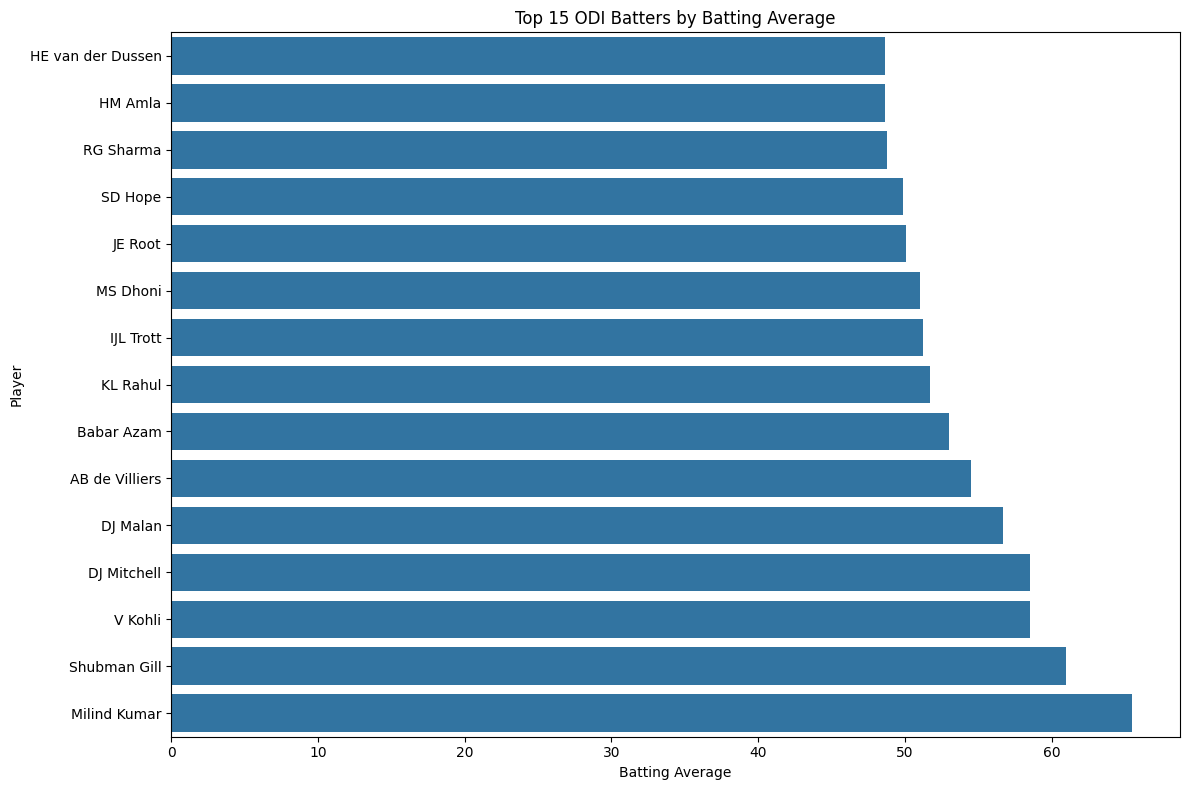

In [ ]:
qualified_batters = batting_average_eda[
    (batting_average_eda["innings_played"] >= 20) &
    (batting_average_eda["times_dismissed"] > 0) &
    (batting_average_eda["batting_average"].notna())
].copy()

top_15_average = (
    qualified_batters
    .nlargest(15, "batting_average")
    .sort_values("batting_average", ascending=False)
)

print("TOP 15 ODI BATTERS BY BATTING AVERAGE")
print("=" * 65)

print(
    top_15_average[
        [
            "batter",
            "total_runs",
            "innings_played",
            "times_dismissed",
            "not_outs",
            "batting_average",
            "strike_rate"
        ]
    ].round(2).to_string(index=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_15_average.sort_values("batting_average"),
    x="batting_average",
    y="batter"
)

plt.title("Top 15 ODI Batters by Batting Average")
plt.xlabel("Batting Average")
plt.ylabel("Player")
plt.tight_layout()
plt.show()

In [ ]:
# Calculate boundary runs
batter_stats_eda = batter_stats.copy()

batter_stats_eda["boundary_runs"] = (
    batter_stats_eda["fours"] * 4 +
    batter_stats_eda["sixes"] * 6
)

# Calculate boundary contribution percentage
batter_stats_eda["boundary_percentage"] = (
    batter_stats_eda["boundary_runs"] /
    batter_stats_eda["total_runs"] * 100
)

# Calculate sixes-to-fours ratio
batter_stats_eda["six_four_ratio"] = (
    batter_stats_eda["sixes"] /
    batter_stats_eda["fours"].replace(0, pd.NA)
)

# Select players with at least 20 innings
qualified_boundary_batters = batter_stats_eda[
    batter_stats_eda["innings_played"] >= 20
].copy()

# Top 15 by boundary contribution
top_boundary_batters = qualified_boundary_batters.nlargest(
    15, "boundary_percentage"
)

print("TOP 15 BATTERS BY BOUNDARY CONTRIBUTION")
print("=" * 75)

print(
    top_boundary_batters[
        [
            "total_runs",
            "fours",
            "sixes",
            "boundary_runs",
            "boundary_percentage",
            "six_four_ratio"
        ]
    ].round(2).to_string()
)

TOP 15 BATTERS BY BOUNDARY CONTRIBUTION
                 total_runs  fours  sixes  boundary_runs  boundary_percentage six_four_ratio
batter                                                                                      
Haris Rauf              115      8      9             86                74.78          1.125
A Johnson               656     76     31            490                74.70       0.407895
Sharjeel Khan           787    102     27            570                72.43       0.264706
AD Russell             1034     94     57            718                69.44       0.606383
Mohammad Naveed         275     23     16            188                68.36       0.695652
Tanzid Hasan           1031    119     38            704                68.28       0.319328
FH Allen                582     78     14            396                68.04       0.179487
Kushal Malla            801     65     46            536                66.92       0.707692
PD Salt                 976   

In [ ]:
# Filter batters with at least 500 balls faced
qualified_boundary_batters = batter_stats_eda[
    batter_stats_eda["balls_faced"] >= 500
].copy()

# Calculate boundary contribution
top_boundary_batters = (
    qualified_boundary_batters
    .sort_values("boundary_percentage", ascending=False)
    .head(15)
)

print("TOP 15 BATTERS — BOUNDARY CONTRIBUTION")
print("Minimum qualification: 500 balls faced")
print("=" * 75)

print(
    top_boundary_batters[
        [
            "total_runs",
            "balls_faced",
            "fours",
            "sixes",
            "boundary_runs",
            "boundary_percentage",
            "six_four_ratio"
        ]
    ].round(2).to_string()
)

TOP 15 BATTERS — BOUNDARY CONTRIBUTION
Minimum qualification: 500 balls faced
               total_runs  balls_faced  fours  sixes  boundary_runs  boundary_percentage six_four_ratio
batter                                                                                                 
A Johnson             656          705     76     31            490                74.70       0.407895
Sharjeel Khan         787          679    102     27            570                72.43       0.264706
AD Russell           1034          794     94     57            718                69.44       0.606383
Tanzid Hasan         1031          989    119     38            704                68.28       0.319328
FH Allen              582          624     78     14            396                68.04       0.179487
Kushal Malla          801          891     65     46            536                66.92       0.707692
PD Salt               976          848    133     20            652                66.80  

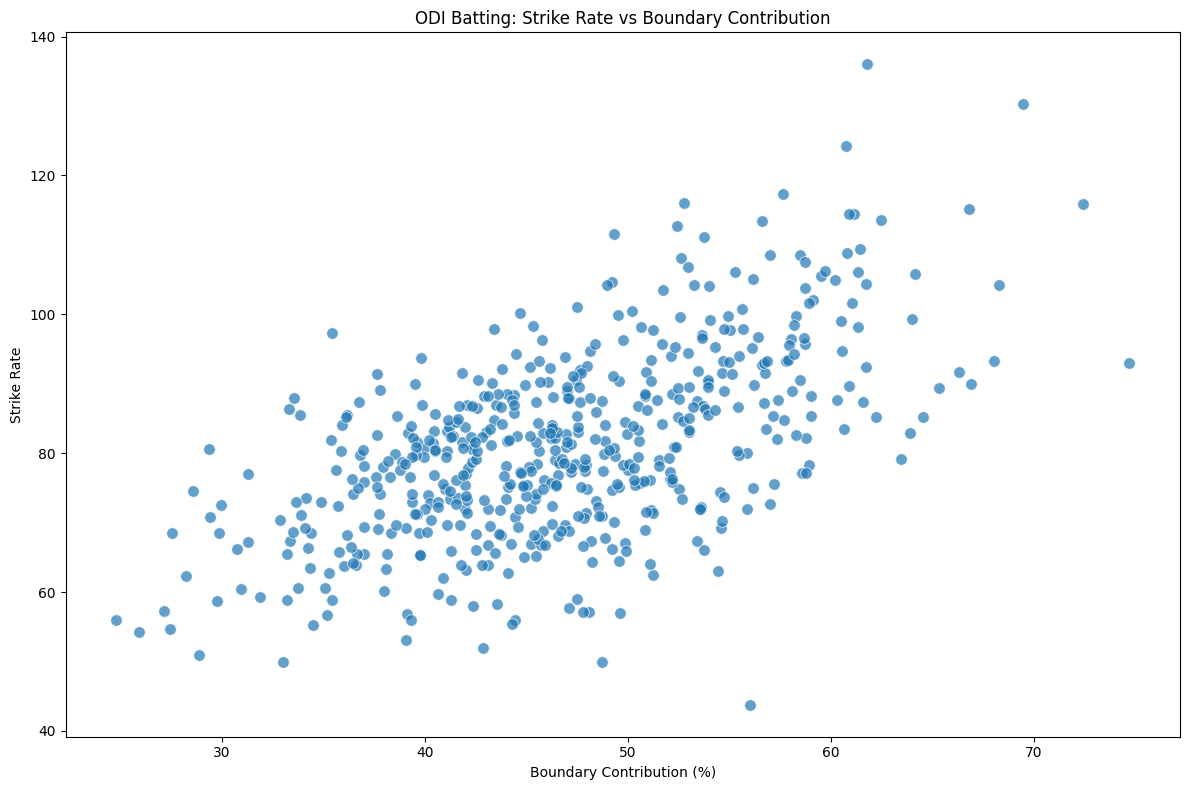

In [ ]:
# Prepare comparison dataset
boundary_comparison = batter_stats_eda[
    batter_stats_eda["balls_faced"] >= 500
].copy()

# Calculate strike rate
boundary_comparison["strike_rate"] = (
    boundary_comparison["total_runs"] /
    boundary_comparison["balls_faced"] * 100
)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=boundary_comparison,
    x="boundary_percentage",
    y="strike_rate",
    alpha=0.7,
    s=70
)

plt.title("ODI Batting: Strike Rate vs Boundary Contribution")
plt.xlabel("Boundary Contribution (%)")
plt.ylabel("Strike Rate")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

afg_batting = pd.read_csv(
    r"C:\CricIQ\data\processed\afghanistan_odi\afghanistan_odi_batting_clean.csv"
)

print("AFGHANISTAN BATTING DATA")
print("=" * 60)

print("Shape:", afg_batting.shape)

print("\nColumns:")
print(afg_batting.columns.tolist())

print("\nData types:")
print(afg_batting.dtypes)

print("\nFirst 10 records:")
display(afg_batting.head(10))

AFGHANISTAN BATTING DATA
Shape: (2719, 13)

Columns:
['Batter', 'Dismissal', 'R', 'B', '4s', '6s', 'SR', 'innings_number', 'date', 'match_url', 'runs', 'calculated_sr', 'sr_difference']

Data types:
Batter             object
Dismissal          object
R                  object
B                   int64
4s                  int64
6s                  int64
SR                float64
innings_number      int64
date               object
match_url          object
runs                int64
calculated_sr     float64
sr_difference     float64
dtype: object

First 10 records:


,Batter,Dismissal,R,B,4s,6s,SR,innings_number,date,match_url,runs,calculated_sr,sr_difference
0,Paul Stirling,bowled b Khaliq Dad,6,12,1,0,50.00,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,6,50.000000,0.000000
1,James Hall,caught Karim Sadiq b Shapoor Zadran,15,29,2,0,51.72,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,15,51.724138,0.004138
2,Alex Cusack,caught Shabir Noori b Khaliq Dad,2,17,0,0,11.76,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,2,11.764706,0.004706
3,Kevin O'Brien,caught Hamid Hassan b Samiullah Shinwari,44,68,5,0,64.70,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,44,64.705882,0.005882
4,Andrew Poynter,caught Karim Sadiq b Hamid Hassan,78,109,6,1,71.55,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,78,71.559633,0.009633
5,Andrew White,lbw b Hamid Hassan,31,35,1,1,88.57,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,31,88.571429,0.001429
6,John Mooney,caught Mohammad Nabi b Hamid Hassan,2,2,0,0,100.00,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,2,100.000000,0.000000
7,Trent Johnston,not out,42*,28,2,2,150.00,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,42,150.000000,0.000000
8,Nigel Jones,caught Nawroz Mangal b Mohammad Nabi,2,4,0,0,50.00,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,2,50.000000,0.000000
9,Rory McCann,run out Mohammad Nabi b Mohammad Nabi,0,0,0,0,0.00,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,0,NaN,NaN


In [ ]:
player_features = pd.read_csv(
    r"C:\CricIQ\data\features\player_data\cricketiq_player_match_features.csv"
)

print("EXISTING CRICKETIQ PLAYER DATASET")
print("=" * 60)

print("Shape:", player_features.shape)

print("\nColumns:")
print(player_features.columns.tolist())

print("\nFirst 10 records:")
display(player_features.head(10))

print("\nData types:")
print(player_features.dtypes)

EXISTING CRICKETIQ PLAYER DATASET
Shape: (58319, 72)

Columns:
['match_key', 'cricketiq_player_id', 'batting_innings_number', 'runs', 'balls_faced', 'fours', 'sixes', 'is_out', 'synthetic_batting_record', 'dismissal_description', 'bowling_innings_number', 'runs_conceded', 'wickets', 'legal_balls', 'wides', 'no_balls', 'maidens', 'source', 'match_date', 'canonical_player_name', 'team', 'opponent', 'is_super_over', 'has_batting_record', 'has_bowling_record', 'has_batting_involvement', 'pre_match_career_matches_played', 'pre_match_career_batting_innings', 'pre_match_career_batting_runs', 'pre_match_career_batting_balls', 'pre_match_career_batting_fours', 'pre_match_career_batting_sixes', 'pre_match_career_batting_dismissals', 'pre_match_career_bowling_innings', 'pre_match_career_bowling_runs_conceded', 'pre_match_career_bowling_wickets', 'pre_match_career_bowling_legal_balls', 'pre_match_career_batting_average', 'pre_match_career_batting_strike_rate', 'pre_match_career_boundary_runs', 'pr

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22372\3652953508.py:1: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  player_features = pd.read_csv(


,match_key,cricketiq_player_id,batting_innings_number,runs,balls_faced,fours,sixes,is_out,synthetic_batting_record,dismissal_description,...,pre_match_recent_5_bowling_average,pre_match_recent_5_bowling_economy,pre_match_recent_5_bowling_strike_rate,pre_match_recent_10_bowling_innings,pre_match_recent_10_bowling_runs_conceded,pre_match_recent_10_bowling_legal_balls,pre_match_recent_10_bowling_wickets,pre_match_recent_10_bowling_average,pre_match_recent_10_bowling_economy,pre_match_recent_10_bowling_strike_rate
0,CS_MATCH_66283,CRIQ_6b71e6cf,2.0,22.0,28.0,2.0,0.0,True,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
1,CS_MATCH_66283,CRIQ_d18f9182,2.0,29.0,37.0,3.0,0.0,True,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
2,CS_MATCH_66283,CS_22860288,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
3,CS_MATCH_66283,CS_342d8ade,2.0,5.0,13.0,0.0,0.0,False,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
4,CS_MATCH_66283,CS_434e36b1,2.0,1.0,4.0,0.0,0.0,True,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
5,CS_MATCH_66283,CS_53fcbbfb,1.0,18.0,31.0,1.0,0.0,True,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
6,CS_MATCH_66283,CS_8a686d30,2.0,47.0,58.0,7.0,0.0,True,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
7,CS_MATCH_66283,CS_8c82ae9a,2.0,15.0,22.0,0.0,0.0,False,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
8,CS_MATCH_66283,CS_a386e91b,1.0,10.0,3.0,2.0,0.0,False,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
9,CS_MATCH_66283,CS_a4af4849,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN



Data types:
match_key                                   object
cricketiq_player_id                         object
batting_innings_number                     float64
runs                                       float64
balls_faced                                float64
                                            ...   
pre_match_recent_10_bowling_legal_balls    float64
pre_match_recent_10_bowling_wickets        float64
pre_match_recent_10_bowling_average        float64
pre_match_recent_10_bowling_economy        float64
pre_match_recent_10_bowling_strike_rate    float64
Length: 72, dtype: object


In [ ]:
print("CRICKETIQ PLAYER DATA — SOURCE VALIDATION")
print("=" * 60)

print("\n1. Records by source:")
print(player_features["source"].value_counts(dropna=False))

print("\n2. Unique matches by source:")
print(
    player_features.groupby("source")["match_key"]
    .nunique()
)

print("\n3. Player records by source:")
print(
    player_features.groupby("source")["cricketiq_player_id"]
    .nunique()
)

print("\n4. Match key prefixes:")
print(
    player_features["match_key"]
    .str.split("_")
    .str[0]
    .value_counts(dropna=False)
)

print("\n5. Match date coverage by source:")
print(
    player_features.groupby("source")["match_date"]
    .agg(["min", "max", "count"])
)

CRICKETIQ PLAYER DATA — SOURCE VALIDATION

1. Records by source:
source
Cricsheet    55148
Crickrida     3171
Name: count, dtype: int64

2. Unique matches by source:
source
Crickrida     148
Cricsheet    2600
Name: match_key, dtype: int64

3. Player records by source:
source
Crickrida     454
Cricsheet    2008
Name: cricketiq_player_id, dtype: int64

4. Match key prefixes:
match_key
CS    55148
CR     3171
Name: count, dtype: int64

5. Match date coverage by source:
                  min         max  count
source                                  
Crickrida  2010-07-03  2026-10-23   3171
Cricsheet  2002-06-27  2026-10-25  55148


In [ ]:
print("INTEGRATED PLAYER BATTING VALIDATION")
print("=" * 60)

print("\n1. Batting records by source:")
print(
    player_features.groupby("source")["has_batting_record"]
    .value_counts(dropna=False)
)

print("\n2. Synthetic batting records:")
print(
    player_features.groupby("source")["synthetic_batting_record"]
    .value_counts(dropna=False)
)

print("\n3. Batting involvement by source:")
print(
    player_features.groupby("source")["has_batting_involvement"]
    .value_counts(dropna=False)
)

print("\n4. Batting runs and balls by source:")
print(
    player_features.groupby("source")[
        ["runs", "balls_faced", "fours", "sixes"]
    ].agg(["count", "sum"])
)

INTEGRATED PLAYER BATTING VALIDATION

1. Batting records by source:
source     has_batting_record
Crickrida  True                   2719
           False                   452
Cricsheet  True                  45404
           False                  9744
Name: count, dtype: int64

2. Synthetic batting records:
source     synthetic_batting_record
Crickrida  False                        3171
Cricsheet  False                       55069
           True                           79
Name: count, dtype: int64

3. Batting involvement by source:
source     has_batting_involvement
Crickrida  True                        2719
           False                        452
Cricsheet  True                       45483
           False                       9665
Name: count, dtype: int64

4. Batting runs and balls by source:
            runs            balls_faced             fours            sixes  \
           count        sum       count        sum  count       sum  count   
source                    

In [ ]:
synthetic_records = player_features[
    player_features["synthetic_batting_record"] == True
]

print("SYNTHETIC BATTING RECORD INVESTIGATION")
print("=" * 60)

print("Total synthetic records:", len(synthetic_records))

print("\nSource distribution:")
print(synthetic_records["source"].value_counts())

print("\nRelevant columns:")
display(
    synthetic_records[
        [
            "match_key",
            "cricketiq_player_id",
            "canonical_player_name",
            "team",
            "opponent",
            "batting_innings_number",
            "runs",
            "balls_faced",
            "fours",
            "sixes",
            "is_out",
            "has_batting_record",
            "has_batting_involvement",
            "dismissal_description"
        ]
    ].head(20)
)

SYNTHETIC BATTING RECORD INVESTIGATION
Total synthetic records: 79

Source distribution:
source
Cricsheet    79
Name: count, dtype: int64

Relevant columns:


,match_key,cricketiq_player_id,canonical_player_name,team,opponent,batting_innings_number,runs,balls_faced,fours,sixes,is_out,has_batting_record,has_batting_involvement,dismissal_description
865,CS_MATCH_65262,CS_91a4a398,Z Khan,India,England,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN
3317,CS_MATCH_66311,CS_4d3097d8,GJ Hopkins,New Zealand,West Indies,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN
3920,CS_MATCH_66379,CRIQ_0fdabe05,Vusi Sibanda,Zimbabwe,Pakistan,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN
4247,CS_MATCH_64919,CS_0480aba6,Enamul Haque jnr,Bangladesh,Zimbabwe,2.0,0.0,0.0,0.0,0.0,True,False,True,NaN
5872,CS_MATCH_236358,CS_7d415ea5,RT Ponting,Australia,Sri Lanka,2.0,0.0,0.0,0.0,0.0,True,False,True,NaN
5996,CS_MATCH_237568,CRIQ_d7c6af50,Daniel Vettori,New Zealand,West Indies,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN
6277,CS_MATCH_238199,CS_6b0c3a20,AJ Hall,South Africa,Australia,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN
6493,CS_MATCH_244510,CS_6b8eb6e5,S Sreesanth,India,Pakistan,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN
6652,CS_MATCH_239912,CRIQ_f846de6a,Marlon Samuels,West Indies,Zimbabwe,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN
6833,CS_MATCH_225251,CS_ab89348d,MF Maharoof,Sri Lanka,England,1.0,0.0,0.0,0.0,0.0,True,False,True,NaN


In [ ]:
print("SYNTHETIC RECORD VALIDATION")
print("=" * 60)

print("\n1. Dismissal status:")
print(synthetic_records["is_out"].value_counts(dropna=False))

print("\n2. Batting innings:")
print(
    synthetic_records["batting_innings_number"]
    .value_counts(dropna=False)
)

print("\n3. Runs, balls and boundaries:")
print(
    synthetic_records[
        ["runs", "balls_faced", "fours", "sixes"]
    ].describe()
)

print("\n4. Synthetic records by season:")
synthetic_records["match_date"] = pd.to_datetime(
    synthetic_records["match_date"]
)

print(
    synthetic_records["match_date"]
    .dt.year.value_counts()
    .sort_index()
)

print("\n5. Sample synthetic dismissal records:")
display(
    synthetic_records[
        [
            "match_key",
            "match_date",
            "canonical_player_name",
            "team",
            "batting_innings_number",
            "is_out",
            "dismissal_description"
        ]
    ].head(30)
)

SYNTHETIC RECORD VALIDATION

1. Dismissal status:
is_out
True    79
Name: count, dtype: int64

2. Batting innings:
batting_innings_number
1.0    45
2.0    34
Name: count, dtype: int64

3. Runs, balls and boundaries:
       runs  balls_faced  fours  sixes
count  79.0         79.0   79.0   79.0
mean    0.0          0.0    0.0    0.0
std     0.0          0.0    0.0    0.0
min     0.0          0.0    0.0    0.0
25%     0.0          0.0    0.0    0.0
50%     0.0          0.0    0.0    0.0
75%     0.0          0.0    0.0    0.0
max     0.0          0.0    0.0    0.0

4. Synthetic records by season:
match_date
2003    1
2004    2
2005    1
2006    8
2007    2
2008    3
2009    4
2010    1
2011    5
2012    1
2013    8
2014    1
2015    8
2016    1
2017    3
2018    3
2019    5
2020    1
2021    3
2022    6
2023    4
2024    3
2025    2
2026    3
Name: count, dtype: int64

5. Sample synthetic dismissal records:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_22372\1989640239.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  synthetic_records["match_date"] = pd.to_datetime(


,match_key,match_date,canonical_player_name,team,batting_innings_number,is_out,dismissal_description
865,CS_MATCH_65262,2003-02-26,Z Khan,India,1.0,True,NaN
3317,CS_MATCH_66311,2004-07-10,GJ Hopkins,New Zealand,1.0,True,NaN
3920,CS_MATCH_66379,2004-10-03,Vusi Sibanda,Zimbabwe,1.0,True,NaN
4247,CS_MATCH_64919,2005-01-24,Enamul Haque jnr,Bangladesh,2.0,True,NaN
5872,CS_MATCH_236358,2006-02-10,RT Ponting,Australia,2.0,True,NaN
5996,CS_MATCH_237568,2006-02-18,Daniel Vettori,New Zealand,1.0,True,NaN
6277,CS_MATCH_238199,2006-03-10,AJ Hall,South Africa,1.0,True,NaN
6493,CS_MATCH_244510,2006-04-18,S Sreesanth,India,1.0,True,NaN
6652,CS_MATCH_239912,2006-05-13,Marlon Samuels,West Indies,1.0,True,NaN
6833,CS_MATCH_225251,2006-06-20,MF Maharoof,Sri Lanka,1.0,True,NaN


In [ ]:
# Keep actual batting records and valid synthetic dismissals
integrated_batting = player_features[
    (player_features["has_batting_involvement"] == True) &
    (
        (player_features["has_batting_record"] == True) |
        (
            (player_features["synthetic_batting_record"] == True) &
            (player_features["is_out"] == True)
        )
    )
].copy()

# Convert numerical columns safely
numeric_cols = [
    "runs", "balls_faced", "fours", "sixes"
]

integrated_batting[numeric_cols] = (
    integrated_batting[numeric_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

# Aggregate by player
integrated_batter_stats = (
    integrated_batting
    .groupby(
        ["cricketiq_player_id", "canonical_player_name"],
        dropna=False
    )
    .agg(
        total_runs=("runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum"),
        innings_played=("match_key", "size"),
        times_dismissed=("is_out", lambda x: x.eq(True).sum()),
        source_count=("source", "nunique")
    )
    .reset_index()
)

# Calculate batting average and strike rate
integrated_batter_stats["batting_average"] = (
    integrated_batter_stats["total_runs"] /
    integrated_batter_stats["times_dismissed"].replace(0, pd.NA)
)

integrated_batter_stats["strike_rate"] = (
    integrated_batter_stats["total_runs"] /
    integrated_batter_stats["balls_faced"].replace(0, pd.NA) * 100
)

# Calculate not-outs
integrated_batter_stats["not_outs"] = (
    integrated_batter_stats["innings_played"] -
    integrated_batter_stats["times_dismissed"]
)

print("INTEGRATED BATTING STATISTICS")
print("=" * 60)

print("Total player records:", len(integrated_batter_stats))
print("Total runs:", integrated_batter_stats["total_runs"].sum())
print("Total balls:", integrated_batter_stats["balls_faced"].sum())
print("Total fours:", integrated_batter_stats["fours"].sum())
print("Total sixes:", integrated_batter_stats["sixes"].sum())

print("\nRecords by source coverage:")
print(integrated_batter_stats["source_count"].value_counts())

print("\nNegative not-outs:",
      (integrated_batter_stats["not_outs"] < 0).sum())

display(integrated_batter_stats.head(10))

INTEGRATED BATTING STATISTICS
Total player records: 2002
Total runs: 1158851.0
Total balls: 1424503.0
Total fours: 105950.0
Total sixes: 20813.0

Records by source coverage:
source_count
1    1664
2     338
Name: count, dtype: int64

Negative not-outs: 0


,cricketiq_player_id,canonical_player_name,total_runs,balls_faced,fours,sixes,innings_played,times_dismissed,source_count,batting_average,strike_rate,not_outs
0,CRIQ_024a173d,John Nyumbu,46.0,89.0,1.0,1.0,14,10,2,4.6,51.685393,4
1,CRIQ_02789d88,Shamsur Rahman,266.0,350.0,23.0,9.0,10,10,2,26.6,76.0,0
2,CRIQ_02e83ac5,Naeem Islam,877.0,1262.0,75.0,12.0,46,32,2,27.40625,69.492868,14
3,CRIQ_03806cf8,Josh Hazlewood,137.0,176.0,14.0,3.0,35,10,1,13.7,77.840909,25
4,CRIQ_0404d43c,Litton Das,2869.0,3355.0,294.0,51.0,103,93,2,30.849462,85.514158,10
5,CRIQ_05d74535,Saeed Ajmal,324.0,535.0,25.0,0.0,67,46,2,7.043478,60.560748,21
6,CRIQ_05de1a5a,Gary Wilson,1548.0,2157.0,124.0,16.0,76,67,2,23.104478,71.766342,9
7,CRIQ_06e649a0,Roger Whelan,5.0,12.0,1.0,0.0,2,2,1,2.5,41.666667,0
8,CRIQ_086f5984,Junaid Khan,68.0,127.0,4.0,1.0,24,14,1,4.857143,53.543307,10
9,CRIQ_0994d0ae,Vijay Shankar,223.0,246.0,20.0,4.0,8,7,2,31.857143,90.650407,1


In [ ]:
print("INTEGRATED BATTING DATA — FINAL VALIDATION")
print("=" * 65)

print("\n1. Super Over distribution:")
print(
    integrated_batting["is_super_over"]
    .value_counts(dropna=False)
)

print("\n2. Duplicate player-match-innings records:")

duplicate_records = integrated_batting.duplicated(
    subset=[
        "cricketiq_player_id",
        "match_key",
        "batting_innings_number"
    ],
    keep=False
)

print("Duplicate rows:", duplicate_records.sum())

print("\n3. Sample duplicate records:")

display(
    integrated_batting.loc[
        duplicate_records,
        [
            "cricketiq_player_id",
            "canonical_player_name",
            "match_key",
            "batting_innings_number",
            "source",
            "runs",
            "balls_faced"
        ]
    ].head(15)
)

print("\n4. Regular innings distribution:")
print(
    integrated_batting[
        integrated_batting["is_super_over"] == False
    ]["batting_innings_number"].value_counts(dropna=False)
)

INTEGRATED BATTING DATA — FINAL VALIDATION

1. Super Over distribution:
is_super_over
False    48202
Name: count, dtype: int64

2. Duplicate player-match-innings records:
Duplicate rows: 0

3. Sample duplicate records:


,cricketiq_player_id,canonical_player_name,match_key,batting_innings_number,source,runs,balls_faced



4. Regular innings distribution:
batting_innings_number
1.0    25915
2.0    22287
Name: count, dtype: int64


In [ ]:
# Keep regular ODI batting records only
regular_batting = integrated_batting[
    integrated_batting["is_super_over"] == False
].copy()

# Aggregate player statistics
integrated_batter_stats = (
    regular_batting
    .groupby(
        ["cricketiq_player_id", "canonical_player_name"],
        dropna=False
    )
    .agg(
        total_runs=("runs", "sum"),
        balls_faced=("balls_faced", "sum"),
        fours=("fours", "sum"),
        sixes=("sixes", "sum"),
        innings_played=("match_key", "nunique"),
        times_dismissed=("is_out", lambda x: x.eq(True).sum()),
        source_count=("source", "nunique")
    )
    .reset_index()
)

# Calculate batting average
integrated_batter_stats["batting_average"] = (
    integrated_batter_stats["total_runs"] /
    integrated_batter_stats["times_dismissed"].replace(0, pd.NA)
)

# Calculate strike rate
integrated_batter_stats["strike_rate"] = (
    integrated_batter_stats["total_runs"] /
    integrated_batter_stats["balls_faced"].replace(0, pd.NA) * 100
)

# Calculate not-outs
integrated_batter_stats["not_outs"] = (
    integrated_batter_stats["innings_played"] -
    integrated_batter_stats["times_dismissed"]
)

# Calculate boundary contribution
integrated_batter_stats["boundary_runs"] = (
    integrated_batter_stats["fours"] * 4 +
    integrated_batter_stats["sixes"] * 6
)

integrated_batter_stats["boundary_percentage"] = (
    integrated_batter_stats["boundary_runs"] /
    integrated_batter_stats["total_runs"].replace(0, pd.NA) * 100
)

print("FINAL INTEGRATED ODI BATTING STATISTICS")
print("=" * 65)

print("Unique players:", len(integrated_batter_stats))
print("Total runs:", integrated_batter_stats["total_runs"].sum())
print("Total balls:", integrated_batter_stats["balls_faced"].sum())
print("Total dismissals:", integrated_batter_stats["times_dismissed"].sum())
print("Negative not-outs:", (integrated_batter_stats["not_outs"] < 0).sum())

display(integrated_batter_stats.head(10))

FINAL INTEGRATED ODI BATTING STATISTICS
Unique players: 2002
Total runs: 1158851.0
Total balls: 1424503.0
Total dismissals: 39982
Negative not-outs: 0


,cricketiq_player_id,canonical_player_name,total_runs,balls_faced,fours,sixes,innings_played,times_dismissed,source_count,batting_average,strike_rate,not_outs,boundary_runs,boundary_percentage
0,CRIQ_024a173d,John Nyumbu,46.0,89.0,1.0,1.0,14,10,2,4.6,51.685393,4,10.0,21.73913
1,CRIQ_02789d88,Shamsur Rahman,266.0,350.0,23.0,9.0,10,10,2,26.6,76.0,0,146.0,54.887218
2,CRIQ_02e83ac5,Naeem Islam,877.0,1262.0,75.0,12.0,46,32,2,27.40625,69.492868,14,372.0,42.417332
3,CRIQ_03806cf8,Josh Hazlewood,137.0,176.0,14.0,3.0,35,10,1,13.7,77.840909,25,74.0,54.014599
4,CRIQ_0404d43c,Litton Das,2869.0,3355.0,294.0,51.0,103,93,2,30.849462,85.514158,10,1482.0,51.655629
5,CRIQ_05d74535,Saeed Ajmal,324.0,535.0,25.0,0.0,67,46,2,7.043478,60.560748,21,100.0,30.864198
6,CRIQ_05de1a5a,Gary Wilson,1548.0,2157.0,124.0,16.0,76,67,2,23.104478,71.766342,9,592.0,38.242894
7,CRIQ_06e649a0,Roger Whelan,5.0,12.0,1.0,0.0,2,2,1,2.5,41.666667,0,4.0,80.0
8,CRIQ_086f5984,Junaid Khan,68.0,127.0,4.0,1.0,24,14,1,4.857143,53.543307,10,22.0,32.352941
9,CRIQ_0994d0ae,Vijay Shankar,223.0,246.0,20.0,4.0,8,7,2,31.857143,90.650407,1,104.0,46.636771


In [ ]:
print("DISMISSAL STATUS VALIDATION")
print("=" * 60)

print("\n1. Dismissal status by source:")
print(
    regular_batting.groupby("source")["is_out"]
    .value_counts(dropna=False)
)

print("\n2. Missing dismissal descriptions:")
print(
    regular_batting.groupby("source")["dismissal_description"]
    .apply(lambda x: x.isna().sum())
)

print("\n3. Sample dismissal descriptions:")
display(
    regular_batting[
        regular_batting["dismissal_description"].notna()
    ][
        [
            "source",
            "canonical_player_name",
            "is_out",
            "dismissal_description"
        ]
    ].head(20)
)

print("\n4. Retired-hurt records:")
print(
    regular_batting[
        regular_batting["dismissal_description"]
        .astype(str)
        .str.contains("retired hurt", case=False, na=False)
    ][
        ["source", "canonical_player_name", "is_out",
         "dismissal_description"]
    ].head(20)
)

DISMISSAL STATUS VALIDATION

1. Dismissal status by source:
source     is_out
Crickrida  True       2280
           False       439
Cricsheet  True      37702
           False      7781
Name: count, dtype: int64

2. Missing dismissal descriptions:
source
Crickrida        0
Cricsheet    45483
Name: dismissal_description, dtype: int64

3. Sample dismissal descriptions:


,source,canonical_player_name,is_out,dismissal_description
17014,Crickrida,Kevin O'Brien,True,caught Hamid Hassan b Samiullah Shinwari
17015,Crickrida,Mohammad Shahzad,True,caught Andrew Poynter b Alex Cusack
17016,Crickrida,Alex Cusack,True,caught Shabir Noori b Khaliq Dad
17017,Crickrida,Rory McCann,True,run out Mohammad Nabi b Mohammad Nabi
17019,Crickrida,John Mooney,True,caught Mohammad Nabi b Hamid Hassan
17020,Crickrida,Andrew Poynter,True,caught Karim Sadiq b Hamid Hassan
17021,Crickrida,Nigel Jones,True,caught Nawroz Mangal b Mohammad Nabi
17022,Crickrida,Paul Stirling,True,bowled b Khaliq Dad
17023,Crickrida,Trent Johnston,False,not out
17024,Crickrida,Andrew White,True,lbw b Hamid Hassan



4. Retired-hurt records:
Empty DataFrame
Columns: [source, canonical_player_name, is_out, dismissal_description]
Index: []


In [ ]:
top_batting_averages = (
    integrated_batter_stats[
        (integrated_batter_stats["innings_played"] >= 20) &
        (integrated_batter_stats["times_dismissed"] > 0)
    ]
    .sort_values("batting_average", ascending=False)
    .head(15)
    [
        [
            "canonical_player_name",
            "total_runs",
            "innings_played",
            "times_dismissed",
            "not_outs",
            "batting_average",
            "strike_rate",
            "source_count"
        ]
    ]
    .reset_index(drop=True)
)

print("TOP 15 INTEGRATED ODI BATTING AVERAGES")
print("=" * 70)

display(top_batting_averages.round(2))

TOP 15 INTEGRATED ODI BATTING AVERAGES


,canonical_player_name,total_runs,innings_played,times_dismissed,not_outs,batting_average,strike_rate,source_count
0,Milind Kumar,1375.0,30,21,9,65.47619,100.511696,1
1,Shubman Gill,3713.0,69,58,11,64.017241,103.311074,2
2,Virat Kohli,15109.0,305,257,48,58.789883,94.366373,2
3,Daryl Mitchell,2811.0,57,49,8,57.367347,94.487395,2
4,Dawid Malan,1450.0,30,26,4,55.769231,97.446237,2
5,AB de Villiers,9324.0,209,171,38,54.526316,101.073171,1
6,Babar Azam,6715.0,143,127,16,52.874016,86.388782,2
7,Ibrahim Zadran,2284.0,48,44,4,51.909091,82.187837,1
8,Shai Hope,6590.0,152,128,24,51.484375,80.829143,2
9,KL Rahul,3541.0,91,69,22,51.318841,92.381946,2


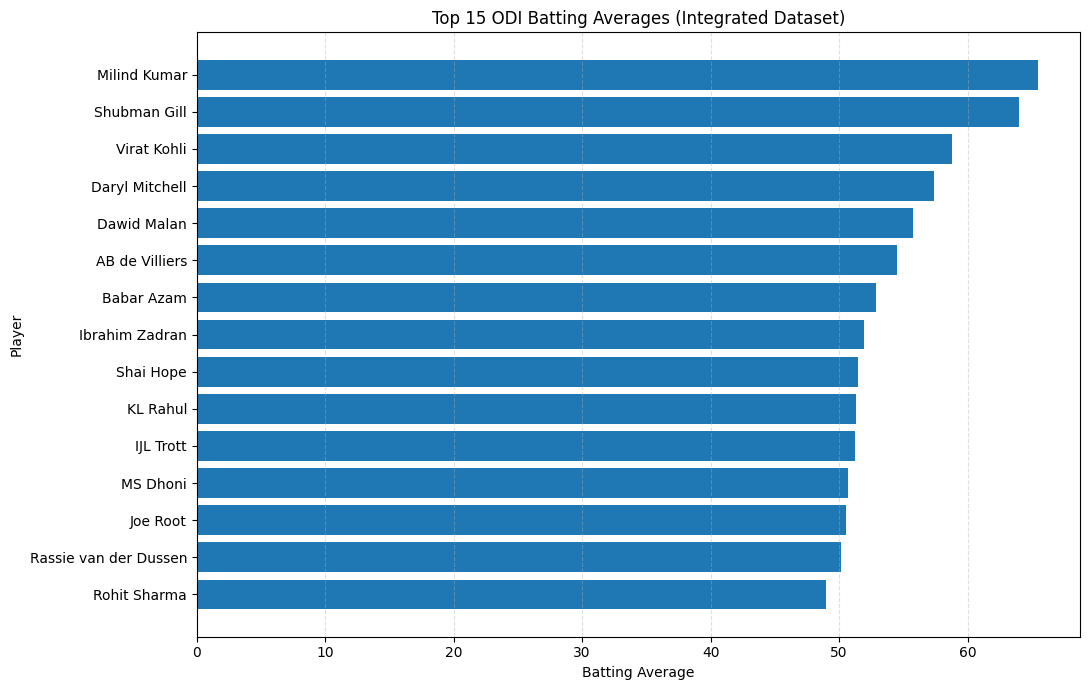

In [ ]:
import matplotlib.pyplot as plt

plot_data = top_batting_averages.sort_values(
    "batting_average",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["canonical_player_name"],
    plot_data["batting_average"]
)

plt.xlabel("Batting Average")
plt.ylabel("Player")
plt.title("Top 15 ODI Batting Averages (Integrated Dataset)")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
boundary_analysis = integrated_batter_stats[
    (integrated_batter_stats["balls_faced"] >= 500) &
    (integrated_batter_stats["total_runs"] > 0)
].copy()

boundary_analysis = boundary_analysis.sort_values(
    "boundary_percentage",
    ascending=False
)

top_boundary_players = boundary_analysis.head(15)

print("TOP 15 PLAYERS BY BOUNDARY CONTRIBUTION")
print("=" * 70)

display(
    top_boundary_players[
        [
            "canonical_player_name",
            "total_runs",
            "balls_faced",
            "fours",
            "sixes",
            "boundary_runs",
            "boundary_percentage",
            "strike_rate"
        ]
    ].round(2).reset_index(drop=True)
)

TOP 15 PLAYERS BY BOUNDARY CONTRIBUTION


,canonical_player_name,total_runs,balls_faced,fours,sixes,boundary_runs,boundary_percentage,strike_rate
0,A Johnson,656.0,705.0,76.0,31.0,490.0,74.695122,93.049645
1,Sharjeel Khan,812.0,716.0,104.0,28.0,584.0,71.921182,113.407821
2,AD Russell,1034.0,794.0,94.0,57.0,718.0,69.439072,130.2267
3,Tanzid Hasan,1091.0,1074.0,128.0,39.0,746.0,68.377635,101.582868
4,FH Allen,582.0,624.0,78.0,14.0,396.0,68.041237,93.269231
5,Kushal Malla,801.0,891.0,65.0,46.0,536.0,66.916355,89.89899
6,Phil Salt,988.0,861.0,135.0,20.0,660.0,66.801619,114.75029
7,Imran Nazir,531.0,579.0,70.0,12.0,352.0,66.290019,91.709845
8,Chris Gayle,6397.0,7185.0,664.0,253.0,4174.0,65.249336,89.032707
9,KR Mayers,660.0,775.0,75.0,21.0,426.0,64.545455,85.16129


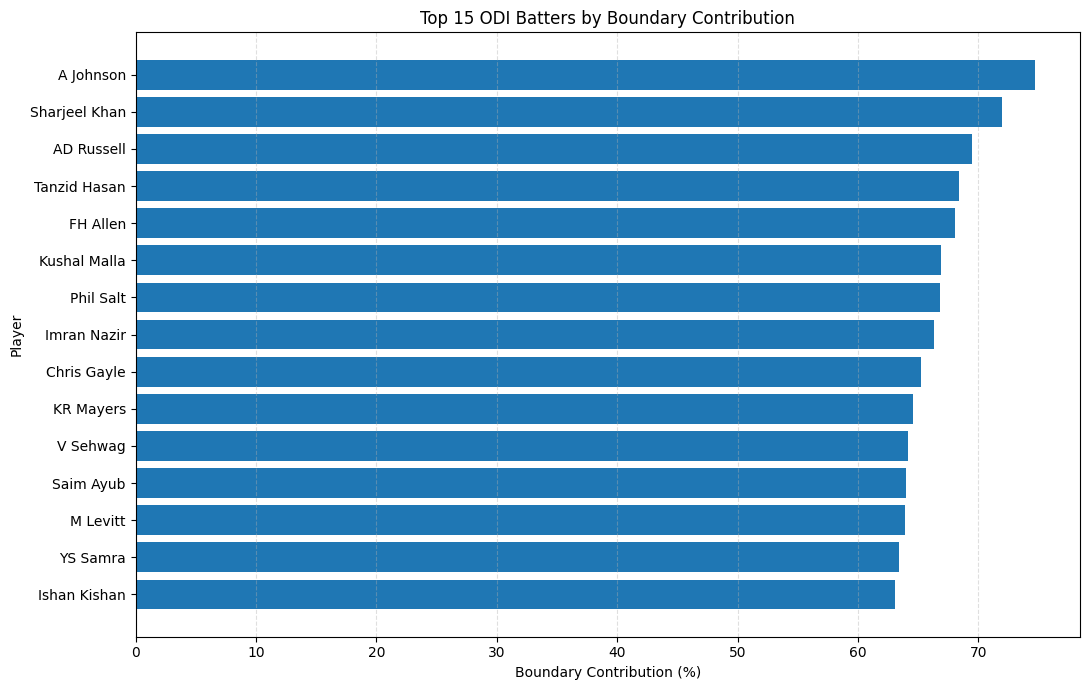

In [ ]:
import matplotlib.pyplot as plt

plot_boundary = top_boundary_players.sort_values(
    "boundary_percentage",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_boundary["canonical_player_name"],
    plot_boundary["boundary_percentage"]
)

plt.xlabel("Boundary Contribution (%)")
plt.ylabel("Player")
plt.title("Top 15 ODI Batters by Boundary Contribution")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

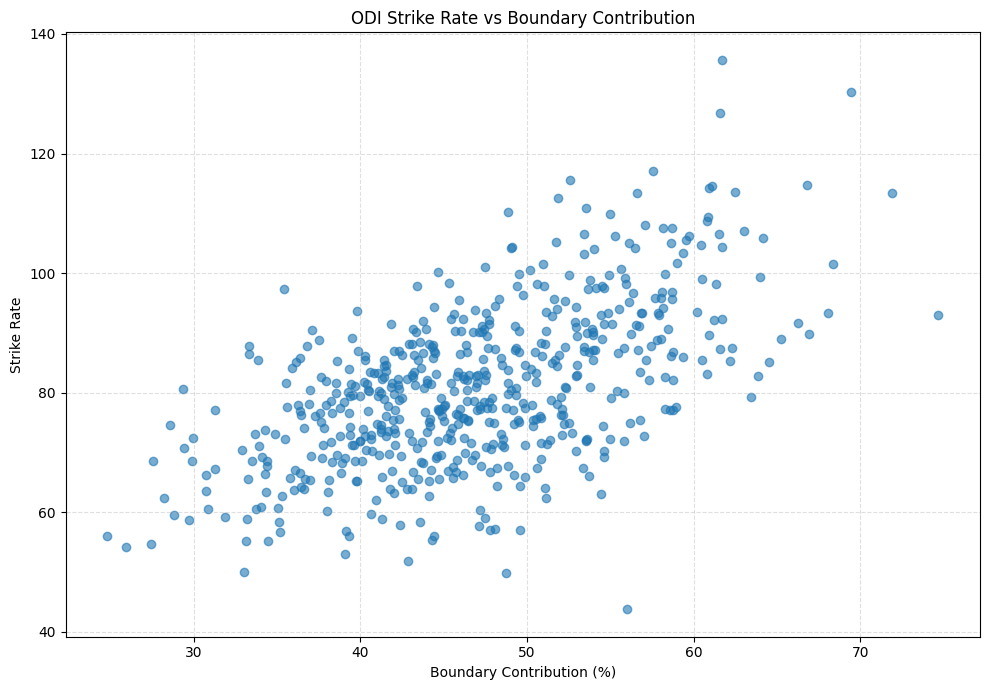

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    boundary_analysis["boundary_percentage"],
    boundary_analysis["strike_rate"],
    alpha=0.6
)

plt.xlabel("Boundary Contribution (%)")
plt.ylabel("Strike Rate")
plt.title("ODI Strike Rate vs Boundary Contribution")
plt.grid(linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import pearsonr, spearmanr
import pandas as pd
import numpy as np

# Create a clean copy for correlation analysis
correlation_data = boundary_analysis[
    ["boundary_percentage", "strike_rate"]
].copy()

# Convert both columns to numeric
for col in ["boundary_percentage", "strike_rate"]:
    correlation_data[col] = pd.to_numeric(
        correlation_data[col],
        errors="coerce"
    )

# Remove missing and infinite values
correlation_data = correlation_data.replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Calculate correlations
pearson_corr, pearson_p = pearsonr(
    correlation_data["boundary_percentage"].to_numpy(dtype=float),
    correlation_data["strike_rate"].to_numpy(dtype=float)
)

spearman_corr, spearman_p = spearmanr(
    correlation_data["boundary_percentage"].to_numpy(dtype=float),
    correlation_data["strike_rate"].to_numpy(dtype=float)
)

print("CORRELATION ANALYSIS")
print("=" * 50)

print("Valid player records:", len(correlation_data))

print(f"\nPearson correlation:  {pearson_corr:.4f}")
print(f"Pearson p-value:      {pearson_p:.6f}")

print(f"\nSpearman correlation: {spearman_corr:.4f}")
print(f"Spearman p-value:     {spearman_p:.6f}")

CORRELATION ANALYSIS
Valid player records: 569

Pearson correlation:  0.5881
Pearson p-value:      0.000000

Spearman correlation: 0.5570
Spearman p-value:     0.000000


In [ ]:
import pandas as pd
from pathlib import Path

features_path = Path(
    r"C:\CricIQ\data\features\cricketiq_engineered_features.csv"
)

features_df = pd.read_csv(features_path)

print("Dataset loaded successfully!")
print("Shape:", features_df.shape)

print("\nAvailable Elo columns:")
print([
    col for col in features_df.columns
    if "elo" in col.lower()
])

Dataset loaded successfully!
Shape: (2753, 40)

Available Elo columns:
['team_1_elo', 'team_2_elo', 'elo_difference']


In [ ]:
elo_columns = [
    "team_1_elo",
    "team_2_elo",
    "elo_difference"
]

print("ELO RATING DISTRIBUTION")
print("=" * 60)

print("\n1. Descriptive statistics:")
display(features_df[elo_columns].describe().round(2))

print("\n2. Missing values:")
display(features_df[elo_columns].isnull().sum())

print("\n3. Rating ranges:")

for col in elo_columns:
    print(
        f"{col}: "
        f"Minimum = {features_df[col].min():.2f}, "
        f"Maximum = {features_df[col].max():.2f}"
    )

ELO RATING DISTRIBUTION

1. Descriptive statistics:


,team_1_elo,team_2_elo,elo_difference
count,2753.00,2753.00,2753.00
mean,1563.62,1564.08,-0.47
std,141.14,142.05,163.31
min,1180.46,1182.17,-519.74
25%,1455.57,1463.79,-98.44
50%,1566.54,1573.10,1.27
75%,1684.38,1677.14,97.94
max,1870.52,1865.18,512.52



2. Missing values:


team_1_elo        0
team_2_elo        0
elo_difference    0
dtype: int64


3. Rating ranges:
team_1_elo: Minimum = 1180.46, Maximum = 1870.52
team_2_elo: Minimum = 1182.17, Maximum = 1865.18
elo_difference: Minimum = -519.74, Maximum = 512.52


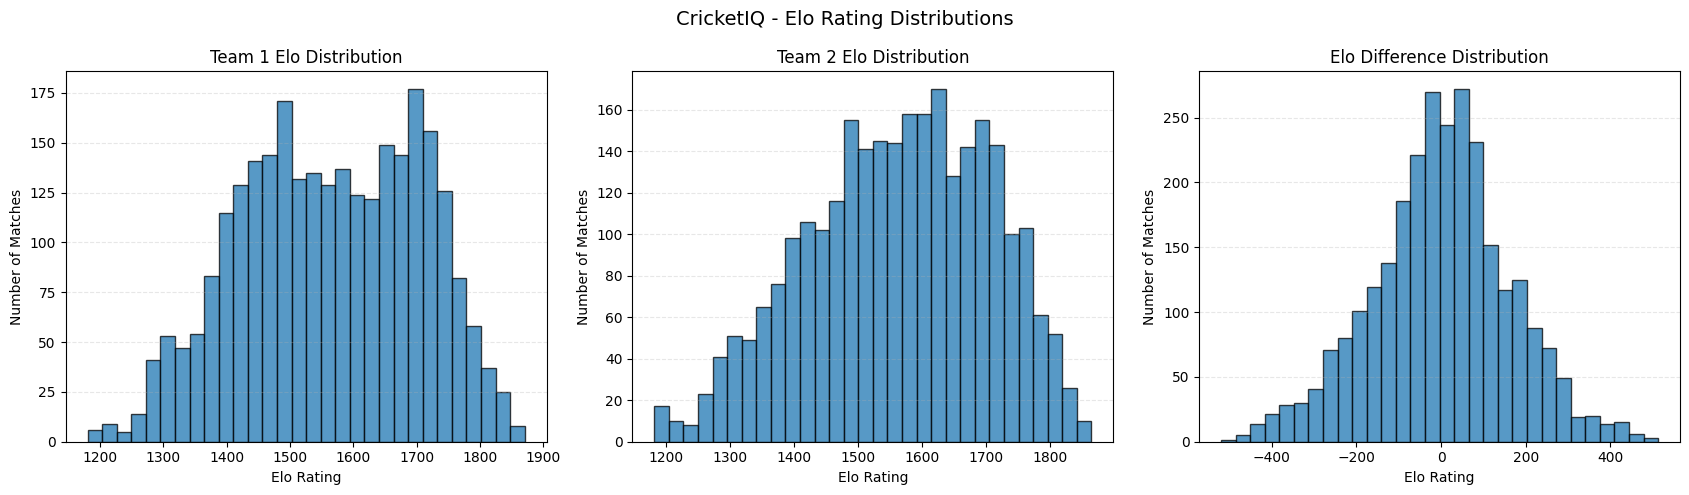

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

elo_plot_columns = [
    ("team_1_elo", "Team 1 Elo Distribution"),
    ("team_2_elo", "Team 2 Elo Distribution"),
    ("elo_difference", "Elo Difference Distribution")
]

for ax, (column, title) in zip(axes, elo_plot_columns):
    ax.hist(
        features_df[column],
        bins=30,
        edgecolor="black",
        alpha=0.75
    )

    ax.set_title(title)
    ax.set_xlabel("Elo Rating")
    ax.set_ylabel("Number of Matches")
    ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.suptitle("CricketIQ - Elo Rating Distributions", fontsize=14)
plt.tight_layout()
plt.show()

TEAM-WISE ELO RATINGS


,matches_played,average_elo,maximum_elo,minimum_elo
team,,,,
Australia,485,1726.39,1854.14,1483.26
India,536,1696.30,1870.52,1470.90
South Africa,401,1676.06,1819.31,1472.43
New Zealand,401,1653.13,1831.65,1461.32
England,456,1639.34,1865.18,1443.33
Pakistan,430,1601.74,1766.29,1485.74
Sri Lanka,508,1592.74,1729.22,1414.07
West Indies,405,1505.33,1626.27,1355.73
Jersey,4,1484.85,1500.00,1470.45


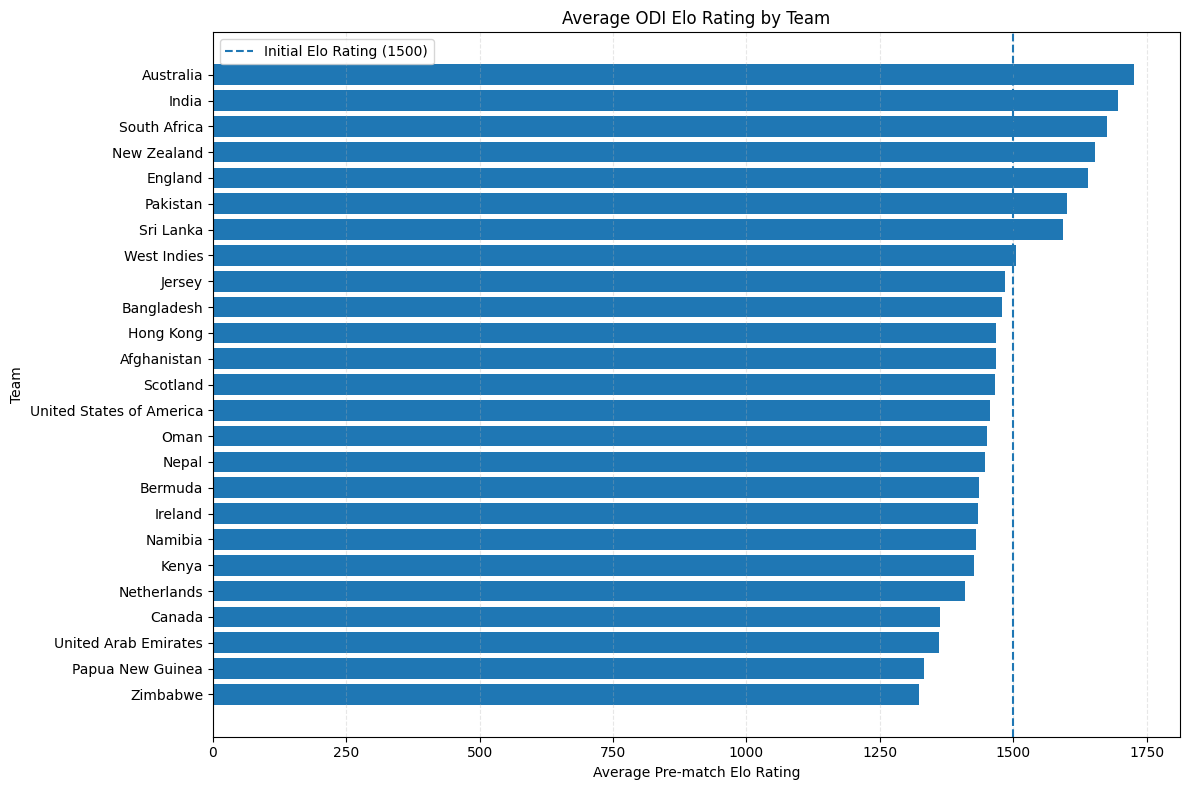

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Combine both team positions
team_1_ratings = features_df[
    ["team_1", "team_1_elo"]
].rename(columns={
    "team_1": "team",
    "team_1_elo": "elo_rating"
})

team_2_ratings = features_df[
    ["team_2", "team_2_elo"]
].rename(columns={
    "team_2": "team",
    "team_2_elo": "elo_rating"
})

# Combine ratings
team_elo_data = pd.concat(
    [team_1_ratings, team_2_ratings],
    ignore_index=True
)

# Calculate team-wise statistics
team_elo_stats = (
    team_elo_data.groupby("team")
    .agg(
        matches_played=("elo_rating", "count"),
        average_elo=("elo_rating", "mean"),
        maximum_elo=("elo_rating", "max"),
        minimum_elo=("elo_rating", "min")
    )
    .sort_values("average_elo", ascending=False)
)

print("TEAM-WISE ELO RATINGS")
print("=" * 60)

display(team_elo_stats.round(2))

# Plot average Elo
plt.figure(figsize=(12, 8))

plot_data = team_elo_stats.sort_values("average_elo")

plt.barh(
    plot_data.index,
    plot_data["average_elo"]
)

plt.axvline(
    1500,
    linestyle="--",
    label="Initial Elo Rating (1500)"
)

plt.xlabel("Average Pre-match Elo Rating")
plt.ylabel("Team")
plt.title("Average ODI Elo Rating by Team")

plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

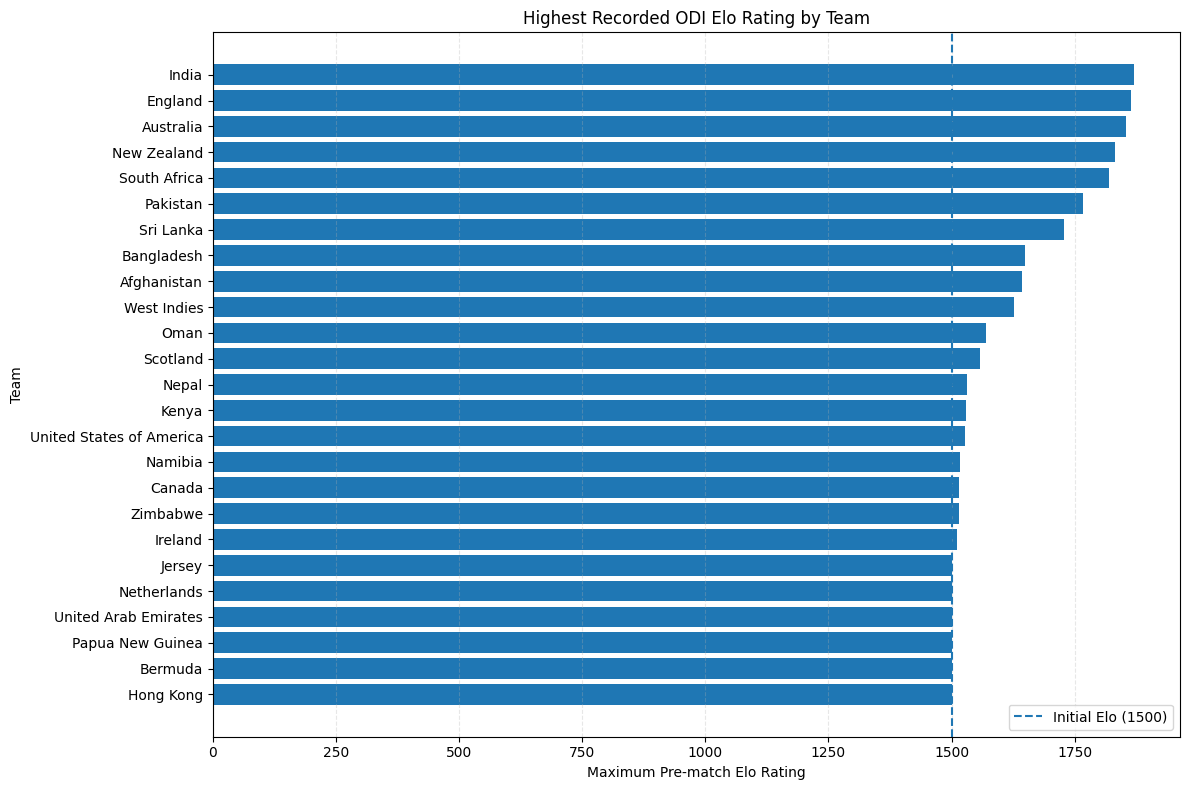

In [ ]:
import matplotlib.pyplot as plt

top_peak_elo = team_elo_stats.sort_values(
    "maximum_elo",
    ascending=False
)

plt.figure(figsize=(12, 8))

plot_data = top_peak_elo.sort_values("maximum_elo")

plt.barh(
    plot_data.index,
    plot_data["maximum_elo"]
)

plt.axvline(
    1500,
    linestyle="--",
    label="Initial Elo (1500)"
)

plt.xlabel("Maximum Pre-match Elo Rating")
plt.ylabel("Team")
plt.title("Highest Recorded ODI Elo Rating by Team")

plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("DATE AND TEAM COLUMNS")
print("=" * 50)

print("\nDate-related columns:")
print([
    col for col in features_df.columns
    if "date" in col.lower()
])

print("\nTeam-related columns:")
print([
    col for col in features_df.columns
    if "team" in col.lower()
])

DATE AND TEAM COLUMNS

Date-related columns:
['match_date']

Team-related columns:
['team_1', 'team_2', 'team_1_win', 'team_1_win_pct', 'team_2_win_pct', 'team_1_recent_form', 'team_2_recent_form', 'team_1_h2h_win_pct', 'team_2_h2h_win_pct', 'team_1_venue_win_pct', 'team_2_venue_win_pct', 'team_1_is_home', 'team_2_is_home', 'team_1_home_win_pct', 'team_2_home_win_pct', 'team_1_away_win_pct', 'team_2_away_win_pct', 'team_1_elo', 'team_2_elo']


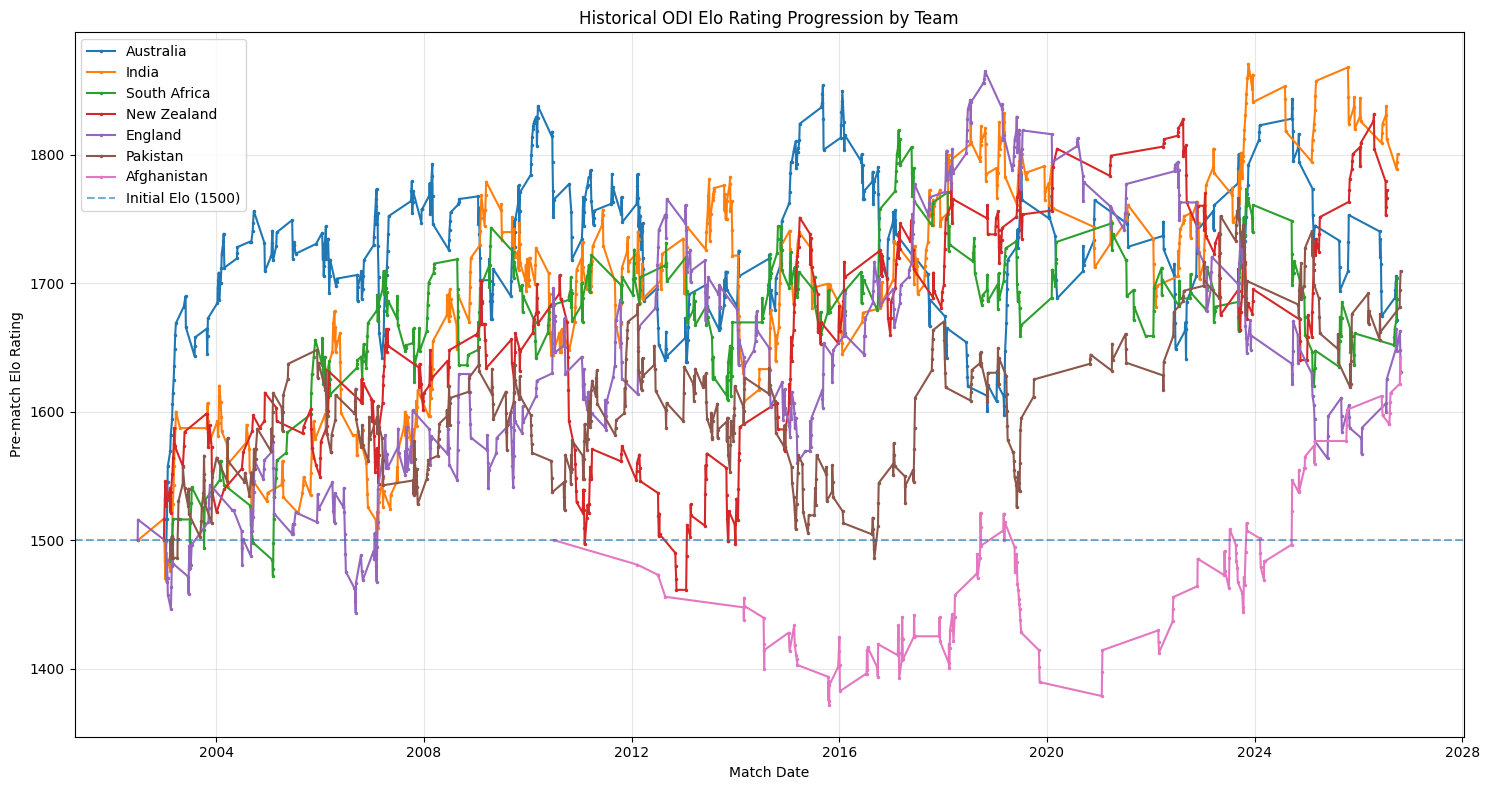

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Select teams for historical Elo comparison
selected_teams = [
    "Australia",
    "India",
    "South Africa",
    "New Zealand",
    "England",
    "Pakistan",
    "Afghanistan"
]

# Prepare Team 1 ratings
elo_team_1 = features_df[
    ["match_date", "team_1", "team_1_elo"]
].rename(columns={
    "team_1": "team",
    "team_1_elo": "elo_rating"
})

# Prepare Team 2 ratings
elo_team_2 = features_df[
    ["match_date", "team_2", "team_2_elo"]
].rename(columns={
    "team_2": "team",
    "team_2_elo": "elo_rating"
})

# Combine both teams
elo_progression = pd.concat(
    [elo_team_1, elo_team_2],
    ignore_index=True
)

# Convert dates
elo_progression["match_date"] = pd.to_datetime(
    elo_progression["match_date"],
    errors="coerce"
)

# Filter selected teams
elo_progression = elo_progression[
    elo_progression["team"].isin(selected_teams)
].dropna(subset=["match_date", "elo_rating"])

# Sort chronologically
elo_progression = elo_progression.sort_values("match_date")

# Plot Elo progression
plt.figure(figsize=(15, 8))

for team in selected_teams:
    team_data = elo_progression[
        elo_progression["team"] == team
    ]

    plt.plot(
        team_data["match_date"],
        team_data["elo_rating"],
        label=team,
        linewidth=1.5,
        marker=".",
        markersize=3
    )

plt.axhline(
    1500,
    linestyle="--",
    alpha=0.6,
    label="Initial Elo (1500)"
)

plt.xlabel("Match Date")
plt.ylabel("Pre-match Elo Rating")
plt.title("Historical ODI Elo Rating Progression by Team")

plt.legend(loc="best")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Prepare Elo outcome analysis
elo_outcome = features_df[
    ["elo_difference", "team_1_win"]
].copy()

elo_outcome["elo_difference"] = pd.to_numeric(
    elo_outcome["elo_difference"],
    errors="coerce"
)

elo_outcome["team_1_win"] = pd.to_numeric(
    elo_outcome["team_1_win"],
    errors="coerce"
)

elo_outcome = elo_outcome.dropna()

# Group matches by Elo advantage
elo_outcome["elo_group"] = pd.cut(
    elo_outcome["elo_difference"],
    bins=[-float("inf"), -200, -100, 0, 100, 200, float("inf")],
    labels=[
        "Below -200",
        "-200 to -100",
        "-100 to 0",
        "0 to 100",
        "100 to 200",
        "Above 200"
    ]
)

elo_results = (
    elo_outcome.groupby("elo_group", observed=False)
    .agg(
        matches=("team_1_win", "count"),
        team_1_wins=("team_1_win", "sum"),
        team_1_win_rate=("team_1_win", "mean")
    )
)

elo_results["team_1_win_rate"] *= 100

print("ELO DIFFERENCE VS MATCH OUTCOME")
print("=" * 60)

display(elo_results.round(2))

ELO DIFFERENCE VS MATCH OUTCOME


,matches,team_1_wins,team_1_win_rate
elo_group,,,
Below -200,304,63.0,20.72
-200 to -100,348,130.0,37.36
-100 to 0,646,322.0,49.85
0 to 100,675,423.0,62.67
100 to 200,364,247.0,67.86
Above 200,277,233.0,84.12


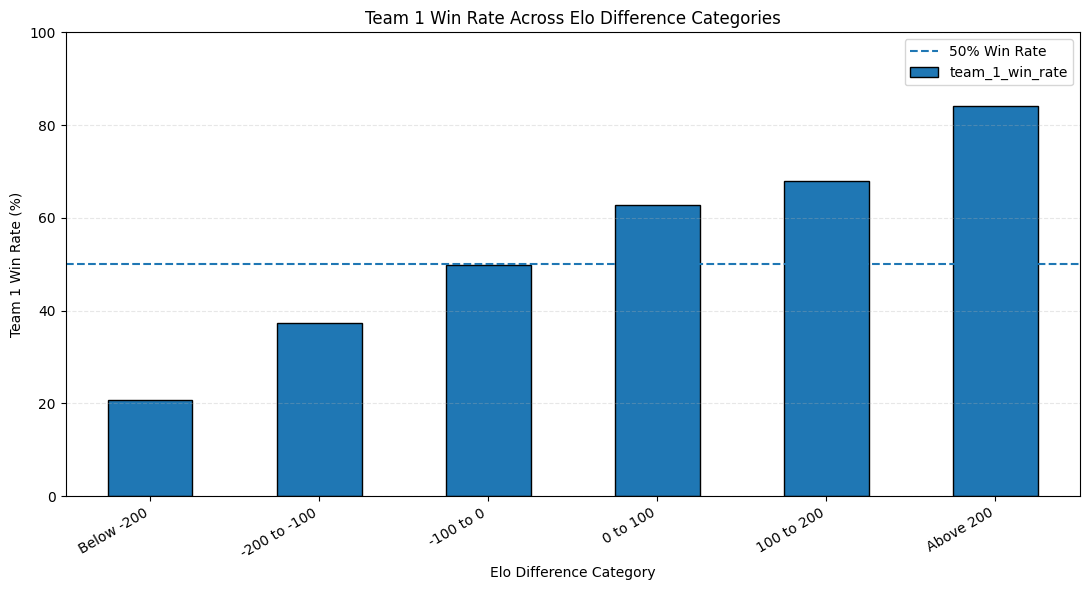

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

elo_results["team_1_win_rate"].plot(
    kind="bar",
    edgecolor="black"
)

plt.axhline(
    50,
    linestyle="--",
    label="50% Win Rate"
)

plt.xlabel("Elo Difference Category")
plt.ylabel("Team 1 Win Rate (%)")
plt.title("Team 1 Win Rate Across Elo Difference Categories")

plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Calculate theoretical Elo probability
elo_outcome["expected_win_probability"] = (
    1 / (
        1 + 10 ** (
            -elo_outcome["elo_difference"] / 400
        )
    )
)

# Compare theoretical and observed win rates
elo_calibration = (
    elo_outcome.groupby("elo_group", observed=False)
    .agg(
        matches=("team_1_win", "count"),
        actual_win_rate=("team_1_win", "mean"),
        expected_win_rate=("expected_win_probability", "mean")
    )
)

elo_calibration["actual_win_rate"] *= 100
elo_calibration["expected_win_rate"] *= 100

elo_calibration["difference"] = (
    elo_calibration["actual_win_rate"] -
    elo_calibration["expected_win_rate"]
)

print("ELO PROBABILITY CALIBRATION")
print("=" * 65)

display(elo_calibration.round(2))

ELO PROBABILITY CALIBRATION


,matches,actual_win_rate,expected_win_rate,difference
elo_group,,,,
Below -200,304,20.72,16.67,4.06
-200 to -100,348,37.36,30.19,7.17
-100 to 0,646,49.85,43.49,6.35
0 to 100,675,62.67,57.07,5.60
100 to 200,364,67.86,69.79,-1.94
Above 200,277,84.12,82.74,1.37


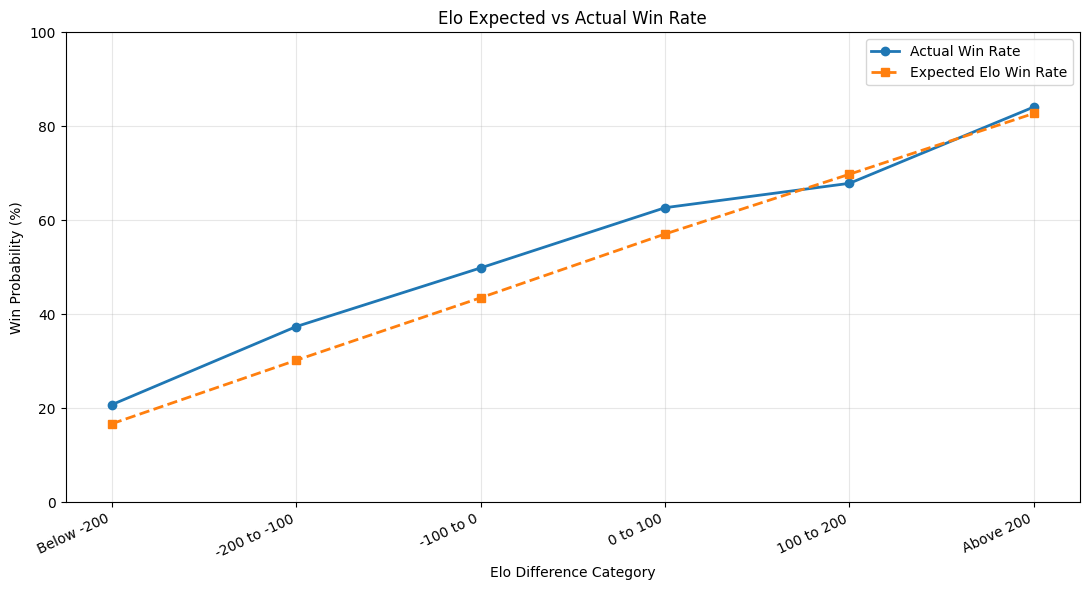

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

x = range(len(elo_calibration))

plt.plot(
    x,
    elo_calibration["actual_win_rate"],
    marker="o",
    linewidth=2,
    label="Actual Win Rate"
)

plt.plot(
    x,
    elo_calibration["expected_win_rate"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Expected Elo Win Rate"
)

plt.xticks(
    x,
    elo_calibration.index.astype(str),
    rotation=25,
    ha="right"
)

plt.ylabel("Win Probability (%)")
plt.xlabel("Elo Difference Category")
plt.title("Elo Expected vs Actual Win Rate")

plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("MATCH OUTCOME VALIDATION")
print("=" * 50)

print("\nteam_1_win value counts:")
print(features_df["team_1_win"].value_counts(dropna=False))

print("\nUnique values:")
print(features_df["team_1_win"].unique())

print("\nMissing outcomes:")
print(features_df["team_1_win"].isna().sum())

print("\nOutcome data types:")
print(features_df["team_1_win"].dtype)

MATCH OUTCOME VALIDATION

team_1_win value counts:
team_1_win
1.0    1418
0.0    1196
NaN     139
Name: count, dtype: int64

Unique values:
[ 1.  0. nan]

Missing outcomes:
139

Outcome data types:
float64


In [ ]:
import numpy as np
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score
)

# Prepare valid match outcomes
elo_evaluation = features_df[
    ["elo_difference", "team_1_win"]
].copy()

elo_evaluation = elo_evaluation.dropna()

# Calculate theoretical Elo probabilities
elo_evaluation["elo_probability"] = (
    1 / (
        1 + 10 ** (
            -elo_evaluation["elo_difference"] / 400
        )
    )
)

y_true = elo_evaluation["team_1_win"].astype(int)
y_prob = elo_evaluation["elo_probability"]

# 50% probability baseline
baseline_prob = np.full(len(y_true), 0.5)

# Elo performance
elo_brier = brier_score_loss(y_true, y_prob)
elo_logloss = log_loss(y_true, y_prob)
elo_auc = roc_auc_score(y_true, y_prob)

# Baseline performance
baseline_brier = brier_score_loss(y_true, baseline_prob)
baseline_logloss = log_loss(y_true, baseline_prob)
baseline_auc = roc_auc_score(y_true, baseline_prob)

print("CRICKETIQ ELO PREDICTION PERFORMANCE")
print("=" * 60)

print("Evaluated matches:", len(y_true))

print("\nELO MODEL:")
print(f"Brier Score : {elo_brier:.4f}")
print(f"Log Loss    : {elo_logloss:.4f}")
print(f"ROC-AUC     : {elo_auc:.4f}")

print("\n50% BASELINE:")
print(f"Brier Score : {baseline_brier:.4f}")
print(f"Log Loss    : {baseline_logloss:.4f}")
print(f"ROC-AUC     : {baseline_auc:.4f}")

CRICKETIQ ELO PREDICTION PERFORMANCE
Evaluated matches: 2614

ELO MODEL:
Brier Score : 0.2189
Log Loss    : 0.6274
ROC-AUC     : 0.7022

50% BASELINE:
Brier Score : 0.2500
Log Loss    : 0.6931
ROC-AUC     : 0.5000


In [ ]:
# ELO PERFORMANCE BY HISTORICAL PERIOD

elo_period_data = features_df[
    ["match_date", "elo_difference", "team_1_win"]
].copy()

elo_period_data["match_date"] = pd.to_datetime(
    elo_period_data["match_date"],
    errors="coerce"
)

elo_period_data = elo_period_data.dropna(
    subset=["match_date", "team_1_win", "elo_difference"]
)

elo_period_data["year"] = elo_period_data["match_date"].dt.year

elo_period_data["period"] = pd.cut(
    elo_period_data["year"],
    bins=[2001, 2010, 2018, 2026],
    labels=["2002–2010", "2011–2018", "2019–2026"]
)

print("MATCH DISTRIBUTION BY PERIOD")
print("=" * 50)

display(
    elo_period_data.groupby(
        "period",
        observed=False
    ).agg(
        matches=("team_1_win", "count"),
        start_year=("year", "min"),
        end_year=("year", "max")
    )
)

MATCH DISTRIBUTION BY PERIOD


,matches,start_year,end_year
period,,,
2002–2010,808,2002,2010
2011–2018,892,2011,2018
2019–2026,914,2019,2026


In [ ]:
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score
)

period_results = []

for period, group in elo_period_data.groupby("period", observed=True):

    y_true = group["team_1_win"].astype(int)

    # Theoretical pre-match Elo probability
    y_prob = 1 / (
        1 + 10 ** (-group["elo_difference"] / 400)
    )

    period_results.append({
        "period": str(period),
        "matches": len(group),
        "team_1_win_rate": y_true.mean() * 100,
        "brier_score": brier_score_loss(y_true, y_prob),
        "log_loss": log_loss(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob)
    })

period_elo_performance = pd.DataFrame(period_results)

print("ELO PERFORMANCE ACROSS HISTORICAL PERIODS")
print("=" * 75)

display(period_elo_performance.round(4))

ELO PERFORMANCE ACROSS HISTORICAL PERIODS


,period,matches,team_1_win_rate,brier_score,log_loss,roc_auc
0,2002–2010,808,53.0941,0.2106,0.6093,0.7266
1,2011–2018,892,57.3991,0.2194,0.6272,0.7058
2,2019–2026,914,52.1882,0.2257,0.6435,0.6824


In [ ]:
from sklearn.metrics import brier_score_loss, log_loss

baseline_comparison = []

for period, group in elo_period_data.groupby(
    "period", observed=True
):

    y_true = group["team_1_win"].astype(int)

    elo_probability = (
        1 / (1 + 10 ** (-group["elo_difference"] / 400))
    )

    # Baseline: predict the historical win rate in this period
    baseline_probability = np.full(
        len(y_true),
        y_true.mean()
    )

    baseline_comparison.append({
        "period": str(period),
        "matches": len(group),
        "elo_brier": brier_score_loss(
            y_true, elo_probability
        ),
        "baseline_brier": brier_score_loss(
            y_true, baseline_probability
        ),
        "elo_log_loss": log_loss(
            y_true, elo_probability
        ),
        "baseline_log_loss": log_loss(
            y_true, baseline_probability
        )
    })

baseline_comparison_df = pd.DataFrame(
    baseline_comparison
)

print("ELO VS PERIOD-SPECIFIC BASELINE")
print("=" * 70)

display(baseline_comparison_df.round(4))

ELO VS PERIOD-SPECIFIC BASELINE


,period,matches,elo_brier,baseline_brier,elo_log_loss,baseline_log_loss
0,2002–2010,808,0.2106,0.2490,0.6093,0.6912
1,2011–2018,892,0.2194,0.2445,0.6272,0.6822
2,2019–2026,914,0.2257,0.2495,0.6435,0.6922


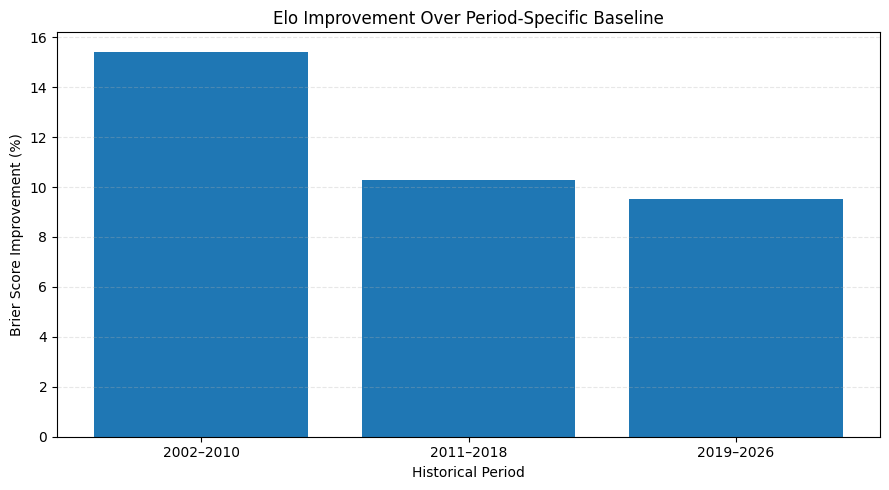

,period,brier_improvement_pct
0,2002–2010,15.42
1,2011–2018,10.27
2,2019–2026,9.54


In [ ]:
import matplotlib.pyplot as plt

baseline_comparison_df["brier_improvement_pct"] = (
    (
        baseline_comparison_df["baseline_brier"] -
        baseline_comparison_df["elo_brier"]
    )
    / baseline_comparison_df["baseline_brier"]
) * 100

plt.figure(figsize=(9, 5))

plt.bar(
    baseline_comparison_df["period"],
    baseline_comparison_df["brier_improvement_pct"]
)

plt.xlabel("Historical Period")
plt.ylabel("Brier Score Improvement (%)")
plt.title("Elo Improvement Over Period-Specific Baseline")

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    baseline_comparison_df[
        ["period", "brier_improvement_pct"]
    ].round(2)
)

In [ ]:
import pandas as pd
from pathlib import Path

# Load existing integrated player dataset
player_features = pd.read_csv(
    r"C:\CricIQ\data\features\player_data\cricketiq_player_match_features.csv"
)

print("INTEGRATED BOWLING DATA INSPECTION")
print("=" * 60)

print("\nDataset shape:", player_features.shape)

# Identify bowling-related columns
bowling_columns = [
    col for col in player_features.columns
    if any(word in col.lower() for word in [
        "bowl", "wicket", "economy", "maiden",
        "conceded", "overs"
    ])
]

print("\nBowling-related columns:")
for col in bowling_columns:
    print(col)

print("\nBowling data sample:")
display(player_features[bowling_columns].head(10))

INTEGRATED BOWLING DATA INSPECTION

Dataset shape: (58319, 72)

Bowling-related columns:
bowling_innings_number
runs_conceded
wickets
maidens
has_bowling_record
pre_match_career_bowling_innings
pre_match_career_bowling_runs_conceded
pre_match_career_bowling_wickets
pre_match_career_bowling_legal_balls
pre_match_career_bowling_average
pre_match_career_bowling_economy
pre_match_career_bowling_strike_rate
pre_match_recent_5_bowling_innings
pre_match_recent_5_bowling_runs_conceded
pre_match_recent_5_bowling_legal_balls
pre_match_recent_5_bowling_wickets
pre_match_recent_5_bowling_average
pre_match_recent_5_bowling_economy
pre_match_recent_5_bowling_strike_rate
pre_match_recent_10_bowling_innings
pre_match_recent_10_bowling_runs_conceded
pre_match_recent_10_bowling_legal_balls
pre_match_recent_10_bowling_wickets
pre_match_recent_10_bowling_average
pre_match_recent_10_bowling_economy
pre_match_recent_10_bowling_strike_rate

Bowling data sample:


C:\Users\ASUS\AppData\Local\Temp\ipykernel_22372\2704976844.py:5: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  player_features = pd.read_csv(


,bowling_innings_number,runs_conceded,wickets,maidens,has_bowling_record,pre_match_career_bowling_innings,pre_match_career_bowling_runs_conceded,pre_match_career_bowling_wickets,pre_match_career_bowling_legal_balls,pre_match_career_bowling_average,...,pre_match_recent_5_bowling_average,pre_match_recent_5_bowling_economy,pre_match_recent_5_bowling_strike_rate,pre_match_recent_10_bowling_innings,pre_match_recent_10_bowling_runs_conceded,pre_match_recent_10_bowling_legal_balls,pre_match_recent_10_bowling_wickets,pre_match_recent_10_bowling_average,pre_match_recent_10_bowling_economy,pre_match_recent_10_bowling_strike_rate
0,NaN,NaN,NaN,NaN,False,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,False,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
2,2.0,40.0,2.0,NaN,True,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
3,1.0,46.0,2.0,NaN,True,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
4,1.0,43.0,0.0,NaN,True,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,False,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,False,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,False,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
8,2.0,31.0,2.0,NaN,True,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN
9,2.0,30.0,0.0,NaN,True,0.0,0.0,0.0,0.0,NaN,...,NaN,NaN,NaN,0,0.0,0.0,0.0,NaN,NaN,NaN


In [ ]:
# BOWLING DATA QUALITY VALIDATION

bowling_records = player_features[
    player_features["has_bowling_record"] == True
].copy()

print("INTEGRATED BOWLING DATA VALIDATION")
print("=" * 60)

print("\n1. Total player records:", len(player_features))
print("Actual bowling records:", len(bowling_records))

print("\n2. Bowling records by source:")
display(bowling_records["source"].value_counts())

print("\n3. Bowling record completeness:")
bowling_columns = [
    "bowling_innings_number",
    "runs_conceded",
    "wickets",
    "maidens"
]

display(bowling_records[bowling_columns].isnull().sum())

print("\n4. Data types:")
display(bowling_records[bowling_columns].dtypes)

print("\n5. Super Over distribution:")
display(bowling_records["is_super_over"].value_counts(dropna=False))

print("\n6. Duplicate player-match-innings records:")

duplicate_count = bowling_records.duplicated(
    subset=[
        "cricketiq_player_id",
        "match_key",
        "bowling_innings_number"
    ]
).sum()

print("Duplicate records:", duplicate_count)

INTEGRATED BOWLING DATA VALIDATION

1. Total player records: 58319
Actual bowling records: 32939

2. Bowling records by source:


source
Cricsheet    31174
Crickrida     1765
Name: count, dtype: int64


3. Bowling record completeness:


bowling_innings_number        0
runs_conceded                 0
wickets                       0
maidens                   31174
dtype: int64


4. Data types:


bowling_innings_number    float64
runs_conceded             float64
wickets                   float64
maidens                   float64
dtype: object


5. Super Over distribution:


is_super_over
False    32939
Name: count, dtype: int64


6. Duplicate player-match-innings records:
Duplicate records: 0


In [ ]:
print("BOWLING BALLS / OVERS COLUMN INSPECTION")
print("=" * 60)

for col in player_features.columns:
    if any(word in col.lower() for word in [
        "ball", "over", "legal", "delivery"
    ]):
        print(
            f"{col:50} | "
            f"{player_features[col].dtype}"
        )

print("\nSample bowling records:")

display(
    bowling_records[
        [
            "source",
            "canonical_player_name",
            "runs_conceded",
            "wickets"
        ]
    ].head(15)
)

BOWLING BALLS / OVERS COLUMN INSPECTION
balls_faced                                        | float64
legal_balls                                        | float64
no_balls                                           | float64
is_super_over                                      | bool
pre_match_career_batting_balls                     | float64
pre_match_career_bowling_legal_balls               | float64
pre_match_recent_5_batting_balls                   | float64
pre_match_recent_10_batting_balls                  | float64
pre_match_recent_5_bowling_legal_balls             | float64
pre_match_recent_10_bowling_legal_balls            | float64

Sample bowling records:


,source,canonical_player_name,runs_conceded,wickets
2,Cricsheet,RJ Kirtley,40.0,2.0
3,Cricsheet,CRD Fernando,46.0,2.0
4,Cricsheet,UDU Chandana,43.0,0.0
8,Cricsheet,PD Collingwood,31.0,2.0
9,Cricsheet,AF Giles,30.0,0.0
11,Cricsheet,WPUJC Vaas,58.0,2.0
12,Cricsheet,RP Arnold,41.0,1.0
14,Cricsheet,MJ Hoggard,49.0,1.0
15,Cricsheet,A Flintoff,49.0,3.0
17,Cricsheet,DNT Zoysa,46.0,1.0


In [ ]:
# LEGAL BALLS VALIDATION

print("LEGAL BALLS VALIDATION")
print("=" * 60)

print("\n1. Missing legal balls by source:")
display(
    bowling_records.groupby("source")["legal_balls"]
    .apply(lambda x: x.isna().sum())
)

print("\n2. Legal balls descriptive statistics:")
display(
    bowling_records.groupby("source")["legal_balls"]
    .describe()
    .round(2)
)

print("\n3. Zero legal balls:")
display(
    bowling_records.groupby("source")["legal_balls"]
    .apply(lambda x: (x == 0).sum())
)

print("\n4. Sample bowling records with legal balls:")
display(
    bowling_records[
        [
            "source",
            "canonical_player_name",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "no_balls"
        ]
    ].head(20)
)

print("\n5. Invalid negative legal balls:")
print((bowling_records["legal_balls"] < 0).sum())

LEGAL BALLS VALIDATION

1. Missing legal balls by source:


source
Crickrida    0
Cricsheet    0
Name: legal_balls, dtype: int64


2. Legal balls descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
Crickrida,1765.0,43.37,16.29,0.0,30.0,48.0,60.0,60.0
Cricsheet,31174.0,43.07,16.67,0.0,30.0,48.0,60.0,61.0



3. Zero legal balls:


source
Crickrida    1
Cricsheet    2
Name: legal_balls, dtype: int64


4. Sample bowling records with legal balls:


,source,canonical_player_name,runs_conceded,wickets,legal_balls,no_balls
2,Cricsheet,RJ Kirtley,40.0,2.0,60.0,1.0
3,Cricsheet,CRD Fernando,46.0,2.0,48.0,1.0
4,Cricsheet,UDU Chandana,43.0,0.0,60.0,0.0
8,Cricsheet,PD Collingwood,31.0,2.0,30.0,0.0
9,Cricsheet,AF Giles,30.0,0.0,30.0,0.0
11,Cricsheet,WPUJC Vaas,58.0,2.0,54.0,0.0
12,Cricsheet,RP Arnold,41.0,1.0,36.0,0.0
14,Cricsheet,MJ Hoggard,49.0,1.0,60.0,5.0
15,Cricsheet,A Flintoff,49.0,3.0,60.0,0.0
17,Cricsheet,DNT Zoysa,46.0,1.0,42.0,3.0



5. Invalid negative legal balls:
0


In [ ]:
# INVESTIGATE BOWLING DATA ANOMALIES

print("BOWLING DATA ANOMALY INVESTIGATION")
print("=" * 60)

# Records with zero legal balls
zero_ball_records = bowling_records[
    bowling_records["legal_balls"] == 0
]

print("\n1. Zero legal ball records:")
display(
    zero_ball_records[
        [
            "source",
            "canonical_player_name",
            "match_key",
            "bowling_innings_number",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "no_balls"
        ]
    ]
)

# Records exceeding 60 legal balls
excess_ball_records = bowling_records[
    bowling_records["legal_balls"] > 60
]

print("\n2. Records exceeding 60 legal balls:")
display(
    excess_ball_records[
        [
            "source",
            "canonical_player_name",
            "match_key",
            "bowling_innings_number",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "no_balls"
        ]
    ]
)

BOWLING DATA ANOMALY INVESTIGATION

1. Zero legal ball records:


,source,canonical_player_name,match_key,bowling_innings_number,runs_conceded,wickets,legal_balls,no_balls
6957,Cricsheet,CO Obuya,CS_MATCH_249379,2.0,5.0,0.0,0.0,1.0
26013,Cricsheet,Abdur Rehman,CS_MATCH_710305,1.0,8.0,0.0,0.0,3.0
52496,Crickrida,Rahmanullah Gurbaz,CR_MATCH_20240922_Afghanistan_South Africa,2.0,1.0,0.0,0.0,0.0



2. Records exceeding 60 legal balls:


,source,canonical_player_name,match_key,bowling_innings_number,runs_conceded,wickets,legal_balls,no_balls
1977,Cricsheet,Mohammad Rafique,CS_MATCH_64832,1.0,31.0,2.0,61.0,0.0
2146,Cricsheet,Abdul Razzaq,CS_MATCH_64842,2.0,33.0,0.0,61.0,2.0
10343,Cricsheet,Stuart Broad,CS_MATCH_258475,1.0,84.0,1.0,61.0,0.0
11334,Cricsheet,Chris Mpofu,CS_MATCH_325803,2.0,36.0,1.0,61.0,0.0
12152,Cricsheet,Tim Southee,CS_MATCH_296906,2.0,38.0,4.0,61.0,0.0
14585,Cricsheet,Prosper Utseya,CS_MATCH_410340,2.0,46.0,1.0,61.0,0.0
14598,Cricsheet,RW Price,CS_MATCH_410340,2.0,60.0,3.0,61.0,0.0
34290,Cricsheet,Ravichandran Ashwin,CS_MATCH_1022373,1.0,59.0,0.0,61.0,0.0
38257,Cricsheet,Hardik Pandya,CS_MATCH_1153693,1.0,45.0,2.0,61.0,0.0
45124,Cricsheet,DS Airee,CS_MATCH_1322031,1.0,41.0,1.0,61.0,0.0


In [ ]:
# VALIDATE BOWLING LEGAL BALLS AGAINST ORIGINAL CRICSHEET DELIVERIES

deliveries_df = pd.read_csv(
    r"C:\CricIQ\data\processed\cricsheet_odi\cricsheet_odi_deliveries.csv"
)

print("DELIVERY DATA COLUMNS:")
print(deliveries_df.columns.tolist())

print("\nDELIVERY DATA SHAPE:", deliveries_df.shape)

# Extract anomalous Cricsheet records
anomalies = bowling_records[
    (bowling_records["source"] == "Cricsheet") &
    (
        (bowling_records["legal_balls"] == 0) |
        (bowling_records["legal_balls"] > 60)
    )
].copy()

# Extract original numeric match IDs from match_key
anomalies["match_id"] = (
    anomalies["match_key"]
    .str.replace("CS_MATCH_", "", regex=False)
)

print("\nANOMALOUS PLAYER RECORDS:")
display(
    anomalies[
        [
            "canonical_player_name",
            "match_key",
            "match_id",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "no_balls"
        ]
    ]
)

# Inspect original deliveries for these matches
match_ids = anomalies["match_id"].astype(str).unique()

delivery_matches = deliveries_df[
    deliveries_df["match_id"].astype(str).isin(match_ids)
].copy()

print("\nORIGINAL DELIVERY RECORDS FOR ANOMALOUS MATCHES:")
display(delivery_matches.head(30))

DELIVERY DATA COLUMNS:
['match_id', 'innings_number', 'batting_team', 'over', 'delivery', 'batter', 'bowler', 'non_striker', 'batter_runs', 'extra_runs', 'total_runs', 'extras', 'wickets']

DELIVERY DATA SHAPE: (1379686, 13)

ANOMALOUS PLAYER RECORDS:


,canonical_player_name,match_key,match_id,runs_conceded,wickets,legal_balls,no_balls
1977,Mohammad Rafique,CS_MATCH_64832,64832,31.0,2.0,61.0,0.0
2146,Abdul Razzaq,CS_MATCH_64842,64842,33.0,0.0,61.0,2.0
6957,CO Obuya,CS_MATCH_249379,249379,5.0,0.0,0.0,1.0
10343,Stuart Broad,CS_MATCH_258475,258475,84.0,1.0,61.0,0.0
11334,Chris Mpofu,CS_MATCH_325803,325803,36.0,1.0,61.0,0.0
12152,Tim Southee,CS_MATCH_296906,296906,38.0,4.0,61.0,0.0
14585,Prosper Utseya,CS_MATCH_410340,410340,46.0,1.0,61.0,0.0
14598,RW Price,CS_MATCH_410340,410340,60.0,3.0,61.0,0.0
26013,Abdur Rehman,CS_MATCH_710305,710305,8.0,0.0,0.0,3.0
34290,Ravichandran Ashwin,CS_MATCH_1022373,1022373,59.0,0.0,61.0,0.0



ORIGINAL DELIVERY RECORDS FOR ANOMALOUS MATCHES:


,match_id,innings_number,batting_team,over,delivery,batter,bowler,non_striker,batter_runs,extra_runs,total_runs,extras,wickets
19099,1022373,1,Bangladesh,0,0.1,Tamim Iqbal,B Kumar,Soumya Sarkar,0,0,0,NaN,NaN
19100,1022373,1,Bangladesh,0,0.2,Tamim Iqbal,B Kumar,Soumya Sarkar,0,0,0,NaN,NaN
19101,1022373,1,Bangladesh,0,0.3,Tamim Iqbal,B Kumar,Soumya Sarkar,0,0,0,NaN,NaN
19102,1022373,1,Bangladesh,0,0.4,Tamim Iqbal,B Kumar,Soumya Sarkar,1,0,1,NaN,NaN
19103,1022373,1,Bangladesh,0,0.5,Soumya Sarkar,B Kumar,Tamim Iqbal,0,0,0,NaN,NaN
19104,1022373,1,Bangladesh,0,0.6,Soumya Sarkar,B Kumar,Tamim Iqbal,0,0,0,NaN,"[{'kind': 'bowled', 'player_out': 'Soumya Sark..."
19105,1022373,1,Bangladesh,1,1.1,Tamim Iqbal,JJ Bumrah,Sabbir Rahman,0,4,4,{'legbyes': 4},NaN
19106,1022373,1,Bangladesh,1,1.2,Tamim Iqbal,JJ Bumrah,Sabbir Rahman,1,0,1,NaN,NaN
19107,1022373,1,Bangladesh,1,1.3,Sabbir Rahman,JJ Bumrah,Tamim Iqbal,4,0,4,NaN,NaN
19108,1022373,1,Bangladesh,1,1.4,Sabbir Rahman,JJ Bumrah,Tamim Iqbal,0,0,0,NaN,NaN


In [ ]:
import ast

# Recalculate legal balls directly from Cricsheet deliveries

def parse_extras(value):
    if isinstance(value, dict):
        return value

    if pd.isna(value):
        return {}

    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return {}


delivery_check = delivery_matches.copy()

delivery_check["extras_dict"] = delivery_check["extras"].apply(parse_extras)

delivery_check["is_legal_delivery"] = delivery_check["extras_dict"].apply(
    lambda x: not (
        "wides" in x or
        "noballs" in x
    )
)

# Aggregate original delivery-level data
delivery_bowling_summary = (
    delivery_check
    .groupby(
        ["match_id", "innings_number", "bowler"],
        as_index=False
    )
    .agg(
        total_delivery_events=("delivery", "count"),
        recalculated_legal_balls=("is_legal_delivery", "sum"),
        total_runs_conceded=("total_runs", "sum")
    )
)

# Display all bowling figures from anomalous match innings
anomaly_match_innings = anomalies[
    ["match_id", "bowling_innings_number"]
].drop_duplicates()

anomaly_match_innings["match_id"] = (
    anomaly_match_innings["match_id"].astype(int)
)

anomaly_match_innings["innings_number"] = (
    anomaly_match_innings["bowling_innings_number"].astype(int)
)

comparison = delivery_bowling_summary.merge(
    anomaly_match_innings[
        ["match_id", "innings_number"]
    ],
    on=["match_id", "innings_number"],
    how="inner"
)

print("RECALCULATED BOWLING FIGURES FROM ORIGINAL DELIVERIES")
print("=" * 70)

display(
    comparison.sort_values(
        ["match_id", "innings_number", "bowler"]
    )
)

RECALCULATED BOWLING FIGURES FROM ORIGINAL DELIVERIES


,match_id,innings_number,bowler,total_delivery_events,recalculated_legal_balls,total_runs_conceded
0,64832,1,Alok Kapali,62,60,45
1,64832,1,Khaled Mahmud,48,48,57
2,64832,1,Mashrafe Mortaza,60,60,43
3,64832,1,Mohammad Rafique,62,61,34
4,64832,1,Sanwar Hossain,12,12,12
...,...,...,...,...,...,...
85,1395701,1,Hasan Mahmud,66,60,48
86,1395701,1,Khaled Ahmed,56,56,60
87,1395701,1,Mahedi Hasan,61,61,45
88,1395701,1,Mustafizur Rahman,60,60,57


In [ ]:
# DISPLAY ALL ANOMALOUS MATCH-INNINGS BOWLING RECORDS

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", None)

print("ALL ANOMALOUS MATCH-INNINGS BOWLING RECORDS")
print("=" * 80)

display(
    comparison.sort_values(
        ["match_id", "innings_number", "recalculated_legal_balls"],
        ascending=[True, True, False]
    ).reset_index(drop=True)
)

# Check the distribution of legal balls in these spells
print("\nLEGAL BALL COUNTS IN ANOMALOUS MATCH INNINGS:")

display(
    comparison["recalculated_legal_balls"]
    .value_counts()
    .sort_index()
    .rename_axis("legal_balls")
    .to_frame("number_of_bowling_records")
)

ALL ANOMALOUS MATCH-INNINGS BOWLING RECORDS


,match_id,innings_number,bowler,total_delivery_events,recalculated_legal_balls,total_runs_conceded
0,64832,1,Mohammad Rafique,62,61,34
1,64832,1,Alok Kapali,62,60,45
2,64832,1,Mashrafe Mortaza,60,60,43
3,64832,1,Tapash Baisya,62,60,63
4,64832,1,Khaled Mahmud,48,48,57
5,64832,1,Sanwar Hossain,12,12,12
6,64842,2,Abdul Razzaq,63,61,33
7,64842,2,Danish Kaneria,63,60,38
8,64842,2,Mohammad Sami,63,60,51
9,64842,2,Shoaib Akhtar,50,48,33



LEGAL BALL COUNTS IN ANOMALOUS MATCH INNINGS:


,number_of_bowling_records
legal_balls,
0,2
5,1
6,5
7,1
12,4
18,2
23,1
24,5
30,2


In [ ]:
# INSPECT ALL 61-LEGAL-BALL BOWLING SPELLS

anomalous_61 = comparison[
    comparison["recalculated_legal_balls"] > 60
].copy()

for _, record in anomalous_61.iterrows():

    match_id = record["match_id"]
    innings = record["innings_number"]
    bowler = record["bowler"]

    spell = delivery_check[
        (delivery_check["match_id"] == match_id) &
        (delivery_check["innings_number"] == innings) &
        (delivery_check["bowler"] == bowler)
    ].copy()

    spell = spell.sort_values(
        ["over", "delivery"]
    ).reset_index(drop=True)

    spell["cumulative_legal_balls"] = (
        spell["is_legal_delivery"].cumsum()
    )

    print("\n" + "=" * 75)
    print(
        f"Match: {match_id} | Innings: {innings} | "
        f"Bowler: {bowler}"
    )
    print("Total events:", len(spell))
    print(
        "Legal balls:",
        int(spell["is_legal_delivery"].sum())
    )
    print("Highest over:", spell["over"].max())

    # Check repeated delivery labels
    duplicate_labels = spell[
        spell.duplicated(
            subset=["over", "delivery"],
            keep=False
        )
    ]

    print("Repeated delivery labels:", len(duplicate_labels))

    # Show the final 15 recorded deliveries
    print("\nFinal 15 deliveries:")
    display(
        spell.tail(15)[
            [
                "over",
                "delivery",
                "batter",
                "bowler",
                "total_runs",
                "extras",
                "is_legal_delivery",
                "cumulative_legal_balls"
            ]
        ]
    )


Match: 64832 | Innings: 1 | Bowler: Mohammad Rafique
Total events: 62
Legal balls: 61
Highest over: 41
Repeated delivery labels: 2

Final 15 deliveries:


,over,delivery,batter,bowler,total_runs,extras,is_legal_delivery,cumulative_legal_balls
47,26,26.5,A Symonds,Mohammad Rafique,0,NaN,True,47
48,26,26.6,MG Bevan,Mohammad Rafique,0,NaN,True,48
49,26,26.7,MG Bevan,Mohammad Rafique,0,NaN,True,49
50,39,39.1,RT Ponting,Mohammad Rafique,0,NaN,True,50
51,39,39.2,RT Ponting,Mohammad Rafique,0,NaN,True,51
52,39,39.3,RT Ponting,Mohammad Rafique,0,NaN,True,52
53,39,39.4,RT Ponting,Mohammad Rafique,0,NaN,True,53
54,39,39.5,RT Ponting,Mohammad Rafique,1,{'legbyes': 1},True,54
55,39,39.6,MG Bevan,Mohammad Rafique,1,NaN,True,55
56,41,41.1,RT Ponting,Mohammad Rafique,1,NaN,True,56



Match: 64842 | Innings: 2 | Bowler: Abdul Razzaq
Total events: 63
Legal balls: 61
Highest over: 40
Repeated delivery labels: 4

Final 15 deliveries:


,over,delivery,batter,bowler,total_runs,extras,is_legal_delivery,cumulative_legal_balls
48,36,36.5,HH Dippenaar,Abdul Razzaq,1,NaN,True,48
49,36,36.6,JH Kallis,Abdul Razzaq,0,NaN,True,49
50,38,38.1,JH Kallis,Abdul Razzaq,0,NaN,True,50
51,38,38.2,JH Kallis,Abdul Razzaq,1,NaN,True,51
52,38,38.3,HH Dippenaar,Abdul Razzaq,1,NaN,True,52
53,38,38.4,JH Kallis,Abdul Razzaq,1,NaN,True,53
54,38,38.5,HH Dippenaar,Abdul Razzaq,2,{'noballs': 1},False,53
55,38,38.5,JH Kallis,Abdul Razzaq,0,NaN,True,54
56,38,38.6,JH Kallis,Abdul Razzaq,2,NaN,True,55
57,40,40.1,JA Rudolph,Abdul Razzaq,2,NaN,True,56



Match: 258475 | Innings: 1 | Bowler: SCJ Broad
Total events: 63
Legal balls: 61
Highest over: 49
Repeated delivery labels: 4

Final 15 deliveries:


,over,delivery,batter,bowler,total_runs,extras,is_legal_delivery,cumulative_legal_balls
48,41,41.4,G Gambhir,SCJ Broad,0,NaN,True,47
49,41,41.5,Yuvraj Singh,SCJ Broad,4,NaN,True,48
50,41,41.6,Yuvraj Singh,SCJ Broad,4,NaN,True,49
51,47,47.1,R Dravid,SCJ Broad,4,NaN,True,50
52,47,47.2,R Dravid,SCJ Broad,0,NaN,True,51
53,47,47.3,R Dravid,SCJ Broad,4,NaN,True,52
54,47,47.4,R Dravid,SCJ Broad,6,NaN,True,53
55,47,47.5,R Dravid,SCJ Broad,1,NaN,True,54
56,47,47.6,MS Dhoni,SCJ Broad,4,NaN,True,55
57,49,49.1,KD Karthik,SCJ Broad,1,NaN,True,56


... (16 outputs left out)


Match: 1339596 | Innings: 1 | Bowler: M Jansen
Total events: 66
Legal balls: 61
Highest over: 47
Repeated delivery labels: 9

Final 15 deliveries:


,over,delivery,batter,bowler,total_runs,extras,is_legal_delivery,cumulative_legal_balls
51,43,43.6,SM Curran,M Jansen,1,NaN,True,49
52,45,45.1,SM Curran,M Jansen,0,NaN,True,50
53,45,45.2,SM Curran,M Jansen,0,NaN,True,51
54,45,45.3,SM Curran,M Jansen,0,NaN,True,52
55,45,45.4,SM Curran,M Jansen,1,NaN,True,53
56,45,45.5,JC Buttler,M Jansen,1,{'wides': 1},False,53
57,45,45.5,JC Buttler,M Jansen,0,NaN,True,54
58,45,45.6,JC Buttler,M Jansen,1,NaN,True,55
59,47,47.1,JC Buttler,M Jansen,2,NaN,True,56
60,47,47.2,JC Buttler,M Jansen,1,{'wides': 1},False,56



Match: 1395701 | Innings: 1 | Bowler: Mahedi Hasan
Total events: 61
Legal balls: 61
Highest over: 48
Repeated delivery labels: 0

Final 15 deliveries:


,over,delivery,batter,bowler,total_runs,extras,is_legal_delivery,cumulative_legal_balls
46,44,44.5,KA Jamieson,Mahedi Hasan,0,NaN,True,47
47,44,44.6,LH Ferguson,Mahedi Hasan,0,NaN,True,48
48,46,46.1,LH Ferguson,Mahedi Hasan,0,NaN,True,49
49,46,46.2,LH Ferguson,Mahedi Hasan,1,NaN,True,50
50,46,46.3,IS Sodhi,Mahedi Hasan,0,NaN,True,51
51,46,46.4,IS Sodhi,Mahedi Hasan,0,NaN,True,52
52,46,46.5,IS Sodhi,Mahedi Hasan,2,NaN,True,53
53,46,46.6,IS Sodhi,Mahedi Hasan,1,NaN,True,54
54,46,46.7,LH Ferguson,Mahedi Hasan,0,NaN,True,55
55,48,48.1,LH Ferguson,Mahedi Hasan,0,NaN,True,56


In [ ]:
# CHECK LEGAL BALLS PER BOWLER PER OVER

over_bowling_check = (
    delivery_check
    .groupby(
        ["match_id", "innings_number", "bowler", "over"],
        as_index=False
    )
    .agg(
        delivery_events=("delivery", "count"),
        legal_balls=("is_legal_delivery", "sum")
    )
)

# Find overs with more than six legal deliveries
overs_with_excess_balls = over_bowling_check[
    over_bowling_check["legal_balls"] > 6
].copy()

print("OVERS WITH MORE THAN SIX LEGAL DELIVERIES")
print("=" * 70)

display(
    overs_with_excess_balls.sort_values(
        ["match_id", "innings_number", "bowler", "over"]
    )
)

print("\nTotal unusual bowler-over records:",
      len(overs_with_excess_balls))

OVERS WITH MORE THAN SIX LEGAL DELIVERIES


,match_id,innings_number,bowler,over,delivery_events,legal_balls
35,64832,1,Mohammad Rafique,26,7,7
152,64842,2,Abdul Razzaq,16,7,7
334,258475,1,SCJ Broad,27,7,7
471,296906,2,TG Southee,22,7,7
533,325803,2,CB Mpofu,44,7,7
642,410340,2,P Utseya,10,7,7
655,410340,2,RW Price,24,8,7
809,1022373,1,R Ashwin,39,8,7
878,1153693,1,HH Pandya,28,8,7
972,1322031,1,DS Airee,35,7,7



Total unusual bowler-over records: 13


In [ ]:
# INSPECT ALL 13 ANOMALOUS OVERS

for _, row in overs_with_excess_balls.iterrows():

    match_id = row["match_id"]
    innings = row["innings_number"]
    bowler = row["bowler"]
    over_number = row["over"]

    unusual_over = delivery_check[
        (delivery_check["match_id"] == match_id) &
        (delivery_check["innings_number"] == innings) &
        (delivery_check["bowler"] == bowler) &
        (delivery_check["over"] == over_number)
    ].copy()

    print("\n" + "=" * 75)
    print(
        f"Match: {match_id} | Innings: {innings} | "
        f"Bowler: {bowler} | Over: {over_number}"
    )

    display(
        unusual_over[
            [
                "delivery",
                "batter",
                "total_runs",
                "extras",
                "is_legal_delivery"
            ]
        ].sort_values("delivery")
    )


Match: 64832 | Innings: 1 | Bowler: Mohammad Rafique | Over: 26


,delivery,batter,total_runs,extras,is_legal_delivery
1089312,26.1,RT Ponting,0,NaN,True
1089313,26.2,RT Ponting,0,NaN,True
1089314,26.3,RT Ponting,1,NaN,True
1089315,26.4,A Symonds,0,NaN,True
1089316,26.5,A Symonds,0,NaN,True
1089317,26.6,MG Bevan,0,NaN,True
1089318,26.7,MG Bevan,0,NaN,True



Match: 64842 | Innings: 2 | Bowler: Abdul Razzaq | Over: 16


,delivery,batter,total_runs,extras,is_legal_delivery
1094346,16.1,HH Gibbs,0,NaN,True
1094347,16.2,HH Gibbs,2,NaN,True
1094348,16.3,HH Gibbs,0,NaN,True
1094349,16.4,HH Gibbs,0,NaN,True
1094350,16.5,HH Gibbs,0,NaN,True
1094351,16.6,HH Gibbs,1,NaN,True
1094352,16.7,HH Dippenaar,0,NaN,True



Match: 258475 | Innings: 1 | Bowler: SCJ Broad | Over: 27


,delivery,batter,total_runs,extras,is_legal_delivery
703719,27.1,G Gambhir,0,NaN,True
703720,27.2,G Gambhir,1,NaN,True
703721,27.3,Yuvraj Singh,0,NaN,True
703722,27.4,Yuvraj Singh,0,NaN,True
703723,27.5,Yuvraj Singh,4,NaN,True
703724,27.6,Yuvraj Singh,0,NaN,True
703725,27.7,Yuvraj Singh,0,NaN,True


... (16 outputs left out)


Match: 1339596 | Innings: 1 | Bowler: M Jansen | Over: 38


,delivery,batter,total_runs,extras,is_legal_delivery
327915,38.1,JC Buttler,0,NaN,True
327916,38.2,JC Buttler,6,"{'legbyes': 1, 'penalty': 5}",True
327917,38.3,MM Ali,4,NaN,True
327918,38.4,MM Ali,0,NaN,True
327919,38.5,MM Ali,0,NaN,True
327920,38.6,MM Ali,0,NaN,True
327921,38.7,MM Ali,5,{'wides': 5},False
327922,38.7,MM Ali,1,{'wides': 1},False
327923,38.7,MM Ali,1,NaN,True



Match: 1395701 | Innings: 1 | Bowler: Mahedi Hasan | Over: 46


,delivery,batter,total_runs,extras,is_legal_delivery
435708,46.1,LH Ferguson,0,NaN,True
435709,46.2,LH Ferguson,1,NaN,True
435710,46.3,IS Sodhi,0,NaN,True
435711,46.4,IS Sodhi,0,NaN,True
435712,46.5,IS Sodhi,2,NaN,True
435713,46.6,IS Sodhi,1,NaN,True
435714,46.7,LH Ferguson,0,NaN,True


In [ ]:
from pathlib import Path
import pandas as pd

# Folder path
folder = Path(
    r"C:\CricIQ\data\processed\player_data"
)

if not folder.exists():
    print("Folder not found:", folder)

else:
    files = []

    for item in folder.rglob("*"):
        if item.is_file():
            files.append({
                "File Name": item.name,
                "Extension": item.suffix,
                "Size (KB)": round(item.stat().st_size / 1024, 2),
                "Relative Path": str(item.relative_to(folder))
            })

    contents_df = pd.DataFrame(files)

    print("TOTAL FILES:", len(contents_df))
    print("TOTAL FOLDERS:", sum(1 for p in folder.rglob("*") if p.is_dir()))

    display(
        contents_df.sort_values("Relative Path").reset_index(drop=True)
    )

TOTAL FILES: 29
TOTAL FOLDERS: 2


,File Name,Extension,Size (KB),Relative Path
0,afghanistan_innings_team_mapping.csv,.csv,27.58,afghanistan_innings_team_mapping.csv
1,afghanistan_player_batting.csv,.csv,514.54,afghanistan_player_batting.csv
2,afghanistan_player_bowling.csv,.csv,325.65,afghanistan_player_bowling.csv
3,cricketiq_player_identity_registry.csv,.csv,270.95,cricketiq_player_identity_registry.csv
4,crickrida_id_lookup.csv,.csv,13.90,crickrida_id_lookup.csv
5,cricsheet_bowler_wickets.csv,.csv,2482.65,cricsheet_bowler_wickets.csv
6,cricsheet_id_lookup.csv,.csv,70.89,cricsheet_id_lookup.csv
7,cricsheet_player_batting.csv,.csv,3875.56,cricsheet_player_batting.csv
8,cricsheet_player_bowling.csv,.csv,2416.15,cricsheet_player_bowling.csv
9,cricsheet_player_dismissals.csv,.csv,2450.26,cricsheet_player_dismissals.csv


In [ ]:
from pathlib import Path
import pandas as pd

# Latest integrated canonical bowling dataset
bowling_path = Path(
    r"C:\CricIQ\data\processed\player_data\identity_migration_20261123\cricketiq_player_bowling_canonical.csv"
)

integrated_bowling = pd.read_csv(bowling_path)

print("=" * 65)
print("CRICKETIQ INTEGRATED BOWLING DATASET")
print("=" * 65)

print("\n1. DATASET SHAPE")
print(integrated_bowling.shape)

print("\n2. COLUMNS")
print(integrated_bowling.columns.tolist())

print("\n3. DATA TYPES")
print(integrated_bowling.dtypes)

print("\n4. FIRST 10 RECORDS")
display(integrated_bowling.head(10))

print("\n5. MISSING VALUES")
display(
    integrated_bowling.isnull().sum()
    .to_frame("missing_values")
    .sort_values("missing_values", ascending=False)
)

print("\n6. DUPLICATE ROWS")
print(integrated_bowling.duplicated().sum())

print("\n7. UNIQUE PLAYER COUNT")
if "cricketiq_player_id" in integrated_bowling.columns:
    print(integrated_bowling["cricketiq_player_id"].nunique())

print("\n8. SOURCE DISTRIBUTION")
if "source" in integrated_bowling.columns:
    display(integrated_bowling["source"].value_counts())

CRICKETIQ INTEGRATED BOWLING DATASET

1. DATASET SHAPE
(31186, 13)

2. COLUMNS
['match_id', 'innings_number', 'bowler', 'bowler_id', 'runs_conceded', 'wides', 'no_balls', 'wickets', 'legal_balls', 'overs', 'economy', 'cricketiq_player_id', 'canonical_player_name']

3. DATA TYPES
match_id                   int64
innings_number             int64
bowler                    object
bowler_id                 object
runs_conceded              int64
wides                      int64
no_balls                   int64
wickets                    int64
legal_balls                int64
overs                    float64
economy                  float64
cricketiq_player_id       object
canonical_player_name     object
dtype: object

4. FIRST 10 RECORDS


,match_id,innings_number,bowler,bowler_id,runs_conceded,wides,no_balls,wickets,legal_balls,overs,economy,cricketiq_player_id,canonical_player_name
0,1000887,1,Hasan Ali,2911de16,65,2,0,3,54,9.0,7.222222,CRIQ_2911de16,Hasan Ali
1,1000887,1,Imad Wasim,9cb8d7a6,35,0,0,2,60,10.0,3.500000,CRIQ_9cb8d7a6,Imad Wasim
2,1000887,1,Mohammad Amir,e174dadd,54,3,0,2,60,10.0,5.400000,CRIQ_e174dadd,Mohammad Amir
3,1000887,1,Mohammad Hafeez,9ab63e7b,23,1,0,0,42,7.0,3.285714,CRIQ_9ab63e7b,Mohammad Hafeez
4,1000887,1,Mohammad Nawaz (3),3086f7a4,48,0,0,1,48,8.0,6.000000,CRIQ_3086f7a4,Mohammad Nawaz
5,1000887,1,Wahab Riaz,b3118300,42,3,1,0,36,6.0,7.000000,CRIQ_b3118300,Wahab Riaz
6,1000887,2,B Stanlake,6834d1f2,13,1,0,0,18,3.0,4.333333,CS_6834d1f2,B Stanlake
7,1000887,2,JP Faulkner,808f425a,32,0,0,4,42,7.0,4.571429,CRIQ_808f425a,James Faulkner
8,1000887,2,MA Starc,3fb19989,34,2,0,2,48,8.0,4.250000,CRIQ_3fb19989,Mitchell Starc
9,1000887,2,MR Marsh,3d8feaf8,27,0,0,1,36,6.0,4.500000,CRIQ_3d8feaf8,Mitchell Marsh



5. MISSING VALUES


,missing_values
economy,2
innings_number,0
bowler,0
bowler_id,0
match_id,0
runs_conceded,0
wides,0
wickets,0
no_balls,0
legal_balls,0



6. DUPLICATE ROWS
0

7. UNIQUE PLAYER COUNT
1502

8. SOURCE DISTRIBUTION


In [ ]:
# CANONICAL BOWLING DATA QUALITY VALIDATION

print("=" * 65)
print("CANONICAL BOWLING DATA VALIDATION")
print("=" * 65)

# 1. Source identifier distribution
print("\n1. BOWLER ID PREFIX DISTRIBUTION")

bowling_prefix = integrated_bowling["bowler_id"].str.split("_").str[0]

display(bowling_prefix.value_counts().to_frame("records"))

# 2. Match coverage
print("\n2. MATCH COVERAGE")

print("Unique matches:", integrated_bowling["match_id"].nunique())
print("Unique players:", integrated_bowling["cricketiq_player_id"].nunique())

# 3. Legal balls distribution
print("\n3. LEGAL BALLS VALIDATION")

print("Missing legal balls:", integrated_bowling["legal_balls"].isna().sum())
print("Zero legal balls:", (integrated_bowling["legal_balls"] == 0).sum())
print("Above 60 legal balls:", (integrated_bowling["legal_balls"] > 60).sum())

# 4. Identify unusual records
print("\n4. ZERO-BALL RECORDS")

display(
    integrated_bowling[
        integrated_bowling["legal_balls"] == 0
    ][
        [
            "match_id", "innings_number", "bowler",
            "runs_conceded", "wickets", "legal_balls", "economy"
        ]
    ]
)

print("\n5. RECORDS ABOVE 60 LEGAL BALLS")

display(
    integrated_bowling[
        integrated_bowling["legal_balls"] > 60
    ][
        [
            "match_id", "innings_number", "bowler",
            "runs_conceded", "wickets", "legal_balls", "economy"
        ]
    ]
)

# 6. Missing economy
print("\n6. MISSING ECONOMY RECORDS")

display(
    integrated_bowling[
        integrated_bowling["economy"].isna()
    ]
)

CANONICAL BOWLING DATA VALIDATION

1. BOWLER ID PREFIX DISTRIBUTION


,records
bowler_id,
a12e1d51,208
7dc35884,205
fe93fd9d,201
0dc00542,198
5bdcdb72,180
...,...
b590a4d8,1
49dfe4a4,1
1cb64b3c,1



2. MATCH COVERAGE
Unique matches: 2600
Unique players: 1502

3. LEGAL BALLS VALIDATION
Missing legal balls: 0
Zero legal balls: 2
Above 60 legal balls: 13

4. ZERO-BALL RECORDS


,match_id,innings_number,bowler,runs_conceded,wickets,legal_balls,economy
15529,249379,2,CO Obuya,5,0,0,NaN
28662,710305,1,Abdur Rehman,8,0,0,NaN



5. RECORDS ABOVE 60 LEGAL BALLS


,match_id,innings_number,bowler,runs_conceded,wickets,legal_balls,economy
426,1022373,1,R Ashwin,59,0,61,5.803279
3367,1153693,1,HH Pandya,45,2,61,4.426230
6908,1322031,1,DS Airee,41,1,61,4.032787
7155,1325551,2,Kuldeep Yadav,38,2,61,3.737705
7355,1339596,1,M Jansen,71,1,61,6.983607
9843,1395701,1,Mahedi Hasan,45,3,61,4.426230
16160,258475,1,SCJ Broad,84,1,61,8.262295
16829,296906,2,TG Southee,38,4,61,3.737705
17646,325803,2,CB Mpofu,36,1,61,3.540984
19242,410340,2,P Utseya,46,1,61,4.524590



6. MISSING ECONOMY RECORDS


,match_id,innings_number,bowler,bowler_id,runs_conceded,wides,no_balls,wickets,legal_balls,overs,economy,cricketiq_player_id,canonical_player_name
15529,249379,2,CO Obuya,5680f1ad,5,0,1,0,0,0.0,NaN,CS_5680f1ad,CO Obuya
28662,710305,1,Abdur Rehman,d094e7d1,8,0,3,0,0,0.0,NaN,CS_d094e7d1,Abdur Rehman


In [ ]:
# VERIFY SOURCE COVERAGE IN CANONICAL BOWLING DATASETS

afghanistan_bowling_path = Path(
    r"C:\CricIQ\data\processed\player_data\identity_migration_20261123\afghanistan_player_bowling_canonical.csv"
)

afghanistan_bowling = pd.read_csv(afghanistan_bowling_path)

print("=" * 70)
print("1. CRICKETIQ CANONICAL BOWLING: PLAYER ID PREFIXES")
print("=" * 70)

display(
    integrated_bowling["cricketiq_player_id"]
    .str.split("_").str[0]
    .value_counts()
    .to_frame("records")
)

print("\n2. CRICKETIQ CANONICAL BOWLING SHAPE")
print(integrated_bowling.shape)

print("\n3. AFGHANISTAN CANONICAL BOWLING SHAPE")
print(afghanistan_bowling.shape)

print("\n4. AFGHANISTAN BOWLING COLUMNS")
print(afghanistan_bowling.columns.tolist())

print("\n5. AFGHANISTAN BOWLING SAMPLE")
display(afghanistan_bowling.head(10))

print("\n6. AFGHANISTAN MISSING VALUES")
display(afghanistan_bowling.isna().sum().to_frame("missing"))

print("\n7. PLAYER ID PREFIXES IN AFGHANISTAN DATA")
if "cricketiq_player_id" in afghanistan_bowling.columns:
    display(
        afghanistan_bowling["cricketiq_player_id"]
        .astype(str)
        .str.split("_").str[0]
        .value_counts()
        .to_frame("records")
    )

1. CRICKETIQ CANONICAL BOWLING: PLAYER ID PREFIXES


,records
cricketiq_player_id,
CS,17734
CRIQ,13452



2. CRICKETIQ CANONICAL BOWLING SHAPE
(31186, 13)

3. AFGHANISTAN CANONICAL BOWLING SHAPE
(1765, 18)

4. AFGHANISTAN BOWLING COLUMNS
['player_name', 'overs_display', 'maidens', 'runs_conceded', 'wickets', 'wides', 'no_balls', 'legal_balls', 'innings_number', 'date', 'match_url', 'economy', 'batting_team', 'bowling_team', 'opponent', 'cricketiq_player_id', 'canonical_player_name', 'legacy_cricketiq_player_id']

5. AFGHANISTAN BOWLING SAMPLE


,player_name,overs_display,maidens,runs_conceded,wickets,wides,no_balls,legal_balls,innings_number,date,match_url,economy,batting_team,bowling_team,opponent,cricketiq_player_id,canonical_player_name,legacy_cricketiq_player_id
0,Shapoor Zadran,10.0,3,39,1,1,1,60,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,3.900000,Ireland,Afghanistan,Ireland,CR_shapoorzadran,Shapoor Zadran,CR_shapoorzadran
1,Khaliq Dad,8.0,1,27,2,4,1,48,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,3.375000,Ireland,Afghanistan,Ireland,CR_khaliqdad,Khaliq Dad,CR_khaliqdad
2,Hamid Hassan,8.0,0,44,3,0,1,48,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,5.500000,Ireland,Afghanistan,Ireland,CR_hamidhassan,Hamid Hassan,CR_hamidhassan
3,Mohammad Nabi,10.0,0,55,1,1,0,60,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,5.500000,Ireland,Afghanistan,Ireland,CR_mohammadnabi,Mohammad Nabi,CR_mohammadnabi
4,Samiullah Shinwari,10.0,0,52,1,0,0,60,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,5.200000,Ireland,Afghanistan,Ireland,CR_samiullahshinwari,Samiullah Shinwari,CR_samiullahshinwari
5,Nawroz Mangal,4.0,0,18,0,0,1,24,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,4.500000,Ireland,Afghanistan,Ireland,CR_nawrozmangal,Nawroz Mangal,CR_nawrozmangal
6,Kevin O'Brien,7.0,0,35,1,2,0,42,2,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,5.000000,Afghanistan,Ireland,Ireland,CRIQ_243431b5,Kevin O'Brien,CR_kevinobrien
7,Trent Johnston,9.0,1,34,1,0,0,54,2,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,3.777778,Afghanistan,Ireland,Ireland,CRIQ_e01895bb,Trent Johnston,CR_trentjohnston
8,Alex Cusack,8.1,1,20,5,0,0,49,2,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,2.448980,Afghanistan,Ireland,Ireland,CRIQ_568e5a4a,Alex Cusack,CR_alexcusack
9,George Dockrell,10.0,2,37,1,0,0,60,2,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,3.700000,Afghanistan,Ireland,Ireland,CRIQ_99cddc5e,George Dockrell,CR_georgedockrell



6. AFGHANISTAN MISSING VALUES


,missing
player_name,0
overs_display,0
maidens,0
runs_conceded,0
wickets,0
wides,0
no_balls,0
legal_balls,0
innings_number,0
date,0



7. PLAYER ID PREFIXES IN AFGHANISTAN DATA


,records
cricketiq_player_id,
CRIQ,891
CR,874


In [ ]:
# COMPARE BOTH CANONICAL BOWLING DATASETS

print("=" * 70)
print("CRICKETIQ + AFGHANISTAN BOWLING DATA COMPARISON")
print("=" * 70)

# 1. Record counts
print("\n1. RECORD COUNTS")

print("Cricsheet canonical:", len(integrated_bowling))
print("Afghanistan canonical:", len(afghanistan_bowling))
print("Combined records:", len(integrated_bowling) + len(afghanistan_bowling))

# 2. Unique players
print("\n2. UNIQUE PLAYER COUNTS")

print("Cricsheet players:",
      integrated_bowling["cricketiq_player_id"].nunique())

print("Afghanistan players:",
      afghanistan_bowling["cricketiq_player_id"].nunique())

print("Common canonical player IDs:",
      len(
          set(integrated_bowling["cricketiq_player_id"])
          & set(afghanistan_bowling["cricketiq_player_id"])
      ))

# 3. Afghanistan match coverage
print("\n3. AFGHANISTAN MATCH COVERAGE")

print("Unique match URLs:",
      afghanistan_bowling["match_url"].nunique())

print("Unique dates:",
      afghanistan_bowling["date"].nunique())

# 4. Duplicate bowling records in Afghanistan data
print("\n4. AFGHANISTAN DUPLICATE CHECK")

print(
    "Duplicate player-date-innings-team records:",
    afghanistan_bowling.duplicated(
        subset=[
            "cricketiq_player_id",
            "date",
            "innings_number",
            "bowling_team",
            "opponent"
        ]
    ).sum()
)

# 5. Compare available statistics
print("\n5. COMMON BOWLING STATISTICS")

common_columns = sorted(
    set(integrated_bowling.columns)
    & set(afghanistan_bowling.columns)
)

print(common_columns)

# 6. Check match URLs and team combinations
print("\n6. AFGHANISTAN MATCH SAMPLE")

display(
    afghanistan_bowling[
        [
            "date",
            "match_url",
            "bowling_team",
            "opponent"
        ]
    ].drop_duplicates().head(15)
)

CRICKETIQ + AFGHANISTAN BOWLING DATA COMPARISON

1. RECORD COUNTS
Cricsheet canonical: 31186
Afghanistan canonical: 1765
Combined records: 32951

2. UNIQUE PLAYER COUNTS
Cricsheet players: 1502
Afghanistan players: 303
Common canonical player IDs: 251

3. AFGHANISTAN MATCH COVERAGE
Unique match URLs: 148
Unique dates: 148

4. AFGHANISTAN DUPLICATE CHECK
Duplicate player-date-innings-team records: 0

5. COMMON BOWLING STATISTICS
['canonical_player_name', 'cricketiq_player_id', 'economy', 'innings_number', 'legal_balls', 'no_balls', 'runs_conceded', 'wickets', 'wides']

6. AFGHANISTAN MATCH SAMPLE


,date,match_url,bowling_team,opponent
0,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,Afghanistan,Ireland
6,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,Ireland,Ireland
12,2012-02-10,https://crickrida.com/matches/afghanistan-paki...,Pakistan,Pakistan
18,2012-02-10,https://crickrida.com/matches/afghanistan-paki...,Afghanistan,Pakistan
25,2012-07-05,https://crickrida.com/matches/afghanistan-irel...,Afghanistan,Ireland
32,2012-07-05,https://crickrida.com/matches/afghanistan-irel...,Ireland,Ireland
38,2012-08-25,https://crickrida.com/matches/afghanistan-aust...,Afghanistan,Australia
45,2012-08-25,https://crickrida.com/matches/afghanistan-aust...,Australia,Australia
52,2014-02-27,https://crickrida.com/matches/afghanistan-paki...,Afghanistan,Pakistan
58,2014-02-27,https://crickrida.com/matches/afghanistan-paki...,Pakistan,Pakistan


In [ ]:
# VALIDATE PLAYER IDENTITY AND AFGHANISTAN TEAM FIELDS

print("=" * 70)
print("IDENTITY AND TEAM VALIDATION")
print("=" * 70)

# 1. Common player IDs
common_ids = set(
    integrated_bowling["cricketiq_player_id"]
) & set(
    afghanistan_bowling["cricketiq_player_id"]
)

print("\n1. COMMON PLAYER IDENTITY RECORDS")

common_players = (
    integrated_bowling[
        integrated_bowling["cricketiq_player_id"].isin(common_ids)
    ][["cricketiq_player_id", "canonical_player_name"]]
    .drop_duplicates()
    .merge(
        afghanistan_bowling[
            ["cricketiq_player_id", "canonical_player_name"]
        ].drop_duplicates(),
        on="cricketiq_player_id",
        how="inner",
        suffixes=("_cricsheet", "_afghanistan")
    )
)

print("Common player IDs:", len(common_ids))
print("Name mismatches:", (
    common_players["canonical_player_name_cricsheet"].str.strip().str.lower()
    != common_players["canonical_player_name_afghanistan"].str.strip().str.lower()
).sum())

display(common_players.head(20))

# 2. Afghanistan team-field consistency
print("\n2. AFGHANISTAN TEAM FIELD CHECK")

print(
    "Bowling team equals opponent:",
    (
        afghanistan_bowling["bowling_team"].str.strip().str.lower()
        == afghanistan_bowling["opponent"].str.strip().str.lower()
    ).sum()
)

print(
    "Batting team equals opponent:",
    (
        afghanistan_bowling["batting_team"].str.strip().str.lower()
        == afghanistan_bowling["opponent"].str.strip().str.lower()
    ).sum()
)

print("\n3. SAMPLE TEAM MAPPINGS")

display(
    afghanistan_bowling[
        [
            "date",
            "batting_team",
            "bowling_team",
            "opponent"
        ]
    ].drop_duplicates().head(20)
)

# 3. Duplicate key validation
print("\n4. CRICSHEET DUPLICATE PLAYER-MATCH-INNINGS KEYS")

print(
    integrated_bowling.duplicated(
        ["match_id", "innings_number", "cricketiq_player_id"]
    ).sum()
)

print("\n5. AFGHANISTAN DUPLICATE PLAYER-MATCH-INNINGS KEYS")

print(
    afghanistan_bowling.duplicated(
        ["match_url", "innings_number", "cricketiq_player_id"]
    ).sum()
)

IDENTITY AND TEAM VALIDATION

1. COMMON PLAYER IDENTITY RECORDS
Common player IDs: 251
Name mismatches: 0


,cricketiq_player_id,canonical_player_name_cricsheet,canonical_player_name_afghanistan
0,CRIQ_2911de16,Hasan Ali,Hasan Ali
1,CRIQ_9cb8d7a6,Imad Wasim,Imad Wasim
2,CRIQ_e174dadd,Mohammad Amir,Mohammad Amir
3,CRIQ_9ab63e7b,Mohammad Hafeez,Mohammad Hafeez
4,CRIQ_3086f7a4,Mohammad Nawaz,Mohammad Nawaz
5,CRIQ_b3118300,Wahab Riaz,Wahab Riaz
6,CRIQ_808f425a,James Faulkner,James Faulkner
7,CRIQ_3fb19989,Mitchell Starc,Mitchell Starc
8,CRIQ_3d8feaf8,Mitchell Marsh,Mitchell Marsh
9,CRIQ_ded9240e,Pat Cummins,Pat Cummins



2. AFGHANISTAN TEAM FIELD CHECK
Bowling team equals opponent: 899
Batting team equals opponent: 866

3. SAMPLE TEAM MAPPINGS


,date,batting_team,bowling_team,opponent
0,2010-07-03,Ireland,Afghanistan,Ireland
6,2010-07-03,Afghanistan,Ireland,Ireland
12,2012-02-10,Afghanistan,Pakistan,Pakistan
18,2012-02-10,Pakistan,Afghanistan,Pakistan
25,2012-07-05,Ireland,Afghanistan,Ireland
32,2012-07-05,Afghanistan,Ireland,Ireland
38,2012-08-25,Australia,Afghanistan,Australia
45,2012-08-25,Afghanistan,Australia,Australia
52,2014-02-27,Pakistan,Afghanistan,Pakistan
58,2014-02-27,Afghanistan,Pakistan,Pakistan



4. CRICSHEET DUPLICATE PLAYER-MATCH-INNINGS KEYS
0

5. AFGHANISTAN DUPLICATE PLAYER-MATCH-INNINGS KEYS
0


In [ ]:
# INVESTIGATE AFGHANISTAN OPPONENT FIELD

print("=" * 70)
print("AFGHANISTAN OPPONENT FIELD INVESTIGATION")
print("=" * 70)

# 1. Compare team fields
afg_team_check = afghanistan_bowling.copy()

afg_team_check["opponent_matches_batting"] = (
    afg_team_check["opponent"].str.strip().str.lower()
    == afg_team_check["batting_team"].str.strip().str.lower()
)

afg_team_check["opponent_matches_bowling"] = (
    afg_team_check["opponent"].str.strip().str.lower()
    == afg_team_check["bowling_team"].str.strip().str.lower()
)

print("\n1. ROW-LEVEL COMPARISON")

print("Total records:", len(afg_team_check))
print("Opponent matches batting team:",
      afg_team_check["opponent_matches_batting"].sum())
print("Opponent matches bowling team:",
      afg_team_check["opponent_matches_bowling"].sum())
print("Opponent matches neither:",
      (~afg_team_check["opponent_matches_batting"]
       & ~afg_team_check["opponent_matches_bowling"]).sum())

# 2. Check consistency within each match URL
match_team_check = (
    afg_team_check.groupby("match_url")
    .agg(
        date=("date", "first"),
        batting_teams=("batting_team", "nunique"),
        bowling_teams=("bowling_team", "nunique"),
        opponent_values=("opponent", "nunique"),
        batting_team_values=("batting_team", lambda x: " | ".join(sorted(set(x)))),
        bowling_team_values=("bowling_team", lambda x: " | ".join(sorted(set(x)))),
        opponent_values_list=("opponent", lambda x: " | ".join(sorted(set(x))))
    )
    .reset_index()
)

print("\n2. MATCH-LEVEL CONSISTENCY")

print("Unique matches:", len(match_team_check))
print("Matches with multiple batting teams:",
      (match_team_check["batting_teams"] > 1).sum())
print("Matches with multiple bowling teams:",
      (match_team_check["bowling_teams"] > 1).sum())
print("Matches with multiple opponent values:",
      (match_team_check["opponent_values"] > 1).sum())

# 3. Display suspicious matches
suspicious_matches = match_team_check[
    (match_team_check["batting_teams"] > 1)
    | (match_team_check["bowling_teams"] > 1)
    | (match_team_check["opponent_values"] > 1)
]

print("\n3. SUSPICIOUS MATCHES")

display(suspicious_matches.head(20))

# 4. Show rows where opponent matches neither team
neither = afg_team_check[
    ~afg_team_check["opponent_matches_batting"]
    & ~afg_team_check["opponent_matches_bowling"]
]

print("\n4. OPPONENT MATCHES NEITHER TEAM")
display(
    neither[
        ["date", "batting_team", "bowling_team", "opponent", "match_url"]
    ].head(20)
)

AFGHANISTAN OPPONENT FIELD INVESTIGATION

1. ROW-LEVEL COMPARISON
Total records: 1765
Opponent matches batting team: 866
Opponent matches bowling team: 899
Opponent matches neither: 0

2. MATCH-LEVEL CONSISTENCY
Unique matches: 148
Matches with multiple batting teams: 146
Matches with multiple bowling teams: 146
Matches with multiple opponent values: 0

3. SUSPICIOUS MATCHES


,match_url,date,batting_teams,bowling_teams,opponent_values,batting_team_values,bowling_team_values,opponent_values_list
0,https://crickrida.com/matches/afghanistan-aust...,2012-08-25,2,2,1,Afghanistan | Australia,Afghanistan | Australia,Australia
1,https://crickrida.com/matches/afghanistan-aust...,2015-03-04,2,2,1,Afghanistan | Australia,Afghanistan | Australia,Australia
2,https://crickrida.com/matches/afghanistan-aust...,2019-06-01,2,2,1,Afghanistan | Australia,Afghanistan | Australia,Australia
3,https://crickrida.com/matches/afghanistan-aust...,2023-11-07,2,2,1,Afghanistan | Australia,Afghanistan | Australia,Australia
4,https://crickrida.com/matches/afghanistan-aust...,2025-02-28,2,2,1,Afghanistan | Australia,Afghanistan | Australia,Australia
5,https://crickrida.com/matches/afghanistan-bang...,2014-03-01,2,2,1,Afghanistan | Bangladesh,Afghanistan | Bangladesh,Bangladesh
6,https://crickrida.com/matches/afghanistan-bang...,2015-02-18,2,2,1,Afghanistan | Bangladesh,Afghanistan | Bangladesh,Bangladesh
7,https://crickrida.com/matches/afghanistan-bang...,2016-09-25,2,2,1,Afghanistan | Bangladesh,Afghanistan | Bangladesh,Bangladesh
8,https://crickrida.com/matches/afghanistan-bang...,2016-09-28,2,2,1,Afghanistan | Bangladesh,Afghanistan | Bangladesh,Bangladesh
9,https://crickrida.com/matches/afghanistan-bang...,2016-10-01,2,2,1,Afghanistan | Bangladesh,Afghanistan | Bangladesh,Bangladesh



4. OPPONENT MATCHES NEITHER TEAM


,date,batting_team,bowling_team,opponent,match_url


In [ ]:
# INVESTIGATE MATCHES WITH INCOMPLETE TEAM COVERAGE

incomplete_matches = match_team_check[
    (match_team_check["batting_teams"] != 2)
    | (match_team_check["bowling_teams"] != 2)
]

print("=" * 70)
print("INCOMPLETE AFGHANISTAN MATCH TEAM COVERAGE")
print("=" * 70)

print("Number of affected matches:", len(incomplete_matches))

display(incomplete_matches)

# Inspect all bowling records from these matches
if not incomplete_matches.empty:

    incomplete_urls = incomplete_matches["match_url"].tolist()

    display(
        afghanistan_bowling[
            afghanistan_bowling["match_url"].isin(incomplete_urls)
        ][
            [
                "date",
                "match_url",
                "innings_number",
                "player_name",
                "batting_team",
                "bowling_team",
                "opponent",
                "runs_conceded",
                "wickets",
                "legal_balls"
            ]
        ].sort_values(
            ["date", "match_url", "innings_number"]
        )
    )

INCOMPLETE AFGHANISTAN MATCH TEAM COVERAGE
Number of affected matches: 2


,match_url,date,batting_teams,bowling_teams,opponent_values,batting_team_values,bowling_team_values,opponent_values_list
60,https://crickrida.com/matches/afghanistan-irel...,2019-03-02,1,1,1,Afghanistan,Ireland,Ireland
143,https://crickrida.com/matches/afghanistan-zimb...,2024-12-17,1,1,1,Zimbabwe,Afghanistan,Zimbabwe


,date,match_url,innings_number,player_name,batting_team,bowling_team,opponent,runs_conceded,wickets,legal_balls
838,2019-03-02,https://crickrida.com/matches/afghanistan-irel...,1,Tim Murtagh,Afghanistan,Ireland,Ireland,47,0,57
839,2019-03-02,https://crickrida.com/matches/afghanistan-irel...,1,Andy McBrine,Afghanistan,Ireland,Ireland,43,2,54
840,2019-03-02,https://crickrida.com/matches/afghanistan-irel...,1,Boyd Rankin,Afghanistan,Ireland,Ireland,38,1,54
841,2019-03-02,https://crickrida.com/matches/afghanistan-irel...,1,Simi Singh,Afghanistan,Ireland,Ireland,33,1,48
842,2019-03-02,https://crickrida.com/matches/afghanistan-irel...,1,James Cameron-Dow,Afghanistan,Ireland,Ireland,36,0,24
843,2019-03-02,https://crickrida.com/matches/afghanistan-irel...,1,George Dockrell,Afghanistan,Ireland,Ireland,51,3,54
1554,2024-12-17,https://crickrida.com/matches/afghanistan-zimb...,1,Fazalhaq Farooqi,Zimbabwe,Afghanistan,Zimbabwe,21,0,18
1555,2024-12-17,https://crickrida.com/matches/afghanistan-zimb...,1,Azmatullah Omarzai,Zimbabwe,Afghanistan,Zimbabwe,18,4,26
1556,2024-12-17,https://crickrida.com/matches/afghanistan-zimb...,1,AM Ghazanfar,Zimbabwe,Afghanistan,Zimbabwe,5,1,12


In [ ]:
# INSPECT EXISTING INTEGRATED BOWLING DATASET
from pathlib import Path
import pandas as pd

project_root = Path(r"C:\CricIQ")

# Locate the existing integrated bowling file
matches = list(
    project_root.rglob("cricketiq_integrated_bowling.csv")
)

if not matches:
    print("ERROR: cricketiq_integrated_bowling.csv was not found.")
else:
    integrated_bowling_path = matches[0]
    existing_integrated_bowling = pd.read_csv(
        integrated_bowling_path
    )

    print("=" * 70)
    print("EXISTING INTEGRATED BOWLING DATASET")
    print("=" * 70)

    print("\n1. FILE LOCATION")
    print(integrated_bowling_path)

    print("\n2. DATASET SHAPE")
    print(existing_integrated_bowling.shape)

    print("\n3. COLUMNS")
    print(existing_integrated_bowling.columns.tolist())

    print("\n4. DATA TYPES")
    print(existing_integrated_bowling.dtypes)

    print("\n5. MISSING VALUES")
    display(
        existing_integrated_bowling.isna()
        .sum()
        .to_frame("missing_values")
    )

    print("\n6. UNIQUE PLAYERS")
    if "cricketiq_player_id" in existing_integrated_bowling.columns:
        print(
            existing_integrated_bowling[
                "cricketiq_player_id"
            ].nunique()
        )

    print("\n7. UNIQUE MATCHES")
    match_column = next(
        (
            col for col in ["match_key", "match_id", "match_url"]
            if col in existing_integrated_bowling.columns
        ),
        None
    )

    if match_column:
        print(
            match_column,
            existing_integrated_bowling[match_column].nunique()
        )

    print("\n8. RECORDS BY SOURCE")
    if "source" in existing_integrated_bowling.columns:
        display(
            existing_integrated_bowling["source"]
            .value_counts(dropna=False)
            .to_frame("records")
        )
    else:
        print("No source column found.")

    print("\n9. DUPLICATE PLAYER-MATCH-INNINGS CHECK")

    key_candidates = [
        ["match_key", "innings_number", "cricketiq_player_id"],
        ["match_id", "innings_number", "cricketiq_player_id"],
        ["match_url", "innings_number", "cricketiq_player_id"]
    ]

    duplicate_key = next(
        (
            key for key in key_candidates
            if all(col in existing_integrated_bowling.columns for col in key)
        ),
        None
    )

    if duplicate_key:
        print("Key columns:", duplicate_key)
        print(
            "Duplicate records:",
            existing_integrated_bowling.duplicated(
                subset=duplicate_key
            ).sum()
        )
    else:
        print("Could not identify the match/player/innings key.")

    print("\n10. SAMPLE RECORDS")
    display(existing_integrated_bowling.head(10))

ERROR: cricketiq_integrated_bowling.csv was not found.


In [ ]:
from pathlib import Path

project_root = Path(r"C:\CricIQ")

print("Project folder exists:", project_root.exists())

print("\nFILES RELATED TO INTEGRATED OR BOWLING")
print("=" * 70)

if project_root.exists():
    matching_files = sorted(
        path for path in project_root.rglob("*.csv")
        if "integrated" in path.name.lower()
        or "bowling" in path.name.lower()
    )

    if matching_files:
        for path in matching_files:
            print(path)
    else:
        print("No matching CSV files found.")
else:
    print("C:\\CricIQ does not exist at this location.")

Project folder exists: True

FILES RELATED TO INTEGRATED OR BOWLING
C:\CricIQ\data\features\cricketiq_integrated_match_features.csv
C:\CricIQ\data\processed\afghanistan_odi\afghanistan_odi_bowling_clean.csv
C:\CricIQ\data\processed\integrated\cricketiq_integrated_matches.csv
C:\CricIQ\data\processed\player_data\afghanistan_player_bowling.csv
C:\CricIQ\data\processed\player_data\cricsheet_player_bowling.csv
C:\CricIQ\data\processed\player_data\identity_migration_20261117\cricketiq_player_bowling_canonical.csv
C:\CricIQ\data\processed\player_data\identity_migration_20261123\afghanistan_player_bowling_canonical.csv
C:\CricIQ\data\processed\player_data\identity_migration_20261123\cricketiq_player_bowling_canonical.csv
C:\CricIQ\data\raw\afghanistan_odi\scorecards\afghanistan_odi_bowling.csv


In [ ]:
from pathlib import Path
import pandas as pd

base = Path(r"C:\CricIQ\data\processed\player_data")

files = [
    base / "cricsheet_player_bowling.csv",
    base / "afghanistan_player_bowling.csv"
]

for file in files:
    print("\n" + "=" * 70)
    print(file.name)
    print("=" * 70)

    if file.exists():
        df = pd.read_csv(file)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print("\nMissing values:")
        display(df.isna().sum().to_frame("missing"))
        print("\nSample:")
        display(df.head(5))
    else:
        print("File not found.")


cricsheet_player_bowling.csv
Shape: (31186, 13)
Columns: ['match_id', 'innings_number', 'bowler', 'bowler_id', 'runs_conceded', 'wides', 'no_balls', 'wickets', 'legal_balls', 'overs', 'economy', 'cricketiq_player_id', 'canonical_player_name']

Missing values:


,missing
match_id,0
innings_number,0
bowler,0
bowler_id,0
runs_conceded,0
wides,0
no_balls,0
wickets,0
legal_balls,0
overs,0



Sample:


,match_id,innings_number,bowler,bowler_id,runs_conceded,wides,no_balls,wickets,legal_balls,overs,economy,cricketiq_player_id,canonical_player_name
0,1000887,1,Hasan Ali,2911de16,65,2,0,3,54,9.0,7.222222,CRIQ_2911de16,Hasan Ali
1,1000887,1,Imad Wasim,9cb8d7a6,35,0,0,2,60,10.0,3.500000,CRIQ_9cb8d7a6,Imad Wasim
2,1000887,1,Mohammad Amir,e174dadd,54,3,0,2,60,10.0,5.400000,CRIQ_e174dadd,Mohammad Amir
3,1000887,1,Mohammad Hafeez,9ab63e7b,23,1,0,0,42,7.0,3.285714,CRIQ_9ab63e7b,Mohammad Hafeez
4,1000887,1,Mohammad Nawaz (3),3086f7a4,48,0,0,1,48,8.0,6.000000,CRIQ_3086f7a4,Mohammad Nawaz



afghanistan_player_bowling.csv
Shape: (1765, 17)
Columns: ['player_name', 'overs_display', 'maidens', 'runs_conceded', 'wickets', 'wides', 'no_balls', 'legal_balls', 'innings_number', 'date', 'match_url', 'economy', 'batting_team', 'bowling_team', 'opponent', 'cricketiq_player_id', 'canonical_player_name']

Missing values:


,missing
player_name,0
overs_display,0
maidens,0
runs_conceded,0
wickets,0
wides,0
no_balls,0
legal_balls,0
innings_number,0
date,0



Sample:


,player_name,overs_display,maidens,runs_conceded,wickets,wides,no_balls,legal_balls,innings_number,date,match_url,economy,batting_team,bowling_team,opponent,cricketiq_player_id,canonical_player_name
0,Shapoor Zadran,10.0,3,39,1,1,1,60,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,3.900,Ireland,Afghanistan,Ireland,CR_shapoorzadran,Shapoor Zadran
1,Khaliq Dad,8.0,1,27,2,4,1,48,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,3.375,Ireland,Afghanistan,Ireland,CR_khaliqdad,Khaliq Dad
2,Hamid Hassan,8.0,0,44,3,0,1,48,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,5.500,Ireland,Afghanistan,Ireland,CR_hamidhassan,Hamid Hassan
3,Mohammad Nabi,10.0,0,55,1,1,0,60,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,5.500,Ireland,Afghanistan,Ireland,CR_mohammadnabi,Mohammad Nabi
4,Samiullah Shinwari,10.0,0,52,1,0,0,60,1,2010-07-03,https://crickrida.com/matches/afghanistan-irel...,5.200,Ireland,Afghanistan,Ireland,CR_samiullahshinwari,Samiullah Shinwari


In [ ]:
# INVESTIGATE THE 12-RECORD BOWLING DISCREPANCY

canonical_bowling = integrated_bowling.copy()

player_features = pd.read_csv(
    r"C:\CricIQ\data\features\player_data\cricketiq_player_match_features.csv"
)

feature_bowling = player_features[
    player_features["has_bowling_record"] == True
].copy()

# Standardize Cricsheet match identifiers
canonical_bowling["match_key"] = (
    "CS_MATCH_" + canonical_bowling["match_id"].astype(str)
)

# Compare using player, match and innings
canonical_keys = set(
    zip(
        canonical_bowling["match_key"],
        canonical_bowling["innings_number"],
        canonical_bowling["cricketiq_player_id"]
    )
)

feature_keys = set(
    zip(
        feature_bowling["match_key"],
        feature_bowling["bowling_innings_number"],
        feature_bowling["cricketiq_player_id"]
    )
)

missing_from_features = canonical_keys - feature_keys
extra_in_features = feature_keys - canonical_keys

print("=" * 70)
print("CANONICAL VS EXISTING PLAYER FEATURE BOWLING")
print("=" * 70)

print("Canonical records:", len(canonical_bowling))
print("Existing feature bowling records:", len(feature_bowling))
print("Canonical keys missing from features:", len(missing_from_features))
print("Feature keys not found in canonical:", len(extra_in_features))

# Display the missing canonical records
missing_df = pd.DataFrame(
    list(missing_from_features),
    columns=[
        "match_key",
        "innings_number",
        "cricketiq_player_id"
    ]
)

print("\nMISSING CANONICAL RECORDS")
display(
    missing_df.merge(
        canonical_bowling,
        on=[
            "match_key",
            "innings_number",
            "cricketiq_player_id"
        ],
        how="left"
    )
)

CANONICAL VS EXISTING PLAYER FEATURE BOWLING
Canonical records: 31186
Existing feature bowling records: 32939
Canonical keys missing from features: 12
Feature keys not found in canonical: 1765

MISSING CANONICAL RECORDS


C:\Users\ASUS\AppData\Local\Temp\ipykernel_22372\3454349996.py:5: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  player_features = pd.read_csv(


,match_key,innings_number,cricketiq_player_id,match_id,bowler,bowler_id,runs_conceded,wides,no_balls,wickets,legal_balls,overs,economy,canonical_player_name
0,CS_MATCH_1144530,4,CRIQ_5574750c,1144530,JC Archer,5574750c,15,1,0,0,6,1.0,15.0,Jofra Archer
1,CS_MATCH_1505123,4,CS_4d7f517e,1505123,AJ Hosein,4d7f517e,8,2,1,1,6,1.0,8.0,AJ Hosein
2,CS_MATCH_1482566,3,CS_7cb931fc,1482566,Hassnain Shah,7cb931fc,13,0,0,0,6,1.0,13.0,Hassnain Shah
3,CS_MATCH_1233463,4,CRIQ_45a7e761,1233463,Shaheen Shah Afridi,45a7e761,3,0,0,0,3,0.3,6.0,Shaheen Shah Afridi
4,CS_MATCH_1377763,3,CRIQ_0f721006,1377763,JO Holder,0f721006,30,0,0,0,6,1.0,30.0,Jason Holder
5,CS_MATCH_1144530,3,CRIQ_a818c1be,1144530,TA Boult,a818c1be,15,0,0,0,6,1.0,15.0,Trent Boult
6,CS_MATCH_1233463,3,CRIQ_449f4e3c,1233463,B Muzarabani,449f4e3c,2,0,0,2,4,0.4,3.0,Blessing Muzarabani
7,CS_MATCH_1482566,4,CS_0bf15e52,1482566,Harmeet Singh,0bf15e52,14,0,0,0,5,0.5,16.8,Harmeet Singh
8,CS_MATCH_1377763,4,CS_782fb776,1377763,LV van Beek,782fb776,8,0,0,2,5,0.5,9.6,LV van Beek
9,CS_MATCH_1474411,4,CS_bb134e5c,1474411,JJ Smit,bb134e5c,7,0,0,0,3,0.3,14.0,JJ Smit


In [ ]:
# VERIFY THE 12 CANONICAL RECORDS ABSENT FROM PLAYER FEATURES

print("=" * 70)
print("VERIFYING THE 12 MISSING CRICSHEET BOWLING RECORDS")
print("=" * 70)

# Restrict existing features to Cricsheet match keys
cricsheet_feature_bowling = feature_bowling[
    feature_bowling["match_key"].astype(str).str.startswith("CS_MATCH_")
].copy()

print("\n1. SOURCE-SPECIFIC COUNTS")

print("Cricsheet canonical:", len(canonical_bowling))
print("Cricsheet feature records:", len(cricsheet_feature_bowling))
print("Crickrida feature records:",
      len(feature_bowling) - len(cricsheet_feature_bowling))

# 2. Inspect the 12 records
missing_records = canonical_bowling.merge(
    missing_df,
    on=[
        "match_key",
        "innings_number",
        "cricketiq_player_id"
    ],
    how="inner"
)

print("\n2. MISSING RECORD DETAILS")
display(
    missing_records[
        [
            "match_id",
            "innings_number",
            "bowler",
            "canonical_player_name",
            "cricketiq_player_id",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "economy"
        ]
    ].sort_values(["match_id", "innings_number"])
)

# 3. Check innings distribution
print("\n3. MISSING RECORDS BY INNINGS")
display(
    missing_records["innings_number"]
    .value_counts()
    .sort_index()
    .to_frame("records")
)

# 4. Check whether these match IDs exist in integrated match features
print("\n4. MATCH PRESENCE IN INTEGRATED MATCH FEATURES")

match_features_path = Path(
    r"C:\CricIQ\data\features\cricketiq_integrated_match_features.csv"
)

match_features = pd.read_csv(match_features_path, low_memory=False)

print("Match feature dataset shape:", match_features.shape)

print("Available columns:", match_features.columns.tolist())

VERIFYING THE 12 MISSING CRICSHEET BOWLING RECORDS

1. SOURCE-SPECIFIC COUNTS
Cricsheet canonical: 31186
Cricsheet feature records: 31174
Crickrida feature records: 1765

2. MISSING RECORD DETAILS


,match_id,innings_number,bowler,canonical_player_name,cricketiq_player_id,runs_conceded,wickets,legal_balls,economy
0,1144530,3,TA Boult,Trent Boult,CRIQ_a818c1be,15,0,6,15.0
1,1144530,4,JC Archer,Jofra Archer,CRIQ_5574750c,15,0,6,15.0
2,1233463,3,B Muzarabani,Blessing Muzarabani,CRIQ_449f4e3c,2,2,4,3.0
3,1233463,4,Shaheen Shah Afridi,Shaheen Shah Afridi,CRIQ_45a7e761,3,0,3,6.0
4,1377763,3,JO Holder,Jason Holder,CRIQ_0f721006,30,0,6,30.0
5,1377763,4,LV van Beek,LV van Beek,CS_782fb776,8,2,5,9.6
6,1474411,3,Kaleem Sana,Kaleem Sana,CS_14810ee7,1,2,6,1.0
7,1474411,4,JJ Smit,JJ Smit,CS_bb134e5c,7,0,3,14.0
8,1482566,3,Hassnain Shah,Hassnain Shah,CS_7cb931fc,13,0,6,13.0
9,1482566,4,Harmeet Singh,Harmeet Singh,CS_0bf15e52,14,0,5,16.8



3. MISSING RECORDS BY INNINGS


,records
innings_number,
3,6
4,6



4. MATCH PRESENCE IN INTEGRATED MATCH FEATURES
Match feature dataset shape: (2753, 294)
Available columns: ['match_date', 'team_1', 'team_2', 'venue', 'city', 'toss_winner', 'toss_decision', 'winner', 'result_type', 'source', 'match_id', 'team_1_win', 'team_1_win_pct', 'team_2_win_pct', 'win_pct_difference', 'team_1_recent_form', 'team_2_recent_form', 'recent_form_difference', 'team_1_h2h_win_pct', 'team_2_h2h_win_pct', 'h2h_win_pct_difference', 'team_1_venue_win_pct', 'team_2_venue_win_pct', 'venue_win_pct_difference', 'city_original', 'city_standard', 'venue_country', 'team_1_is_home', 'team_2_is_home', 'neutral_venue', 'home_advantage', 'team_1_home_win_pct', 'team_2_home_win_pct', 'team_1_away_win_pct', 'team_2_away_win_pct', 'home_win_pct_difference', 'away_win_pct_difference', 'team_1_elo', 'team_2_elo', 'elo_difference', 'integration_key', 'team_1_player_pre_match_career_batting_average_mean', 'team_1_player_pre_match_career_batting_average_max', 'team_1_player_pre_match_career

In [ ]:
# VALIDATE SUPER OVER MATCHES AGAINST INTEGRATED MATCH DATA

super_over_matches = (
    missing_records["match_id"]
    .drop_duplicates()
    .tolist()
)

print("=" * 70)
print("SUPER OVER MATCH VALIDATION")
print("=" * 70)

print("Super Over match IDs:", super_over_matches)
print("Number of matches:", len(super_over_matches))

match_check = match_features[
    match_features["match_id"].isin(super_over_matches)
].copy()

print("\nMatches found in integrated match features:",
      len(match_check))

display(
    match_check[
        [
            "match_id",
            "match_date",
            "team_1",
            "team_2",
            "winner",
            "result_type",
            "source"
        ]
    ].sort_values("match_date")
)

SUPER OVER MATCH VALIDATION
Super Over match IDs: [1144530, 1233463, 1377763, 1474411, 1482566, 1505123]
Number of matches: 6

Matches found in integrated match features: 6


,match_id,match_date,team_1,team_2,winner,result_type,source
1910,1144530.0,2019-07-14,England,New Zealand,NaN,Tie,Cricsheet
1981,1233463.0,2020-11-03,Zimbabwe,Pakistan,NaN,Tie,Cricsheet
2308,1377763.0,2023-06-26,West Indies,Netherlands,NaN,Tie,Cricsheet
2563,1474411.0,2025-03-09,Canada,Namibia,NaN,Tie,Cricsheet
2579,1482566.0,2025-05-21,Oman,United States of America,NaN,Tie,Cricsheet
2617,1505123.0,2025-10-21,Bangladesh,West Indies,NaN,Tie,Cricsheet


In [ ]:
# FINALIZE REGULAR ODI BOWLING EDA DATASET

from pathlib import Path
import pandas as pd

player_features_path = Path(
    r"C:\CricIQ\data\features\player_data\cricketiq_player_match_features.csv"
)

player_features = pd.read_csv(
    player_features_path,
    low_memory=False
)

# Select actual bowling records
bowling_eda = player_features[
    player_features["has_bowling_record"].eq(True)
].copy()

# Exclude Super Overs explicitly
bowling_eda = bowling_eda[
    bowling_eda["is_super_over"].eq(False)
].copy()

print("=" * 70)
print("CRICKETIQ REGULAR ODI BOWLING EDA DATASET")
print("=" * 70)

print("\n1. DATASET SHAPE")
print(bowling_eda.shape)

print("\n2. RECORDS BY SOURCE")
display(
    bowling_eda["source"]
    .value_counts()
    .to_frame("bowling_records")
)

print("\n3. UNIQUE PLAYERS")
print(bowling_eda["cricketiq_player_id"].nunique())

print("\n4. UNIQUE MATCHES")
print(bowling_eda["match_key"].nunique())

print("\n5. INNINGS DISTRIBUTION")
display(
    bowling_eda["bowling_innings_number"]
    .value_counts()
    .sort_index()
    .to_frame("records")
)

print("\n6. SUPER OVER VALIDATION")
print("Super Over records:", bowling_eda["is_super_over"].sum())

print("\n7. DUPLICATE PLAYER-MATCH-INNINGS RECORDS")
print(
    bowling_eda.duplicated(
        [
            "cricketiq_player_id",
            "match_key",
            "bowling_innings_number"
        ]
    ).sum()
)

CRICKETIQ REGULAR ODI BOWLING EDA DATASET

1. DATASET SHAPE
(32939, 72)

2. RECORDS BY SOURCE


,bowling_records
source,
Cricsheet,31174
Crickrida,1765



3. UNIQUE PLAYERS
1554

4. UNIQUE MATCHES
2748

5. INNINGS DISTRIBUTION


,records
bowling_innings_number,
1.0,16914
2.0,16025



6. SUPER OVER VALIDATION
Super Over records: 0

7. DUPLICATE PLAYER-MATCH-INNINGS RECORDS
0


In [ ]:
# INSPECT ACTUAL BOWLING FEATURE COLUMN NAMES

print("=" * 70)
print("BOWLING EDA COLUMN INSPECTION")
print("=" * 70)

print("\nColumns containing 'bowling':")

for col in bowling_eda.columns:
    if "bowling" in col.lower():
        print(col)

print("\nColumns containing 'economy':")

for col in bowling_eda.columns:
    if "economy" in col.lower():
        print(col)

print("\nColumns containing 'runs_conceded':")

for col in bowling_eda.columns:
    if "runs_conceded" in col.lower():
        print(col)

BOWLING EDA COLUMN INSPECTION

Columns containing 'bowling':
bowling_innings_number
has_bowling_record
pre_match_career_bowling_innings
pre_match_career_bowling_runs_conceded
pre_match_career_bowling_wickets
pre_match_career_bowling_legal_balls
pre_match_career_bowling_average
pre_match_career_bowling_economy
pre_match_career_bowling_strike_rate
pre_match_recent_5_bowling_innings
pre_match_recent_5_bowling_runs_conceded
pre_match_recent_5_bowling_legal_balls
pre_match_recent_5_bowling_wickets
pre_match_recent_5_bowling_average
pre_match_recent_5_bowling_economy
pre_match_recent_5_bowling_strike_rate
pre_match_recent_10_bowling_innings
pre_match_recent_10_bowling_runs_conceded
pre_match_recent_10_bowling_legal_balls
pre_match_recent_10_bowling_wickets
pre_match_recent_10_bowling_average
pre_match_recent_10_bowling_economy
pre_match_recent_10_bowling_strike_rate

Columns containing 'economy':
pre_match_career_bowling_economy
pre_match_recent_5_bowling_economy
pre_match_recent_10_bowling_

In [ ]:
# BOWLING EDA — CORE DATA QUALITY ANALYSIS

core_columns = [
    "runs_conceded",
    "wickets",
    "legal_balls",
    "wides",
    "no_balls"
]

print("=" * 70)
print("BOWLING DATA QUALITY ANALYSIS")
print("=" * 70)

# 1. Missing values
print("\n1. MISSING VALUES")

display(
    bowling_eda[core_columns]
    .isna()
    .sum()
    .to_frame("missing_values")
)

# 2. Descriptive statistics
print("\n2. DESCRIPTIVE STATISTICS")

display(
    bowling_eda[core_columns]
    .describe()
    .round(2)
)

# 3. Calculate current spell economy
bowling_eda["calculated_economy"] = (
    bowling_eda["runs_conceded"] * 6
    / bowling_eda["legal_balls"].replace(0, float("nan"))
)

# 4. Zero legal-ball records
print("\n3. ZERO LEGAL-BALL SPELLS")

zero_ball = bowling_eda[
    bowling_eda["legal_balls"] == 0
]

print("Count:", len(zero_ball))

if not zero_ball.empty:
    display(
        zero_ball[
            [
                "canonical_player_name",
                "match_key",
                "bowling_innings_number",
                "runs_conceded",
                "wickets",
                "legal_balls",
                "calculated_economy"
            ]
        ]
    )

# 5. Spells exceeding 60 legal balls
print("\n4. SPELLS ABOVE 60 LEGAL BALLS")

above_60 = bowling_eda[
    bowling_eda["legal_balls"] > 60
]

print("Count:", len(above_60))

if not above_60.empty:
    display(
        above_60[
            [
                "canonical_player_name",
                "match_key",
                "bowling_innings_number",
                "legal_balls",
                "runs_conceded",
                "wickets",
                "calculated_economy"
            ]
        ]
    )

# 6. Wicket distribution
print("\n5. WICKET DISTRIBUTION")

display(
    bowling_eda["wickets"]
    .value_counts()
    .sort_index()
    .to_frame("bowling_records")
)

BOWLING DATA QUALITY ANALYSIS

1. MISSING VALUES


,missing_values
runs_conceded,0
wickets,0
legal_balls,0
wides,0
no_balls,0



2. DESCRIPTIVE STATISTICS


,runs_conceded,wickets,legal_balls,wides,no_balls
count,32939.00,32939.00,32939.00,32939.00,32939.00
mean,36.59,1.13,43.08,1.22,0.17
std,17.20,1.19,16.65,1.76,0.59
min,0.00,0.00,0.00,0.00,0.00
25%,24.00,0.00,30.00,0.00,0.00
50%,36.00,1.00,48.00,1.00,0.00
75%,48.00,2.00,60.00,2.00,0.00
max,115.00,7.00,61.00,26.00,11.00



3. ZERO LEGAL-BALL SPELLS
Count: 3


,canonical_player_name,match_key,bowling_innings_number,runs_conceded,wickets,legal_balls,calculated_economy
6957,CO Obuya,CS_MATCH_249379,2.0,5.0,0.0,0.0,NaN
26013,Abdur Rehman,CS_MATCH_710305,1.0,8.0,0.0,0.0,NaN
52496,Rahmanullah Gurbaz,CR_MATCH_20240922_Afghanistan_South Africa,2.0,1.0,0.0,0.0,NaN



4. SPELLS ABOVE 60 LEGAL BALLS
Count: 13


,canonical_player_name,match_key,bowling_innings_number,legal_balls,runs_conceded,wickets,calculated_economy
1977,Mohammad Rafique,CS_MATCH_64832,1.0,61.0,31.0,2.0,3.049180
2146,Abdul Razzaq,CS_MATCH_64842,2.0,61.0,33.0,0.0,3.245902
10343,Stuart Broad,CS_MATCH_258475,1.0,61.0,84.0,1.0,8.262295
11334,Chris Mpofu,CS_MATCH_325803,2.0,61.0,36.0,1.0,3.540984
12152,Tim Southee,CS_MATCH_296906,2.0,61.0,38.0,4.0,3.737705
14585,Prosper Utseya,CS_MATCH_410340,2.0,61.0,46.0,1.0,4.524590
14598,RW Price,CS_MATCH_410340,2.0,61.0,60.0,3.0,5.901639
34290,Ravichandran Ashwin,CS_MATCH_1022373,1.0,61.0,59.0,0.0,5.803279
38257,Hardik Pandya,CS_MATCH_1153693,1.0,61.0,45.0,2.0,4.426230
45124,DS Airee,CS_MATCH_1322031,1.0,61.0,41.0,1.0,4.032787



5. WICKET DISTRIBUTION


,bowling_records
wickets,
0.0,12605
1.0,9904
2.0,6099
3.0,2832
4.0,1091
5.0,326
6.0,71
7.0,11


In [ ]:
# BOWLING EDA — PLAYER-LEVEL PERFORMANCE

player_bowling_stats = (
    bowling_eda.groupby(
        ["cricketiq_player_id", "canonical_player_name"],
        as_index=False
    )
    .agg(
        bowling_innings=("bowling_innings_number", "count"),
        total_runs_conceded=("runs_conceded", "sum"),
        total_wickets=("wickets", "sum"),
        total_legal_balls=("legal_balls", "sum"),
        total_wides=("wides", "sum"),
        total_no_balls=("no_balls", "sum"),
        five_wicket_hauls=(
            "wickets",
            lambda x: (x >= 5).sum()
        ),
        source_count=("source", "nunique")
    )
)

# Calculate aggregated bowling metrics
player_bowling_stats["bowling_average"] = (
    player_bowling_stats["total_runs_conceded"]
    / player_bowling_stats["total_wickets"].replace(0, float("nan"))
)

player_bowling_stats["economy_rate"] = (
    player_bowling_stats["total_runs_conceded"] * 6
    / player_bowling_stats["total_legal_balls"].replace(0, float("nan"))
)

player_bowling_stats["bowling_strike_rate"] = (
    player_bowling_stats["total_legal_balls"]
    / player_bowling_stats["total_wickets"].replace(0, float("nan"))
)

print("=" * 70)
print("PLAYER-LEVEL BOWLING PERFORMANCE")
print("=" * 70)

print("\n1. PLAYER STATISTICS SHAPE")
print(player_bowling_stats.shape)

print("\n2. TOP 15 PLAYERS BY TOTAL WICKETS")

display(
    player_bowling_stats
    .sort_values(
        ["total_wickets", "bowling_average"],
        ascending=[False, True]
    )
    .head(15)
    .round(2)
)

print("\n3. PLAYER STATISTICS SUMMARY")

display(
    player_bowling_stats[
        [
            "bowling_innings",
            "total_runs_conceded",
            "total_wickets",
            "total_legal_balls",
            "bowling_average",
            "economy_rate",
            "bowling_strike_rate",
            "five_wicket_hauls"
        ]
    ].describe().round(2)
)

PLAYER-LEVEL BOWLING PERFORMANCE

1. PLAYER STATISTICS SHAPE
(1554, 13)

2. TOP 15 PLAYERS BY TOTAL WICKETS


,cricketiq_player_id,canonical_player_name,bowling_innings,total_runs_conceded,total_wickets,total_legal_balls,total_wides,total_no_balls,five_wicket_hauls,source_count,bowling_average,economy_rate,bowling_strike_rate
205,CRIQ_a12e1d51,Lasith Malinga,212,9420.0,329.0,10524.0,518.0,74.0,7,2,28.63,5.37,31.99
152,CRIQ_7dc35884,Shakib Al Hasan,220,8696.0,288.0,11435.0,166.0,4.0,4,2,30.19,4.56,39.70
1393,CS_dd09ff8e,B Lee,149,6062.0,252.0,7625.0,259.0,208.0,7,1,24.06,4.77,30.26
267,CRIQ_d12143bf,James Anderson,178,7339.0,251.0,8885.0,328.0,14.0,2,2,29.24,4.96,35.40
76,CRIQ_3fb19989,Mitchell Starc,132,5920.0,247.0,6734.0,354.0,17.0,9,2,23.97,5.27,27.26
14,CRIQ_0dc00542,Shahid Afridi,200,7999.0,246.0,10319.0,274.0,19.0,8,2,32.52,4.65,41.95
38,CRIQ_249d60c9,Adil Rashid,158,7686.0,242.0,8177.0,129.0,4.0,2,2,31.76,5.64,33.79
329,CRIQ_fe93fd9d,Ravindra Jadeja,204,8607.0,234.0,10524.0,94.0,22.0,2,2,36.78,4.91,44.97
316,CRIQ_f5180fe6,Mitchell Johnson,146,5846.0,232.0,7286.0,383.0,28.0,3,2,25.20,4.81,31.41
366,CR_rashidkhan,Rashid Khan,110,4184.0,223.0,5906.0,106.0,1.0,6,1,18.76,4.25,26.48



3. PLAYER STATISTICS SUMMARY


,bowling_innings,total_runs_conceded,total_wickets,total_legal_balls,bowling_average,economy_rate,bowling_strike_rate,five_wicket_hauls
count,1554.00,1554.00,1554.00,1554.00,1320.00,1553.00,1320.00,1554.00
mean,21.20,775.50,23.87,913.17,41.75,5.63,46.47,0.26
std,31.57,1223.41,40.70,1478.22,26.18,1.71,26.10,0.76
min,1.00,0.00,0.00,0.00,1.00,0.00,2.00,0.00
25%,2.00,78.25,1.00,82.50,27.61,4.76,32.13,0.00
50%,8.00,256.00,7.00,281.50,34.69,5.37,39.60,0.00
75%,25.00,912.00,27.00,1031.75,47.00,6.09,53.00,0.00
max,220.00,9420.00,329.00,11435.00,250.00,26.00,246.00,9.00


In [ ]:
# BOWLING EDA — QUALIFIED PLAYER LEADERBOARDS

MIN_INNINGS = 20
MIN_WICKETS = 20

# Main qualified population
qualified_bowlers = player_bowling_stats[
    player_bowling_stats["bowling_innings"] >= MIN_INNINGS
].copy()

# Additional qualification for wicket-dependent metrics
qualified_wicket_takers = qualified_bowlers[
    qualified_bowlers["total_wickets"] >= MIN_WICKETS
].copy()

print("=" * 70)
print("QUALIFIED ODI BOWLING LEADERBOARDS")
print("=" * 70)

print("\n1. PLAYER ELIGIBILITY")
print("Total players:", len(player_bowling_stats))
print("Players with at least 20 bowling innings:",
      len(qualified_bowlers))
print("Players with at least 20 innings and 20 wickets:",
      len(qualified_wicket_takers))

# 2. Most wickets
print("\n2. TOP 15 — MOST WICKETS")

display(
    qualified_bowlers.sort_values(
        "total_wickets",
        ascending=False
    )[
        [
            "canonical_player_name",
            "bowling_innings",
            "total_wickets",
            "bowling_average",
            "economy_rate",
            "bowling_strike_rate"
        ]
    ].head(15).round(2)
)

# 3. Best bowling average
print("\n3. TOP 15 — BEST BOWLING AVERAGE")

display(
    qualified_wicket_takers.sort_values(
        "bowling_average",
        ascending=True
    )[
        [
            "canonical_player_name",
            "bowling_innings",
            "total_wickets",
            "bowling_average",
            "economy_rate"
        ]
    ].head(15).round(2)
)

# 4. Best economy
print("\n4. TOP 15 — BEST ECONOMY RATE")

display(
    qualified_bowlers.sort_values(
        "economy_rate",
        ascending=True
    )[
        [
            "canonical_player_name",
            "bowling_innings",
            "total_wickets",
            "economy_rate",
            "bowling_average"
        ]
    ].head(15).round(2)
)

# 5. Best bowling strike rate
print("\n5. TOP 15 — BEST BOWLING STRIKE RATE")

display(
    qualified_wicket_takers.sort_values(
        "bowling_strike_rate",
        ascending=True
    )[
        [
            "canonical_player_name",
            "bowling_innings",
            "total_wickets",
            "bowling_strike_rate",
            "bowling_average"
        ]
    ].head(15).round(2)
)

# 6. Most five-wicket hauls
print("\n6. TOP 15 — FIVE-WICKET HAULS")

display(
    qualified_bowlers.sort_values(
        ["five_wicket_hauls", "total_wickets"],
        ascending=False
    )[
        [
            "canonical_player_name",
            "bowling_innings",
            "total_wickets",
            "five_wicket_hauls"
        ]
    ].head(15)
)

QUALIFIED ODI BOWLING LEADERBOARDS

1. PLAYER ELIGIBILITY
Total players: 1554
Players with at least 20 bowling innings: 468
Players with at least 20 innings and 20 wickets: 418

2. TOP 15 — MOST WICKETS


,canonical_player_name,bowling_innings,total_wickets,bowling_average,economy_rate,bowling_strike_rate
205,Lasith Malinga,212,329.0,28.63,5.37,31.99
152,Shakib Al Hasan,220,288.0,30.19,4.56,39.70
1393,B Lee,149,252.0,24.06,4.77,30.26
267,James Anderson,178,251.0,29.24,4.96,35.40
76,Mitchell Starc,132,247.0,23.97,5.27,27.26
14,Shahid Afridi,200,246.0,32.52,4.65,41.95
38,Adil Rashid,158,242.0,31.76,5.64,33.79
329,Ravindra Jadeja,204,234.0,36.78,4.91,44.97
316,Mitchell Johnson,146,232.0,25.20,4.81,31.41
366,Rashid Khan,110,223.0,18.76,4.25,26.48



3. TOP 15 — BEST BOWLING AVERAGE


,canonical_player_name,bowling_innings,total_wickets,bowling_average,economy_rate
1421,Shakeel Ahmed,28,58.0,15.78,3.51
366,Rashid Khan,110,223.0,18.76,4.25
467,RJ Harris,20,44.0,18.91,4.84
1230,S Lamichhane,77,161.0,19.24,4.32
633,K Klein,23,45.0,20.36,4.86
1443,BM Scholtz,72,108.0,20.49,3.43
1391,Bilal Khan,47,98.0,20.78,5.05
1467,GD McGrath,64,97.0,20.97,3.84
1498,CN Greaves,21,28.0,21.29,5.48
740,SE Bond,60,107.0,21.59,4.22



4. TOP 15 — BEST ECONOMY RATE


,canonical_player_name,bowling_innings,total_wickets,economy_rate,bowling_average
1029,SM Pollock,90,103.0,3.36,26.08
1443,BM Scholtz,72,108.0,3.43,20.49
1421,Shakeel Ahmed,28,58.0,3.51,15.78
1467,GD McGrath,64,97.0,3.84,20.97
756,Jay Odedra,28,33.0,3.92,23.39
910,A Vala,51,46.0,3.93,28.43
914,JN Gillespie,37,56.0,3.95,22.95
275,Daniel Vettori,152,187.0,3.95,27.72
873,LN Rajbanshi,50,68.0,3.98,24.54
262,Simi Singh,30,39.0,4.00,25.92



5. TOP 15 — BEST BOWLING STRIKE RATE


,canonical_player_name,bowling_innings,total_wickets,bowling_strike_rate,bowling_average
1498,CN Greaves,21,28.0,23.32,21.29
467,RJ Harris,20,44.0,23.43,18.91
1391,Bilal Khan,47,98.0,24.69,20.78
170,Corey Anderson,43,60.0,24.75,25.03
633,K Klein,23,45.0,25.16,20.36
173,Mohammed Shami,107,206.0,25.85,24.05
1387,JA Duffy,24,40.0,25.90,25.30
81,Shaheen Shah Afridi,79,153.0,26.22,24.28
366,Rashid Khan,110,223.0,26.48,18.76
39,Haris Rauf,62,112.0,26.69,25.76



6. TOP 15 — FIVE-WICKET HAULS


,canonical_player_name,bowling_innings,total_wickets,five_wicket_hauls
76,Mitchell Starc,132,247.0,9
14,Shahid Afridi,200,246.0,8
205,Lasith Malinga,212,329.0,7
1393,B Lee,149,252.0,7
366,Rashid Khan,110,223.0,6
212,Trent Boult,113,211.0,6
173,Mohammed Shami,107,206.0,6
10,Mustafizur Rahman,124,194.0,6
152,Shakib Al Hasan,220,288.0,4
15,Thisara Perera,156,174.0,4


In [ ]:

import pandas as pd
from scipy.stats import pearsonr, spearmanr

# Select the three bowling performance metrics
correlation_data = qualified_bowlers[
    ["bowling_average", "economy_rate", "bowling_strike_rate"]
].replace([float("inf"), float("-inf")], pd.NA).dropna()

metrics = correlation_data.columns.tolist()

print("BOWLING METRIC CORRELATION ANALYSIS")
print("=" * 65)
print(f"Qualified bowlers before cleaning: {len(qualified_bowlers)}")
print(f"Valid bowlers used in correlation: {len(correlation_data)}")

print("\n1. PEARSON CORRELATION")
print("Measures linear relationships (-1 to +1)")
print(correlation_data.corr(method="pearson").round(3))

print("\n2. SPEARMAN CORRELATION")
print("Measures rank-based relationships (-1 to +1)")
print(correlation_data.corr(method="spearman").round(3))

print("\n3. STATISTICAL SIGNIFICANCE (PEARSON)")
for i in range(len(metrics)):
    for j in range(i + 1, len(metrics)):
        metric_1 = metrics[i]
        metric_2 = metrics[j]

        r, p_value = pearsonr(
            correlation_data[metric_1],
            correlation_data[metric_2]
        )

        print(
            f"{metric_1} vs {metric_2}: "
            f"r = {r:.4f}, p-value = {p_value:.6f}"
        )


BOWLING METRIC CORRELATION ANALYSIS
Qualified bowlers before cleaning: 468
Valid bowlers used in correlation: 468

1. PEARSON CORRELATION
Measures linear relationships (-1 to +1)
                     bowling_average  economy_rate  bowling_strike_rate
bowling_average                1.000         0.339                0.928
economy_rate                   0.339         1.000               -0.017
bowling_strike_rate            0.928        -0.017                1.000

2. SPEARMAN CORRELATION
Measures rank-based relationships (-1 to +1)
                     bowling_average  economy_rate  bowling_strike_rate
bowling_average                1.000         0.356                0.864
economy_rate                   0.356         1.000               -0.114
bowling_strike_rate            0.864        -0.114                1.000

3. STATISTICAL SIGNIFICANCE (PEARSON)
bowling_average vs economy_rate: r = 0.3391, p-value = 0.000000
bowling_average vs bowling_strike_rate: r = 0.9278, p-value = 0.000000
e

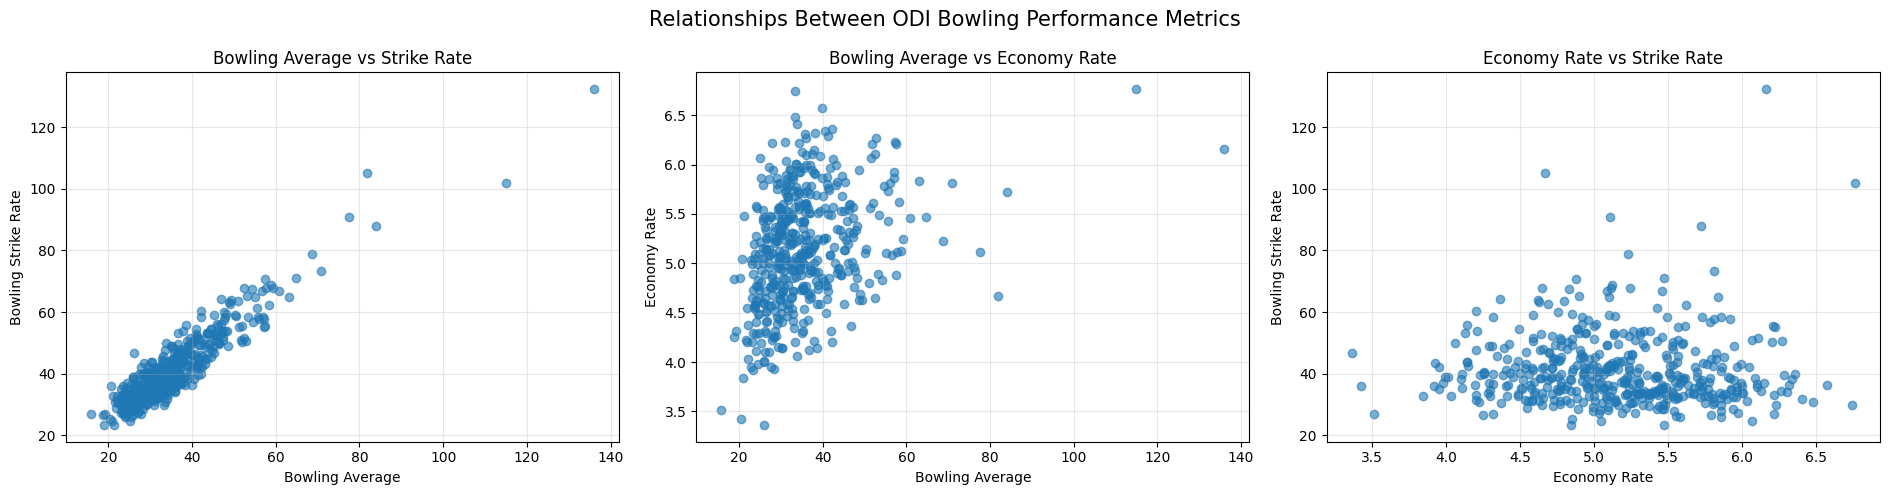

In [ ]:

import matplotlib.pyplot as plt

plot_pairs = [
    ("bowling_average", "bowling_strike_rate"),
    ("bowling_average", "economy_rate"),
    ("economy_rate", "bowling_strike_rate")
]

plot_titles = [
    "Bowling Average vs Strike Rate",
    "Bowling Average vs Economy Rate",
    "Economy Rate vs Strike Rate"
]

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, (x_col, y_col), title in zip(axes, plot_pairs, plot_titles):

    ax.scatter(
        correlation_data[x_col],
        correlation_data[y_col],
        alpha=0.6
    )

    ax.set_title(title)
    ax.set_xlabel(x_col.replace("_", " ").title())
    ax.set_ylabel(y_col.replace("_", " ").title())
    ax.grid(True, alpha=0.3)

plt.suptitle("Relationships Between ODI Bowling Performance Metrics", fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:

# Aggregate bowling figures for each match and innings
innings_bowling = (
    bowling_eda
    .groupby(["match_key", "bowling_innings_number"], as_index=False)
    .agg(
        total_runs_conceded=("runs_conceded", "sum"),
        total_wickets=("wickets", "sum"),
        total_legal_balls=("legal_balls", "sum"),
        number_of_bowlers=("cricketiq_player_id", "nunique")
    )
)

# Calculate match-innings bowling metrics
innings_bowling["economy_rate"] = (
    innings_bowling["total_runs_conceded"] * 6
    / innings_bowling["total_legal_balls"].replace(0, float("nan"))
)

innings_bowling["bowling_average"] = (
    innings_bowling["total_runs_conceded"]
    / innings_bowling["total_wickets"].replace(0, float("nan"))
)

innings_bowling["bowling_strike_rate"] = (
    innings_bowling["total_legal_balls"]
    / innings_bowling["total_wickets"].replace(0, float("nan"))
)

# Compare first and second innings
innings_comparison = (
    innings_bowling
    .groupby("bowling_innings_number")
    .agg(
        match_innings=("match_key", "count"),
        avg_runs_conceded=("total_runs_conceded", "mean"),
        avg_wickets=("total_wickets", "mean"),
        avg_economy=("economy_rate", "mean"),
        avg_bowling_average=("bowling_average", "mean"),
        avg_strike_rate=("bowling_strike_rate", "mean")
    )
    .round(2)
)

innings_comparison.index = [
    "First innings" if i == 1 else "Second innings"
    for i in innings_comparison.index
]

print("BOWLING PERFORMANCE: FIRST VS SECOND INNINGS")
print("=" * 65)
print(innings_comparison)


BOWLING PERFORMANCE: FIRST VS SECOND INNINGS
                match_innings  avg_runs_conceded  avg_wickets  avg_economy  \
First innings            2748             240.06         7.34         5.09   
Second innings           2677             203.76         6.32         5.09   

                avg_bowling_average  avg_strike_rate  
First innings                 38.19            42.87  
Second innings                44.12            50.07  


In [ ]:

# Aggregate bowling figures by source, match and innings
source_innings = (
    bowling_eda
    .groupby(["source", "match_key", "bowling_innings_number"], as_index=False)
    .agg(
        total_runs=("runs_conceded", "sum"),
        total_wickets=("wickets", "sum"),
        total_balls=("legal_balls", "sum")
    )
)

# Calculate innings-level metrics
source_innings["economy_rate"] = (
    source_innings["total_runs"] * 6
    / source_innings["total_balls"].replace(0, float("nan"))
)

source_innings["bowling_average"] = (
    source_innings["total_runs"]
    / source_innings["total_wickets"].replace(0, float("nan"))
)

source_innings["strike_rate"] = (
    source_innings["total_balls"]
    / source_innings["total_wickets"].replace(0, float("nan"))
)

# Compare first and second innings separately for each source
source_comparison = (
    source_innings
    .groupby(["source", "bowling_innings_number"])
    .agg(
        match_innings=("match_key", "count"),
        avg_runs=("total_runs", "mean"),
        avg_wickets=("total_wickets", "mean"),
        avg_economy=("economy_rate", "mean"),
        avg_bowling_average=("bowling_average", "mean"),
        avg_strike_rate=("strike_rate", "mean")
    )
    .round(2)
)

print("FIRST VS SECOND INNINGS — SOURCE-WISE COMPARISON")
print("=" * 75)
print(source_comparison)


FIRST VS SECOND INNINGS — SOURCE-WISE COMPARISON
                                  match_innings  avg_runs  avg_wickets  \
source    bowling_innings_number                                         
Crickrida 1.0                               148    232.29         7.83   
          2.0                               146    188.13         6.64   
Cricsheet 1.0                              2600    240.50         7.31   
          2.0                              2531    204.66         6.30   

                                  avg_economy  avg_bowling_average  \
source    bowling_innings_number                                     
Crickrida 1.0                            4.90                33.42   
          2.0                            4.73                39.87   
Cricsheet 1.0                            5.10                38.46   
          2.0                            5.12                44.37   

                                  avg_strike_rate  
source    bowling_innings_number 

In [ ]:

print("BOWLING DATASET")
print(bowling_eda.columns.tolist())

print("\nMATCH FEATURE DATASET")
print(match_features.columns.tolist())


BOWLING DATASET
['match_key', 'cricketiq_player_id', 'batting_innings_number', 'runs', 'balls_faced', 'fours', 'sixes', 'is_out', 'synthetic_batting_record', 'dismissal_description', 'bowling_innings_number', 'runs_conceded', 'wickets', 'legal_balls', 'wides', 'no_balls', 'maidens', 'source', 'match_date', 'canonical_player_name', 'team', 'opponent', 'is_super_over', 'has_batting_record', 'has_bowling_record', 'has_batting_involvement', 'pre_match_career_matches_played', 'pre_match_career_batting_innings', 'pre_match_career_batting_runs', 'pre_match_career_batting_balls', 'pre_match_career_batting_fours', 'pre_match_career_batting_sixes', 'pre_match_career_batting_dismissals', 'pre_match_career_bowling_innings', 'pre_match_career_bowling_runs_conceded', 'pre_match_career_bowling_wickets', 'pre_match_career_bowling_legal_balls', 'pre_match_career_batting_average', 'pre_match_career_batting_strike_rate', 'pre_match_career_boundary_runs', 'pre_match_career_boundary_percentage', 'pre_match

In [ ]:

print("BOWLING MATCH IDENTIFIERS")
print("=" * 60)

print("Bowling match_key examples:")
print(bowling_eda["match_key"].drop_duplicates().head(10).tolist())

print("\nMatch feature match_id examples:")
print(match_features["match_id"].drop_duplicates().head(10).tolist())

print("\nBowling match_key data type:")
print(bowling_eda["match_key"].dtype)

print("\nMatch feature match_id data type:")
print(match_features["match_id"].dtype)

# Check direct identifier overlap
bowling_keys = set(bowling_eda["match_key"].dropna().astype(str))
feature_ids = set(match_features["match_id"].dropna().astype(str))

print("\nIDENTIFIER OVERLAP")
print("-" * 60)
print("Unique bowling match keys:", len(bowling_keys))
print("Unique match feature IDs:", len(feature_ids))
print("Direct matching IDs:", len(bowling_keys.intersection(feature_ids)))

print("\nBOWLING TEAM EXAMPLES")
print(
    bowling_eda[["match_key", "source", "team", "opponent"]]
    .drop_duplicates()
    .head(10).to_string(index=False)
)


BOWLING MATCH IDENTIFIERS
Bowling match_key examples:
['CS_MATCH_66283', 'CS_MATCH_66284', 'CS_MATCH_64814', 'CS_MATCH_64815', 'CS_MATCH_64816', 'CS_MATCH_64817', 'CS_MATCH_65634', 'CS_MATCH_65635', 'CS_MATCH_65636', 'CS_MATCH_64819']

Match feature match_id examples:
[66283.0, 66284.0, 64814.0, 64815.0, 64816.0, 64817.0, 65634.0, 65635.0, 65636.0, 64819.0]

Bowling match_key data type:
object

Match feature match_id data type:
float64

IDENTIFIER OVERLAP
------------------------------------------------------------
Unique bowling match keys: 2748
Unique match feature IDs: 2600
Direct matching IDs: 0

BOWLING TEAM EXAMPLES
     match_key    source        team    opponent
CS_MATCH_66283 Cricsheet     England   Sri Lanka
CS_MATCH_66283 Cricsheet   Sri Lanka     England
CS_MATCH_66284 Cricsheet       India     England
CS_MATCH_66284 Cricsheet     England       India
CS_MATCH_64814 Cricsheet New Zealand       India
CS_MATCH_64814 Cricsheet       India New Zealand
CS_MATCH_64815 Cricsheet   

In [ ]:

print("MATCH DATA SOURCE DISTRIBUTION")
print("=" * 60)
print(match_features["source"].value_counts(dropna=False))

print("\nCRICSHEET MATCH FEATURE EXAMPLES")
print("-" * 60)
print(
    match_features[match_features["source"] == "Cricsheet"][
        ["match_id", "integration_key", "team_1", "team_2", "winner"]
    ].head(5).to_string(index=False)
)

print("\nCRICKRIDA MATCH FEATURE EXAMPLES")
print("-" * 60)
print(
    match_features[match_features["source"] == "Crickrida"][
        ["match_id", "integration_key", "team_1", "team_2", "winner"]
    ].head(10).to_string(index=False)
)

print("\nCRICKRIDA BOWLING MATCH KEY EXAMPLES")
print("-" * 60)
print(
    bowling_eda[bowling_eda["source"] == "Crickrida"][
        ["match_key", "match_date", "team", "opponent"]
    ].drop_duplicates().head(10).to_string(index=False)
)


MATCH DATA SOURCE DISTRIBUTION
source
Cricsheet    2600
Crickrida     153
Name: count, dtype: int64

CRICSHEET MATCH FEATURE EXAMPLES
------------------------------------------------------------
 match_id                        integration_key      team_1      team_2      winner
  66283.0 2002-06-27|cricsheet|england|sri lanka     England   Sri Lanka     England
  66284.0     2002-06-29|cricsheet|england|india     England       India       India
  64814.0 2002-12-29|cricsheet|india|new zealand New Zealand       India New Zealand
  64815.0 2003-01-01|cricsheet|india|new zealand       India New Zealand New Zealand
  64816.0 2003-01-04|cricsheet|india|new zealand       India New Zealand New Zealand

CRICKRIDA MATCH FEATURE EXAMPLES
------------------------------------------------------------
 match_id                             integration_key      team_1     team_2      winner
      NaN    2010-07-03|crickrida|afghanistan|ireland Afghanistan    Ireland     Ireland
      NaN   2012-02-10

In [ ]:

# Work on a separate copy
bowling_match_keys = bowling_eda[
    ["match_key", "match_date", "source", "team", "opponent"]
].drop_duplicates().copy()

# Standardize date and team names
bowling_match_keys["match_date"] = pd.to_datetime(
    bowling_match_keys["match_date"]
).dt.strftime("%Y-%m-%d")

bowling_match_keys["team_a"] = bowling_match_keys[
    ["team", "opponent"]
].min(axis=1).str.lower().str.strip()

bowling_match_keys["team_b"] = bowling_match_keys[
    ["team", "opponent"]
].max(axis=1).str.lower().str.strip()

# Generate integration key
bowling_match_keys["integration_key"] = (
    bowling_match_keys["match_date"]
    + "|"
    + bowling_match_keys["source"].str.lower()
    + "|"
    + bowling_match_keys["team_a"]
    + "|"
    + bowling_match_keys["team_b"]
)

# Check against match feature keys
feature_keys = set(match_features["integration_key"].dropna())

bowling_match_keys["key_found"] = (
    bowling_match_keys["integration_key"].isin(feature_keys)
)

print("INTEGRATION KEY VALIDATION")
print("=" * 65)

print("Unique bowling match keys:", bowling_match_keys["match_key"].nunique())
print("Generated integration keys:", bowling_match_keys["integration_key"].nunique())
print("Matched integration keys:", bowling_match_keys["key_found"].sum())
print("Unmatched integration keys:", (~bowling_match_keys["key_found"]).sum())

print("\nSOURCE-WISE VALIDATION")
print(
    bowling_match_keys.groupby("source")["key_found"]
    .agg(["count", "sum"])
)

print("\nUNMATCHED EXAMPLES")
print(
    bowling_match_keys.loc[
        ~bowling_match_keys["key_found"],
        ["match_key", "integration_key"]
    ].head(10).to_string(index=False)
)


INTEGRATION KEY VALIDATION
Unique bowling match keys: 2748
Generated integration keys: 2748
Matched integration keys: 5425
Unmatched integration keys: 0

SOURCE-WISE VALIDATION
           count   sum
source                
Crickrida    294   294
Cricsheet   5131  5131

UNMATCHED EXAMPLES
Empty DataFrame
Columns: [match_key, integration_key]
Index: []


In [ ]:

# Select the required match-result columns
match_results = match_features[
    [
        "integration_key",
        "winner",
        "result_type",
        "team_1",
        "team_2"
    ]
].copy()

# Merge match results with bowling match keys
bowling_results = bowling_match_keys.merge(
    match_results,
    on="integration_key",
    how="left",
    validate="many_to_one"
)

# Check match-result availability
print("BOWLING MATCH RESULT MERGE")
print("=" * 65)

print("Total bowling match-innings records:", len(bowling_results))
print("Missing winners:", bowling_results["winner"].isna().sum())

# Assign outcome from the bowling team's perspective
bowling_results["bowling_team_result"] = "No Result / Tie"

bowling_results.loc[
    bowling_results["winner"] == bowling_results["team"],
    "bowling_team_result"
] = "Win"

bowling_results.loc[
    bowling_results["winner"] == bowling_results["opponent"],
    "bowling_team_result"
] = "Loss"

print("\nBOWLING TEAM OUTCOME DISTRIBUTION")
print(
    bowling_results["bowling_team_result"]
    .value_counts(dropna=False)
)

print("\nSOURCE-WISE OUTCOME DISTRIBUTION")
print(
    pd.crosstab(
        bowling_results["source"],
        bowling_results["bowling_team_result"]
    )
)

print("\nSAMPLE MATCH RESULTS")
print(
    bowling_results[
        [
            "match_key",
            "team",
            "opponent",
            "winner",
            "bowling_team_result"
        ]
    ].head(10).to_string(index=False)
)


BOWLING MATCH RESULT MERGE
Total bowling match-innings records: 5425
Missing winners: 197

BOWLING TEAM OUTCOME DISTRIBUTION
bowling_team_result
Win                2614
Loss               2614
No Result / Tie     197
Name: count, dtype: int64

SOURCE-WISE OUTCOME DISTRIBUTION
bowling_team_result  Loss  No Result / Tie   Win
source                                          
Crickrida             143                8   143
Cricsheet            2471              189  2471

SAMPLE MATCH RESULTS
     match_key        team    opponent      winner bowling_team_result
CS_MATCH_66283     England   Sri Lanka     England                 Win
CS_MATCH_66283   Sri Lanka     England     England                Loss
CS_MATCH_66284       India     England       India                 Win
CS_MATCH_66284     England       India       India                Loss
CS_MATCH_64814 New Zealand       India New Zealand                 Win
CS_MATCH_64814       India New Zealand New Zealand                Loss
CS_MATCH

In [ ]:

# Count team records per match
records_per_match = bowling_results.groupby("match_key").agg(
    team_records=("team", "nunique"),
    outcome_records=("bowling_team_result", "count"),
    unique_outcomes=("bowling_team_result", "nunique"),
    source=("source", "first")
)

print("MATCH OUTCOME VALIDATION")
print("=" * 65)

print("Total unique matches:", len(records_per_match))

print("\nNumber of team records per match:")
print(records_per_match["team_records"].value_counts().sort_index())

print("\nOutcome consistency:")
print(records_per_match["unique_outcomes"].value_counts().sort_index())

# Identify matches that do not have exactly two teams
invalid_team_counts = records_per_match[
    records_per_match["team_records"] != 2
]

# Identify matches where both team records do not have the same outcome category
invalid_outcomes = records_per_match[
    records_per_match["unique_outcomes"] != 1
]

print("\nMatches without exactly two teams:", len(invalid_team_counts))
print("Matches with inconsistent outcome labels:", len(invalid_outcomes))

print("\nSource-wise match counts:")
print(records_per_match.groupby("source").size())


MATCH OUTCOME VALIDATION
Total unique matches: 2748

Number of team records per match:
team_records
1      71
2    2677
Name: count, dtype: int64

Outcome consistency:
unique_outcomes
1     134
2    2614
Name: count, dtype: int64

Matches without exactly two teams: 71
Matches with inconsistent outcome labels: 2614

Source-wise match counts:
source
Crickrida     148
Cricsheet    2600
dtype: int64


In [ ]:

# Count each outcome per match
outcome_validation = (
    bowling_results
    .pivot_table(
        index=["match_key", "source"],
        columns="bowling_team_result",
        values="team",
        aggfunc="nunique",
        fill_value=0
    )
    .reset_index()
)

# Ensure expected columns exist
for col in ["Win", "Loss", "No Result / Tie"]:
    if col not in outcome_validation.columns:
        outcome_validation[col] = 0

# Count team records
team_counts = (
    bowling_results.groupby("match_key")["team"]
    .nunique()
    .rename("team_count")
)

outcome_validation = outcome_validation.merge(
    team_counts,
    on="match_key"
)

# Classify match validation
outcome_validation["validation_status"] = "Unexpected"

outcome_validation.loc[
    (outcome_validation["team_count"] == 2) &
    (outcome_validation["Win"] == 1) &
    (outcome_validation["Loss"] == 1),
    "validation_status"
] = "Valid Decisive Match"

outcome_validation.loc[
    (outcome_validation["team_count"] == 2) &
    (outcome_validation["Win"] == 0) &
    (outcome_validation["Loss"] == 0) &
    (outcome_validation["No Result / Tie"] == 2),
    "validation_status"
] = "Valid Tie / No Result"

outcome_validation.loc[
    outcome_validation["team_count"] == 1,
    "validation_status"
] = "Single Team Record - Investigate"

print("CORRECTED MATCH OUTCOME VALIDATION")
print("=" * 65)

print(outcome_validation["validation_status"].value_counts())

print("\nSOURCE-WISE VALIDATION")
print(
    outcome_validation.groupby(
        ["source", "validation_status"]
    ).size()
)

print("\nSINGLE-TEAM MATCH EXAMPLES")
single_team_matches = outcome_validation[
    outcome_validation["team_count"] == 1
]["match_key"]

print(
    bowling_results[
        bowling_results["match_key"].isin(single_team_matches)
    ][
        ["match_key", "source", "team", "opponent",
         "winner", "result_type", "bowling_team_result"]
    ].drop_duplicates().head(20).to_string(index=False)
)


CORRECTED MATCH OUTCOME VALIDATION
validation_status
Valid Decisive Match                2614
Single Team Record - Investigate      71
Valid Tie / No Result                 63
Name: count, dtype: int64

SOURCE-WISE VALIDATION
source     validation_status               
Crickrida  Single Team Record - Investigate       2
           Valid Decisive Match                 143
           Valid Tie / No Result                  3
Cricsheet  Single Team Record - Investigate      69
           Valid Decisive Match                2471
           Valid Tie / No Result                 60
dtype: int64

SINGLE-TEAM MATCH EXAMPLES
      match_key    source         team     opponent winner result_type bowling_team_result
 CS_MATCH_65273 Cricsheet     Zimbabwe     Pakistan    NaN   No result     No Result / Tie
 CS_MATCH_66356 Cricsheet South Africa        India    NaN   No result     No Result / Tie
 CS_MATCH_66296 Cricsheet     Zimbabwe      England    NaN   No result     No Result / Tie
 CS_MATCH_663

In [ ]:

# Get match keys belonging to validated decisive matches
decisive_match_keys = outcome_validation.loc[
    outcome_validation["validation_status"] == "Valid Decisive Match",
    "match_key"
]

# Keep only bowling records from decisive matches
decisive_bowling = bowling_eda[
    bowling_eda["match_key"].isin(decisive_match_keys)
].copy()

# Attach the validated match outcome
decisive_bowling = decisive_bowling.merge(
    bowling_results[
        ["match_key", "team", "bowling_team_result"]
    ],
    on=["match_key", "team"],
    how="left",
    validate="many_to_one"
)

print("DECISIVE MATCH BOWLING DATASET")
print("=" * 65)

print("Total bowling records:", len(decisive_bowling))
print("Unique matches:", decisive_bowling["match_key"].nunique())
print("Unique players:", decisive_bowling["cricketiq_player_id"].nunique())

print("\nOutcome distribution:")
print(decisive_bowling["bowling_team_result"].value_counts())

print("\nMissing outcome records:", decisive_bowling["bowling_team_result"].isna().sum())


DECISIVE MATCH BOWLING DATASET
Total bowling records: 31931
Unique matches: 2614
Unique players: 1550

Outcome distribution:
bowling_team_result
Loss    16145
Win     15786
Name: count, dtype: int64

Missing outcome records: 0


In [ ]:

# Aggregate all bowlers into one team bowling innings per match
team_match_bowling = (
    decisive_bowling
    .groupby(
        ["match_key", "source", "team", "opponent", "bowling_team_result"],
        as_index=False
    )
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        wickets=("wickets", "sum"),
        legal_balls=("legal_balls", "sum"),
        bowler_count=("cricketiq_player_id", "nunique")
    )
)

# Calculate team-level bowling metrics
team_match_bowling["economy_rate"] = (
    team_match_bowling["runs_conceded"] * 6
    / team_match_bowling["legal_balls"].replace(0, float("nan"))
)

team_match_bowling["bowling_average"] = (
    team_match_bowling["runs_conceded"]
    / team_match_bowling["wickets"].replace(0, float("nan"))
)

team_match_bowling["strike_rate"] = (
    team_match_bowling["legal_balls"]
    / team_match_bowling["wickets"].replace(0, float("nan"))
)

# Compare team bowling performances in wins and losses
outcome_comparison = (
    team_match_bowling
    .groupby("bowling_team_result")
    .agg(
        team_innings=("match_key", "count"),
        avg_runs_conceded=("runs_conceded", "mean"),
        avg_wickets=("wickets", "mean"),
        avg_legal_balls=("legal_balls", "mean"),
        avg_economy=("economy_rate", "mean"),
        avg_bowling_average=("bowling_average", "mean"),
        avg_strike_rate=("strike_rate", "mean")
    )
    .round(2)
)

print("TEAM BOWLING PERFORMANCE: WINS VS LOSSES")
print("=" * 70)

print("Total team bowling innings:", len(team_match_bowling))
print("Unique matches:", team_match_bowling["match_key"].nunique())

print("\nOutcome comparison:")
print(outcome_comparison)

print("\nSource-wise team innings:")
print(
    team_match_bowling.groupby(
        ["source", "bowling_team_result"]
    ).size()
)


TEAM BOWLING PERFORMANCE: WINS VS LOSSES
Total team bowling innings: 5228
Unique matches: 2614

Outcome comparison:
                     team_innings  avg_runs_conceded  avg_wickets  \
bowling_team_result                                                 
Loss                         2614             243.29         5.30   
Win                          2614             205.47         8.51   

                     avg_legal_balls  avg_economy  avg_bowling_average  \
bowling_team_result                                                      
Loss                          263.65         5.58                56.70   
Win                           264.68         4.61                26.23   

                     avg_strike_rate  
bowling_team_result                   
Loss                           60.25  
Win                            33.14  

Source-wise team innings:
source     bowling_team_result
Crickrida  Loss                    143
           Win                     143
Cricsheet  Loss   

In [ ]:

# Select toss-related match information
toss_data = match_features[
    [
        "integration_key",
        "team_1",
        "team_2",
        "toss_winner",
        "toss_decision",
        "winner",
        "result_type"
    ]
].copy()

# Attach toss information to team bowling records
toss_bowling = team_match_bowling.merge(
    bowling_match_keys[
        ["match_key", "integration_key"]
    ].drop_duplicates(),
    on="match_key",
    how="left",
    validate="many_to_one"
).merge(
    toss_data,
    on="integration_key",
    how="left",
    validate="many_to_one"
)

# Determine whether the bowling team won the toss
toss_bowling["won_toss"] = (
    toss_bowling["team"] == toss_bowling["toss_winner"]
)

# Determine whether the bowling team chose to field
toss_bowling["toss_choice"] = "Did not win toss"

toss_bowling.loc[
    toss_bowling["won_toss"] & 
    toss_bowling["toss_decision"].str.lower().eq("field"),
    "toss_choice"
] = "Won toss and chose field"

toss_bowling.loc[
    toss_bowling["won_toss"] & 
    toss_bowling["toss_decision"].str.lower().eq("bat"),
    "toss_choice"
] = "Won toss and chose bat"

print("TOSS AND BOWLING DATA VALIDATION")
print("=" * 65)

print("Total team bowling innings:", len(toss_bowling))
print("Missing integration keys:", toss_bowling["integration_key"].isna().sum())
print("Missing toss winners:", toss_bowling["toss_winner"].isna().sum())
print("Missing toss decisions:", toss_bowling["toss_decision"].isna().sum())

print("\nToss decisions:")
print(toss_data["toss_decision"].value_counts(dropna=False))

print("\nBowling team toss choices:")
print(toss_bowling["toss_choice"].value_counts(dropna=False))

print("\nSample records:")
print(
    toss_bowling[
        ["match_key", "team", "toss_winner", "toss_decision", "toss_choice"]
    ].head(12).to_string(index=False)
)


TOSS AND BOWLING DATA VALIDATION
Total team bowling innings: 5228
Missing integration keys: 0
Missing toss winners: 0
Missing toss decisions: 0

Toss decisions:
toss_decision
field    1393
bat      1356
NaN         4
Name: count, dtype: int64

Bowling team toss choices:
toss_choice
Did not win toss            2614
Won toss and chose field    1319
Won toss and chose bat      1295
Name: count, dtype: int64

Sample records:
                               match_key        team toss_winner toss_decision              toss_choice
   CR_MATCH_20100703_Afghanistan_Ireland Afghanistan     Ireland           bat         Did not win toss
   CR_MATCH_20100703_Afghanistan_Ireland     Ireland     Ireland           bat   Won toss and chose bat
  CR_MATCH_20120210_Afghanistan_Pakistan Afghanistan Afghanistan           bat   Won toss and chose bat
  CR_MATCH_20120210_Afghanistan_Pakistan    Pakistan Afghanistan           bat         Did not win toss
   CR_MATCH_20120705_Afghanistan_Ireland Afghanistan Af

In [ ]:

# Get the actual bowling innings number
team_innings_info = (
    bowling_eda[
        ["match_key", "team", "bowling_innings_number"]
    ]
    .drop_duplicates()
)

# Attach innings number to team-level bowling records
toss_analysis = team_match_bowling.merge(
    team_innings_info,
    on=["match_key", "team"],
    how="left",
    validate="one_to_one"
)

# Attach integration keys
toss_analysis = toss_analysis.merge(
    bowling_match_keys[
        ["match_key", "integration_key"]
    ].drop_duplicates(),
    on="match_key",
    how="left",
    validate="many_to_one"
)

# Attach toss decisions using integration keys
toss_analysis = toss_analysis.merge(
    toss_data[
        ["integration_key", "toss_decision"]
    ].drop_duplicates(),
    on="integration_key",
    how="left",
    validate="many_to_one"
)

# Validate merge
print("TOSS DATA MERGE VALIDATION")
print("=" * 65)
print("Total records:", len(toss_analysis))
print("Missing innings numbers:",
      toss_analysis["bowling_innings_number"].isna().sum())
print("Missing integration keys:",
      toss_analysis["integration_key"].isna().sum())
print("Missing toss decisions:",
      toss_analysis["toss_decision"].isna().sum())

# Exclude records with missing toss decisions
toss_analysis = toss_analysis.dropna(
    subset=["toss_decision"]
).copy()

# Compare first and second innings
toss_performance = (
    toss_analysis
    .groupby(["toss_decision", "bowling_innings_number"])
    .agg(
        team_innings=("match_key", "count"),
        avg_runs_conceded=("runs_conceded", "mean"),
        avg_wickets=("wickets", "mean"),
        avg_economy=("economy_rate", "mean"),
        avg_bowling_average=("bowling_average", "mean"),
        avg_strike_rate=("strike_rate", "mean")
    )
    .round(2)
)

print("\nBOWLING PERFORMANCE BY TOSS DECISION AND INNINGS")
print("=" * 75)
print(toss_performance)



TOSS DATA MERGE VALIDATION
Total records: 5228
Missing innings numbers: 0
Missing integration keys: 0
Missing toss decisions: 0

BOWLING PERFORMANCE BY TOSS DECISION AND INNINGS
                                      team_innings  avg_runs_conceded  \
toss_decision bowling_innings_number                                    
bat           1.0                             1295             243.84   
              2.0                             1295             206.09   
field         1.0                             1319             242.94   
              2.0                             1319             204.66   

                                      avg_wickets  avg_economy  \
toss_decision bowling_innings_number                             
bat           1.0                            7.39         5.05   
              2.0                            6.33         5.04   
field         1.0                            7.49         5.15   
              2.0                            6.42    

In [ ]:

# Attach toss winner to the existing analysis dataset
toss_analysis = toss_analysis.drop(
    columns=["toss_winner"],
    errors="ignore"
)

toss_analysis = toss_analysis.merge(
    toss_data[["integration_key", "toss_winner"]].drop_duplicates(),
    on="integration_key",
    how="left",
    validate="many_to_one"
)

# Identify whether each bowling team won the toss
toss_analysis["toss_team_role"] = "Opponent of toss winner"

toss_analysis.loc[
    toss_analysis["team"] == toss_analysis["toss_winner"],
    "toss_team_role"
] = "Toss winner"

print("TOSS TEAM ROLE VALIDATION")
print("=" * 65)

print("Missing toss winners:", toss_analysis["toss_winner"].isna().sum())

print("\nTeam role distribution:")
print(toss_analysis["toss_team_role"].value_counts())

print("\nToss role by bowling innings:")
print(
    pd.crosstab(
        toss_analysis["toss_team_role"],
        toss_analysis["bowling_innings_number"]
    )
)

print("\nSample records:")
print(
    toss_analysis[
        [
            "match_key",
            "team",
            "toss_winner",
            "toss_decision",
            "bowling_innings_number",
            "toss_team_role"
        ]
    ].head(12).to_string(index=False)
)


TOSS TEAM ROLE VALIDATION
Missing toss winners: 0

Team role distribution:
toss_team_role
Opponent of toss winner    2614
Toss winner                2614
Name: count, dtype: int64

Toss role by bowling innings:
bowling_innings_number    1.0   2.0
toss_team_role                     
Opponent of toss winner  1296  1318
Toss winner              1318  1296

Sample records:
                               match_key        team toss_winner toss_decision  bowling_innings_number          toss_team_role
   CR_MATCH_20100703_Afghanistan_Ireland Afghanistan     Ireland           bat                     1.0 Opponent of toss winner
   CR_MATCH_20100703_Afghanistan_Ireland     Ireland     Ireland           bat                     2.0             Toss winner
  CR_MATCH_20120210_Afghanistan_Pakistan Afghanistan Afghanistan           bat                     2.0             Toss winner
  CR_MATCH_20120210_Afghanistan_Pakistan    Pakistan Afghanistan           bat                     1.0 Opponent of toss 

In [ ]:

# Calculate bowling performance metrics
toss_analysis["calculated_economy"] = (
    toss_analysis["runs_conceded"] * 6 /
    toss_analysis["legal_balls"].replace(0, np.nan)
)

toss_analysis["bowling_average"] = (
    toss_analysis["runs_conceded"] /
    toss_analysis["wickets"].replace(0, np.nan)
)

toss_analysis["bowling_strike_rate"] = (
    toss_analysis["legal_balls"] /
    toss_analysis["wickets"].replace(0, np.nan)
)

# Overall performance by toss-team role
toss_role_performance = (
    toss_analysis
    .groupby("toss_team_role")
    .agg(
        team_innings=("match_key", "count"),
        avg_runs_conceded=("runs_conceded", "mean"),
        avg_wickets=("wickets", "mean"),
        avg_legal_balls=("legal_balls", "mean"),
        avg_economy=("calculated_economy", "mean"),
        avg_bowling_average=("bowling_average", "mean"),
        avg_strike_rate=("bowling_strike_rate", "mean")
    )
    .round(2)
)

print("BOWLING PERFORMANCE: TOSS WINNER VS OPPONENT")
print("=" * 85)
print(toss_role_performance)

# Performance separated by bowling innings
role_innings_performance = (
    toss_analysis
    .groupby(["toss_team_role", "bowling_innings_number"])
    .agg(
        team_innings=("match_key", "count"),
        avg_runs_conceded=("runs_conceded", "mean"),
        avg_wickets=("wickets", "mean"),
        avg_economy=("calculated_economy", "mean"),
        avg_bowling_average=("bowling_average", "mean"),
        avg_strike_rate=("bowling_strike_rate", "mean")
    )
    .round(2)
)

print("\nPERFORMANCE BY ROLE AND INNINGS")
print("=" * 85)
print(role_innings_performance)


BOWLING PERFORMANCE: TOSS WINNER VS OPPONENT
                         team_innings  avg_runs_conceded  avg_wickets  \
toss_team_role                                                          
Opponent of toss winner          2614             224.07         6.90   
Toss winner                      2614             224.69         6.91   

                         avg_legal_balls  avg_economy  avg_bowling_average  \
toss_team_role                                                               
Opponent of toss winner           264.35          5.1                41.25   
Toss winner                       263.99          5.1                41.38   

                         avg_strike_rate  
toss_team_role                            
Opponent of toss winner            46.48  
Toss winner                        46.64  

PERFORMANCE BY ROLE AND INNINGS
                                                team_innings  \
toss_team_role          bowling_innings_number                 
Opponent of toss

In [ ]:

# Create paired bowling performance records for each match
paired_bowling = toss_analysis.pivot(
    index="match_key",
    columns="toss_team_role",
    values=[
        "runs_conceded",
        "wickets",
        "calculated_economy",
        "bowling_average",
        "bowling_strike_rate"
    ]
)

print("PAIRED DATA VALIDATION")
print("=" * 65)
print("Number of matches:", len(paired_bowling))
print("Missing values by metric:")
print(paired_bowling.isna().sum())

print("\nPaired dataset shape:", paired_bowling.shape)
print("\nSample:")
print(paired_bowling.head())


PAIRED DATA VALIDATION
Number of matches: 2614
Missing values by metric:
                     toss_team_role         
runs_conceded        Opponent of toss winner     0
                     Toss winner                 0
wickets              Opponent of toss winner     0
                     Toss winner                 0
calculated_economy   Opponent of toss winner     0
                     Toss winner                 0
bowling_average      Opponent of toss winner    24
                     Toss winner                28
bowling_strike_rate  Opponent of toss winner    24
                     Toss winner                28
dtype: int64

Paired dataset shape: (2614, 10)

Sample:
                                                  runs_conceded              \
toss_team_role                          Opponent of toss winner Toss winner   
match_key                                                                     
CR_MATCH_20100703_Afghanistan_Ireland                     235.0       193.0   


In [ ]:

from scipy import stats

metrics = [
    "runs_conceded",
    "wickets",
    "calculated_economy",
    "bowling_average",
    "bowling_strike_rate"
]

results = []

for metric in metrics:

    opponent = paired_bowling[
        (metric, "Opponent of toss winner")
    ]

    toss_winner = paired_bowling[
        (metric, "Toss winner")
    ]

    # Keep only complete pairs
    valid = pd.DataFrame({
        "opponent": opponent,
        "toss_winner": toss_winner
    }).dropna()

    # Difference: toss winner minus opponent
    differences = valid["toss_winner"] - valid["opponent"]

    # Paired t-test
    t_stat, t_pvalue = stats.ttest_rel(
        valid["toss_winner"],
        valid["opponent"]
    )

    # Wilcoxon signed-rank test
    try:
        w_stat, w_pvalue = stats.wilcoxon(
            valid["toss_winner"],
            valid["opponent"]
        )
    except ValueError:
        w_stat, w_pvalue = np.nan, np.nan

    results.append({
        "metric": metric,
        "sample_size": len(valid),
        "mean_opponent": valid["opponent"].mean(),
        "mean_toss_winner": valid["toss_winner"].mean(),
        "mean_difference": differences.mean(),
        "t_statistic": t_stat,
        "paired_t_pvalue": t_pvalue,
        "wilcoxon_pvalue": w_pvalue
    })

statistical_results = pd.DataFrame(results).round(5)

print("PAIRED STATISTICAL TEST RESULTS")
print("=" * 110)
print(statistical_results.to_string(index=False))

print("\nSIGNIFICANCE INTERPRETATION (5% LEVEL)")
print("=" * 65)

for _, row in statistical_results.iterrows():

    print(f"\n{row['metric']}")

    if row["wilcoxon_pvalue"] < 0.05:
        print("Wilcoxon: Statistically significant difference")
    else:
        print("Wilcoxon: No statistically significant difference")


PAIRED STATISTICAL TEST RESULTS
             metric  sample_size  mean_opponent  mean_toss_winner  mean_difference  t_statistic  paired_t_pvalue  wilcoxon_pvalue
      runs_conceded         2614      224.07116         224.68745          0.61630      0.45183          0.65143          0.98989
            wickets         2614        6.89594           6.91354          0.01760      0.21229          0.83190          0.88470
 calculated_economy         2614        5.09805           5.09555         -0.00250     -0.08840          0.92957          0.81451
    bowling_average         2562       41.46660          41.61420          0.14760      0.15466          0.87710          0.84444
bowling_strike_rate         2562       46.63527          46.84335          0.20808      0.23507          0.81417          0.75795

SIGNIFICANCE INTERPRETATION (5% LEVEL)

runs_conceded
Wilcoxon: No statistically significant difference

wickets
Wilcoxon: No statistically significant difference

calculated_economy
Wilc

In [ ]:

from scipy.stats import chi2_contingency, fisher_exact

# Create one record per match
toss_outcome = (
    toss_data
    .drop_duplicates(subset="integration_key")
    .copy()
)

# Keep matches with a valid toss decision and a recorded winner
toss_outcome = toss_outcome.dropna(
    subset=["toss_decision", "toss_winner", "winner"]
).copy()

# Keep only bat/field decisions
toss_outcome = toss_outcome[
    toss_outcome["toss_decision"].str.lower().isin(["bat", "field"])
].copy()

# Did the toss winner also win the match?
toss_outcome["toss_winner_won_match"] = (
    toss_outcome["toss_winner"] == toss_outcome["winner"]
)

print("TOSS OUTCOME DATA VALIDATION")
print("=" * 65)
print("Valid decisive matches:", len(toss_outcome))
print("Duplicate integration keys:",
      toss_outcome["integration_key"].duplicated().sum())

# Win/loss counts by toss decision
toss_decision_results = (
    toss_outcome
    .groupby("toss_decision")
    .agg(
        matches=("integration_key", "count"),
        toss_winner_wins=("toss_winner_won_match", "sum")
    )
)

toss_decision_results["toss_winner_losses"] = (
    toss_decision_results["matches"] -
    toss_decision_results["toss_winner_wins"]
)

toss_decision_results["win_percentage"] = (
    toss_decision_results["toss_winner_wins"] /
    toss_decision_results["matches"] * 100
).round(2)

print("\nTOSS DECISION VS MATCH OUTCOME")
print("=" * 65)
print(toss_decision_results)

# Contingency table for statistical testing
contingency_table = pd.crosstab(
    toss_outcome["toss_decision"],
    toss_outcome["toss_winner_won_match"]
).reindex(
    index=["bat", "field"],
    columns=[False, True],
    fill_value=0
)

print("\nCONTINGENCY TABLE")
print("=" * 65)
print(contingency_table)

# Chi-square test
chi2, chi_p, dof, expected = chi2_contingency(
    contingency_table
)

# Fisher's exact test
odds_ratio, fisher_p = fisher_exact(contingency_table)

print("\nSTATISTICAL TESTS")
print("=" * 65)
print("Chi-square statistic:", round(chi2, 4))
print("Chi-square p-value:", round(chi_p, 5))
print("Degrees of freedom:", dof)
print("Fisher odds ratio:", round(odds_ratio, 4))
print("Fisher p-value:", round(fisher_p, 5))


TOSS OUTCOME DATA VALIDATION
Valid decisive matches: 2614
Duplicate integration keys: 0

TOSS DECISION VS MATCH OUTCOME
               matches  toss_winner_wins  toss_winner_losses  win_percentage
toss_decision                                                               
bat               1295               621                 674           47.95
field             1319               683                 636           51.78

CONTINGENCY TABLE
toss_winner_won_match  False  True 
toss_decision                      
bat                      674    621
field                    636    683

STATISTICAL TESTS
Chi-square statistic: 3.6785
Chi-square p-value: 0.05512
Degrees of freedom: 1
Fisher odds ratio: 1.1656
Fisher p-value: 0.05061


In [ ]:
# INVESTIGATE BOWLING DATA ANOMALIES

print("BOWLING DATA ANOMALY INVESTIGATION")
print("=" * 60)

# Records with zero legal balls
zero_ball_records = bowling_records[
    bowling_records["legal_balls"] == 0
]

print("\n1. Zero legal ball records:")
display(
    zero_ball_records[
        [
            "source",
            "canonical_player_name",
            "match_key",
            "bowling_innings_number",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "no_balls"
        ]
    ]
)

# Records exceeding 60 legal balls
excess_ball_records = bowling_records[
    bowling_records["legal_balls"] > 60
]

print("\n2. Records exceeding 60 legal balls:")
display(
    excess_ball_records[
        [
            "source",
            "canonical_player_name",
            "match_key",
            "bowling_innings_number",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "no_balls"
        ]
    ]
)

BOWLING DATA ANOMALY INVESTIGATION

1. Zero legal ball records:


,source,canonical_player_name,match_key,bowling_innings_number,runs_conceded,wickets,legal_balls,no_balls
6957,Cricsheet,CO Obuya,CS_MATCH_249379,2.0,5.0,0.0,0.0,1.0
26013,Cricsheet,Abdur Rehman,CS_MATCH_710305,1.0,8.0,0.0,0.0,3.0
52496,Crickrida,Rahmanullah Gurbaz,CR_MATCH_20240922_Afghanistan_South Africa,2.0,1.0,0.0,0.0,0.0



2. Records exceeding 60 legal balls:


,source,canonical_player_name,match_key,bowling_innings_number,runs_conceded,wickets,legal_balls,no_balls
1977,Cricsheet,Mohammad Rafique,CS_MATCH_64832,1.0,31.0,2.0,61.0,0.0
2146,Cricsheet,Abdul Razzaq,CS_MATCH_64842,2.0,33.0,0.0,61.0,2.0
10343,Cricsheet,Stuart Broad,CS_MATCH_258475,1.0,84.0,1.0,61.0,0.0
11334,Cricsheet,Chris Mpofu,CS_MATCH_325803,2.0,36.0,1.0,61.0,0.0
12152,Cricsheet,Tim Southee,CS_MATCH_296906,2.0,38.0,4.0,61.0,0.0
14585,Cricsheet,Prosper Utseya,CS_MATCH_410340,2.0,46.0,1.0,61.0,0.0
14598,Cricsheet,RW Price,CS_MATCH_410340,2.0,60.0,3.0,61.0,0.0
34290,Cricsheet,Ravichandran Ashwin,CS_MATCH_1022373,1.0,59.0,0.0,61.0,0.0
38257,Cricsheet,Hardik Pandya,CS_MATCH_1153693,1.0,45.0,2.0,61.0,0.0
45124,Cricsheet,DS Airee,CS_MATCH_1322031,1.0,41.0,1.0,61.0,0.0


In [47]:

import pandas as pd
from pathlib import Path

player_features_path = Path(
    r"C:\CricIQ\data\features\player_data\cricketiq_player_match_features.csv"
)

player_features = pd.read_csv(player_features_path)

print("Player features restored:", player_features.shape)
print("\nRequired columns available:")

required_columns = [
    "has_bowling_record",
    "is_super_over",
    "match_key",
    "cricketiq_player_id",
    "bowling_innings_number",
    "legal_balls"
]

print(
    player_features.columns.intersection(required_columns).tolist()
)


Player features restored: (58319, 72)

Required columns available:
['match_key', 'cricketiq_player_id', 'bowling_innings_number', 'legal_balls', 'is_super_over', 'has_bowling_record']


C:\Users\ASUS\AppData\Local\Temp\ipykernel_6736\3156051643.py:8: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  player_features = pd.read_csv(player_features_path)


In [48]:

bowling_eda = player_features[
    player_features["has_bowling_record"].eq(True)
].copy()

bowling_eda = bowling_eda[
    bowling_eda["is_super_over"].eq(False)
].copy()

print("Bowling dataset restored:", bowling_eda.shape)
print("Unique players:", bowling_eda["cricketiq_player_id"].nunique())
print("Unique matches:", bowling_eda["match_key"].nunique())


Bowling dataset restored: (32939, 72)
Unique players: 1554
Unique matches: 2748


In [52]:

from pathlib import Path
import pandas as pd

deliveries_path = Path(
    r"C:\CricIQ\data\processed\cricsheet_odi\cricsheet_odi_deliveries.csv"
)

deliveries_df = pd.read_csv(
    deliveries_path,
    low_memory=False
)

print("DELIVERY DATA RESTORED")
print("=" * 65)
print("Shape:", deliveries_df.shape)

print("\nDELIVERY DATA SCHEMA")
print(deliveries_df.dtypes)

print("\nDELIVERY DATA SAMPLE")
print(deliveries_df.head(5).to_string(index=False))


DELIVERY DATA RESTORED
Shape: (1379686, 13)

DELIVERY DATA SCHEMA
match_id            int64
innings_number      int64
batting_team       object
over                int64
delivery          float64
batter             object
bowler             object
non_striker        object
batter_runs         int64
extra_runs          int64
total_runs          int64
extras             object
wickets            object
dtype: object

DELIVERY DATA SAMPLE
 match_id  innings_number batting_team  over  delivery    batter        bowler non_striker  batter_runs  extra_runs  total_runs       extras wickets
  1000887               1    Australia     0       0.1 DA Warner Mohammad Amir     TM Head            0           0           0          NaN     NaN
  1000887               1    Australia     0       0.2 DA Warner Mohammad Amir     TM Head            0           0           0          NaN     NaN
  1000887               1    Australia     0       0.3 DA Warner Mohammad Amir     TM Head            0          

In [53]:

# Work with the 13 anomalous bowling spells
anomaly_spells = bowling_eda[
    bowling_eda["legal_balls"] > 60
].copy()

# Extract numeric Cricsheet match ID
anomaly_spells["numeric_match_id"] = (
    anomaly_spells["match_key"]
    .str.extract(r"CS_MATCH_(\d+)")
    .astype(float)
)

# Identify legal deliveries:
# Wides and no-balls are not legal deliveries
def is_legal_delivery(extras):
    if not isinstance(extras, dict):
        return True

    return "wides" not in extras and "noballs" not in extras

delivery_data = deliveries_df.copy()

delivery_data["is_legal_delivery"] = (
    delivery_data["extras"].apply(is_legal_delivery)
)

# Aggregate delivery-level legal balls by match, innings and bowler
delivery_bowling_counts = (
    delivery_data
    .groupby(
        ["match_id", "innings_number", "bowler"],
        as_index=False
    )
    .agg(
        delivery_legal_balls=("is_legal_delivery", "sum"),
        delivery_events=("is_legal_delivery", "size")
    )
)

# Match the delivery counts to the anomalous scorecard records
anomaly_validation = anomaly_spells.merge(
    delivery_bowling_counts,
    left_on=[
        "numeric_match_id",
        "bowling_innings_number",
        "canonical_player_name"
    ],
    right_on=[
        "match_id",
        "innings_number",
        "bowler"
    ],
    how="left",
    indicator=True,
    validate="one_to_one"
)

anomaly_validation["difference"] = (
    anomaly_validation["delivery_legal_balls"]
    - anomaly_validation["legal_balls"]
)

print("61-BALL SPELL VALIDATION")
print("=" * 85)

print(
    anomaly_validation[
        [
            "canonical_player_name",
            "match_key",
            "legal_balls",
            "delivery_legal_balls",
            "delivery_events",
            "difference",
            "_merge"
        ]
    ].to_string(index=False)
)

print("\nVALIDATION SUMMARY")
print("=" * 65)
print("Total anomalous spells:", len(anomaly_validation))
print("Matched spells:", (anomaly_validation["_merge"] == "both").sum())
print("Unmatched spells:", (anomaly_validation["_merge"] == "left_only").sum())
print("Exact legal-ball matches:", (anomaly_validation["difference"] == 0).sum())


61-BALL SPELL VALIDATION
canonical_player_name        match_key  legal_balls  delivery_legal_balls  delivery_events  difference    _merge
     Mohammad Rafique   CS_MATCH_64832         61.0                  62.0             62.0         1.0      both
         Abdul Razzaq   CS_MATCH_64842         61.0                  63.0             63.0         2.0      both
         Stuart Broad  CS_MATCH_258475         61.0                   NaN              NaN         NaN left_only
          Chris Mpofu  CS_MATCH_325803         61.0                   NaN              NaN         NaN left_only
          Tim Southee  CS_MATCH_296906         61.0                   NaN              NaN         NaN left_only
       Prosper Utseya  CS_MATCH_410340         61.0                   NaN              NaN         NaN left_only
             RW Price  CS_MATCH_410340         61.0                  63.0             63.0         2.0      both
  Ravichandran Ashwin CS_MATCH_1022373         61.0                   N

In [54]:

import ast

print("1. EXTRAS COLUMN TYPE INSPECTION")
print("=" * 65)

print("Column dtype:", deliveries_df["extras"].dtype)

for value in deliveries_df["extras"].dropna().head(10):
    print(repr(value), "| Python type:", type(value))

# Inspect unmatched bowler names
unmatched_spells = anomaly_validation[
    anomaly_validation["_merge"] == "left_only"
]

print("\n2. UNMATCHED BOWLER NAME INVESTIGATION")
print("=" * 65)

for _, row in unmatched_spells.iterrows():

    match_id = int(row["numeric_match_id"])
    innings = int(row["bowling_innings_number"])

    candidates = deliveries_df.loc[
        (deliveries_df["match_id"] == match_id) &
        (deliveries_df["innings_number"] == innings),
        "bowler"
    ].drop_duplicates().tolist()

    print(f"\nMatch: {row['match_key']}")
    print("Canonical name:", row["canonical_player_name"])
    print("Delivery bowler names:", candidates)


1. EXTRAS COLUMN TYPE INSPECTION
Column dtype: object
"{'wides': 1}" | Python type: <class 'str'>
"{'wides': 1}" | Python type: <class 'str'>
"{'wides': 1}" | Python type: <class 'str'>
"{'wides': 1}" | Python type: <class 'str'>
"{'wides': 1}" | Python type: <class 'str'>
"{'wides': 1}" | Python type: <class 'str'>
"{'wides': 1}" | Python type: <class 'str'>
"{'legbyes': 1}" | Python type: <class 'str'>
"{'wides': 1}" | Python type: <class 'str'>
"{'noballs': 1}" | Python type: <class 'str'>

2. UNMATCHED BOWLER NAME INVESTIGATION

Match: CS_MATCH_258475
Canonical name: Stuart Broad
Delivery bowler names: ['JM Anderson', 'J Lewis', 'SCJ Broad', 'PD Collingwood', 'MS Panesar', 'RS Bopara', 'KP Pietersen']

Match: CS_MATCH_325803
Canonical name: Chris Mpofu
Delivery bowler names: ['E Chigumbura', 'GB Brent', 'CB Mpofu', 'RW Price', 'CJ Chibhabha', 'H Masakadza', 'KM Dabengwa', 'SC Williams']

Match: CS_MATCH_296906
Canonical name: Tim Southee
Delivery bowler names: ['KD Mills', 'MR Gill

In [55]:

import ast

# 1. Correct the extras datatype
def parse_extras(value):
    if pd.isna(value):
        return {}

    if isinstance(value, dict):
        return value

    if isinstance(value, str):
        try:
            return ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return {}

    return {}


delivery_data = deliveries_df.copy()

delivery_data["parsed_extras"] = (
    delivery_data["extras"].apply(parse_extras)
)

# 2. Identify legal deliveries
# Wides and no-balls are not legal deliveries
delivery_data["is_legal_delivery"] = (
    ~delivery_data["parsed_extras"].apply(
        lambda x: "wides" in x or "noballs" in x
    )
)

# 3. Map abbreviated delivery names to canonical names
bowler_aliases = {
    "SCJ Broad": "Stuart Broad",
    "CB Mpofu": "Chris Mpofu",
    "TG Southee": "Tim Southee",
    "P Utseya": "Prosper Utseya",
    "R Ashwin": "Ravichandran Ashwin",
    "HH Pandya": "Hardik Pandya",
    "M Jansen": "Marco Jansen"
}

delivery_data["canonical_bowler_name"] = (
    delivery_data["bowler"]
    .replace(bowler_aliases)
)

# 4. Aggregate legal deliveries by match, innings and bowler
delivery_bowling_counts = (
    delivery_data
    .groupby(
        ["match_id", "innings_number", "canonical_bowler_name"],
        as_index=False
    )
    .agg(
        delivery_legal_balls=("is_legal_delivery", "sum"),
        delivery_events=("is_legal_delivery", "size")
    )
)

# 5. Prepare the 13 anomalous scorecard records
anomaly_spells = bowling_eda[
    bowling_eda["legal_balls"] > 60
].copy()

anomaly_spells["numeric_match_id"] = (
    anomaly_spells["match_key"]
    .str.extract(r"CS_MATCH_(\d+)")
    .astype(float)
)

# 6. Match scorecard records with corrected delivery counts
anomaly_validation_corrected = anomaly_spells.merge(
    delivery_bowling_counts,
    left_on=[
        "numeric_match_id",
        "bowling_innings_number",
        "canonical_player_name"
    ],
    right_on=[
        "match_id",
        "innings_number",
        "canonical_bowler_name"
    ],
    how="left",
    indicator=True,
    validate="one_to_one"
)

anomaly_validation_corrected["difference"] = (
    anomaly_validation_corrected["delivery_legal_balls"]
    - anomaly_validation_corrected["legal_balls"]
)

# 7. Display validation
print("CORRECTED 61-BALL SPELL VALIDATION")
print("=" * 100)

print(
    anomaly_validation_corrected[
        [
            "canonical_player_name",
            "legal_balls",
            "delivery_legal_balls",
            "delivery_events",
            "difference",
            "_merge"
        ]
    ].to_string(index=False)
)

print("\nVALIDATION SUMMARY")
print("=" * 65)

print("Total spells:", len(anomaly_validation_corrected))
print(
    "Matched spells:",
    (anomaly_validation_corrected["_merge"] == "both").sum()
)
print(
    "Unmatched spells:",
    (anomaly_validation_corrected["_merge"] == "left_only").sum()
)
print(
    "Exact matches:",
    (anomaly_validation_corrected["difference"] == 0).sum()
)
print(
    "Mismatched spells:",
    (
        anomaly_validation_corrected["difference"].notna() &
        (anomaly_validation_corrected["difference"] != 0)
    ).sum()
)


CORRECTED 61-BALL SPELL VALIDATION
canonical_player_name  legal_balls  delivery_legal_balls  delivery_events  difference _merge
     Mohammad Rafique         61.0                    61               62         0.0   both
         Abdul Razzaq         61.0                    61               63         0.0   both
         Stuart Broad         61.0                    61               63         0.0   both
          Chris Mpofu         61.0                    61               61         0.0   both
          Tim Southee         61.0                    61               62         0.0   both
       Prosper Utseya         61.0                    61               63         0.0   both
             RW Price         61.0                    61               63         0.0   both
  Ravichandran Ashwin         61.0                    61               64         0.0   both
        Hardik Pandya         61.0                    61               65         0.0   both
             DS Airee         61.0 

In [56]:

# Select zero-legal-ball spells
zero_ball_spells = bowling_eda[
    bowling_eda["legal_balls"].eq(0)
].copy()

# Extract Cricsheet numeric match IDs
zero_ball_spells["numeric_match_id"] = (
    zero_ball_spells["match_key"]
    .str.extract(r"CS_MATCH_(\d+)")
)

print("ZERO-BALL SPELLS")
print("=" * 65)

print(
    zero_ball_spells[
        [
            "source",
            "canonical_player_name",
            "match_key",
            "bowling_innings_number",
            "runs_conceded",
            "wickets",
            "legal_balls",
            "no_balls"
        ]
    ].to_string(index=False)
)

# Inspect Cricsheet delivery records for the two Cricsheet spells
for _, row in zero_ball_spells[
    zero_ball_spells["source"].eq("Cricsheet")
].iterrows():

    match_id = int(row["numeric_match_id"])
    innings = int(row["bowling_innings_number"])

    print(f"\nMatch: {row['match_key']}")
    print(f"Bowler: {row['canonical_player_name']}")

    bowler_deliveries = delivery_data[
        (delivery_data["match_id"] == match_id) &
        (delivery_data["innings_number"] == innings) &
        (delivery_data["canonical_bowler_name"] == row["canonical_player_name"])
    ]

    print("Delivery events:", len(bowler_deliveries))
    print(
        bowler_deliveries[
            ["over", "delivery", "bowler", "extras",
             "total_runs", "is_legal_delivery"]
        ].to_string(index=False)
    )


ZERO-BALL SPELLS
   source canonical_player_name                                  match_key  bowling_innings_number  runs_conceded  wickets  legal_balls  no_balls
Cricsheet              CO Obuya                            CS_MATCH_249379                     2.0            5.0      0.0          0.0       1.0
Cricsheet          Abdur Rehman                            CS_MATCH_710305                     1.0            8.0      0.0          0.0       3.0
Crickrida    Rahmanullah Gurbaz CR_MATCH_20240922_Afghanistan_South Africa                     2.0            1.0      0.0          0.0       0.0

Match: CS_MATCH_249379
Bowler: CO Obuya
Delivery events: 1
 over  delivery   bowler         extras  total_runs  is_legal_delivery
   46      46.1 CO Obuya {'noballs': 1}           5              False

Match: CS_MATCH_710305
Bowler: Abdur Rehman
Delivery events: 3
 over  delivery       bowler         extras  total_runs  is_legal_delivery
   10      10.1 Abdur Rehman {'noballs': 1}           1   

In [57]:

# Load the original canonical Afghanistan bowling dataset
afghanistan_bowling = pd.read_csv(
    r"C:\CricIQ\data\processed\player_data\identity_migration_20261123\afghanistan_player_bowling_canonical.csv"
)

# Identify Gurbaz's original record
gurbaz_record = afghanistan_bowling[
    afghanistan_bowling["canonical_player_name"].eq("Rahmanullah Gurbaz")
].copy()

print("GURBAZ ZERO-BALL RECORD INVESTIGATION")
print("=" * 75)

print("Matching records:", len(gurbaz_record))

print(
    gurbaz_record[
        [
            col for col in [
                "player_name",
                "canonical_player_name",
                "date",
                "overs_display",
                "maidens",
                "runs_conceded",
                "wickets",
                "wides",
                "no_balls",
                "legal_balls",
                "match_url",
                "batting_team",
                "bowling_team",
                "opponent"
            ]
            if col in gurbaz_record.columns
        ]
    ].to_string(index=False)
)


GURBAZ ZERO-BALL RECORD INVESTIGATION
Matching records: 1
       player_name canonical_player_name       date  overs_display  maidens  runs_conceded  wickets  wides  no_balls  legal_balls                                                                  match_url batting_team bowling_team     opponent
Rahmanullah Gurbaz    Rahmanullah Gurbaz 2024-09-22            0.0        0              1        0      1         0            0 https://crickrida.com/matches/afghanistan-south-africa-2024-09-22-1445820/ South Africa  Afghanistan South Africa


In [59]:

from pathlib import Path
import pandas as pd

match_features_path = Path(
    r"C:\CricIQ\data\features\cricketiq_engineered_features.csv"
)

match_features = pd.read_csv(
    match_features_path,
    low_memory=False
)

print("MATCH FEATURES RESTORED")
print("=" * 65)
print("Shape:", match_features.shape)

print("\nRequired columns:")
required = ["integration_key", "source"]

print([
    col for col in required
    if col in match_features.columns
])


MATCH FEATURES RESTORED
Shape: (2753, 40)

Required columns:
['source']


In [ ]:

import sys

!{sys.executable} -m pip install statsmodels


  Using cached statsmodels-0.15.0-cp310-cp310-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.5.2-cp310-cp310-win_amd64.whl.metadata (7.7 kB)
Using cached statsmodels-0.15.0-cp310-cp310-win_amd64.whl (11.4 MB)
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
Using cached wrapt-2.5.2-cp310-cp310-win_amd64.whl (105 kB)

   ---------------------------------------- 0/6 [wrapt]
   ---------------------------------------- 0/6 [wrapt]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------ --------------------------------- 1/6 [patsy]
   ------ ----

In [61]:
from statsmodels.stats.contingency_tables import StratifiedTable

print("Statsmodels imported successfully!")

Statsmodels imported successfully!


In [62]:

required_variables = [
    "match_features",
    "toss_outcome",
    "toss_source_analysis"
]

for variable in required_variables:
    print(f"{variable}: {variable in globals()}")


match_features: True
toss_outcome: True
toss_source_analysis: False


In [65]:

print("TOSS OUTCOME TYPE")
print(type(toss_outcome))

print("\nTOSS OUTCOME SAMPLE")
print(toss_outcome.head(10))

print("\nTOSS OUTCOME INDEX")
print(toss_outcome.index)

print("\nMATCH FEATURES IDENTIFIERS")
print(match_features[["match_id", "team_1", "team_2", "source"]].head())


TOSS OUTCOME TYPE
<class 'pandas.core.series.Series'>

TOSS OUTCOME SAMPLE
toss_winner_match_winner
False    1310
True     1304
Name: count, dtype: int64

TOSS OUTCOME INDEX
Index([False, True], dtype='bool', name='toss_winner_match_winner')

MATCH FEATURES IDENTIFIERS
   match_id       team_1       team_2     source
0   66283.0      England    Sri Lanka  Cricsheet
1   66284.0      England        India  Cricsheet
2   64814.0  New Zealand        India  Cricsheet
3   64815.0        India  New Zealand  Cricsheet
4   64816.0        India  New Zealand  Cricsheet


In [66]:

# Reconstruct match-level toss outcome data

toss_source_analysis = match_features[
    [
        "match_id",
        "source",
        "team_1",
        "team_2",
        "toss_winner",
        "toss_decision",
        "winner",
        "result_type"
    ]
].copy()

# Keep only decisive matches with valid toss information
toss_source_analysis = toss_source_analysis.dropna(
    subset=["toss_winner", "toss_decision", "winner"]
).copy()

# Keep valid toss decisions
toss_source_analysis["toss_decision"] = (
    toss_source_analysis["toss_decision"].str.lower().str.strip()
)

toss_source_analysis = toss_source_analysis[
    toss_source_analysis["toss_decision"].isin(["bat", "field"])
].copy()

# Determine whether the toss winner also won the match
toss_source_analysis["toss_winner_won_match"] = (
    toss_source_analysis["toss_winner"]
    == toss_source_analysis["winner"]
)

print("RECONSTRUCTED TOSS ANALYSIS")
print("=" * 65)
print("Shape:", toss_source_analysis.shape)

print("\nMatches by source:")
print(toss_source_analysis["source"].value_counts())

print("\nToss winner match outcomes:")
print(toss_source_analysis["toss_winner_won_match"].value_counts())

print("\nMissing values:")
print(toss_source_analysis.isna().sum())


RECONSTRUCTED TOSS ANALYSIS
Shape: (2614, 9)

Matches by source:
source
Cricsheet    2471
Crickrida     143
Name: count, dtype: int64

Toss winner match outcomes:
toss_winner_won_match
False    1310
True     1304
Name: count, dtype: int64

Missing values:
match_id                 143
source                     0
team_1                     0
team_2                     0
toss_winner                0
toss_decision              0
winner                     0
result_type                0
toss_winner_won_match      0
dtype: int64


In [68]:

from statsmodels.stats.contingency_tables import StratifiedTable

source_tables = []

for source_name in ["Cricsheet", "Crickrida"]:

    group = toss_source_analysis[
        toss_source_analysis["source"] == source_name
    ]

    table = pd.crosstab(
        group["toss_decision"],
        group["toss_winner_won_match"]
    ).reindex(
        index=["bat", "field"],
        columns=[False, True],
        fill_value=0
    )

    source_tables.append(table.values)

    print(f"\n{source_name}")
    print(table)

stratified = StratifiedTable(source_tables)

cmh_result = stratified.test_null_odds()
bd_result = stratified.test_equal_odds()

print("\nSOURCE-ADJUSTED TOSS ANALYSIS")
print("=" * 65)

print("\nCMH TEST")
print("Statistic:", round(cmh_result.statistic, 5))
print("P-value:", round(cmh_result.pvalue, 5))

print("\nBRESLOW-DAY TEST")
print("Statistic:", round(bd_result.statistic, 5))
print("P-value:", round(bd_result.pvalue, 5))



Cricsheet
toss_winner_won_match  False  True 
toss_decision                      
bat                      630    574
field                    607    660

Crickrida
toss_winner_won_match  False  True 
toss_decision                      
bat                       44     47
field                     29     23

SOURCE-ADJUSTED TOSS ANALYSIS

CMH TEST
Statistic: 3.78403
P-value: 0.05174

BRESLOW-DAY TEST
Statistic: 1.76184
P-value: 0.1844



## Toss Decision and Match Outcome Analysis

### Objective
Investigate whether the decision to bat or field after winning the toss is associated with ODI match outcomes.

### Dataset
- Total decisive matches: 2,614
- Cricsheet: 2,471
- Crickrida: 143

### Combined Results
- Toss winners choosing to bat: 1,295
- Toss winners choosing to field: 1,319
- Win rate after choosing to bat: 47.95%
- Win rate after choosing to field: 51.78%

### Statistical Testing
- Chi-square p-value: 0.05512
- Fisher's exact p-value: 0.05061
- CMH p-value: 0.05174
- Breslow-Day p-value: 0.18440

### Source-Level Findings
Cricsheet:
- Bat-first decision win rate: 47.67%
- Field-first decision win rate: 52.09%

Crickrida:
- Bat-first decision win rate: 51.65%
- Field-first decision win rate: 44.23%

### Conclusion
Although the combined dataset shows a higher observed win percentage when toss winners choose to field, the association is not statistically significant at the 5% level.

Source-adjusted testing also found insufficient evidence of an overall association or significant heterogeneity between the two datasets.

Toss decision should therefore not be considered a strong standalone predictor of ODI match outcomes.


In [69]:

# Use the existing integrated match feature dataset
print("INTEGRATED FEATURE DATASET")
print("=" * 65)
print("Shape:", match_features.shape)

# Select numeric columns
numeric_features = match_features.select_dtypes(
    include=["number"]
).copy()

# Exclude identifiers and match outcome columns
exclude_columns = [
    "match_id",
    "team_1_win"
]

numeric_features = numeric_features.drop(
    columns=exclude_columns,
    errors="ignore"
)

# Exclude obvious post-match outcome fields
leakage_keywords = [
    "winner",
    "result",
    "target",
    "margin"
]

numeric_features = numeric_features.drop(
    columns=[
        col for col in numeric_features.columns
        if any(keyword in col.lower() for keyword in leakage_keywords)
    ],
    errors="ignore"
)

print("\nNumeric candidate features:", numeric_features.shape[1])

# Calculate feature correlations
correlation_matrix = numeric_features.corr(method="pearson")

# Extract unique feature pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle.stack()
    .reset_index()
)

high_correlations.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_correlations["absolute_correlation"] = (
    high_correlations["correlation"].abs()
)

high_correlations = high_correlations[
    high_correlations["absolute_correlation"] >= 0.90
].sort_values(
    "absolute_correlation",
    ascending=False
)

print("\nHIGHLY CORRELATED FEATURE PAIRS (|r| >= 0.90)")
print("=" * 85)
print("Number of pairs:", len(high_correlations))

print(high_correlations.head(30).to_string(index=False))


INTEGRATED FEATURE DATASET
Shape: (2753, 40)

Numeric candidate features: 25

HIGHLY CORRELATED FEATURE PAIRS (|r| >= 0.90)
Number of pairs: 4
         feature_1              feature_2  correlation  absolute_correlation
team_1_h2h_win_pct h2h_win_pct_difference     1.000000              1.000000
team_2_h2h_win_pct h2h_win_pct_difference    -1.000000              1.000000
team_1_h2h_win_pct     team_2_h2h_win_pct    -1.000000              1.000000
    team_1_is_home         home_advantage     0.907644              0.907644


In [70]:

# Identify feature pairs with almost identical values
near_identical = high_correlations[
    high_correlations["absolute_correlation"] >= 0.9999
].copy()

print("NEAR-IDENTICAL FEATURE PAIRS")
print("=" * 85)
print("Number of pairs:", len(near_identical))

print(
    near_identical[
        ["feature_1", "feature_2", "correlation"]
    ].to_string(index=False)
)

# Count how often each feature appears in these pairs
redundant_feature_counts = (
    pd.concat([
        near_identical["feature_1"],
        near_identical["feature_2"]
    ])
    .value_counts()
)

print("\nMOST FREQUENTLY INVOLVED FEATURES")
print("=" * 85)
print(redundant_feature_counts.head(20).to_string())


NEAR-IDENTICAL FEATURE PAIRS
Number of pairs: 3
         feature_1              feature_2  correlation
team_1_h2h_win_pct h2h_win_pct_difference          1.0
team_2_h2h_win_pct h2h_win_pct_difference         -1.0
team_1_h2h_win_pct     team_2_h2h_win_pct         -1.0

MOST FREQUENTLY INVOLVED FEATURES
team_1_h2h_win_pct        2
team_2_h2h_win_pct        2
h2h_win_pct_difference    2


In [71]:

h2h_check = match_features[
    [
        "team_1_h2h_win_pct",
        "team_2_h2h_win_pct",
        "h2h_win_pct_difference"
    ]
].copy()

print("H2H FEATURE RELATIONSHIP CHECK")
print("=" * 65)

print(
    "Maximum difference (team 1 - team 2):",
    (
        h2h_check["team_1_h2h_win_pct"]
        - h2h_check["team_2_h2h_win_pct"]
        - h2h_check["h2h_win_pct_difference"]
    ).abs().max()
)

print(
    "\nMaximum difference (team 1 + team 2 - 1):",
    (
        h2h_check["team_1_h2h_win_pct"]
        + h2h_check["team_2_h2h_win_pct"]
        - 1
    ).abs().max()
)

print("\nSample records:")
print(h2h_check.head(10).to_string(index=False))


H2H FEATURE RELATIONSHIP CHECK
Maximum difference (team 1 - team 2): 2.220446049250313e-16

Maximum difference (team 1 + team 2 - 1): 2.220446049250313e-16

Sample records:
 team_1_h2h_win_pct  team_2_h2h_win_pct  h2h_win_pct_difference
               0.50                0.50                     0.0
               0.50                0.50                     0.0
               0.50                0.50                     0.0
               0.00                1.00                    -1.0
               0.00                1.00                    -1.0
               1.00                0.00                     1.0
               0.50                0.50                     0.0
               0.50                0.50                     0.0
               0.00                1.00                    -1.0
               0.25                0.75                    -0.5


In [72]:

# Remove already-investigated H2H feature pairs
h2h_features = [
    "team_1_h2h_win_pct",
    "team_2_h2h_win_pct",
    "h2h_win_pct_difference"
]

remaining_correlations = high_correlations[
    ~high_correlations["feature_1"].isin(h2h_features)
    & ~high_correlations["feature_2"].isin(h2h_features)
].copy()

print("REMAINING HIGHLY CORRELATED FEATURE PAIRS")
print("=" * 85)

print("Pairs with |r| >= 0.90:", len(remaining_correlations))
print("Pairs with |r| >= 0.99:",
      (remaining_correlations["absolute_correlation"] >= 0.99).sum())

print("\nTOP 30 REMAINING PAIRS")
print(
    remaining_correlations[
        ["feature_1", "feature_2", "correlation"]
    ].head(30).to_string(index=False)
)


REMAINING HIGHLY CORRELATED FEATURE PAIRS
Pairs with |r| >= 0.90: 1
Pairs with |r| >= 0.99: 0

TOP 30 REMAINING PAIRS
     feature_1      feature_2  correlation
team_1_is_home home_advantage     0.907644


In [73]:

home_check = match_features[
    ["team_1_is_home", "team_2_is_home",
     "neutral_venue", "home_advantage"]
].copy()

print("HOME ADVANTAGE FEATURE VALIDATION")
print("=" * 70)

print("\nUnique values:")
for col in home_check.columns:
    print(f"{col}: {sorted(home_check[col].dropna().unique().tolist())}")

print("\nHome advantage distribution:")
print(home_check["home_advantage"].value_counts(dropna=False))

print("\nCross-tabulation: Team 1 home vs home advantage")
print(pd.crosstab(
    home_check["team_1_is_home"],
    home_check["home_advantage"]
))


HOME ADVANTAGE FEATURE VALIDATION

Unique values:
team_1_is_home: [0, 1]
team_2_is_home: [0, 1]
neutral_venue: [0, 1]
home_advantage: [-1, 0, 1]

Home advantage distribution:
home_advantage
 1    1566
 0     700
-1     487
Name: count, dtype: int64

Cross-tabulation: Team 1 home vs home advantage
home_advantage   -1    0     1
team_1_is_home                
0               487  700     0
1                 0    0  1566


In [74]:

# Final integrated match feature dataset
final_features_path = (
    r"C:\CricIQ\data\features\cricketiq_integrated_match_features.csv"
)

final_features = pd.read_csv(
    final_features_path,
    low_memory=False
)

print("FINAL INTEGRATED FEATURE DATASET")
print("=" * 75)
print("Shape:", final_features.shape)

print("\nALL FEATURE NAMES")
print("=" * 75)

for index, column in enumerate(final_features.columns, start=1):
    print(f"{index:3}. {column}")


FINAL INTEGRATED FEATURE DATASET
Shape: (2753, 294)

ALL FEATURE NAMES
  1. match_date
  2. team_1
  3. team_2
  4. venue
  5. city
  6. toss_winner
  7. toss_decision
  8. winner
  9. result_type
 10. source
 11. match_id
 12. team_1_win
 13. team_1_win_pct
 14. team_2_win_pct
 15. win_pct_difference
 16. team_1_recent_form
 17. team_2_recent_form
 18. recent_form_difference
 19. team_1_h2h_win_pct
 20. team_2_h2h_win_pct
 21. h2h_win_pct_difference
 22. team_1_venue_win_pct
 23. team_2_venue_win_pct
 24. venue_win_pct_difference
 25. city_original
 26. city_standard
 27. venue_country
 28. team_1_is_home
 29. team_2_is_home
 30. neutral_venue
 31. home_advantage
 32. team_1_home_win_pct
 33. team_2_home_win_pct
 34. team_1_away_win_pct
 35. team_2_away_win_pct
 36. home_win_pct_difference
 37. away_win_pct_difference
 38. team_1_elo
 39. team_2_elo
 40. elo_difference
 41. integration_key
 42. team_1_player_pre_match_career_batting_average_mean
 43. team_1_player_pre_match_career_bat

In [75]:

# Preliminary feature classification

target_column = "team_1_win"

outcome_columns = [
    "winner",
    "result_type"
]

identifier_columns = [
    "match_id",
    "integration_key"
]

metadata_columns = [
    "source",
    "match_date"
]

toss_columns = [
    "toss_winner",
    "toss_decision"
]

coverage_columns = [
    col for col in final_features.columns
    if (
        "coverage" in col.lower()
        or "has_player" in col.lower()
        or "recorded_players" in col.lower()
        or "player_records" in col.lower()
    )
]

print("PREDICTION LEAKAGE REVIEW")
print("=" * 75)

print("\nTARGET:")
print(target_column)

print("\nPOST-MATCH OUTCOME COLUMNS:")
print(outcome_columns)

print("\nIDENTIFIER COLUMNS:")
print(identifier_columns)

print("\nMETADATA COLUMNS:")
print(metadata_columns)

print("\nTOSS-DEPENDENT COLUMNS:")
print(toss_columns)

print("\nPLAYER COVERAGE / DATA AVAILABILITY COLUMNS:")
print(coverage_columns)

print("\nPRE-MATCH PLAYER FEATURE COUNT:")
print(sum(
    "pre_match" in col.lower()
    for col in final_features.columns
))


PREDICTION LEAKAGE REVIEW

TARGET:
team_1_win

POST-MATCH OUTCOME COLUMNS:
['winner', 'result_type']

IDENTIFIER COLUMNS:
['match_id', 'integration_key']

METADATA COLUMNS:
['source', 'match_date']

TOSS-DEPENDENT COLUMNS:
['toss_winner', 'toss_decision']

PLAYER COVERAGE / DATA AVAILABILITY COLUMNS:
['team_1_player_recorded_players', 'team_1_player_player_records', 'team_1_player_has_player_data', 'team_1_player_low_player_coverage', 'team_1_player_full_player_coverage', 'team_1_player_player_coverage_ratio', 'team_2_player_recorded_players', 'team_2_player_player_records', 'team_2_player_has_player_data', 'team_2_player_low_player_coverage', 'team_2_player_full_player_coverage', 'team_2_player_player_coverage_ratio', 'has_player_features']

PRE-MATCH PLAYER FEATURE COUNT:
240


In [77]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(r"C:\CricIQ")

# Final integrated feature dataset
final_features = pd.read_csv(
    PROJECT_ROOT / "data/features/cricketiq_integrated_match_features.csv",
    low_memory=False
)

# Match-level engineered features (includes Elo)
match_features = pd.read_csv(
    PROJECT_ROOT / "data/features/cricketiq_engineered_features.csv",
    low_memory=False
)

print("Final integrated features:", final_features.shape)
print("Match-level features:", match_features.shape)

print("\nFinal feature columns:")
print(final_features.columns.tolist())

Final integrated features: (2753, 294)
Match-level features: (2753, 40)

Final feature columns:
['match_date', 'team_1', 'team_2', 'venue', 'city', 'toss_winner', 'toss_decision', 'winner', 'result_type', 'source', 'match_id', 'team_1_win', 'team_1_win_pct', 'team_2_win_pct', 'win_pct_difference', 'team_1_recent_form', 'team_2_recent_form', 'recent_form_difference', 'team_1_h2h_win_pct', 'team_2_h2h_win_pct', 'h2h_win_pct_difference', 'team_1_venue_win_pct', 'team_2_venue_win_pct', 'venue_win_pct_difference', 'city_original', 'city_standard', 'venue_country', 'team_1_is_home', 'team_2_is_home', 'neutral_venue', 'home_advantage', 'team_1_home_win_pct', 'team_2_home_win_pct', 'team_1_away_win_pct', 'team_2_away_win_pct', 'home_win_pct_difference', 'away_win_pct_difference', 'team_1_elo', 'team_2_elo', 'elo_difference', 'integration_key', 'team_1_player_pre_match_career_batting_average_mean', 'team_1_player_pre_match_career_batting_average_max', 'team_1_player_pre_match_career_batting_str

In [78]:
# Target variable validation

print("TARGET VARIABLE ANALYSIS")
print("-" * 45)

print("Total matches:", len(final_features))
print("\nTarget distribution:")
print(final_features["team_1_win"].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    final_features["team_1_win"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

print("\nMissing target values:",
      final_features["team_1_win"].isna().sum())

print("\nUnique target values:",
      final_features["team_1_win"].unique())

TARGET VARIABLE ANALYSIS
---------------------------------------------
Total matches: 2753

Target distribution:
team_1_win
1.0    1418
0.0    1196
NaN     139
Name: count, dtype: int64

Target percentages:
team_1_win
1.0    51.51
0.0    43.44
NaN     5.05
Name: proportion, dtype: float64

Missing target values: 139

Unique target values: [ 1.  0. nan]


In [79]:
# Validate target against actual match winner

valid = final_features[
    final_features["team_1_win"].notna()
].copy()

expected_target = (
    valid["winner"] == valid["team_1"]
).astype(int)

mismatches = valid[
    valid["team_1_win"] != expected_target
]

print("TARGET CONSISTENCY VALIDATION")
print("-" * 45)

print("Matches with valid targets:", len(valid))
print("Target mismatches:", len(mismatches))

print("\nMissing winner values in valid targets:",
      valid["winner"].isna().sum())

if len(mismatches) > 0:
    display(mismatches[
        ["match_date", "team_1", "team_2",
         "winner", "team_1_win"]
    ].head(10))
else:
    print("\nAll valid targets match the recorded winners.")

TARGET CONSISTENCY VALIDATION
---------------------------------------------
Matches with valid targets: 2614
Target mismatches: 0

Missing winner values in valid targets: 0

All valid targets match the recorded winners.


In [80]:
# Chronological coverage validation

final_features["match_date"] = pd.to_datetime(
    final_features["match_date"],
    errors="coerce"
)

print("CHRONOLOGICAL VALIDATION")
print("-" * 45)

print("Earliest match:", final_features["match_date"].min())
print("Latest match:", final_features["match_date"].max())

print("Missing match dates:",
      final_features["match_date"].isna().sum())

print("\nMatches by year:")
print(
    final_features.groupby(
        final_features["match_date"].dt.year
    ).size().to_string()
)

print("\nValid target records by year:")
print(
    final_features[
        final_features["team_1_win"].notna()
    ].groupby(
        final_features["match_date"].dt.year
    ).size().to_string()
)

CHRONOLOGICAL VALIDATION
---------------------------------------------
Earliest match: 2002-06-27 00:00:00
Latest match: 2026-10-25 00:00:00
Missing match dates: 0

Matches by year:
match_date
2002      3
2003    119
2004     79
2005     63
2006    119
2007    148
2008     99
2009    116
2010    106
2011    137
2012     88
2013    124
2014    112
2015    141
2016     96
2017    123
2018    122
2019    146
2020     44
2021     68
2022    157
2023    214
2024    104
2025    114
2026    111

Valid target records by year:
match_date
2002      3
2003    113
2004     75
2005     57
2006    114
2007    141
2008     90
2009    111
2010    104
2011    131
2012     81
2013    113
2014    109
2015    137
2016     88
2017    116
2018    117
2019    141
2020     42
2021     63
2022    149
2023    206
2024     97
2025    109
2026    107


In [81]:
# Identify potential target leakage columns

protected_columns = [
    "winner",
    "team_1_win",
    "result_type",
    "match_id",
    "integration_key"
]

existing_protected = [
    col for col in protected_columns
    if col in final_features.columns
]

print("POTENTIAL TARGET LEAKAGE COLUMNS")
print("-" * 45)

print("Columns to exclude from model inputs:")
for col in existing_protected:
    print("-", col)

print("\nToss-related columns:")
for col in ["toss_winner", "toss_decision"]:
    if col in final_features.columns:
        print("-", col)

print("\nTotal columns:", len(final_features.columns))
print("Protected columns:", len(existing_protected))

POTENTIAL TARGET LEAKAGE COLUMNS
---------------------------------------------
Columns to exclude from model inputs:
- winner
- team_1_win
- result_type
- match_id
- integration_key

Toss-related columns:
- toss_winner
- toss_decision

Total columns: 294
Protected columns: 5


In [82]:
# Historical feature missing-value analysis

historical_columns = [
    col for col in final_features.columns
    if any(keyword in col.lower() for keyword in [
        "elo",
        "recent_form",
        "h2h",
        "venue_win",
        "home_win",
        "away_win",
        "pre_match",
        "player_coverage"
    ])
]

historical_missing = (
    final_features[historical_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

historical_missing = historical_missing[
    historical_missing > 0
]

print("HISTORICAL FEATURE MISSING-VALUE ANALYSIS")
print("-" * 50)

print("Total historical features:", len(historical_columns))
print("Features containing missing values:", len(historical_missing))

display(historical_missing.to_frame("missing_count").head(30))

HISTORICAL FEATURE MISSING-VALUE ANALYSIS
--------------------------------------------------
Total historical features: 264
Features containing missing values: 246


,missing_count
team_2_player_pre_match_recent_5_bowling_average_mean,23
team_2_player_pre_match_recent_5_bowling_strike_rate_max,23
team_2_player_pre_match_recent_10_bowling_average_max,23
team_2_player_pre_match_recent_10_bowling_average_mean,23
team_2_player_pre_match_recent_10_bowling_strike_rate_mean,23
team_2_player_pre_match_career_bowling_average_mean,23
team_2_player_pre_match_recent_5_bowling_strike_rate_mean,23
team_2_player_pre_match_recent_5_bowling_average_max,23
team_2_player_pre_match_career_bowling_strike_rate_max,23
team_2_player_pre_match_recent_10_bowling_strike_rate_max,23


In [83]:
# Categorize missing historical features

missing_summary = pd.DataFrame({
    "missing_count": final_features[historical_columns].isna().sum(),
    "missing_percentage": (
        final_features[historical_columns].isna().mean() * 100
    )
})

missing_summary = missing_summary[
    missing_summary["missing_count"] > 0
].copy()

def classify_feature(column):
    col = column.lower()

    if "player_coverage" in col or "has_player_data" in col:
        return "Player coverage"

    elif "pre_match_recent" in col:
        return "Recent player form"

    elif "pre_match_career" in col:
        return "Career player statistics"

    elif "elo" in col:
        return "Elo ratings"

    elif "h2h" in col:
        return "Head-to-head"

    elif "recent_form" in col:
        return "Team recent form"

    elif "venue_win" in col:
        return "Venue performance"

    elif "home_win" in col or "away_win" in col:
        return "Home/Away performance"

    return "Other historical features"


missing_summary["category"] = [
    classify_feature(col) for col in missing_summary.index
]

category_summary = (
    missing_summary.groupby("category")
    .agg(
        affected_features=("missing_count", "size"),
        total_missing_values=("missing_count", "sum"),
        average_missing_percentage=("missing_percentage", "mean"),
        maximum_missing_percentage=("missing_percentage", "max")
    )
    .sort_values("total_missing_values", ascending=False)
)

display(category_summary.round(2))

,affected_features,total_missing_values,average_missing_percentage,maximum_missing_percentage
category,,,,
Recent player form,144,1420,0.36,0.84
Career player statistics,96,824,0.31,0.84
Player coverage,6,30,0.18,0.18


In [84]:
# Player coverage validation

coverage_columns = [
    col for col in final_features.columns
    if "player_coverage" in col
    or "has_player_data" in col
    or "low_player_coverage" in col
    or "full_player_coverage" in col
]

print("PLAYER COVERAGE ANALYSIS")
print("-" * 45)

for col in coverage_columns:
    print(f"\n{col}")
    print(final_features[col].value_counts(dropna=False).to_string())

print("\nMissing player coverage records:")
print(
    final_features[
        final_features[coverage_columns].isna().any(axis=1)
    ][["match_date", "team_1", "team_2"] + coverage_columns]
    .head(15).to_string(index=False)
)

PLAYER COVERAGE ANALYSIS
---------------------------------------------

team_1_player_has_player_data
team_1_player_has_player_data
True    2748
NaN        5

team_1_player_low_player_coverage
team_1_player_low_player_coverage
False    2691
True       57
NaN         5

team_1_player_full_player_coverage
team_1_player_full_player_coverage
True     2297
False     451
NaN         5

team_1_player_player_coverage_ratio
team_1_player_player_coverage_ratio
1.000000    2297
0.909091     214
0.818182      97
1.090909      34
0.727273      29
0.636364      20
0.545455      14
0.454545      12
0.363636      12
0.272727      11
0.181818       7
NaN            5
0.090909       1

team_2_player_has_player_data
team_2_player_has_player_data
True    2748
NaN        5

team_2_player_low_player_coverage
team_2_player_low_player_coverage
False    2688
True       60
NaN         5

team_2_player_full_player_coverage
team_2_player_full_player_coverage
True     2163
False     585
NaN         5

team_2_playe

In [85]:
# Investigate the five matches without player coverage

missing_coverage_matches = final_features[
    final_features["team_1_player_has_player_data"].isna()
][["match_date", "team_1", "team_2"]].copy()

print("MISSING PLAYER COVERAGE INVESTIGATION")
print("-" * 50)

print("Matches without player coverage:",
      len(missing_coverage_matches))

display(missing_coverage_matches)

# Check whether player_features is available
if "player_features" in globals():

    player_features["match_date"] = pd.to_datetime(
        player_features["match_date"],
        errors="coerce"
    )

    for _, match in missing_coverage_matches.iterrows():

        records = player_features[
            (player_features["match_date"] == match["match_date"]) &
            (player_features["team"].isin(
                [match["team_1"], match["team_2"]]
            ))
        ]

        print(
            f"\n{match['match_date'].date()} | "
            f"{match['team_1']} vs {match['team_2']}"
        )
        print("Player records found:", len(records))
else:
    print("\nplayer_features is not currently loaded.")

MISSING PLAYER COVERAGE INVESTIGATION
--------------------------------------------------
Matches without player coverage: 5


,match_date,team_1,team_2
1044,2012-07-03,Afghanistan,Ireland
1493,2016-07-10,Afghanistan,Ireland
1621,2017-06-14,Afghanistan,West Indies
2448,2024-03-09,Afghanistan,Ireland
2703,2026-08-05,Afghanistan,Ireland



2012-07-03 | Afghanistan vs Ireland
Player records found: 0

2016-07-10 | Afghanistan vs Ireland
Player records found: 0

2017-06-14 | Afghanistan vs West Indies
Player records found: 0

2024-03-09 | Afghanistan vs Ireland
Player records found: 0

2026-08-05 | Afghanistan vs Ireland
Player records found: 0


In [86]:
# Compare player-statistic missingness with player coverage

player_stat_columns = [
    col for col in final_features.columns
    if "_player_pre_match_" in col
]

player_missing_by_match = pd.DataFrame({
    "team_1_missing": final_features[
        [c for c in player_stat_columns if c.startswith("team_1_")]
    ].isna().any(axis=1),

    "team_2_missing": final_features[
        [c for c in player_stat_columns if c.startswith("team_2_")]
    ].isna().any(axis=1),

    "team_1_no_coverage":
        final_features["team_1_player_has_player_data"].isna(),

    "team_2_no_coverage":
        final_features["team_2_player_has_player_data"].isna()
})

print("PLAYER FEATURE MISSINGNESS")
print("-" * 45)

print("Total matches:", len(final_features))
print("Matches with Team 1 missing player statistics:",
      player_missing_by_match["team_1_missing"].sum())
print("Matches with Team 2 missing player statistics:",
      player_missing_by_match["team_2_missing"].sum())

print("\nMatches with no player coverage:")
print(
    player_missing_by_match[
        ["team_1_no_coverage", "team_2_no_coverage"]
    ].sum()
)

print("\nMissing player statistics despite recorded player coverage:")
print(
    (
        player_missing_by_match["team_1_missing"] &
        ~player_missing_by_match["team_1_no_coverage"]
    ).sum(),
    "Team 1 matches"
)

print(
    (
        player_missing_by_match["team_2_missing"] &
        ~player_missing_by_match["team_2_no_coverage"]
    ).sum(),
    "Team 2 matches"
)

PLAYER FEATURE MISSINGNESS
---------------------------------------------
Total matches: 2753
Matches with Team 1 missing player statistics: 21
Matches with Team 2 missing player statistics: 23

Matches with no player coverage:
team_1_no_coverage    5
team_2_no_coverage    5
dtype: int64

Missing player statistics despite recorded player coverage:
16 Team 1 matches
18 Team 2 matches


In [87]:
# Investigate missing statistics where player data exists

for side in ["team_1", "team_2"]:

    coverage_col = f"{side}_player_has_player_data"

    side_columns = [
        col for col in player_stat_columns
        if col.startswith(f"{side}_")
    ]

    affected = final_features[
        final_features[coverage_col].eq(True)
        & final_features[side_columns].isna().any(axis=1)
    ]

    print(f"\n{side.upper()} — MISSING STATISTICS WITH PLAYER COVERAGE")
    print("-" * 60)

    print("Affected matches:", len(affected))

    missing_counts = (
        affected[side_columns]
        .isna()
        .sum()
        .sort_values(ascending=False)
    )

    print("\nMost frequently missing features:")
    display(missing_counts[missing_counts > 0].head(15))

    print("\nExample affected matches:")
    display(
        affected[
            ["match_date", "team_1", "team_2"] +
            [f"{side}_player_recorded_players",
             f"{side}_player_player_coverage_ratio"]
        ].head(10)
    )


TEAM_1 — MISSING STATISTICS WITH PLAYER COVERAGE
------------------------------------------------------------
Affected matches: 16

Most frequently missing features:


team_1_player_pre_match_recent_5_bowling_strike_rate_mean     16
team_1_player_pre_match_recent_5_bowling_strike_rate_max      16
team_1_player_pre_match_recent_5_bowling_average_max          16
team_1_player_pre_match_recent_5_bowling_average_mean         16
team_1_player_pre_match_recent_10_bowling_strike_rate_max     15
team_1_player_pre_match_recent_10_bowling_strike_rate_mean    15
team_1_player_pre_match_recent_10_bowling_average_max         15
team_1_player_pre_match_recent_10_bowling_average_mean        15
team_1_player_pre_match_career_bowling_average_mean           14
team_1_player_pre_match_career_bowling_average_max            14
team_1_player_pre_match_career_bowling_economy_max            14
team_1_player_pre_match_career_bowling_economy_mean           14
team_1_player_pre_match_recent_10_bowling_economy_mean        14
team_1_player_pre_match_recent_10_bowling_economy_max         14
team_1_player_pre_match_recent_5_bowling_economy_max          14
dtype: int64


Example affected matches:


,match_date,team_1,team_2,team_1_player_recorded_players,team_1_player_player_coverage_ratio
0,2002-06-27,England,Sri Lanka,11.0,1.000000
2,2002-12-29,New Zealand,India,11.0,1.000000
16,2003-02-09,West Indies,South Africa,10.0,0.909091
18,2003-02-10,Zimbabwe,Namibia,9.0,0.818182
19,2003-02-11,Canada,Bangladesh,11.0,1.000000
22,2003-02-12,Kenya,South Africa,11.0,1.000000
320,2006-06-13,Ireland,England,11.0,1.000000
368,2006-11-27,Bermuda,Canada,11.0,1.000000
807,2010-07-03,Afghanistan,Ireland,11.0,1.000000
1319,2015-01-17,New Zealand,Sri Lanka,4.0,0.363636



TEAM_2 — MISSING STATISTICS WITH PLAYER COVERAGE
------------------------------------------------------------
Affected matches: 18

Most frequently missing features:


team_2_player_pre_match_career_bowling_average_mean           18
team_2_player_pre_match_career_bowling_average_max            18
team_2_player_pre_match_career_bowling_strike_rate_mean       18
team_2_player_pre_match_career_bowling_strike_rate_max        18
team_2_player_pre_match_recent_5_bowling_strike_rate_mean     18
team_2_player_pre_match_recent_5_bowling_strike_rate_max      18
team_2_player_pre_match_recent_5_bowling_average_max          18
team_2_player_pre_match_recent_5_bowling_average_mean         18
team_2_player_pre_match_recent_10_bowling_strike_rate_max     18
team_2_player_pre_match_recent_10_bowling_strike_rate_mean    18
team_2_player_pre_match_recent_10_bowling_average_max         18
team_2_player_pre_match_recent_10_bowling_average_mean        18
team_2_player_pre_match_recent_10_bowling_economy_mean        16
team_2_player_pre_match_recent_10_bowling_economy_max         16
team_2_player_pre_match_recent_5_bowling_economy_max          16
dtype: int64


Example affected matches:


,match_date,team_1,team_2,team_2_player_recorded_players,team_2_player_player_coverage_ratio
0,2002-06-27,England,Sri Lanka,11.0,1.000000
1,2002-06-29,England,India,10.0,0.909091
6,2003-01-09,Sri Lanka,Australia,11.0,1.000000
16,2003-02-09,West Indies,South Africa,11.0,1.000000
18,2003-02-10,Zimbabwe,Namibia,10.0,0.909091
19,2003-02-11,Canada,Bangladesh,11.0,1.000000
20,2003-02-11,Australia,Pakistan,11.0,1.000000
21,2003-02-12,India,Netherlands,11.0,1.000000
25,2003-02-15,Canada,Kenya,11.0,1.000000
174,2004-09-10,New Zealand,United States of America,11.0,1.000000


In [88]:
# Investigate player-level historical bowling statistics

match_date = pd.Timestamp("2002-06-27")

for team in ["England", "Sri Lanka"]:

    team_players = player_features[
        (player_features["match_date"] == match_date) &
        (player_features["team"] == team)
    ].copy()

    bowling_columns = [
        col for col in player_features.columns
        if col in [
            "pre_match_career_bowling_average",
            "pre_match_career_bowling_economy",
            "pre_match_career_bowling_strike_rate",
            "pre_match_recent_5_bowling_average",
            "pre_match_recent_5_bowling_economy",
            "pre_match_recent_5_bowling_strike_rate"
        ]
    ]

    print(f"\n{team.upper()}")
    print("-" * 50)

    print("Player records:", len(team_players))

    if len(team_players) > 0:
        display(
            team_players[
                ["canonical_player_name"] + bowling_columns
            ]
        )
    else:
        print("No player records found.")


ENGLAND
--------------------------------------------------
Player records: 11


,canonical_player_name,pre_match_career_bowling_average,pre_match_career_bowling_economy,pre_match_career_bowling_strike_rate,pre_match_recent_5_bowling_average,pre_match_recent_5_bowling_economy,pre_match_recent_5_bowling_strike_rate
2,RJ Kirtley,NaN,NaN,NaN,NaN,NaN,NaN
5,GP Thorpe,NaN,NaN,NaN,NaN,NaN,NaN
8,PD Collingwood,NaN,NaN,NaN,NaN,NaN,NaN
9,AF Giles,NaN,NaN,NaN,NaN,NaN,NaN
10,AJ Stewart,NaN,NaN,NaN,NaN,NaN,NaN
13,NV Knight,NaN,NaN,NaN,NaN,NaN,NaN
14,MJ Hoggard,NaN,NaN,NaN,NaN,NaN,NaN
15,A Flintoff,NaN,NaN,NaN,NaN,NaN,NaN
18,ME Trescothick,NaN,NaN,NaN,NaN,NaN,NaN
19,RC Irani,NaN,NaN,NaN,NaN,NaN,NaN



SRI LANKA
--------------------------------------------------
Player records: 11


,canonical_player_name,pre_match_career_bowling_average,pre_match_career_bowling_economy,pre_match_career_bowling_strike_rate,pre_match_recent_5_bowling_average,pre_match_recent_5_bowling_economy,pre_match_recent_5_bowling_strike_rate
0,Kumar Sangakkara,NaN,NaN,NaN,NaN,NaN,NaN
1,Mahela Jayawardene,NaN,NaN,NaN,NaN,NaN,NaN
3,CRD Fernando,NaN,NaN,NaN,NaN,NaN,NaN
4,UDU Chandana,NaN,NaN,NaN,NaN,NaN,NaN
6,MS Atapattu,NaN,NaN,NaN,NaN,NaN,NaN
7,MN Nawaz,NaN,NaN,NaN,NaN,NaN,NaN
11,WPUJC Vaas,NaN,NaN,NaN,NaN,NaN,NaN
12,RP Arnold,NaN,NaN,NaN,NaN,NaN,NaN
16,RS Kaluwitharana,NaN,NaN,NaN,NaN,NaN,NaN
17,DNT Zoysa,NaN,NaN,NaN,NaN,NaN,NaN


In [89]:
# Analyze missing bowling history by year

bowling_avg_columns = [
    col for col in final_features.columns
    if "pre_match_career_bowling_average_mean" in col
]

bowling_missing_by_year = (
    final_features.assign(
        year=final_features["match_date"].dt.year,
        bowling_missing=final_features[
            bowling_avg_columns
        ].isna().any(axis=1)
    )
    .groupby("year")
    .agg(
        total_matches=("bowling_missing", "size"),
        matches_with_missing_bowling=("bowling_missing", "sum")
    )
)

bowling_missing_by_year["missing_percentage"] = (
    bowling_missing_by_year["matches_with_missing_bowling"]
    / bowling_missing_by_year["total_matches"] * 100
)

display(bowling_missing_by_year.round(2))

,total_matches,matches_with_missing_bowling,missing_percentage
year,,,
2002,3,3,100.00
2003,119,8,6.72
2004,79,1,1.27
2005,63,0,0.00
2006,119,2,1.68
2007,148,1,0.68
2008,99,2,2.02
2009,116,0,0.00
2010,106,1,0.94


In [90]:
# Analyze missingness patterns in career bowling features

bowling_feature_groups = {
    "Career bowling average": [
        c for c in final_features.columns
        if "pre_match_career_bowling_average" in c
    ],
    "Career bowling economy": [
        c for c in final_features.columns
        if "pre_match_career_bowling_economy" in c
    ],
    "Career bowling strike rate": [
        c for c in final_features.columns
        if "pre_match_career_bowling_strike_rate" in c
    ]
}

print("CAREER BOWLING MISSINGNESS PATTERNS")
print("-" * 50)

for name, columns in bowling_feature_groups.items():
    missing = final_features[columns].isna().any(axis=1)

    print(f"{name}: {missing.sum()} matches")

pattern_df = pd.DataFrame({
    name: final_features[columns].isna().any(axis=1)
    for name, columns in bowling_feature_groups.items()
})

print("\nCombined missingness patterns:")
display(
    pattern_df.value_counts(dropna=False)
    .rename("match_count")
    .reset_index()
)

CAREER BOWLING MISSINGNESS PATTERNS
--------------------------------------------------
Career bowling average: 32 matches
Career bowling economy: 30 matches
Career bowling strike rate: 32 matches

Combined missingness patterns:


,Career bowling average,Career bowling economy,Career bowling strike rate,match_count
0,False,False,False,2721
1,True,True,True,30
2,True,False,True,2


In [91]:
# Inspect the two exceptional bowling-statistic cases

exceptional_matches = final_features[
    final_features["team_1_player_pre_match_career_bowling_average_mean"].isna()
    & final_features["team_1_player_pre_match_career_bowling_economy_mean"].notna()
    |
    final_features["team_2_player_pre_match_career_bowling_average_mean"].isna()
    & final_features["team_2_player_pre_match_career_bowling_economy_mean"].notna()
]

print("EXCEPTIONAL BOWLING STATISTIC CASES")
print("-" * 50)

display(
    exceptional_matches[
        [
            "match_date", "team_1", "team_2",
            "team_1_player_pre_match_career_bowling_average_mean",
            "team_1_player_pre_match_career_bowling_economy_mean",
            "team_2_player_pre_match_career_bowling_average_mean",
            "team_2_player_pre_match_career_bowling_economy_mean"
        ]
    ]
)

EXCEPTIONAL BOWLING STATISTIC CASES
--------------------------------------------------


,match_date,team_1,team_2,team_1_player_pre_match_career_bowling_average_mean,team_1_player_pre_match_career_bowling_economy_mean,team_2_player_pre_match_career_bowling_average_mean,team_2_player_pre_match_career_bowling_economy_mean
25,2003-02-15,Canada,Kenya,16.975000,4.229167,NaN,7.020476
1844,2019-04-27,Papua New Guinea,United States of America,25.759615,5.482393,NaN,10.000000


In [92]:
# Investigate the two exceptional team-level cases

exception_cases = [
    ("2003-02-15", "Kenya"),
    ("2019-04-27", "United States of America")
]

inspect_columns = [
    "canonical_player_name",
    "pre_match_career_bowling_innings",
    "pre_match_career_bowling_runs_conceded",
    "pre_match_career_bowling_wickets",
    "pre_match_career_bowling_legal_balls",
    "pre_match_career_bowling_average",
    "pre_match_career_bowling_economy",
    "pre_match_career_bowling_strike_rate"
]

available_columns = [
    col for col in inspect_columns
    if col in player_features.columns
]

for date, team in exception_cases:

    records = player_features[
        (player_features["match_date"] == pd.Timestamp(date)) &
        (player_features["team"] == team)
    ]

    print(f"\n{date} — {team}")
    print("-" * 60)
    print("Player records:", len(records))

    display(records[available_columns])


2003-02-15 — Kenya
------------------------------------------------------------
Player records: 11


,canonical_player_name,pre_match_career_bowling_innings,pre_match_career_bowling_runs_conceded,pre_match_career_bowling_wickets,pre_match_career_bowling_legal_balls,pre_match_career_bowling_average,pre_match_career_bowling_economy,pre_match_career_bowling_strike_rate
530,SO Tikolo,0.0,0.0,0.0,0.0,NaN,NaN,NaN
535,PJ Ongondo,1.0,17.0,0.0,14.0,NaN,7.285714,NaN
537,TM Odoyo,1.0,34.0,0.0,36.0,NaN,5.666667,NaN
539,MA Suji,1.0,21.0,0.0,24.0,NaN,5.250000,NaN
540,MO Odumbe,1.0,21.0,0.0,12.0,NaN,10.500000,NaN
541,RD Shah,0.0,0.0,0.0,0.0,NaN,NaN,NaN
543,CO Obuya,1.0,32.0,0.0,30.0,NaN,6.400000,NaN
544,HS Modi,0.0,0.0,0.0,0.0,NaN,NaN,NaN
545,DO Obuya,0.0,0.0,0.0,0.0,NaN,NaN,NaN
547,AO Suji,0.0,0.0,0.0,0.0,NaN,NaN,NaN



2019-04-27 — United States of America
------------------------------------------------------------
Player records: 11


,canonical_player_name,pre_match_career_bowling_innings,pre_match_career_bowling_runs_conceded,pre_match_career_bowling_wickets,pre_match_career_bowling_legal_balls,pre_match_career_bowling_average,pre_match_career_bowling_economy,pre_match_career_bowling_strike_rate
38991,Hayden Walsh,0.0,0.0,0.0,0.0,NaN,NaN,NaN
38993,Aaron Jones,0.0,0.0,0.0,0.0,NaN,NaN,NaN
38994,MD Patel,0.0,0.0,0.0,0.0,NaN,NaN,NaN
38996,Jasdeep Singh,0.0,0.0,0.0,0.0,NaN,NaN,NaN
39000,TK Patel,0.0,0.0,0.0,0.0,NaN,NaN,NaN
39001,JS Malhotra,0.0,0.0,0.0,0.0,NaN,NaN,NaN
39005,K Gore,0.0,0.0,0.0,0.0,NaN,NaN,NaN
39007,SR Taylor,0.0,0.0,0.0,0.0,NaN,NaN,NaN
39008,Ali Khan,0.0,0.0,0.0,0.0,NaN,NaN,NaN
39009,SN Netravalkar,0.0,0.0,0.0,0.0,NaN,NaN,NaN


In [93]:
recent_bowling_groups = {
    "Recent 5 bowling average": [
        c for c in final_features.columns
        if "recent_5_bowling_average_mean" in c
    ],
    "Recent 5 bowling economy": [
        c for c in final_features.columns
        if "recent_5_bowling_economy_mean" in c
    ],
    "Recent 5 bowling strike rate": [
        c for c in final_features.columns
        if "recent_5_bowling_strike_rate_mean" in c
    ],
    "Recent 10 bowling average": [
        c for c in final_features.columns
        if "recent_10_bowling_average_mean" in c
    ],
    "Recent 10 bowling economy": [
        c for c in final_features.columns
        if "recent_10_bowling_economy_mean" in c
    ],
    "Recent 10 bowling strike rate": [
        c for c in final_features.columns
        if "recent_10_bowling_strike_rate_mean" in c
    ]
}

print("RECENT BOWLING FEATURE MISSINGNESS")
print("-" * 50)

for name, columns in recent_bowling_groups.items():
    if columns:
        print(
            f"{name}:",
            final_features[columns].isna().any(axis=1).sum()
        )

RECENT BOWLING FEATURE MISSINGNESS
--------------------------------------------------
Recent 5 bowling average: 34
Recent 5 bowling economy: 30
Recent 5 bowling strike rate: 34
Recent 10 bowling average: 33
Recent 10 bowling economy: 30
Recent 10 bowling strike rate: 33


In [94]:
# Investigate recent bowling history behind missing averages

for side in ["team_1", "team_2"]:

    print(f"\n{side.upper()}")
    print("-" * 55)

    for window in [5, 10]:

        avg_col = (
            f"{side}_player_pre_match_recent_{window}_bowling_average_mean"
        )
        innings_col = (
            f"{side}_player_pre_match_recent_{window}_bowling_innings_sum"
        )
        wickets_col = (
            f"{side}_player_pre_match_recent_{window}_bowling_wickets_sum"
        )

        if all(c in final_features.columns for c in
               [avg_col, innings_col, wickets_col]):

            missing = final_features[avg_col].isna()

            print(f"\nRecent {window} bowling:")
            print("Missing average:", missing.sum())
            print(
                "Missing with zero recorded bowling innings:",
                (missing & final_features[innings_col].eq(0)).sum()
            )
            print(
                "Missing with previous bowling innings:",
                (missing & final_features[innings_col].gt(0)).sum()
            )
            print(
                "Missing with previous wickets:",
                (missing & final_features[wickets_col].gt(0)).sum()
            )


TEAM_1
-------------------------------------------------------

Recent 5 bowling:
Missing average: 21
Missing with zero recorded bowling innings: 14
Missing with previous bowling innings: 2
Missing with previous wickets: 0

Recent 10 bowling:
Missing average: 20
Missing with zero recorded bowling innings: 14
Missing with previous bowling innings: 1
Missing with previous wickets: 0

TEAM_2
-------------------------------------------------------

Recent 5 bowling:
Missing average: 23
Missing with zero recorded bowling innings: 16
Missing with previous bowling innings: 2
Missing with previous wickets: 0

Recent 10 bowling:
Missing average: 23
Missing with zero recorded bowling innings: 16
Missing with previous bowling innings: 2
Missing with previous wickets: 0


In [95]:
# Find unexplained missing recent bowling averages

for side in ["team_1", "team_2"]:
    for window in [5, 10]:

        avg_col = (
            f"{side}_player_pre_match_recent_{window}_bowling_average_mean"
        )
        innings_col = (
            f"{side}_player_pre_match_recent_{window}_bowling_innings_sum"
        )
        wickets_col = (
            f"{side}_player_pre_match_recent_{window}_bowling_wickets_sum"
        )

        missing = final_features[avg_col].isna()

        unexplained = final_features[
            missing & final_features[innings_col].isna()
        ]

        print(f"\n{side.upper()} — Recent {window}")
        print("Missing average:", missing.sum())
        print("Missing innings count:", unexplained.shape[0])

        if not unexplained.empty:
            display(
                unexplained[
                    ["match_date", "team_1", "team_2",
                     innings_col, wickets_col]
                ]
            )


TEAM_1 — Recent 5
Missing average: 21
Missing innings count: 5


,match_date,team_1,team_2,team_1_player_pre_match_recent_5_bowling_innings_sum,team_1_player_pre_match_recent_5_bowling_wickets_sum
1044,2012-07-03,Afghanistan,Ireland,NaN,NaN
1493,2016-07-10,Afghanistan,Ireland,NaN,NaN
1621,2017-06-14,Afghanistan,West Indies,NaN,NaN
2448,2024-03-09,Afghanistan,Ireland,NaN,NaN
2703,2026-08-05,Afghanistan,Ireland,NaN,NaN



TEAM_1 — Recent 10
Missing average: 20
Missing innings count: 5


,match_date,team_1,team_2,team_1_player_pre_match_recent_10_bowling_innings_sum,team_1_player_pre_match_recent_10_bowling_wickets_sum
1044,2012-07-03,Afghanistan,Ireland,NaN,NaN
1493,2016-07-10,Afghanistan,Ireland,NaN,NaN
1621,2017-06-14,Afghanistan,West Indies,NaN,NaN
2448,2024-03-09,Afghanistan,Ireland,NaN,NaN
2703,2026-08-05,Afghanistan,Ireland,NaN,NaN



TEAM_2 — Recent 5
Missing average: 23
Missing innings count: 5


,match_date,team_1,team_2,team_2_player_pre_match_recent_5_bowling_innings_sum,team_2_player_pre_match_recent_5_bowling_wickets_sum
1044,2012-07-03,Afghanistan,Ireland,NaN,NaN
1493,2016-07-10,Afghanistan,Ireland,NaN,NaN
1621,2017-06-14,Afghanistan,West Indies,NaN,NaN
2448,2024-03-09,Afghanistan,Ireland,NaN,NaN
2703,2026-08-05,Afghanistan,Ireland,NaN,NaN



TEAM_2 — Recent 10
Missing average: 23
Missing innings count: 5


,match_date,team_1,team_2,team_2_player_pre_match_recent_10_bowling_innings_sum,team_2_player_pre_match_recent_10_bowling_wickets_sum
1044,2012-07-03,Afghanistan,Ireland,NaN,NaN
1493,2016-07-10,Afghanistan,Ireland,NaN,NaN
1621,2017-06-14,Afghanistan,West Indies,NaN,NaN
2448,2024-03-09,Afghanistan,Ireland,NaN,NaN
2703,2026-08-05,Afghanistan,Ireland,NaN,NaN


In [96]:
# Validate player-match granularity and same-day appearances

player_match_check = player_features.groupby(
    ["cricketiq_player_id", "match_key"]
).size()

same_day_match_counts = (
    player_features
    .groupby(["cricketiq_player_id", "match_date"])["match_key"]
    .nunique()
)

multiple_matches_same_day = same_day_match_counts[
    same_day_match_counts > 1
]

print("PLAYER-MATCH GRANULARITY VALIDATION")
print("-" * 50)

print("Total player records:", len(player_features))
print("Unique player-match combinations:", len(player_match_check))
print("Duplicate player-match combinations:",
      player_match_check.gt(1).sum())

print("\nSAME-DAY MATCH VALIDATION")
print("-" * 50)

print("Player-date groups:", len(same_day_match_counts))
print("Players appearing in multiple matches on same date:",
      len(multiple_matches_same_day))

if len(multiple_matches_same_day) > 0:
    display(multiple_matches_same_day.head(10))

PLAYER-MATCH GRANULARITY VALIDATION
--------------------------------------------------
Total player records: 58319
Unique player-match combinations: 58319
Duplicate player-match combinations: 0

SAME-DAY MATCH VALIDATION
--------------------------------------------------
Player-date groups: 58319
Players appearing in multiple matches on same date: 0


In [97]:
# Validate chronological ordering

player_dates = player_features[
    ["cricketiq_player_id", "match_date"]
].copy()

player_dates["match_date"] = pd.to_datetime(
    player_dates["match_date"],
    errors="coerce"
)

player_dates = player_dates.sort_values(
    ["cricketiq_player_id", "match_date"]
)

date_differences = (
    player_dates.groupby("cricketiq_player_id")["match_date"]
    .diff()
)

print("PLAYER CHRONOLOGICAL VALIDATION")
print("-" * 50)

print("Missing player dates:", player_dates["match_date"].isna().sum())

print("Negative chronological intervals:",
      date_differences.lt(pd.Timedelta(0)).sum())

print("Same-date consecutive records:",
      date_differences.eq(pd.Timedelta(0)).sum())

print("Players:", player_dates["cricketiq_player_id"].nunique())

PLAYER CHRONOLOGICAL VALIDATION
--------------------------------------------------
Missing player dates: 0
Negative chronological intervals: 0
Same-date consecutive records: 0
Players: 2070


In [98]:
# Validate pre-match career matches played

career_check = player_features.copy()

career_check["match_date"] = pd.to_datetime(
    career_check["match_date"],
    errors="coerce"
)

career_check = career_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

career_check["expected_previous_matches"] = (
    career_check.groupby("cricketiq_player_id").cumcount()
)

career_check["career_matches_difference"] = (
    career_check["pre_match_career_matches_played"]
    - career_check["expected_previous_matches"]
)

print("CAREER MATCHES PLAYED VALIDATION")
print("-" * 50)

print("Total records:", len(career_check))

print(
    "First appearances with zero previous matches:",
    (
        career_check["expected_previous_matches"].eq(0)
        & career_check["pre_match_career_matches_played"].eq(0)
    ).sum()
)

print(
    "Mismatched career match counts:",
    career_check["career_matches_difference"].abs().gt(0).sum()
)

print("\nSample records:")
display(
    career_check[
        [
            "canonical_player_name",
            "match_date",
            "expected_previous_matches",
            "pre_match_career_matches_played",
            "career_matches_difference"
        ]
    ].head(10)
)

CAREER MATCHES PLAYED VALIDATION
--------------------------------------------------
Total records: 58319
First appearances with zero previous matches: 2070
Mismatched career match counts: 0

Sample records:


,canonical_player_name,match_date,expected_previous_matches,pre_match_career_matches_played,career_matches_difference
26483,John Nyumbu,2014-08-17,0,0.0,0.0
26504,John Nyumbu,2014-08-19,1,1.0,0.0
26548,John Nyumbu,2014-08-21,2,2.0,0.0
26636,John Nyumbu,2014-08-25,3,3.0,0.0
26723,John Nyumbu,2014-08-29,4,4.0,0.0
26787,John Nyumbu,2014-08-31,5,5.0,0.0
26851,John Nyumbu,2014-09-04,6,6.0,0.0
27362,John Nyumbu,2014-11-21,7,7.0,0.0
27406,John Nyumbu,2014-11-23,8,8.0,0.0
27515,John Nyumbu,2014-12-01,9,9.0,0.0


In [99]:
# Validate pre-match career batting runs

batting_check = player_features.copy()

batting_check["match_date"] = pd.to_datetime(
    batting_check["match_date"],
    errors="coerce"
)

batting_check = batting_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

batting_check["expected_previous_runs"] = (
    batting_check.groupby("cricketiq_player_id")["runs"]
    .cumsum()
    - batting_check["runs"]
)

batting_check["runs_difference"] = (
    batting_check["pre_match_career_batting_runs"]
    - batting_check["expected_previous_runs"]
)

print("CAREER BATTING RUNS VALIDATION")
print("-" * 50)

print("Total records:", len(batting_check))

print(
    "Mismatched career batting runs:",
    batting_check["runs_difference"].abs().gt(0).sum()
)

print("\nSample records:")
display(
    batting_check[
        [
            "canonical_player_name",
            "match_date",
            "runs",
            "expected_previous_runs",
            "pre_match_career_batting_runs",
            "runs_difference"
        ]
    ].head(10)
)

CAREER BATTING RUNS VALIDATION
--------------------------------------------------
Total records: 58319
Mismatched career batting runs: 0

Sample records:


,canonical_player_name,match_date,runs,expected_previous_runs,pre_match_career_batting_runs,runs_difference
26483,John Nyumbu,2014-08-17,1.0,0.0,0.0,0.0
26504,John Nyumbu,2014-08-19,18.0,1.0,1.0,0.0
26548,John Nyumbu,2014-08-21,0.0,19.0,19.0,0.0
26636,John Nyumbu,2014-08-25,1.0,19.0,19.0,0.0
26723,John Nyumbu,2014-08-29,0.0,20.0,20.0,0.0
26787,John Nyumbu,2014-08-31,NaN,NaN,20.0,NaN
26851,John Nyumbu,2014-09-04,4.0,20.0,20.0,0.0
27362,John Nyumbu,2014-11-21,4.0,24.0,24.0,0.0
27406,John Nyumbu,2014-11-23,0.0,28.0,28.0,0.0
27515,John Nyumbu,2014-12-01,3.0,28.0,28.0,0.0


In [100]:
# Robust validation of pre-match career batting runs

batting_check = player_features.copy()

batting_check["match_date"] = pd.to_datetime(
    batting_check["match_date"],
    errors="coerce"
)

batting_check = batting_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

# Treat missing current-match batting runs as zero contribution
batting_check["runs_filled"] = batting_check["runs"].fillna(0)

# Calculate previous career runs, excluding the current match
batting_check["expected_previous_runs"] = (
    batting_check.groupby("cricketiq_player_id")["runs_filled"]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

batting_check["runs_difference"] = (
    batting_check["pre_match_career_batting_runs"]
    - batting_check["expected_previous_runs"]
)

print("ROBUST CAREER BATTING RUNS VALIDATION")
print("-" * 50)

print("Missing current-match runs:",
      batting_check["runs"].isna().sum())

print("Missing pre-match career runs:",
      batting_check["pre_match_career_batting_runs"].isna().sum())

print("Mismatches:",
      batting_check["runs_difference"].abs().gt(0.000001).sum())

print("\nSample records:")
display(
    batting_check[
        [
            "canonical_player_name",
            "match_date",
            "runs",
            "expected_previous_runs",
            "pre_match_career_batting_runs",
            "runs_difference"
        ]
    ].head(10)
)

ROBUST CAREER BATTING RUNS VALIDATION
--------------------------------------------------
Missing current-match runs: 10117
Missing pre-match career runs: 0
Mismatches: 0

Sample records:


,canonical_player_name,match_date,runs,expected_previous_runs,pre_match_career_batting_runs,runs_difference
26483,John Nyumbu,2014-08-17,1.0,0.0,0.0,0.0
26504,John Nyumbu,2014-08-19,18.0,1.0,1.0,0.0
26548,John Nyumbu,2014-08-21,0.0,19.0,19.0,0.0
26636,John Nyumbu,2014-08-25,1.0,19.0,19.0,0.0
26723,John Nyumbu,2014-08-29,0.0,20.0,20.0,0.0
26787,John Nyumbu,2014-08-31,NaN,20.0,20.0,0.0
26851,John Nyumbu,2014-09-04,4.0,20.0,20.0,0.0
27362,John Nyumbu,2014-11-21,4.0,24.0,24.0,0.0
27406,John Nyumbu,2014-11-23,0.0,28.0,28.0,0.0
27515,John Nyumbu,2014-12-01,3.0,28.0,28.0,0.0


In [101]:
# Validate pre-match career bowling runs conceded

bowling_check = player_features.copy()

bowling_check["match_date"] = pd.to_datetime(
    bowling_check["match_date"],
    errors="coerce"
)

bowling_check = bowling_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

bowling_check["runs_conceded_filled"] = (
    bowling_check["runs_conceded"].fillna(0)
)

bowling_check["expected_previous_bowling_runs"] = (
    bowling_check.groupby("cricketiq_player_id")[
        "runs_conceded_filled"
    ]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

bowling_check["bowling_runs_difference"] = (
    bowling_check["pre_match_career_bowling_runs_conceded"]
    - bowling_check["expected_previous_bowling_runs"]
)

print("CAREER BOWLING RUNS VALIDATION")
print("-" * 50)

print("Missing current-match bowling runs:",
      bowling_check["runs_conceded"].isna().sum())

print("Missing pre-match career bowling runs:",
      bowling_check["pre_match_career_bowling_runs_conceded"].isna().sum())

print("Mismatches:",
      bowling_check["bowling_runs_difference"].abs().gt(0.000001).sum())

CAREER BOWLING RUNS VALIDATION
--------------------------------------------------
Missing current-match bowling runs: 25380
Missing pre-match career bowling runs: 0
Mismatches: 0


In [102]:
# Validate pre-match career bowling wickets

wicket_check = player_features.copy()

wicket_check["match_date"] = pd.to_datetime(
    wicket_check["match_date"],
    errors="coerce"
)

wicket_check = wicket_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

wicket_check["wickets_filled"] = (
    wicket_check["wickets"].fillna(0)
)

wicket_check["expected_previous_wickets"] = (
    wicket_check.groupby("cricketiq_player_id")["wickets_filled"]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

wicket_check["wickets_difference"] = (
    wicket_check["pre_match_career_bowling_wickets"]
    - wicket_check["expected_previous_wickets"]
)

print("CAREER BOWLING WICKETS VALIDATION")
print("-" * 50)

print("Missing current-match wickets:",
      wicket_check["wickets"].isna().sum())

print("Missing pre-match career wickets:",
      wicket_check["pre_match_career_bowling_wickets"].isna().sum())

print("Mismatches:",
      wicket_check["wickets_difference"].abs().gt(0.000001).sum())

CAREER BOWLING WICKETS VALIDATION
--------------------------------------------------
Missing current-match wickets: 25380
Missing pre-match career wickets: 0
Mismatches: 0


In [103]:
# Validate pre-match career batting balls

balls_check = player_features.copy()

balls_check["match_date"] = pd.to_datetime(
    balls_check["match_date"],
    errors="coerce"
)

balls_check = balls_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

balls_check["balls_filled"] = (
    balls_check["balls_faced"].fillna(0)
)

balls_check["expected_previous_balls"] = (
    balls_check.groupby("cricketiq_player_id")["balls_filled"]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

balls_check["balls_difference"] = (
    balls_check["pre_match_career_batting_balls"]
    - balls_check["expected_previous_balls"]
)

print("CAREER BATTING BALLS VALIDATION")
print("-" * 50)

print("Missing current-match balls:",
      balls_check["balls_faced"].isna().sum())

print("Missing pre-match career balls:",
      balls_check["pre_match_career_batting_balls"].isna().sum())

print("Mismatches:",
      balls_check["balls_difference"].abs().gt(0.000001).sum())

CAREER BATTING BALLS VALIDATION
--------------------------------------------------
Missing current-match balls: 10117
Missing pre-match career balls: 0
Mismatches: 0


In [104]:
# Validate pre-match career batting fours

fours_check = player_features.copy()

fours_check["match_date"] = pd.to_datetime(
    fours_check["match_date"],
    errors="coerce"
)

fours_check = fours_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

fours_check["fours_filled"] = (
    fours_check["fours"].fillna(0)
)

fours_check["expected_previous_fours"] = (
    fours_check.groupby("cricketiq_player_id")["fours_filled"]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

fours_check["fours_difference"] = (
    fours_check["pre_match_career_batting_fours"]
    - fours_check["expected_previous_fours"]
)

print("CAREER BATTING FOURS VALIDATION")
print("-" * 50)

print("Missing current-match fours:",
      fours_check["fours"].isna().sum())

print("Missing pre-match career fours:",
      fours_check["pre_match_career_batting_fours"].isna().sum())

print("Mismatches:",
      fours_check["fours_difference"].abs().gt(0.000001).sum())

CAREER BATTING FOURS VALIDATION
--------------------------------------------------
Missing current-match fours: 10117
Missing pre-match career fours: 0
Mismatches: 0


In [105]:
# Validate pre-match career batting sixes

sixes_check = player_features.copy()

sixes_check["match_date"] = pd.to_datetime(
    sixes_check["match_date"],
    errors="coerce"
)

sixes_check = sixes_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

sixes_check["sixes_filled"] = (
    sixes_check["sixes"].fillna(0)
)

sixes_check["expected_previous_sixes"] = (
    sixes_check.groupby("cricketiq_player_id")["sixes_filled"]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

sixes_check["sixes_difference"] = (
    sixes_check["pre_match_career_batting_sixes"]
    - sixes_check["expected_previous_sixes"]
)

print("CAREER BATTING SIXES VALIDATION")
print("-" * 50)

print("Missing current-match sixes:",
      sixes_check["sixes"].isna().sum())

print("Missing pre-match career sixes:",
      sixes_check["pre_match_career_batting_sixes"].isna().sum())

print("Mismatches:",
      sixes_check["sixes_difference"].abs().gt(0.000001).sum())

CAREER BATTING SIXES VALIDATION
--------------------------------------------------
Missing current-match sixes: 10117
Missing pre-match career sixes: 0
Mismatches: 0


In [106]:
# Validate pre-match career batting sixes

sixes_check = player_features.copy()

sixes_check["match_date"] = pd.to_datetime(
    sixes_check["match_date"],
    errors="coerce"
)

sixes_check = sixes_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

sixes_check["sixes_filled"] = (
    sixes_check["sixes"].fillna(0)
)

sixes_check["expected_previous_sixes"] = (
    sixes_check.groupby("cricketiq_player_id")["sixes_filled"]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

sixes_check["sixes_difference"] = (
    sixes_check["pre_match_career_batting_sixes"]
    - sixes_check["expected_previous_sixes"]
)

print("CAREER BATTING SIXES VALIDATION")
print("-" * 50)

print("Missing current-match sixes:",
      sixes_check["sixes"].isna().sum())

print("Missing pre-match career sixes:",
      sixes_check["pre_match_career_batting_sixes"].isna().sum())

print("Mismatches:",
      sixes_check["sixes_difference"].abs().gt(0.000001).sum())

CAREER BATTING SIXES VALIDATION
--------------------------------------------------
Missing current-match sixes: 10117
Missing pre-match career sixes: 0
Mismatches: 0


In [107]:
# Validate pre-match career bowling legal balls

legal_balls_check = player_features.copy()

legal_balls_check["match_date"] = pd.to_datetime(
    legal_balls_check["match_date"],
    errors="coerce"
)

legal_balls_check = legal_balls_check.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

legal_balls_check["legal_balls_filled"] = (
    legal_balls_check["legal_balls"].fillna(0)
)

legal_balls_check["expected_previous_legal_balls"] = (
    legal_balls_check.groupby("cricketiq_player_id")[
        "legal_balls_filled"
    ]
    .transform(lambda x: x.cumsum().shift(1).fillna(0))
)

legal_balls_check["legal_balls_difference"] = (
    legal_balls_check["pre_match_career_bowling_legal_balls"]
    - legal_balls_check["expected_previous_legal_balls"]
)

print("CAREER BOWLING LEGAL BALLS VALIDATION")
print("-" * 50)

print("Missing current-match legal balls:",
      legal_balls_check["legal_balls"].isna().sum())

print("Missing pre-match career legal balls:",
      legal_balls_check[
          "pre_match_career_bowling_legal_balls"
      ].isna().sum())

print("Mismatches:",
      legal_balls_check[
          "legal_balls_difference"
      ].abs().gt(0.000001).sum())

CAREER BOWLING LEGAL BALLS VALIDATION
--------------------------------------------------
Missing current-match legal balls: 25380
Missing pre-match career legal balls: 0
Mismatches: 0


In [108]:
# Validate pre-match career batting average

avg_check = player_features.copy()

avg_check["expected_batting_average"] = np.where(
    avg_check["pre_match_career_batting_dismissals"] > 0,
    avg_check["pre_match_career_batting_runs"] /
    avg_check["pre_match_career_batting_dismissals"],
    np.nan
)

avg_check["average_difference"] = (
    avg_check["pre_match_career_batting_average"]
    - avg_check["expected_batting_average"]
)

valid_rates = avg_check[
    avg_check["expected_batting_average"].notna()
    & avg_check["pre_match_career_batting_average"].notna()
]

print("CAREER BATTING AVERAGE VALIDATION")
print("-" * 50)

print("Comparable records:", len(valid_rates))

print(
    "Mismatches:",
    (
        valid_rates["average_difference"].abs() > 0.000001
    ).sum()
)

print(
    "Undefined expected averages:",
    avg_check["expected_batting_average"].isna().sum()
)

print("\nSample:")
display(
    avg_check[
        [
            "canonical_player_name",
            "pre_match_career_batting_runs",
            "pre_match_career_batting_dismissals",
            "expected_batting_average",
            "pre_match_career_batting_average"
        ]
    ].head(10)
)

CAREER BATTING AVERAGE VALIDATION
--------------------------------------------------
Comparable records: 54425
Mismatches: 0
Undefined expected averages: 3894

Sample:


,canonical_player_name,pre_match_career_batting_runs,pre_match_career_batting_dismissals,expected_batting_average,pre_match_career_batting_average
0,Kumar Sangakkara,0.0,0.0,NaN,NaN
1,Mahela Jayawardene,0.0,0.0,NaN,NaN
2,RJ Kirtley,0.0,0.0,NaN,NaN
3,CRD Fernando,0.0,0.0,NaN,NaN
4,UDU Chandana,0.0,0.0,NaN,NaN
5,GP Thorpe,0.0,0.0,NaN,NaN
6,MS Atapattu,0.0,0.0,NaN,NaN
7,MN Nawaz,0.0,0.0,NaN,NaN
8,PD Collingwood,0.0,0.0,NaN,NaN
9,AF Giles,0.0,0.0,NaN,NaN


In [109]:
# Validate pre-match career batting strike rate

sr_check = player_features.copy()

sr_check["expected_batting_strike_rate"] = np.where(
    sr_check["pre_match_career_batting_balls"] > 0,
    (
        sr_check["pre_match_career_batting_runs"] /
        sr_check["pre_match_career_batting_balls"]
    ) * 100,
    np.nan
)

sr_check["sr_difference"] = (
    sr_check["pre_match_career_batting_strike_rate"]
    - sr_check["expected_batting_strike_rate"]
)

valid_sr = sr_check[
    sr_check["expected_batting_strike_rate"].notna()
    & sr_check["pre_match_career_batting_strike_rate"].notna()
]

print("CAREER BATTING STRIKE RATE VALIDATION")
print("-" * 50)

print("Comparable records:", len(valid_sr))

print(
    "Mismatches:",
    (valid_sr["sr_difference"].abs() > 0.000001).sum()
)

print(
    "Undefined expected strike rates:",
    sr_check["expected_batting_strike_rate"].isna().sum()
)

CAREER BATTING STRIKE RATE VALIDATION
--------------------------------------------------
Comparable records: 55460
Mismatches: 0
Undefined expected strike rates: 2859


In [110]:
bowl_check = player_features.copy()

runs = bowl_check["pre_match_career_bowling_runs_conceded"]
wickets = bowl_check["pre_match_career_bowling_wickets"]
balls = bowl_check["pre_match_career_bowling_legal_balls"]

bowl_check["expected_bowling_average"] = np.where(
    wickets > 0, runs / wickets, np.nan
)

bowl_check["expected_bowling_economy"] = np.where(
    balls > 0, runs * 6 / balls, np.nan
)

bowl_check["expected_bowling_strike_rate"] = np.where(
    wickets > 0, balls / wickets, np.nan
)

metrics = {
    "bowling_average": "pre_match_career_bowling_average",
    "bowling_economy": "pre_match_career_bowling_economy",
    "bowling_strike_rate": "pre_match_career_bowling_strike_rate"
}

print("CAREER BOWLING METRICS VALIDATION")
print("-" * 55)

for metric, actual_col in metrics.items():

    expected_col = f"expected_{metric}"

    comparable = bowl_check[
        bowl_check[expected_col].notna()
        & bowl_check[actual_col].notna()
    ]

    mismatches = (
        comparable[actual_col] - comparable[expected_col]
    ).abs().gt(0.000001).sum()

    print(f"\n{metric.upper()}")
    print("Comparable records:", len(comparable))
    print("Mismatches:", mismatches)
    print(
        "Undefined expected values:",
        bowl_check[expected_col].isna().sum()
    )

CAREER BOWLING METRICS VALIDATION
-------------------------------------------------------

BOWLING_AVERAGE
Comparable records: 38024
Mismatches: 0
Undefined expected values: 20295

BOWLING_ECONOMY
Comparable records: 42732
Mismatches: 0
Undefined expected values: 15587

BOWLING_STRIKE_RATE
Comparable records: 38024
Mismatches: 0
Undefined expected values: 20295


In [111]:
boundary_check = player_features.copy()

boundary_check["expected_boundary_runs"] = (
    boundary_check
    .groupby("cricketiq_player_id")["runs"]
    .transform(
        lambda s: (
            (
                player_features.loc[s.index, "fours"].fillna(0) * 4
                + player_features.loc[s.index, "sixes"].fillna(0) * 6
            ).cumsum().shift(1, fill_value=0)
        )
    )
)

boundary_check["boundary_difference"] = (
    boundary_check["pre_match_career_boundary_runs"]
    - boundary_check["expected_boundary_runs"]
)

print("CAREER BOUNDARY RUNS VALIDATION")
print("-" * 50)

print("Total records:", len(boundary_check))

print(
    "Mismatches:",
    (boundary_check["boundary_difference"].abs() > 0.000001).sum()
)

print(
    "Missing expected values:",
    boundary_check["expected_boundary_runs"].isna().sum()
)

CAREER BOUNDARY RUNS VALIDATION
--------------------------------------------------
Total records: 58319
Mismatches: 0
Missing expected values: 0


In [113]:
# Sort player match records chronologically
recent_check = player_features.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

# Keep only matches where the player had batting involvement
batting_appearances = recent_check[
    recent_check["has_batting_involvement"] == True
].copy()

# Calculate previous 5 batting appearances, excluding current match
batting_appearances["expected_recent_5_batting_runs"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["runs"]
    .transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum()
    )
)

# Players with no previous batting appearances have 0 previous runs
batting_appearances["expected_recent_5_batting_runs"] = (
    batting_appearances["expected_recent_5_batting_runs"].fillna(0)
)

# Compare with CricketIQ's calculated feature
batting_appearances["difference"] = (
    batting_appearances["pre_match_recent_5_batting_runs"]
    - batting_appearances["expected_recent_5_batting_runs"]
)

print("CORRECTED RECENT 5-MATCH BATTING RUNS VALIDATION")
print("-" * 60)

print("Comparable records:", len(batting_appearances))

print(
    "Mismatches:",
    (
        batting_appearances["difference"].abs() > 0.000001
    ).sum()
)

print("\nSample:")
print(
    batting_appearances[
        [
            "canonical_player_name",
            "runs",
            "pre_match_recent_5_batting_runs",
            "expected_recent_5_batting_runs",
            "difference"
        ]
    ].head(10).to_string(index=False)
)

CORRECTED RECENT 5-MATCH BATTING RUNS VALIDATION
------------------------------------------------------------
Comparable records: 48202
Mismatches: 0

Sample:
canonical_player_name  runs  pre_match_recent_5_batting_runs  expected_recent_5_batting_runs  difference
          John Nyumbu   1.0                              0.0                             0.0         0.0
          John Nyumbu  18.0                              1.0                             1.0         0.0
          John Nyumbu   0.0                             19.0                            19.0         0.0
          John Nyumbu   1.0                             19.0                            19.0         0.0
          John Nyumbu   0.0                             20.0                            20.0         0.0
          John Nyumbu   4.0                             20.0                            20.0         0.0
          John Nyumbu   4.0                             23.0                            23.0         0.0
 

In [114]:
batting_appearances["expected_recent_10_batting_runs"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["runs"]
    .transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).sum()
    )
).fillna(0)

batting_appearances["difference_recent_10"] = (
    batting_appearances["pre_match_recent_10_batting_runs"]
    - batting_appearances["expected_recent_10_batting_runs"]
)

print("RECENT 10-MATCH BATTING RUNS VALIDATION")
print("-" * 55)

print("Comparable records:", len(batting_appearances))

print(
    "Mismatches:",
    (
        batting_appearances["difference_recent_10"].abs() > 0.000001
    ).sum()
)

print("\nSample:")
print(
    batting_appearances[
        [
            "canonical_player_name",
            "pre_match_recent_10_batting_runs",
            "expected_recent_10_batting_runs",
            "difference_recent_10"
        ]
    ].head(10).to_string(index=False)
)

RECENT 10-MATCH BATTING RUNS VALIDATION
-------------------------------------------------------
Comparable records: 48202
Mismatches: 0

Sample:
canonical_player_name  pre_match_recent_10_batting_runs  expected_recent_10_batting_runs  difference_recent_10
          John Nyumbu                               0.0                              0.0                   0.0
          John Nyumbu                               1.0                              1.0                   0.0
          John Nyumbu                              19.0                             19.0                   0.0
          John Nyumbu                              19.0                             19.0                   0.0
          John Nyumbu                              20.0                             20.0                   0.0
          John Nyumbu                              20.0                             20.0                   0.0
          John Nyumbu                              24.0                       

In [116]:
# Calculate previous 5 batting-appearance runs and dismissals

batting_appearances["expected_recent_5_runs"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["runs"]
    .transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum()
    )
).fillna(0)

batting_appearances["expected_recent_5_dismissals"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["is_out"]
    .transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum()
    )
).fillna(0)

# Calculate cricket batting average
batting_appearances["expected_recent_5_batting_average"] = np.where(
    batting_appearances["expected_recent_5_dismissals"] > 0,
    batting_appearances["expected_recent_5_runs"] /
    batting_appearances["expected_recent_5_dismissals"],
    np.nan
)

actual = batting_appearances["pre_match_recent_5_batting_average"]
expected = batting_appearances["expected_recent_5_batting_average"]

comparable = actual.notna() & expected.notna()

mismatches = (
    actual[comparable] - expected[comparable]
).abs() > 0.000001

print("CORRECTED RECENT 5-MATCH BATTING AVERAGE VALIDATION")
print("-" * 65)

print("Comparable records:", comparable.sum())
print("Mismatches:", mismatches.sum())
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

print("\nSample:")
print(
    batting_appearances[
        [
            "canonical_player_name",
            "expected_recent_5_runs",
            "expected_recent_5_dismissals",
            "pre_match_recent_5_batting_average",
            "expected_recent_5_batting_average"
        ]
    ].head(10).to_string(index=False)
)

CORRECTED RECENT 5-MATCH BATTING AVERAGE VALIDATION
-----------------------------------------------------------------
Comparable records: 45557
Mismatches: 0
Both undefined: 2645
Actual undefined: 2645
Expected undefined: 2645

Sample:
canonical_player_name  expected_recent_5_runs  expected_recent_5_dismissals  pre_match_recent_5_batting_average  expected_recent_5_batting_average
          John Nyumbu                     0.0                           0.0                                 NaN                                NaN
          John Nyumbu                     1.0                           0.0                                 NaN                                NaN
          John Nyumbu                    19.0                           1.0                           19.000000                          19.000000
          John Nyumbu                    19.0                           2.0                            9.500000                           9.500000
          John Nyumbu        

In [118]:
batting_appearances["expected_recent_10_runs"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["runs"]
    .transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).sum()
    )
).fillna(0)

batting_appearances["expected_recent_10_dismissals"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["is_out"]
    .transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).sum()
    )
).fillna(0)

batting_appearances["expected_recent_10_batting_average"] = np.where(
    batting_appearances["expected_recent_10_dismissals"] > 0,
    batting_appearances["expected_recent_10_runs"] /
    batting_appearances["expected_recent_10_dismissals"],
    np.nan
)

actual = batting_appearances["pre_match_recent_10_batting_average"]
expected = batting_appearances["expected_recent_10_batting_average"]

comparable = actual.notna() & expected.notna()

mismatches = (
    actual[comparable] - expected[comparable]
).abs() > 0.000001

print("RECENT 10-MATCH BATTING AVERAGE VALIDATION")
print("-" * 65)

print("Comparable records:", comparable.sum())
print("Mismatches:", mismatches.sum())
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

RECENT 10-MATCH BATTING AVERAGE VALIDATION
-----------------------------------------------------------------
Comparable records: 45607
Mismatches: 0
Both undefined: 2595
Actual undefined: 2595
Expected undefined: 2595


In [119]:
batting_appearances["expected_recent_5_balls"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["balls_faced"]
    .transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum()
    )
).fillna(0)

batting_appearances["expected_recent_5_batting_sr"] = np.where(
    batting_appearances["expected_recent_5_balls"] > 0,
    (
        batting_appearances["expected_recent_5_runs"] /
        batting_appearances["expected_recent_5_balls"]
    ) * 100,
    np.nan
)

actual = batting_appearances["pre_match_recent_5_batting_strike_rate"]
expected = batting_appearances["expected_recent_5_batting_sr"]

comparable = actual.notna() & expected.notna()

print("RECENT 5-MATCH BATTING STRIKE RATE VALIDATION")
print("-" * 60)
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())

RECENT 5-MATCH BATTING STRIKE RATE VALIDATION
------------------------------------------------------------
Comparable records: 46190
Mismatches: 0
Both undefined: 2012


In [120]:
batting_appearances["expected_recent_10_balls"] = (
    batting_appearances
    .groupby("cricketiq_player_id")["balls_faced"]
    .transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).sum()
    )
).fillna(0)

batting_appearances["expected_recent_10_batting_sr"] = np.where(
    batting_appearances["expected_recent_10_balls"] > 0,
    (
        batting_appearances["expected_recent_10_runs"] /
        batting_appearances["expected_recent_10_balls"]
    ) * 100,
    np.nan
)

actual = batting_appearances["pre_match_recent_10_batting_strike_rate"]
expected = batting_appearances["expected_recent_10_batting_sr"]

comparable = actual.notna() & expected.notna()

print("RECENT 10-MATCH BATTING STRIKE RATE VALIDATION")
print("-" * 65)
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())

RECENT 10-MATCH BATTING STRIKE RATE VALIDATION
-----------------------------------------------------------------
Comparable records: 46190
Mismatches: 0
Both undefined: 2012


In [121]:
bowling_columns = [
    col for col in player_features.columns
    if any(term in col.lower() for term in [
        "bowling", "wicket", "runs_conceded",
        "legal_ball", "economy"
    ])
]

print("BOWLING-RELATED COLUMNS")
print("-" * 60)

for col in bowling_columns:
    print(col)

BOWLING-RELATED COLUMNS
------------------------------------------------------------
bowling_innings_number
runs_conceded
wickets
legal_balls
has_bowling_record
pre_match_career_bowling_innings
pre_match_career_bowling_runs_conceded
pre_match_career_bowling_wickets
pre_match_career_bowling_legal_balls
pre_match_career_bowling_average
pre_match_career_bowling_economy
pre_match_career_bowling_strike_rate
pre_match_recent_5_bowling_innings
pre_match_recent_5_bowling_runs_conceded
pre_match_recent_5_bowling_legal_balls
pre_match_recent_5_bowling_wickets
pre_match_recent_5_bowling_average
pre_match_recent_5_bowling_economy
pre_match_recent_5_bowling_strike_rate
pre_match_recent_10_bowling_innings
pre_match_recent_10_bowling_runs_conceded
pre_match_recent_10_bowling_legal_balls
pre_match_recent_10_bowling_wickets
pre_match_recent_10_bowling_average
pre_match_recent_10_bowling_economy
pre_match_recent_10_bowling_strike_rate


In [122]:
bowling_appearances = player_features[
    player_features["has_bowling_record"] == True
].copy()

bowling_appearances = bowling_appearances.sort_values(
    ["cricketiq_player_id", "match_date"]
).copy()

bowling_appearances["expected_recent_5_runs"] = (
    bowling_appearances
    .groupby("cricketiq_player_id")["runs_conceded"]
    .transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum()
    )
).fillna(0)

bowling_appearances["expected_recent_5_wickets"] = (
    bowling_appearances
    .groupby("cricketiq_player_id")["wickets"]
    .transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum()
    )
).fillna(0)

bowling_appearances["expected_recent_5_bowling_average"] = np.where(
    bowling_appearances["expected_recent_5_wickets"] > 0,
    (
        bowling_appearances["expected_recent_5_runs"] /
        bowling_appearances["expected_recent_5_wickets"]
    ),
    np.nan
)

actual = bowling_appearances["pre_match_recent_5_bowling_average"]
expected = bowling_appearances["expected_recent_5_bowling_average"]

comparable = actual.notna() & expected.notna()

print("RECENT 5-MATCH BOWLING AVERAGE VALIDATION")
print("-" * 65)
print("Bowling appearance records:", len(bowling_appearances))
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

RECENT 5-MATCH BOWLING AVERAGE VALIDATION
-----------------------------------------------------------------
Bowling appearance records: 32939
Comparable records: 29765
Mismatches: 0
Both undefined: 3174
Actual undefined: 3174
Expected undefined: 3174


In [123]:
bowling_appearances["expected_recent_10_runs"] = (
    bowling_appearances
    .groupby("cricketiq_player_id")["runs_conceded"]
    .transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).sum()
    )
).fillna(0)

bowling_appearances["expected_recent_10_wickets"] = (
    bowling_appearances
    .groupby("cricketiq_player_id")["wickets"]
    .transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).sum()
    )
).fillna(0)

bowling_appearances["expected_recent_10_bowling_average"] = np.where(
    bowling_appearances["expected_recent_10_wickets"] > 0,
    (
        bowling_appearances["expected_recent_10_runs"] /
        bowling_appearances["expected_recent_10_wickets"]
    ),
    np.nan
)

actual = bowling_appearances["pre_match_recent_10_bowling_average"]
expected = bowling_appearances["expected_recent_10_bowling_average"]

comparable = actual.notna() & expected.notna()

print("RECENT 10-MATCH BOWLING AVERAGE VALIDATION")
print("-" * 65)
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

RECENT 10-MATCH BOWLING AVERAGE VALIDATION
-----------------------------------------------------------------
Comparable records: 30316
Mismatches: 0
Both undefined: 2623
Actual undefined: 2623
Expected undefined: 2623


In [124]:
bowling_appearances["expected_recent_5_legal_balls"] = (
    bowling_appearances
    .groupby("cricketiq_player_id")["legal_balls"]
    .transform(
        lambda s: s.shift(1).rolling(5, min_periods=1).sum()
    )
).fillna(0)

bowling_appearances["expected_recent_5_bowling_economy"] = np.where(
    bowling_appearances["expected_recent_5_legal_balls"] > 0,
    (
        bowling_appearances["expected_recent_5_runs"] * 6 /
        bowling_appearances["expected_recent_5_legal_balls"]
    ),
    np.nan
)

actual = bowling_appearances["pre_match_recent_5_bowling_economy"]
expected = bowling_appearances["expected_recent_5_bowling_economy"]

comparable = actual.notna() & expected.notna()

print("RECENT 5-MATCH BOWLING ECONOMY VALIDATION")
print("-" * 65)
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

RECENT 5-MATCH BOWLING ECONOMY VALIDATION
-----------------------------------------------------------------
Comparable records: 31385
Mismatches: 0
Both undefined: 1554
Actual undefined: 1554
Expected undefined: 1554


In [125]:
bowling_appearances["expected_recent_10_legal_balls"] = (
    bowling_appearances
    .groupby("cricketiq_player_id")["legal_balls"]
    .transform(
        lambda s: s.shift(1).rolling(10, min_periods=1).sum()
    )
).fillna(0)

bowling_appearances["expected_recent_10_bowling_economy"] = np.where(
    bowling_appearances["expected_recent_10_legal_balls"] > 0,
    (
        bowling_appearances["expected_recent_10_runs"] * 6 /
        bowling_appearances["expected_recent_10_legal_balls"]
    ),
    np.nan
)

actual = bowling_appearances["pre_match_recent_10_bowling_economy"]
expected = bowling_appearances["expected_recent_10_bowling_economy"]

comparable = actual.notna() & expected.notna()

print("RECENT 10-MATCH BOWLING ECONOMY VALIDATION")
print("-" * 65)
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

RECENT 10-MATCH BOWLING ECONOMY VALIDATION
-----------------------------------------------------------------
Comparable records: 31385
Mismatches: 0
Both undefined: 1554
Actual undefined: 1554
Expected undefined: 1554


In [126]:
bowling_appearances["expected_recent_5_bowling_sr"] = np.where(
    bowling_appearances["expected_recent_5_wickets"] > 0,
    (
        bowling_appearances["expected_recent_5_legal_balls"] /
        bowling_appearances["expected_recent_5_wickets"]
    ),
    np.nan
)

actual = bowling_appearances["pre_match_recent_5_bowling_strike_rate"]
expected = bowling_appearances["expected_recent_5_bowling_sr"]

comparable = actual.notna() & expected.notna()

print("RECENT 5-MATCH BOWLING STRIKE RATE VALIDATION")
print("-" * 65)
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

RECENT 5-MATCH BOWLING STRIKE RATE VALIDATION
-----------------------------------------------------------------
Comparable records: 29765
Mismatches: 0
Both undefined: 3174
Actual undefined: 3174
Expected undefined: 3174


In [127]:
bowling_appearances["expected_recent_10_bowling_sr"] = np.where(
    bowling_appearances["expected_recent_10_wickets"] > 0,
    (
        bowling_appearances["expected_recent_10_legal_balls"] /
        bowling_appearances["expected_recent_10_wickets"]
    ),
    np.nan
)

actual = bowling_appearances["pre_match_recent_10_bowling_strike_rate"]
expected = bowling_appearances["expected_recent_10_bowling_sr"]

comparable = actual.notna() & expected.notna()

print("RECENT 10-MATCH BOWLING STRIKE RATE VALIDATION")
print("-" * 65)
print("Comparable records:", comparable.sum())
print(
    "Mismatches:",
    ((actual[comparable] - expected[comparable]).abs() > 0.000001).sum()
)
print("Both undefined:", (actual.isna() & expected.isna()).sum())
print("Actual undefined:", actual.isna().sum())
print("Expected undefined:", expected.isna().sum())

RECENT 10-MATCH BOWLING STRIKE RATE VALIDATION
-----------------------------------------------------------------
Comparable records: 30316
Mismatches: 0
Both undefined: 2623
Actual undefined: 2623
Expected undefined: 2623


In [129]:
print("DATAFRAMES AVAILABLE IN NOTEBOOK 09")
print("-" * 60)

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {obj.shape}")

DATAFRAMES AVAILABLE IN NOTEBOOK 09
------------------------------------------------------------
df: (2753, 11)
cricsheet_matches: (2600, 17)
cricsheet_innings: (5143, 7)
cricsheet_deliveries: (1379686, 13)
afg_matches: (153, 45)
afg_batting: (2719, 13)
afg_bowling: (1765, 15)
integrated_matches: (2753, 11)
exact_duplicates: (2311, 13)
duplicate_keys: (72268, 13)
duplicate_analysis: (2311, 15)
match_dates: (2600, 2)
csv_match: (538, 13)
suspicious: (6, 13)
deliveries_eda: (1379686, 15)
match_eda: (2600, 18)
team_performance: (24, 3)
team_performance_combined: (25, 3)
top_10_matches: (10, 3)
reliable_team_comparison: (21, 3)
toss_eda: (2753, 11)
toss_valid: (2614, 12)
decision_performance: (2, 4)
source_toss: (2614, 12)
source_analysis: (4, 4)
group: (143, 9)
table: (2, 2)
innings_eda: (5143, 7)
innings_comparison: (4, 6)
unusual_innings: (12, 7)
unusual_details: (12, 11)
missing_second_matches: (69, 17)
regular_innings: (5131, 7)
super_overs: (12, 7)
batting_eda: (1379620, 19)
batter_s

In [130]:
team_player_features = pd.read_csv(
    PROJECT_ROOT / "data/features/player_data/cricketiq_team_match_player_features.csv",
    low_memory=False
)

print("TEAM-LEVEL PLAYER AGGREGATE DATA")
print("-" * 60)
print("Shape:", team_player_features.shape)

print("\nColumn names:")
for col in team_player_features.columns:
    print(col)

TEAM-LEVEL PLAYER AGGREGATE DATA
------------------------------------------------------------
Shape: (5496, 131)

Column names:
match_key
match_date
team
opponent
source
pre_match_career_batting_average_mean
pre_match_career_batting_average_max
pre_match_career_batting_strike_rate_mean
pre_match_career_batting_strike_rate_max
pre_match_career_boundary_percentage_mean
pre_match_career_boundary_percentage_max
pre_match_career_bowling_average_mean
pre_match_career_bowling_average_max
pre_match_career_bowling_economy_mean
pre_match_career_bowling_economy_max
pre_match_career_bowling_strike_rate_mean
pre_match_career_bowling_strike_rate_max
pre_match_recent_5_batting_average_mean
pre_match_recent_5_batting_average_max
pre_match_recent_5_batting_strike_rate_mean
pre_match_recent_5_batting_strike_rate_max
pre_match_recent_5_boundary_percentage_mean
pre_match_recent_5_boundary_percentage_max
pre_match_recent_10_batting_average_mean
pre_match_recent_10_batting_average_max
pre_match_recent_10_ba

In [131]:
print("TEAM-LEVEL MATCH COVERAGE VALIDATION")
print("-" * 65)

print("Total team records:", len(team_player_features))
print("Unique matches:", team_player_features["match_key"].nunique())
print("Unique teams:", team_player_features["team"].nunique())

teams_per_match = (
    team_player_features
    .groupby("match_key")["team"]
    .nunique()
)

print("\nTEAMS PER MATCH")
print(teams_per_match.value_counts().sort_index())

print("\nMATCHES WITH OTHER THAN 2 TEAMS:")
print((teams_per_match != 2).sum())

print("\nDUPLICATE MATCH-TEAM RECORDS:")
print(
    team_player_features.duplicated(
        subset=["match_key", "team"]
    ).sum()
)

print("\nMISSING MATCH KEYS:", team_player_features["match_key"].isna().sum())
print("MISSING TEAM NAMES:", team_player_features["team"].isna().sum())

TEAM-LEVEL MATCH COVERAGE VALIDATION
-----------------------------------------------------------------
Total team records: 5496
Unique matches: 2748
Unique teams: 25

TEAMS PER MATCH
team
2    2748
Name: count, dtype: int64

MATCHES WITH OTHER THAN 2 TEAMS:
0

DUPLICATE MATCH-TEAM RECORDS:
0

MISSING MATCH KEYS: 0
MISSING TEAM NAMES: 0


In [133]:
print("FINAL FEATURES: MATCH IDENTIFIER COLUMNS")
print("-" * 60)

for col in final_features.columns:
    if any(term in col.lower() for term in ["match", "date", "team"]):
        print(col)

print("\nTEAM AGGREGATE: MATCH IDENTIFIER COLUMNS")
print("-" * 60)

for col in team_player_features.columns:
    if any(term in col.lower() for term in ["match", "date", "team"]):
        print(col)

FINAL FEATURES: MATCH IDENTIFIER COLUMNS
------------------------------------------------------------
match_date
team_1
team_2
match_id
team_1_win
team_1_win_pct
team_2_win_pct
team_1_recent_form
team_2_recent_form
team_1_h2h_win_pct
team_2_h2h_win_pct
team_1_venue_win_pct
team_2_venue_win_pct
team_1_is_home
team_2_is_home
team_1_home_win_pct
team_2_home_win_pct
team_1_away_win_pct
team_2_away_win_pct
team_1_elo
team_2_elo
team_1_player_pre_match_career_batting_average_mean
team_1_player_pre_match_career_batting_average_max
team_1_player_pre_match_career_batting_strike_rate_mean
team_1_player_pre_match_career_batting_strike_rate_max
team_1_player_pre_match_career_boundary_percentage_mean
team_1_player_pre_match_career_boundary_percentage_max
team_1_player_pre_match_career_bowling_average_mean
team_1_player_pre_match_career_bowling_average_max
team_1_player_pre_match_career_bowling_economy_mean
team_1_player_pre_match_career_bowling_economy_max
team_1_player_pre_match_career_bowling_str

In [134]:
print("FINAL FEATURES")
print("-" * 60)

print("match_id dtype:", final_features["match_id"].dtype)
print(final_features[
    ["match_id", "match_date", "team_1", "team_2"]
].head(5).to_string(index=False))

print("\nTEAM PLAYER FEATURES")
print("-" * 60)

print("match_key dtype:", team_player_features["match_key"].dtype)
print(team_player_features[
    ["match_key", "match_date", "team", "opponent"]
].head(10).to_string(index=False))

print("\nDATE COLUMN TYPES")
print("Final:", final_features["match_date"].dtype)
print("Team aggregate:", team_player_features["match_date"].dtype)

FINAL FEATURES
------------------------------------------------------------
match_id dtype: float64
 match_id match_date      team_1      team_2
  66283.0 2002-06-27     England   Sri Lanka
  66284.0 2002-06-29     England       India
  64814.0 2002-12-29 New Zealand       India
  64815.0 2003-01-01       India New Zealand
  64816.0 2003-01-04       India New Zealand

TEAM PLAYER FEATURES
------------------------------------------------------------
match_key dtype: object
                              match_key match_date        team    opponent
  CR_MATCH_20100703_Afghanistan_Ireland 2010-07-03 Afghanistan     Ireland
  CR_MATCH_20100703_Afghanistan_Ireland 2010-07-03     Ireland Afghanistan
 CR_MATCH_20120210_Afghanistan_Pakistan 2012-02-10 Afghanistan    Pakistan
 CR_MATCH_20120210_Afghanistan_Pakistan 2012-02-10    Pakistan Afghanistan
  CR_MATCH_20120705_Afghanistan_Ireland 2012-07-05 Afghanistan     Ireland
  CR_MATCH_20120705_Afghanistan_Ireland 2012-07-05     Ireland Afghanista

In [135]:
# Create normalized match dates
final_check = final_features.copy()
team_check = team_player_features.copy()

final_check["match_date"] = pd.to_datetime(final_check["match_date"])
team_check["match_date"] = pd.to_datetime(team_check["match_date"])

# Create order-independent match keys
final_check["comparison_key"] = (
    final_check["match_date"].dt.strftime("%Y-%m-%d")
    + "|"
    + final_check[["team_1", "team_2"]].apply(
        lambda row: "|".join(sorted(row)), axis=1
    )
)

team_check["comparison_key"] = (
    pd.to_datetime(team_check["match_date"]).dt.strftime("%Y-%m-%d")
    + "|"
    + team_check[["team", "opponent"]].apply(
        lambda row: "|".join(sorted(row)), axis=1
    )
)

# Compare unique match keys
team_match_keys = set(team_check["comparison_key"])

missing_team_matches = final_check[
    ~final_check["comparison_key"].isin(team_match_keys)
][["match_id", "match_date", "team_1", "team_2"]]

print("TEAM AGGREGATE MATCH COVERAGE")
print("-" * 65)
print("Integrated matches:", len(final_check))
print("Matches with team aggregates:", len(team_match_keys))
print("Matches without team aggregates:", len(missing_team_matches))

print("\nMISSING MATCHES:")
print(missing_team_matches.to_string(index=False))

TEAM AGGREGATE MATCH COVERAGE
-----------------------------------------------------------------
Integrated matches: 2753
Matches with team aggregates: 2748
Matches without team aggregates: 5

MISSING MATCHES:
 match_id match_date      team_1      team_2
      NaN 2012-07-03 Afghanistan     Ireland
      NaN 2016-07-10 Afghanistan     Ireland
      NaN 2017-06-14 Afghanistan West Indies
      NaN 2024-03-09 Afghanistan     Ireland
      NaN 2026-08-05 Afghanistan     Ireland


In [136]:
sample = team_player_features.iloc[0]

print("SAMPLE TEAM AGGREGATE")
print("-" * 60)

print("Match key:", sample["match_key"])
print("Match date:", sample["match_date"])
print("Team:", sample["team"])
print("Opponent:", sample["opponent"])

print("\nCAREER BATTING AGGREGATES")

for col in [
    "pre_match_career_batting_runs_mean",
    "pre_match_career_batting_runs_max",
    "pre_match_career_batting_runs_sum",
    "pre_match_career_batting_average_mean",
    "pre_match_career_batting_average_max",
    "recorded_players",
    "player_records"
]:
    print(f"{col}: {sample[col]}")

SAMPLE TEAM AGGREGATE
------------------------------------------------------------
Match key: CR_MATCH_20100703_Afghanistan_Ireland
Match date: 2010-07-03
Team: Afghanistan
Opponent: Ireland

CAREER BATTING AGGREGATES
pre_match_career_batting_runs_mean: 0.0
pre_match_career_batting_runs_max: 0.0
pre_match_career_batting_runs_sum: 0.0
pre_match_career_batting_average_mean: nan
pre_match_career_batting_average_max: nan
recorded_players: 11
player_records: 11


In [137]:
sample = team_player_features.iloc[0]

sample_players = player_features[
    (player_features["match_date"] == pd.to_datetime(sample["match_date"])) &
    (player_features["team"] == sample["team"])
].copy()

print("INDIVIDUAL PLAYER RECORDS")
print("-" * 65)

print("Team:", sample["team"])
print("Match date:", sample["match_date"])
print("Player records:", len(sample_players))

print("\nCAREER BATTING RUNS:")

print(
    sample_players[
        ["cricketiq_player_id", "pre_match_career_batting_runs"]
    ].to_string(index=False)
)

print("\nINDEPENDENT AGGREGATE CALCULATION")
print("-" * 65)

runs = sample_players["pre_match_career_batting_runs"]

print("Calculated sum:", runs.sum())
print("Calculated mean:", runs.mean())
print("Calculated maximum:", runs.max())

print("\nSTORED TEAM AGGREGATES")
print("Sum:", sample["pre_match_career_batting_runs_sum"])
print("Mean:", sample["pre_match_career_batting_runs_mean"])
print("Maximum:", sample["pre_match_career_batting_runs_max"])

INDIVIDUAL PLAYER RECORDS
-----------------------------------------------------------------
Team: Afghanistan
Match date: 2010-07-03
Player records: 11

CAREER BATTING RUNS:
 cricketiq_player_id  pre_match_career_batting_runs
       CRIQ_4c7df2c8                            0.0
     CR_asgharafghan                            0.0
      CR_hamidhassan                            0.0
       CR_karimsadiq                            0.0
        CR_khaliqdad                            0.0
     CR_mohammadnabi                            0.0
     CR_nawrozmangal                            0.0
    CR_nooralizadran                            0.0
CR_samiullahshinwari                            0.0
      CR_shabirnoori                            0.0
    CR_shapoorzadran                            0.0

INDEPENDENT AGGREGATE CALCULATION
-----------------------------------------------------------------
Calculated sum: 0.0
Calculated mean: 0.0
Calculated maximum: 0.0

STORED TEAM AGGREGATES
Sum: 0.0
Mea

In [139]:
# Normalize date columns
player_features["match_date"] = pd.to_datetime(
    player_features["match_date"]
)

team_player_features["match_date"] = pd.to_datetime(
    team_player_features["match_date"]
)

# Reconstruct team-level career batting runs aggregates
expected = (
    player_features
    .groupby(["match_date", "team"])["pre_match_career_batting_runs"]
    .agg(["sum", "mean", "max"])
    .reset_index()
)

# Merge independently calculated values
comparison = team_player_features.merge(
    expected,
    on=["match_date", "team"],
    how="left",
    validate="one_to_one"
)

checks = {
    "SUM": ("pre_match_career_batting_runs_sum", "sum"),
    "MEAN": ("pre_match_career_batting_runs_mean", "mean"),
    "MAX": ("pre_match_career_batting_runs_max", "max")
}

print("TEAM CAREER BATTING RUNS AGGREGATE VALIDATION")
print("-" * 70)

for label, (actual_col, expected_col) in checks.items():
    actual = comparison[actual_col]
    calculated = comparison[expected_col]

    comparable = actual.notna() & calculated.notna()

    mismatches = (
        (actual[comparable] - calculated[comparable]).abs() > 0.000001
    )

    print(f"\n{label}")
    print("Comparable records:", comparable.sum())
    print("Mismatches:", mismatches.sum())
    print("Both undefined:", (actual.isna() & calculated.isna()).sum())
    print("Missing calculated values:", calculated.isna().sum())

TEAM CAREER BATTING RUNS AGGREGATE VALIDATION
----------------------------------------------------------------------

SUM
Comparable records: 5496
Mismatches: 0
Both undefined: 0
Missing calculated values: 0

MEAN
Comparable records: 5496
Mismatches: 0
Both undefined: 0
Missing calculated values: 0

MAX
Comparable records: 5496
Mismatches: 0
Both undefined: 0
Missing calculated values: 0


In [140]:
# Reconstruct career batting innings aggregates
expected_innings = (
    player_features
    .groupby(["match_date", "team"])["pre_match_career_batting_innings"]
    .agg(["sum", "mean", "max"])
    .reset_index()
)

comparison_innings = team_player_features.merge(
    expected_innings,
    on=["match_date", "team"],
    how="left",
    validate="one_to_one"
)

checks = {
    "SUM": ("pre_match_career_batting_innings_sum", "sum"),
    "MEAN": ("pre_match_career_batting_innings_mean", "mean"),
    "MAX": ("pre_match_career_batting_innings_max", "max")
}

print("TEAM CAREER BATTING INNINGS AGGREGATE VALIDATION")
print("-" * 70)

for label, (actual_col, expected_col) in checks.items():
    actual = comparison_innings[actual_col]
    calculated = comparison_innings[expected_col]

    comparable = actual.notna() & calculated.notna()

    mismatches = (
        (actual[comparable] - calculated[comparable]).abs() > 0.000001
    )

    print(f"\n{label}")
    print("Comparable records:", comparable.sum())
    print("Mismatches:", mismatches.sum())
    print("Both undefined:", (actual.isna() & calculated.isna()).sum())
    print("Missing calculated values:", calculated.isna().sum())

TEAM CAREER BATTING INNINGS AGGREGATE VALIDATION
----------------------------------------------------------------------

SUM
Comparable records: 5496
Mismatches: 0
Both undefined: 0
Missing calculated values: 0

MEAN
Comparable records: 5496
Mismatches: 0
Both undefined: 0
Missing calculated values: 0

MAX
Comparable records: 5496
Mismatches: 0
Both undefined: 0
Missing calculated values: 0


In [141]:
batting_aggregate_columns = {
    "CAREER BATTING BALLS": "pre_match_career_batting_balls",
    "CAREER BATTING FOURS": "pre_match_career_batting_fours",
    "CAREER BATTING SIXES": "pre_match_career_batting_sixes"
}

print("TEAM CAREER BATTING AGGREGATE VALIDATION")
print("=" * 70)

for label, column in batting_aggregate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["sum", "mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 60)

    for stat in ["sum", "mean", "max"]:
        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()}"
        )

TEAM CAREER BATTING AGGREGATE VALIDATION

CAREER BATTING BALLS
------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0

CAREER BATTING FOURS
------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0

CAREER BATTING SIXES
------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0


In [142]:
bowling_aggregate_columns = {
    "CAREER BOWLING INNINGS": "pre_match_career_bowling_innings",
    "CAREER BOWLING RUNS CONCEDED": "pre_match_career_bowling_runs_conceded"
}

print("TEAM CAREER BOWLING AGGREGATE VALIDATION")
print("=" * 70)

for label, column in bowling_aggregate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["sum", "mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 60)

    for stat in ["sum", "mean", "max"]:
        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()}"
        )

TEAM CAREER BOWLING AGGREGATE VALIDATION

CAREER BOWLING INNINGS
------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0

CAREER BOWLING RUNS CONCEDED
------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0


In [143]:
bowling_aggregate_columns = {
    "CAREER BOWLING WICKETS": "pre_match_career_bowling_wickets",
    "CAREER BOWLING LEGAL BALLS": "pre_match_career_bowling_legal_balls"
}

print("TEAM CAREER BOWLING AGGREGATE VALIDATION")
print("=" * 70)

for label, column in bowling_aggregate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["sum", "mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 60)

    for stat in ["sum", "mean", "max"]:
        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()}"
        )

TEAM CAREER BOWLING AGGREGATE VALIDATION

CAREER BOWLING WICKETS
------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0

CAREER BOWLING LEGAL BALLS
------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0


In [144]:
rate_columns = {
    "CAREER BATTING AVERAGE":
        "pre_match_career_batting_average",

    "CAREER BATTING STRIKE RATE":
        "pre_match_career_batting_strike_rate"
}

print("TEAM CAREER BATTING RATE AGGREGATE VALIDATION")
print("=" * 70)

for label, column in rate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 60)

    for stat in ["mean", "max"]:
        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
            f"Missing calculated: {calculated.isna().sum()}"
        )

TEAM CAREER BATTING RATE AGGREGATE VALIDATION

CAREER BATTING AVERAGE
------------------------------------------------------------
MEAN   | Records: 5470 | Mismatches: 0 | Both undefined: 26 | Missing calculated: 26
MAX    | Records: 5470 | Mismatches: 0 | Both undefined: 26 | Missing calculated: 26

CAREER BATTING STRIKE RATE
------------------------------------------------------------
MEAN   | Records: 5470 | Mismatches: 0 | Both undefined: 26 | Missing calculated: 26
MAX    | Records: 5470 | Mismatches: 0 | Both undefined: 26 | Missing calculated: 26


In [145]:
bowling_rate_columns = {
    "CAREER BOWLING AVERAGE":
        "pre_match_career_bowling_average",

    "CAREER BOWLING ECONOMY":
        "pre_match_career_bowling_economy",

    "CAREER BOWLING STRIKE RATE":
        "pre_match_career_bowling_strike_rate"
}

print("TEAM CAREER BOWLING RATE AGGREGATE VALIDATION")
print("=" * 70)

for label, column in bowling_rate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 60)

    for stat in ["mean", "max"]:
        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
            f"Missing calculated: {calculated.isna().sum()}"
        )

TEAM CAREER BOWLING RATE AGGREGATE VALIDATION

CAREER BOWLING AVERAGE
------------------------------------------------------------
MEAN   | Records: 5464 | Mismatches: 0 | Both undefined: 32 | Missing calculated: 32
MAX    | Records: 5464 | Mismatches: 0 | Both undefined: 32 | Missing calculated: 32

CAREER BOWLING ECONOMY
------------------------------------------------------------
MEAN   | Records: 5466 | Mismatches: 0 | Both undefined: 30 | Missing calculated: 30
MAX    | Records: 5466 | Mismatches: 0 | Both undefined: 30 | Missing calculated: 30

CAREER BOWLING STRIKE RATE
------------------------------------------------------------
MEAN   | Records: 5464 | Mismatches: 0 | Both undefined: 32 | Missing calculated: 32
MAX    | Records: 5464 | Mismatches: 0 | Both undefined: 32 | Missing calculated: 32


In [146]:
column = "pre_match_recent_5_batting_runs"

expected = (
    player_features
    .groupby(["match_date", "team"])[column]
    .agg(["sum", "mean", "max"])
    .reset_index()
)

comparison = team_player_features.merge(
    expected,
    on=["match_date", "team"],
    how="left",
    validate="one_to_one"
)

print("TEAM RECENT 5-MATCH BATTING RUNS VALIDATION")
print("=" * 70)

for stat in ["sum", "mean", "max"]:

    actual = comparison[f"{column}_{stat}"]
    calculated = comparison[stat]

    comparable = actual.notna() & calculated.notna()

    mismatches = (
        (actual[comparable] - calculated[comparable]).abs() > 0.000001
    )

    print(
        f"{stat.upper():6} | "
        f"Records: {comparable.sum()} | "
        f"Mismatches: {mismatches.sum()} | "
        f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
        f"Missing calculated: {calculated.isna().sum()}"
    )

TEAM RECENT 5-MATCH BATTING RUNS VALIDATION
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0


In [147]:
column = "pre_match_recent_10_batting_runs"

expected = (
    player_features
    .groupby(["match_date", "team"])[column]
    .agg(["sum", "mean", "max"])
    .reset_index()
)

comparison = team_player_features.merge(
    expected,
    on=["match_date", "team"],
    how="left",
    validate="one_to_one"
)

print("TEAM RECENT 10-MATCH BATTING RUNS VALIDATION")
print("=" * 70)

for stat in ["sum", "mean", "max"]:

    actual = comparison[f"{column}_{stat}"]
    calculated = comparison[stat]

    comparable = actual.notna() & calculated.notna()

    mismatches = (
        (actual[comparable] - calculated[comparable]).abs() > 0.000001
    )

    print(
        f"{stat.upper():6} | "
        f"Records: {comparable.sum()} | "
        f"Mismatches: {mismatches.sum()} | "
        f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
        f"Missing calculated: {calculated.isna().sum()}"
    )

TEAM RECENT 10-MATCH BATTING RUNS VALIDATION
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0


In [148]:
recent_batting_columns = {
    "RECENT 5 BATTING BALLS": "pre_match_recent_5_batting_balls",
    "RECENT 5 BATTING DISMISSALS": "pre_match_recent_5_batting_dismissals",
    "RECENT 10 BATTING BALLS": "pre_match_recent_10_batting_balls",
    "RECENT 10 BATTING DISMISSALS": "pre_match_recent_10_batting_dismissals"
}

print("TEAM RECENT BATTING AGGREGATE VALIDATION")
print("=" * 75)

for label, column in recent_batting_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["sum", "mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 65)

    for stat in ["sum", "mean", "max"]:

        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
            f"Missing calculated: {calculated.isna().sum()}"
        )

TEAM RECENT BATTING AGGREGATE VALIDATION

RECENT 5 BATTING BALLS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0

RECENT 5 BATTING DISMISSALS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0

RECENT 10 BATTING BALLS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5

In [149]:
recent_bowling_columns = {
    "RECENT 5 BOWLING RUNS": "pre_match_recent_5_bowling_runs_conceded",
    "RECENT 5 BOWLING LEGAL BALLS": "pre_match_recent_5_bowling_legal_balls",
    "RECENT 10 BOWLING RUNS": "pre_match_recent_10_bowling_runs_conceded",
    "RECENT 10 BOWLING LEGAL BALLS": "pre_match_recent_10_bowling_legal_balls"
}

print("TEAM RECENT BOWLING AGGREGATE VALIDATION")
print("=" * 75)

for label, column in recent_bowling_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["sum", "mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 65)

    for stat in ["sum", "mean", "max"]:

        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
            f"Missing calculated: {calculated.isna().sum()}"
        )

TEAM RECENT BOWLING AGGREGATE VALIDATION

RECENT 5 BOWLING RUNS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0

RECENT 5 BOWLING LEGAL BALLS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0

RECENT 10 BOWLING RUNS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 54

In [150]:
recent_bowling_wicket_columns = {
    "RECENT 5 BOWLING WICKETS": "pre_match_recent_5_bowling_wickets",
    "RECENT 10 BOWLING WICKETS": "pre_match_recent_10_bowling_wickets"
}

print("TEAM RECENT BOWLING WICKETS VALIDATION")
print("=" * 75)

for label, column in recent_bowling_wicket_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["sum", "mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 65)

    for stat in ["sum", "mean", "max"]:

        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
            f"Missing calculated: {calculated.isna().sum()}"
        )

TEAM RECENT BOWLING WICKETS VALIDATION

RECENT 5 BOWLING WICKETS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0

RECENT 10 BOWLING WICKETS
-----------------------------------------------------------------
SUM    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MEAN   | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0
MAX    | Records: 5496 | Mismatches: 0 | Both undefined: 0 | Missing calculated: 0


In [151]:
recent_bowling_rate_columns = {
    "RECENT 5 BOWLING AVERAGE": "pre_match_recent_5_bowling_average",
    "RECENT 5 BOWLING ECONOMY": "pre_match_recent_5_bowling_economy",
    "RECENT 5 BOWLING STRIKE RATE": "pre_match_recent_5_bowling_strike_rate",
    "RECENT 10 BOWLING AVERAGE": "pre_match_recent_10_bowling_average",
    "RECENT 10 BOWLING ECONOMY": "pre_match_recent_10_bowling_economy",
    "RECENT 10 BOWLING STRIKE RATE": "pre_match_recent_10_bowling_strike_rate"
}

print("TEAM RECENT BOWLING RATE VALIDATION")
print("=" * 75)

for label, column in recent_bowling_rate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    print(f"\n{label}")
    print("-" * 65)

    for stat in ["mean", "max"]:

        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        print(
            f"{stat.upper():6} | "
            f"Records: {comparable.sum()} | "
            f"Mismatches: {mismatches.sum()} | "
            f"Both undefined: {(actual.isna() & calculated.isna()).sum()} | "
            f"Missing calculated: {calculated.isna().sum()}"
        )

TEAM RECENT BOWLING RATE VALIDATION

RECENT 5 BOWLING AVERAGE
-----------------------------------------------------------------
MEAN   | Records: 5462 | Mismatches: 0 | Both undefined: 34 | Missing calculated: 34
MAX    | Records: 5462 | Mismatches: 0 | Both undefined: 34 | Missing calculated: 34

RECENT 5 BOWLING ECONOMY
-----------------------------------------------------------------
MEAN   | Records: 5466 | Mismatches: 0 | Both undefined: 30 | Missing calculated: 30
MAX    | Records: 5466 | Mismatches: 0 | Both undefined: 30 | Missing calculated: 30

RECENT 5 BOWLING STRIKE RATE
-----------------------------------------------------------------
MEAN   | Records: 5462 | Mismatches: 0 | Both undefined: 34 | Missing calculated: 34
MAX    | Records: 5462 | Mismatches: 0 | Both undefined: 34 | Missing calculated: 34

RECENT 10 BOWLING AVERAGE
-----------------------------------------------------------------
MEAN   | Records: 5463 | Mismatches: 0 | Both undefined: 33 | Missing calculated:

In [152]:
validation_results = []

for label, column in recent_bowling_rate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    for stat in ["mean", "max"]:

        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        validation_results.append({
            "Metric": label,
            "Aggregation": stat,
            "Records Checked": comparable.sum(),
            "Mismatches": mismatches.sum(),
            "Both Undefined": (actual.isna() & calculated.isna()).sum(),
            "Missing Calculated": calculated.isna().sum()
        })

validation_summary = pd.DataFrame(validation_results)

print(validation_summary.to_string(index=False))

                       Metric Aggregation  Records Checked  Mismatches  Both Undefined  Missing Calculated
     RECENT 5 BOWLING AVERAGE        mean             5462           0              34                  34
     RECENT 5 BOWLING AVERAGE         max             5462           0              34                  34
     RECENT 5 BOWLING ECONOMY        mean             5466           0              30                  30
     RECENT 5 BOWLING ECONOMY         max             5466           0              30                  30
 RECENT 5 BOWLING STRIKE RATE        mean             5462           0              34                  34
 RECENT 5 BOWLING STRIKE RATE         max             5462           0              34                  34
    RECENT 10 BOWLING AVERAGE        mean             5463           0              33                  33
    RECENT 10 BOWLING AVERAGE         max             5463           0              33                  33
    RECENT 10 BOWLING ECONOMY        

In [153]:
recent_batting_rate_columns = {
    "RECENT 5 BATTING AVERAGE": "pre_match_recent_5_batting_average",
    "RECENT 5 BATTING STRIKE RATE": "pre_match_recent_5_batting_strike_rate",
    "RECENT 5 BOUNDARY PERCENTAGE": "pre_match_recent_5_boundary_percentage",
    "RECENT 10 BATTING AVERAGE": "pre_match_recent_10_batting_average",
    "RECENT 10 BATTING STRIKE RATE": "pre_match_recent_10_batting_strike_rate",
    "RECENT 10 BOUNDARY PERCENTAGE": "pre_match_recent_10_boundary_percentage"
}

validation_results = []

for label, column in recent_batting_rate_columns.items():

    expected = (
        player_features
        .groupby(["match_date", "team"])[column]
        .agg(["mean", "max"])
        .reset_index()
    )

    comparison = team_player_features.merge(
        expected,
        on=["match_date", "team"],
        how="left",
        validate="one_to_one"
    )

    for stat in ["mean", "max"]:

        actual = comparison[f"{column}_{stat}"]
        calculated = comparison[stat]

        comparable = actual.notna() & calculated.notna()

        mismatches = (
            (actual[comparable] - calculated[comparable]).abs() > 0.000001
        )

        validation_results.append({
            "Metric": label,
            "Aggregation": stat,
            "Records Checked": comparable.sum(),
            "Mismatches": mismatches.sum(),
            "Both Undefined": (actual.isna() & calculated.isna()).sum(),
            "Missing Calculated": calculated.isna().sum()
        })

validation_summary = pd.DataFrame(validation_results)

print("TEAM RECENT BATTING RATE VALIDATION")
print("=" * 85)
print(validation_summary.to_string(index=False))

TEAM RECENT BATTING RATE VALIDATION
                       Metric Aggregation  Records Checked  Mismatches  Both Undefined  Missing Calculated
     RECENT 5 BATTING AVERAGE        mean             5470           0              26                  26
     RECENT 5 BATTING AVERAGE         max             5470           0              26                  26
 RECENT 5 BATTING STRIKE RATE        mean             5470           0              26                  26
 RECENT 5 BATTING STRIKE RATE         max             5470           0              26                  26
 RECENT 5 BOUNDARY PERCENTAGE        mean             5470           0              26                  26
 RECENT 5 BOUNDARY PERCENTAGE         max             5470           0              26                  26
    RECENT 10 BATTING AVERAGE        mean             5470           0              26                  26
    RECENT 10 BATTING AVERAGE         max             5470           0              26                  26
R

In [154]:
print("TEAM AGGREGATE STRUCTURAL VALIDATION")
print("=" * 70)

print("\n1. DATASET DIMENSIONS")
print("Shape:", team_player_features.shape)

print("\n2. DUPLICATE TEAM-MATCH RECORDS")
print(
    "Duplicates:",
    team_player_features.duplicated(
        subset=["match_key", "team"]
    ).sum()
)

print("\n3. MISSING IDENTIFICATION VALUES")
print(
    team_player_features[
        ["match_key", "match_date", "team", "opponent"]
    ].isna().sum()
)

print("\n4. MATCH COVERAGE")
print("Unique matches:", team_player_features["match_key"].nunique())
print("Unique teams:", team_player_features["team"].nunique())

print("\n5. TEAM RECORDS PER MATCH")
print(
    team_player_features.groupby("match_key")
    .size()
    .value_counts()
    .sort_index()
)

print("\n6. PLAYER DATA COVERAGE")
print(
    team_player_features["has_player_data"]
    .value_counts(dropna=False)
)

print("\n7. LOW PLAYER COVERAGE")
print(
    team_player_features["low_player_coverage"]
    .value_counts(dropna=False)
)

print("\n8. FULL PLAYER COVERAGE")
print(
    team_player_features["full_player_coverage"]
    .value_counts(dropna=False)
)

TEAM AGGREGATE STRUCTURAL VALIDATION

1. DATASET DIMENSIONS
Shape: (5496, 131)

2. DUPLICATE TEAM-MATCH RECORDS
Duplicates: 0

3. MISSING IDENTIFICATION VALUES
match_key     0
match_date    0
team          0
opponent      0
dtype: int64

4. MATCH COVERAGE
Unique matches: 2748
Unique teams: 25

5. TEAM RECORDS PER MATCH
2    2748
Name: count, dtype: int64

6. PLAYER DATA COVERAGE
has_player_data
True    5496
Name: count, dtype: int64

7. LOW PLAYER COVERAGE
low_player_coverage
False    5379
True      117
Name: count, dtype: int64

8. FULL PLAYER COVERAGE
full_player_coverage
True     4460
False    1036
Name: count, dtype: int64


In [155]:
print("CRICKETIQ FEATURE LEAKAGE AUDIT")
print("=" * 75)

# Columns containing actual match outcomes
outcome_columns = [
    col for col in final_features.columns
    if any(keyword in col.lower() for keyword in [
        "winner",
        "result_type",
        "team_1_win",
        "team_2_win",
        "win_margin",
        "result_margin"
    ])
]

# Match identifiers and integration metadata
identifier_columns = [
    col for col in final_features.columns
    if any(keyword in col.lower() for keyword in [
        "match_id",
        "integration_key"
    ])
]

# Toss information: valid only for post-toss predictions
toss_columns = [
    col for col in final_features.columns
    if "toss" in col.lower()
]

print("\n1. OUTCOME-RELATED COLUMNS")
print(outcome_columns)

print("\n2. IDENTIFIER COLUMNS")
print(identifier_columns)

print("\n3. TOSS-RELATED COLUMNS")
print(toss_columns)

print("\n4. TARGET VARIABLE")
print("team_1_win" in final_features.columns)

print("\n5. TOTAL FEATURES")
print("Total columns:", len(final_features.columns))

CRICKETIQ FEATURE LEAKAGE AUDIT

1. OUTCOME-RELATED COLUMNS
['toss_winner', 'winner', 'result_type', 'team_1_win', 'team_1_win_pct', 'team_2_win_pct']

2. IDENTIFIER COLUMNS
['match_id', 'integration_key']

3. TOSS-RELATED COLUMNS
['toss_winner', 'toss_decision']

4. TARGET VARIABLE
True

5. TOTAL FEATURES
Total columns: 294


In [156]:
win_columns = [
    col for col in final_features.columns
    if "win" in col.lower()
]

print("WIN-RELATED FEATURE INSPECTION")
print("=" * 75)

for col in win_columns:
    print(f"\n{col}")
    print("Data type:", final_features[col].dtype)
    print("Missing values:", final_features[col].isna().sum())
    print("Unique values:", final_features[col].nunique())

    print("Sample values:")
    print(final_features[col].dropna().head(5).tolist())

WIN-RELATED FEATURE INSPECTION

toss_winner
Data type: object
Missing values: 4
Unique values: 25
Sample values:
['England', 'England', 'India', 'India', 'New Zealand']

winner
Data type: object
Missing values: 139
Unique values: 25
Sample values:
['England', 'India', 'New Zealand', 'New Zealand', 'New Zealand']

team_1_win
Data type: float64
Missing values: 139
Unique values: 2
Sample values:
[1.0, 0.0, 1.0, 0.0, 0.0]

team_1_win_pct
Data type: float64
Missing values: 0
Unique values: 1874
Sample values:
[0.5, 1.0, 0.5, 0.5, 0.3333333333333333]

team_2_win_pct
Data type: float64
Missing values: 0
Unique values: 1889
Sample values:
[0.5, 0.5, 1.0, 1.0, 1.0]

win_pct_difference
Data type: float64
Missing values: 0
Unique values: 2614
Sample values:
[0.0, 0.5, -0.5, -0.5, -0.6666666666666667]

team_1_h2h_win_pct
Data type: float64
Missing values: 0
Unique values: 497
Sample values:
[0.5, 0.5, 0.5, 0.0, 0.0]

team_2_h2h_win_pct
Data type: float64
Missing values: 0
Unique values: 497
Sampl

In [157]:
audit_columns = [
    "match_date",
    "team_1",
    "team_2",
    "winner",
    "team_1_win_pct",
    "team_2_win_pct",
    "win_pct_difference"
]

historical_sample = (
    final_features[audit_columns]
    .copy()
    .sort_values("match_date")
    .head(15)
)

print("EARLIEST MATCHES — HISTORICAL WIN PERCENTAGES")
print("=" * 100)

print(historical_sample.to_string(index=False))

EARLIEST MATCHES — HISTORICAL WIN PERCENTAGES
match_date      team_1      team_2      winner  team_1_win_pct  team_2_win_pct  win_pct_difference
2002-06-27     England   Sri Lanka     England        0.500000        0.500000            0.000000
2002-06-29     England       India       India        1.000000        0.500000            0.500000
2002-12-29 New Zealand       India New Zealand        0.500000        1.000000           -0.500000
2003-01-01       India New Zealand New Zealand        0.500000        1.000000           -0.500000
2003-01-04       India New Zealand New Zealand        0.333333        1.000000           -0.666667
2003-01-08 New Zealand       India       India        1.000000        0.250000            0.750000
2003-01-09   Sri Lanka   Australia   Sri Lanka        0.000000        0.500000           -0.500000
2003-01-11   Australia     England   Australia        0.000000        0.500000           -0.500000
2003-01-13   Sri Lanka     England   Sri Lanka        0.500000 

In [158]:
history_check = final_features[
    ["match_date", "team_1", "team_2", "winner",
     "team_1_win_pct", "team_2_win_pct"]
].copy()

history_check["match_date"] = pd.to_datetime(history_check["match_date"])

# Create one record for each team's participation
team_1_history = history_check[
    ["match_date", "team_1", "winner", "team_1_win_pct"]
].rename(columns={
    "team_1": "team",
    "team_1_win_pct": "stored_win_pct"
})

team_1_history["won"] = (
    team_1_history["team"] == team_1_history["winner"]
).astype(int)

team_2_history = history_check[
    ["match_date", "team_2", "winner", "team_2_win_pct"]
].rename(columns={
    "team_2": "team",
    "team_2_win_pct": "stored_win_pct"
})

team_2_history["won"] = (
    team_2_history["team"] == team_2_history["winner"]
).astype(int)

team_history = pd.concat(
    [team_1_history, team_2_history],
    ignore_index=True
)

team_history = team_history.sort_values(
    ["team", "match_date"]
)

# Calculate historical wins and matches before the current date
team_history["previous_wins"] = (
    team_history.groupby("team")["won"].cumsum()
    - team_history["won"]
)

team_history["previous_matches"] = (
    team_history.groupby("team").cumcount()
)

team_history["recalculated_win_pct"] = (
    team_history["previous_wins"]
    / team_history["previous_matches"].replace(0, np.nan)
)

# Compare only teams with at least one previous match
valid = (
    team_history["previous_matches"].gt(0)
    & team_history["stored_win_pct"].notna()
)

difference = (
    team_history.loc[valid, "stored_win_pct"]
    - team_history.loc[valid, "recalculated_win_pct"]
).abs()

print("HISTORICAL WIN PERCENTAGE VALIDATION")
print("=" * 75)
print("Comparable records:", valid.sum())
print("Mismatches:", (difference > 0.000001).sum())
print("Average absolute difference:", difference.mean())
print("Maximum absolute difference:", difference.max())

HISTORICAL WIN PERCENTAGE VALIDATION
Comparable records: 5481
Mismatches: 5080
Average absolute difference: 0.02633038140435058
Maximum absolute difference: 0.17142857142857143


In [159]:
history_check = final_features[
    ["match_date", "team_1", "team_2", "winner",
     "team_1_win_pct", "team_2_win_pct"]
].copy()

history_check["match_date"] = pd.to_datetime(
    history_check["match_date"]
)

# Convert both teams into individual team-match records
team_1_history = history_check[
    ["match_date", "team_1", "winner", "team_1_win_pct"]
].rename(columns={
    "team_1": "team",
    "team_1_win_pct": "stored_win_pct"
})

team_2_history = history_check[
    ["match_date", "team_2", "winner", "team_2_win_pct"]
].rename(columns={
    "team_2": "team",
    "team_2_win_pct": "stored_win_pct"
})

team_history = pd.concat(
    [team_1_history, team_2_history],
    ignore_index=True
)

# Only decisive matches count
team_history["decisive"] = team_history["winner"].notna()

team_history["won"] = (
    team_history["decisive"]
    & (team_history["team"] == team_history["winner"])
).astype(int)

# Aggregate results by team and date.
# This ensures same-day matches cannot influence each other.
daily_history = (
    team_history
    .groupby(["team", "match_date"])
    .agg(
        daily_wins=("won", "sum"),
        daily_decisive_matches=("decisive", "sum")
    )
    .reset_index()
    .sort_values(["team", "match_date"])
)

# Calculate cumulative historical results BEFORE each date
daily_history["previous_wins"] = (
    daily_history.groupby("team")["daily_wins"].cumsum()
    - daily_history["daily_wins"]
)

daily_history["previous_matches"] = (
    daily_history.groupby("team")["daily_decisive_matches"].cumsum()
    - daily_history["daily_decisive_matches"]
)

# Apply the original 0.5 starting value
daily_history["expected_win_pct"] = np.where(
    daily_history["previous_matches"] > 0,
    daily_history["previous_wins"] /
    daily_history["previous_matches"].replace(0, np.nan),
    0.5
)

# Attach reconstructed values to every team-match record
comparison = team_history.merge(
    daily_history[
        ["team", "match_date", "expected_win_pct"]
    ],
    on=["team", "match_date"],
    how="left",
    validate="many_to_one"
)

valid = comparison["stored_win_pct"].notna()

difference = (
    comparison.loc[valid, "stored_win_pct"]
    - comparison.loc[valid, "expected_win_pct"]
).abs()

print("CORRECTED HISTORICAL WIN PERCENTAGE VALIDATION")
print("=" * 75)
print("Comparable records:", valid.sum())
print("Mismatches:", (difference > 0.000001).sum())
print("Matching records:", (difference <= 0.000001).sum())
print("Average absolute difference:", difference.mean())
print("Maximum absolute difference:", difference.max())

CORRECTED HISTORICAL WIN PERCENTAGE VALIDATION
Comparable records: 5506
Mismatches: 0
Matching records: 5506
Average absolute difference: 1.0189058701977832e-17
Maximum absolute difference: 1.1102230246251565e-16


In [160]:
difference_checks = {
    "win_pct_difference": (
        "team_1_win_pct",
        "team_2_win_pct"
    ),
    "h2h_win_pct_difference": (
        "team_1_h2h_win_pct",
        "team_2_h2h_win_pct"
    ),
    "venue_win_pct_difference": (
        "team_1_venue_win_pct",
        "team_2_venue_win_pct"
    ),
    "home_win_pct_difference": (
        "team_1_home_win_pct",
        "team_2_home_win_pct"
    ),
    "away_win_pct_difference": (
        "team_1_away_win_pct",
        "team_2_away_win_pct"
    )
}

print("DERIVED WIN PERCENTAGE DIFFERENCE VALIDATION")
print("=" * 75)

for difference_col, (col1, col2) in difference_checks.items():

    expected = final_features[col1] - final_features[col2]
    actual = final_features[difference_col]

    comparable = actual.notna() & expected.notna()

    mismatches = (
        (actual[comparable] - expected[comparable]).abs() > 0.000001
    )

    print(
        f"{difference_col:30} | "
        f"Checked: {comparable.sum():4} | "
        f"Mismatches: {mismatches.sum():4}"
    )

DERIVED WIN PERCENTAGE DIFFERENCE VALIDATION
win_pct_difference             | Checked: 2753 | Mismatches:    0
h2h_win_pct_difference         | Checked: 2753 | Mismatches:    0
venue_win_pct_difference       | Checked: 2753 | Mismatches:    0
home_win_pct_difference        | Checked: 2753 | Mismatches:    0
away_win_pct_difference        | Checked: 2753 | Mismatches:    0


In [161]:
h2h_columns = [
    "match_date",
    "team_1",
    "team_2",
    "winner",
    "team_1_h2h_win_pct",
    "team_2_h2h_win_pct",
    "h2h_win_pct_difference"
]

h2h_sample = (
    final_features[h2h_columns]
    .copy()
    .sort_values("match_date")
)

print("EARLIEST HEAD-TO-HEAD RECORDS")
print("=" * 100)

print(h2h_sample.head(20).to_string(index=False))

EARLIEST HEAD-TO-HEAD RECORDS
match_date      team_1       team_2      winner  team_1_h2h_win_pct  team_2_h2h_win_pct  h2h_win_pct_difference
2002-06-27     England    Sri Lanka     England                0.50                0.50                     0.0
2002-06-29     England        India       India                0.50                0.50                     0.0
2002-12-29 New Zealand        India New Zealand                0.50                0.50                     0.0
2003-01-01       India  New Zealand New Zealand                0.00                1.00                    -1.0
2003-01-04       India  New Zealand New Zealand                0.00                1.00                    -1.0
2003-01-08 New Zealand        India       India                1.00                0.00                     1.0
2003-01-09   Sri Lanka    Australia   Sri Lanka                0.50                0.50                     0.0
2003-01-11   Australia      England   Australia                0.50       

In [162]:
h2h_check = final_features[
    [
        "match_date", "team_1", "team_2", "winner",
        "team_1_h2h_win_pct", "team_2_h2h_win_pct"
    ]
].copy()

h2h_check["match_date"] = pd.to_datetime(h2h_check["match_date"])

# Create an order-independent pair identifier
h2h_check["pair_key"] = h2h_check.apply(
    lambda row: "|".join(sorted([row["team_1"], row["team_2"]])),
    axis=1
)

# Create one record for each team's participation in an H2H meeting
h2h_team_1 = h2h_check[
    ["match_date", "pair_key", "team_1", "winner",
     "team_1_h2h_win_pct"]
].rename(columns={
    "team_1": "team",
    "team_1_h2h_win_pct": "stored_pct"
})

h2h_team_2 = h2h_check[
    ["match_date", "pair_key", "team_2", "winner",
     "team_2_h2h_win_pct"]
].rename(columns={
    "team_2": "team",
    "team_2_h2h_win_pct": "stored_pct"
})

h2h_team = pd.concat(
    [h2h_team_1, h2h_team_2],
    ignore_index=True
)

h2h_team["decisive"] = h2h_team["winner"].notna()

h2h_team["won"] = (
    h2h_team["decisive"]
    & (h2h_team["team"] == h2h_team["winner"])
).astype(int)

# Aggregate same-day meetings before calculating prior history
h2h_daily = (
    h2h_team
    .groupby(["pair_key", "team", "match_date"])
    .agg(
        daily_wins=("won", "sum"),
        daily_matches=("decisive", "sum")
    )
    .reset_index()
    .sort_values(["pair_key", "team", "match_date"])
)

h2h_daily["previous_wins"] = (
    h2h_daily.groupby(["pair_key", "team"])["daily_wins"].cumsum()
    - h2h_daily["daily_wins"]
)

h2h_daily["previous_matches"] = (
    h2h_daily.groupby(["pair_key", "team"])["daily_matches"].cumsum()
    - h2h_daily["daily_matches"]
)

h2h_daily["expected_pct"] = np.where(
    h2h_daily["previous_matches"] > 0,
    h2h_daily["previous_wins"] /
    h2h_daily["previous_matches"].replace(0, np.nan),
    0.5
)

comparison = h2h_team.merge(
    h2h_daily[
        ["pair_key", "team", "match_date", "expected_pct"]
    ],
    on=["pair_key", "team", "match_date"],
    how="left",
    validate="many_to_one"
)

valid = comparison["stored_pct"].notna()

difference = (
    comparison.loc[valid, "stored_pct"]
    - comparison.loc[valid, "expected_pct"]
).abs()

print("HISTORICAL H2H PERCENTAGE VALIDATION")
print("=" * 75)
print("Comparable records:", valid.sum())
print("Mismatches:", (difference > 0.000001).sum())
print("Matching records:", (difference <= 0.000001).sum())
print("Average absolute difference:", difference.mean())
print("Maximum absolute difference:", difference.max())

HISTORICAL H2H PERCENTAGE VALIDATION
Comparable records: 5506
Mismatches: 0
Matching records: 5506
Average absolute difference: 1.4497827001552627e-17
Maximum absolute difference: 1.3877787807814457e-16


In [163]:
venue_columns = [
    "match_date",
    "team_1",
    "team_2",
    "city",
    "winner",
    "team_1_venue_win_pct",
    "team_2_venue_win_pct",
    "venue_win_pct_difference"
]

venue_sample = (
    final_features[venue_columns]
    .copy()
    .sort_values("match_date")
)

print("EARLIEST VENUE-SPECIFIC HISTORICAL RECORDS")
print("=" * 110)

print(venue_sample.head(20).to_string(index=False))

EARLIEST VENUE-SPECIFIC HISTORICAL RECORDS
match_date      team_1       team_2         city      winner  team_1_venue_win_pct  team_2_venue_win_pct  venue_win_pct_difference
2002-06-27     England    Sri Lanka   Nottingham     England                   0.5                   0.5                       0.0
2002-06-29     England        India       London       India                   0.5                   0.5                       0.0
2002-12-29 New Zealand        India       Napier New Zealand                   0.5                   0.5                       0.0
2003-01-01       India  New Zealand Christchurch New Zealand                   0.5                   0.5                       0.0
2003-01-04       India  New Zealand   Queenstown New Zealand                   0.5                   0.5                       0.0
2003-01-08 New Zealand        India   Wellington       India                   0.5                   0.5                       0.0
2003-01-09   Sri Lanka    Australia     

In [164]:
venue_check = final_features[
    [
        "match_date", "city", "team_1", "team_2", "winner",
        "team_1_venue_win_pct", "team_2_venue_win_pct"
    ]
].copy()

venue_check["match_date"] = pd.to_datetime(
    venue_check["match_date"]
)

# Create team-specific venue records
venue_team_1 = venue_check[
    ["match_date", "city", "team_1", "winner",
     "team_1_venue_win_pct"]
].rename(columns={
    "team_1": "team",
    "team_1_venue_win_pct": "stored_pct"
})

venue_team_2 = venue_check[
    ["match_date", "city", "team_2", "winner",
     "team_2_venue_win_pct"]
].rename(columns={
    "team_2": "team",
    "team_2_venue_win_pct": "stored_pct"
})

venue_team = pd.concat(
    [venue_team_1, venue_team_2],
    ignore_index=True
)

venue_team["decisive"] = venue_team["winner"].notna()

venue_team["won"] = (
    venue_team["decisive"]
    & (venue_team["team"] == venue_team["winner"])
).astype(int)

# Aggregate same-day records
venue_daily = (
    venue_team
    .groupby(["team", "city", "match_date"])
    .agg(
        daily_wins=("won", "sum"),
        daily_matches=("decisive", "sum")
    )
    .reset_index()
    .sort_values(["team", "city", "match_date"])
)

# Calculate history before the current date
venue_daily["previous_wins"] = (
    venue_daily.groupby(["team", "city"])["daily_wins"].cumsum()
    - venue_daily["daily_wins"]
)

venue_daily["previous_matches"] = (
    venue_daily.groupby(["team", "city"])["daily_matches"].cumsum()
    - venue_daily["daily_matches"]
)

venue_daily["expected_pct"] = np.where(
    venue_daily["previous_matches"] > 0,
    venue_daily["previous_wins"] /
    venue_daily["previous_matches"].replace(0, np.nan),
    0.5
)

comparison = venue_team.merge(
    venue_daily[
        ["team", "city", "match_date", "expected_pct"]
    ],
    on=["team", "city", "match_date"],
    how="left",
    validate="many_to_one"
)

valid = comparison["stored_pct"].notna()

difference = (
    comparison.loc[valid, "stored_pct"]
    - comparison.loc[valid, "expected_pct"]
).abs()

print("HISTORICAL VENUE WIN PERCENTAGE VALIDATION")
print("=" * 75)
print("Comparable records:", valid.sum())
print("Mismatches:", (difference > 0.000001).sum())
print("Matching records:", (difference <= 0.000001).sum())
print("Average absolute difference:", difference.mean())
print("Maximum absolute difference:", difference.max())

HISTORICAL VENUE WIN PERCENTAGE VALIDATION
Comparable records: 5506
Mismatches: 1716
Matching records: 3790
Average absolute difference: 0.07942675048204353
Maximum absolute difference: 1.0


In [165]:
mismatch_sample = comparison.loc[
    (comparison["stored_pct"] - comparison["expected_pct"]).abs() > 0.000001,
    [
        "match_date",
        "city",
        "team",
        "winner",
        "stored_pct",
        "expected_pct"
    ]
].copy()

print("VENUE FEATURE MISMATCH INVESTIGATION")
print("=" * 90)

print("\nLOCATION-RELATED COLUMNS")
print([
    col for col in final_features.columns
    if any(word in col.lower() for word in ["venue", "city", "ground"])
])

print("\nTOTAL MISMATCHES:", len(mismatch_sample))

print("\nSAMPLE OF 20 MISMATCHES")
print(mismatch_sample.head(20).to_string(index=False))

VENUE FEATURE MISMATCH INVESTIGATION

LOCATION-RELATED COLUMNS
['venue', 'city', 'team_1_venue_win_pct', 'team_2_venue_win_pct', 'venue_win_pct_difference', 'city_original', 'city_standard', 'venue_country', 'neutral_venue']

TOTAL MISMATCHES: 1716

SAMPLE OF 20 MISMATCHES
match_date         city         team       winner  stored_pct  expected_pct
2003-06-22       London     Pakistan      England         0.5      0.000000
2003-07-12       London South Africa      England         0.5      0.000000
2004-01-16       Hobart    Australia    Australia         0.5      1.000000
2004-01-25    Cape Town South Africa South Africa         0.5      0.000000
2004-03-21       Lahore     Pakistan        India         0.5      1.000000
2004-04-20     Bulawayo     Zimbabwe    Sri Lanka         0.5      0.666667
2004-07-06       London      England  West Indies         0.5      0.800000
2004-07-21      Colombo     Pakistan    Sri Lanka         0.5      1.000000
2004-07-23      Colombo   Bangladesh    Sr

In [166]:
print("VENUE AND CITY COMPARISON")
print("=" * 75)

print("\nSample venue-city combinations:")

print(
    final_features[
        ["match_date", "venue", "city", "team_1", "team_2"]
    ].sort_values("match_date").head(20).to_string(index=False)
)

print("\nUnique venues:", final_features["venue"].nunique())
print("Unique cities:", final_features["city"].nunique())

print("\nMissing venue values:", final_features["venue"].isna().sum())
print("Missing city values:", final_features["city"].isna().sum())

print("\nVenues with multiple city values:")

venue_city_counts = (
    final_features.groupby("venue")["city"]
    .nunique()
    .sort_values(ascending=False)
)

print(venue_city_counts.head(15).to_string())

VENUE AND CITY COMPARISON

Sample venue-city combinations:
match_date                                            venue         city      team_1       team_2
2002-06-27                         Trent Bridge, Nottingham   Nottingham     England    Sri Lanka
2002-06-29                                   Lord's, London       London     England        India
2002-12-29                              McLean Park, Napier       Napier New Zealand        India
2003-01-01                       Jade Stadium, Christchurch Christchurch       India  New Zealand
2003-01-04                          Davies Park, Queenstown   Queenstown       India  New Zealand
2003-01-08                      Westpac Stadium, Wellington   Wellington New Zealand        India
2003-01-09                            Sydney Cricket Ground       Sydney   Sri Lanka    Australia
2003-01-11                           Bellerive Oval, Hobart       Hobart   Australia      England
2003-01-13                            Sydney Cricket Ground

In [167]:
venue_check = final_features[
    [
        "match_date", "venue", "team_1", "team_2", "winner",
        "team_1_venue_win_pct", "team_2_venue_win_pct"
    ]
].copy()

venue_check["match_date"] = pd.to_datetime(
    venue_check["match_date"]
)

venue_team_1 = venue_check[
    ["match_date", "venue", "team_1", "winner",
     "team_1_venue_win_pct"]
].rename(columns={
    "team_1": "team",
    "team_1_venue_win_pct": "stored_pct"
})

venue_team_2 = venue_check[
    ["match_date", "venue", "team_2", "winner",
     "team_2_venue_win_pct"]
].rename(columns={
    "team_2": "team",
    "team_2_venue_win_pct": "stored_pct"
})

venue_team = pd.concat(
    [venue_team_1, venue_team_2],
    ignore_index=True
)

venue_team["decisive"] = venue_team["winner"].notna()

venue_team["won"] = (
    venue_team["decisive"]
    & (venue_team["team"] == venue_team["winner"])
).astype(int)

venue_daily = (
    venue_team
    .groupby(["team", "venue", "match_date"])
    .agg(
        daily_wins=("won", "sum"),
        daily_matches=("decisive", "sum")
    )
    .reset_index()
    .sort_values(["team", "venue", "match_date"])
)

venue_daily["previous_wins"] = (
    venue_daily.groupby(["team", "venue"])["daily_wins"].cumsum()
    - venue_daily["daily_wins"]
)

venue_daily["previous_matches"] = (
    venue_daily.groupby(["team", "venue"])["daily_matches"].cumsum()
    - venue_daily["daily_matches"]
)

venue_daily["expected_pct"] = np.where(
    venue_daily["previous_matches"] > 0,
    venue_daily["previous_wins"] /
    venue_daily["previous_matches"].replace(0, np.nan),
    0.5
)

comparison = venue_team.merge(
    venue_daily[
        ["team", "venue", "match_date", "expected_pct"]
    ],
    on=["team", "venue", "match_date"],
    how="left",
    validate="many_to_one"
)

valid = comparison["stored_pct"].notna()

difference = (
    comparison.loc[valid, "stored_pct"]
    - comparison.loc[valid, "expected_pct"]
).abs()

print("VENUE-BASED HISTORICAL WIN PERCENTAGE VALIDATION")
print("=" * 75)
print("Comparable records:", valid.sum())
print("Mismatches:", (difference > 0.000001).sum())
print("Matching records:", (difference <= 0.000001).sum())
print("Average absolute difference:", difference.mean())
print("Maximum absolute difference:", difference.max())

VENUE-BASED HISTORICAL WIN PERCENTAGE VALIDATION
Comparable records: 5506
Mismatches: 0
Matching records: 5506
Average absolute difference: 1.8046669216119053e-18
Maximum absolute difference: 1.1102230246251565e-16


In [168]:
home_away_columns = [
    "match_date",
    "team_1",
    "team_2",
    "winner",
    "team_1_is_home",
    "team_2_is_home",
    "team_1_home_win_pct",
    "team_2_home_win_pct",
    "team_1_away_win_pct",
    "team_2_away_win_pct"
]

home_away_sample = (
    final_features[home_away_columns]
    .copy()
    .sort_values("match_date")
)

print("HOME/AWAY HISTORICAL FEATURE INSPECTION")
print("=" * 110)

print(home_away_sample.head(20).to_string(index=False))

HOME/AWAY HISTORICAL FEATURE INSPECTION
match_date      team_1       team_2      winner  team_1_is_home  team_2_is_home  team_1_home_win_pct  team_2_home_win_pct  team_1_away_win_pct  team_2_away_win_pct
2002-06-27     England    Sri Lanka     England               1               0             0.500000             0.500000             0.500000             0.500000
2002-06-29     England        India       India               1               0             1.000000             0.500000             0.500000             0.500000
2002-12-29 New Zealand        India New Zealand               1               0             0.500000             0.500000             0.500000             1.000000
2003-01-01       India  New Zealand New Zealand               0               1             0.500000             1.000000             0.500000             0.500000
2003-01-04       India  New Zealand New Zealand               0               1             0.500000             1.000000             0.3333

In [169]:
home_away_check = final_features[
    [
        "match_date", "team_1", "team_2", "winner",
        "team_1_is_home", "team_2_is_home",
        "team_1_home_win_pct", "team_2_home_win_pct",
        "team_1_away_win_pct", "team_2_away_win_pct"
    ]
].copy()

home_away_check["match_date"] = pd.to_datetime(
    home_away_check["match_date"]
)

# Convert team 1 and team 2 into individual records
home_1 = home_away_check[
    ["match_date", "team_1", "winner", "team_1_is_home",
     "team_1_home_win_pct", "team_1_away_win_pct"]
].rename(columns={
    "team_1": "team",
    "team_1_is_home": "is_home",
    "team_1_home_win_pct": "stored_home_pct",
    "team_1_away_win_pct": "stored_away_pct"
})

home_2 = home_away_check[
    ["match_date", "team_2", "winner", "team_2_is_home",
     "team_2_home_win_pct", "team_2_away_win_pct"]
].rename(columns={
    "team_2": "team",
    "team_2_is_home": "is_home",
    "team_2_home_win_pct": "stored_home_pct",
    "team_2_away_win_pct": "stored_away_pct"
})

home_away_team = pd.concat(
    [home_1, home_2],
    ignore_index=True
)

home_away_team["decisive"] = (
    home_away_team["winner"].notna()
)

home_away_team["won"] = (
    home_away_team["decisive"]
    & (home_away_team["team"] == home_away_team["winner"])
).astype(int)

validation_results = []

for status, stored_col in [
    ("home", "stored_home_pct"),
    ("away", "stored_away_pct")
]:

    status_data = home_away_team[
        home_away_team["is_home"] == (1 if status == "home" else 0)
    ].copy()

    daily = (
        status_data
        .groupby(["team", "match_date"])
        .agg(
            daily_wins=("won", "sum"),
            daily_matches=("decisive", "sum")
        )
        .reset_index()
        .sort_values(["team", "match_date"])
    )

    daily["previous_wins"] = (
        daily.groupby("team")["daily_wins"].cumsum()
        - daily["daily_wins"]
    )

    daily["previous_matches"] = (
        daily.groupby("team")["daily_matches"].cumsum()
        - daily["daily_matches"]
    )

    daily["expected_pct"] = np.where(
        daily["previous_matches"] > 0,
        daily["previous_wins"] /
        daily["previous_matches"].replace(0, np.nan),
        0.5
    )

    comparison = status_data.merge(
        daily[["team", "match_date", "expected_pct"]],
        on=["team", "match_date"],
        how="left",
        validate="many_to_one"
    )

    valid = comparison[stored_col].notna()

    difference = (
        comparison.loc[valid, stored_col]
        - comparison.loc[valid, "expected_pct"]
    ).abs()

    validation_results.append({
        "Category": status.upper(),
        "Records Checked": valid.sum(),
        "Mismatches": (difference > 0.000001).sum(),
        "Matching Records": (difference <= 0.000001).sum()
    })

print("HOME/AWAY HISTORICAL WIN PERCENTAGE VALIDATION")
print("=" * 85)

print(pd.DataFrame(validation_results).to_string(index=False))

HOME/AWAY HISTORICAL WIN PERCENTAGE VALIDATION
Category  Records Checked  Mismatches  Matching Records
    HOME             2053           0              2053
    AWAY             3453        3335               118


In [170]:
away_investigation = final_features[
    [
        "match_date",
        "venue",
        "city",
        "team_1",
        "team_2",
        "winner",
        "team_1_is_home",
        "team_2_is_home",
        "neutral_venue",
        "team_1_away_win_pct",
        "team_2_away_win_pct"
    ]
].copy()

away_investigation["match_date"] = pd.to_datetime(
    away_investigation["match_date"]
)

print("NEUTRAL VENUE DISTRIBUTION")
print("=" * 70)

print(
    away_investigation["neutral_venue"]
    .value_counts(dropna=False)
)

print("\nHOME STATUS COMBINATIONS")
print(
    away_investigation.groupby(
        ["team_1_is_home", "team_2_is_home", "neutral_venue"],
        dropna=False
    ).size()
)

print("\nSAMPLE OF AWAY FEATURE MISMATCHES")
print("=" * 70)

print(
    comparison.loc[
        (comparison["stored_away_pct"] - comparison["expected_pct"]).abs() > 0.000001,
        ["match_date", "team", "is_home", "stored_away_pct", "expected_pct"]
    ].head(20).to_string(index=False)
)

NEUTRAL VENUE DISTRIBUTION
neutral_venue
0    2053
1     700
Name: count, dtype: int64

HOME STATUS COMBINATIONS
team_1_is_home  team_2_is_home  neutral_venue
0               0               1                 700
                1               0                 487
1               0               0                1566
dtype: int64

SAMPLE OF AWAY FEATURE MISMATCHES
match_date        team  is_home  stored_away_pct  expected_pct
2003-01-15   Sri Lanka        0         0.500000      0.666667
2003-01-19     England        0         0.000000      0.333333
2003-01-21   Sri Lanka        0         0.333333      0.400000
2003-01-23     England        0         0.000000      0.250000
2003-02-10   Sri Lanka        0         0.250000      0.333333
2003-02-13 New Zealand        0         0.500000      0.000000
2003-02-15       India        0         0.333333      0.428571
2003-02-15      Canada        0         0.500000      1.000000
2003-02-16 Netherlands        0         0.500000      0.000000
2

In [172]:
# Build a clean team-level match table
away_check = final_features[
    [
        "match_date",
        "team_1",
        "team_2",
        "winner",
        "team_1_is_home",
        "team_2_is_home",
        "neutral_venue",
        "team_1_away_win_pct",
        "team_2_away_win_pct"
    ]
].copy()

away_check["match_date"] = pd.to_datetime(
    away_check["match_date"]
)

# Team 1 records
away_1 = away_check[
    ["match_date", "team_1", "winner",
     "team_1_is_home", "neutral_venue",
     "team_1_away_win_pct"]
].rename(columns={
    "team_1": "team",
    "team_1_is_home": "is_home",
    "team_1_away_win_pct": "stored_away_pct"
})

# Team 2 records
away_2 = away_check[
    ["match_date", "team_2", "winner",
     "team_2_is_home", "neutral_venue",
     "team_2_away_win_pct"]
].rename(columns={
    "team_2": "team",
    "team_2_is_home": "is_home",
    "team_2_away_win_pct": "stored_away_pct"
})

away_team = pd.concat(
    [away_1, away_2],
    ignore_index=True
)

# Keep genuine away matches only
away_team = away_team[
    (away_team["is_home"] == 0) &
    (away_team["neutral_venue"] == 0)
].copy()

away_team["decisive"] = away_team["winner"].notna()

away_team["won"] = (
    away_team["decisive"] &
    (away_team["team"] == away_team["winner"])
).astype(int)

# Aggregate by team and date
daily = (
    away_team
    .groupby(["team", "match_date"])
    .agg(
        daily_wins=("won", "sum"),
        daily_matches=("decisive", "sum")
    )
    .reset_index()
    .sort_values(["team", "match_date"])
)

daily["previous_wins"] = (
    daily.groupby("team")["daily_wins"].cumsum()
    - daily["daily_wins"]
)

daily["previous_matches"] = (
    daily.groupby("team")["daily_matches"].cumsum()
    - daily["daily_matches"]
)

daily["expected_pct"] = np.where(
    daily["previous_matches"] > 0,
    daily["previous_wins"] /
    daily["previous_matches"].replace(0, np.nan),
    0.5
)

comparison_away = away_team.merge(
    daily[["team", "match_date", "expected_pct"]],
    on=["team", "match_date"],
    how="left",
    validate="many_to_one"
)

valid = comparison_away["stored_away_pct"].notna()

difference = (
    comparison_away.loc[valid, "stored_away_pct"]
    - comparison_away.loc[valid, "expected_pct"]
).abs()

print("CORRECTED AWAY WIN PERCENTAGE VALIDATION")
print("=" * 75)
print("Genuine away records:", len(away_team))
print("Comparable records:", valid.sum())
print("Mismatches:", (difference > 0.000001).sum())
print("Matching records:", (difference <= 0.000001).sum())

CORRECTED AWAY WIN PERCENTAGE VALIDATION
Genuine away records: 2053
Comparable records: 2053
Mismatches: 0
Matching records: 2053


In [173]:
home_away_difference_checks = {
    "home_win_pct_difference": (
        "team_1_home_win_pct",
        "team_2_home_win_pct"
    ),
    "away_win_pct_difference": (
        "team_1_away_win_pct",
        "team_2_away_win_pct"
    )
}

print("HOME/AWAY DIFFERENCE VALIDATION")
print("=" * 75)

for difference_col, (col1, col2) in home_away_difference_checks.items():

    expected = final_features[col1] - final_features[col2]
    actual = final_features[difference_col]

    comparable = actual.notna() & expected.notna()

    mismatches = (
        (actual[comparable] - expected[comparable]).abs() > 0.000001
    )

    print(
        f"{difference_col:30} | "
        f"Checked: {comparable.sum()} | "
        f"Mismatches: {mismatches.sum()}"
    )

HOME/AWAY DIFFERENCE VALIDATION
home_win_pct_difference        | Checked: 2753 | Mismatches: 0
away_win_pct_difference        | Checked: 2753 | Mismatches: 0


In [174]:
model_data = final_features.copy()

model_data["match_date"] = pd.to_datetime(
    model_data["match_date"]
)

# Keep only matches with valid binary outcomes
model_data = model_data[
    model_data["team_1_win"].isin([0, 1])
].copy()

print("CHRONOLOGICAL MODEL DATASET INSPECTION")
print("=" * 75)

print("Total integrated matches:", len(final_features))
print("Decisive matches:", len(model_data))

print("\nDate range:")
print("First match:", model_data["match_date"].min())
print("Last match:", model_data["match_date"].max())

print("\nMatches per year:")
print(
    model_data.groupby(
        model_data["match_date"].dt.year
    ).size().to_string()
)

print("\nTarget distribution:")
print(model_data["team_1_win"].value_counts())

print("\nUnique match dates:", model_data["match_date"].nunique())

CHRONOLOGICAL MODEL DATASET INSPECTION
Total integrated matches: 2753
Decisive matches: 2614

Date range:
First match: 2002-06-27 00:00:00
Last match: 2026-10-25 00:00:00

Matches per year:
match_date
2002      3
2003    113
2004     75
2005     57
2006    114
2007    141
2008     90
2009    111
2010    104
2011    131
2012     81
2013    113
2014    109
2015    137
2016     88
2017    116
2018    117
2019    141
2020     42
2021     63
2022    149
2023    206
2024     97
2025    109
2026    107

Target distribution:
team_1_win
1.0    1418
0.0    1196
Name: count, dtype: int64

Unique match dates: 2220


In [175]:
# Group decisive matches by date
date_counts = (
    model_data.groupby("match_date")
    .size()
    .reset_index(name="match_count")
    .sort_values("match_date")
    .reset_index(drop=True)
)

# Cumulative match count
date_counts["cumulative_matches"] = (
    date_counts["match_count"].cumsum()
)

total_matches = len(model_data)

train_target = total_matches * 0.70
validation_target = total_matches * 0.85

# Find boundaries using complete dates
train_end_idx = (
    date_counts["cumulative_matches"] >= train_target
).idxmax()

validation_end_idx = (
    date_counts["cumulative_matches"] >= validation_target
).idxmax()

train_end_date = date_counts.loc[
    train_end_idx, "match_date"
]

validation_end_date = date_counts.loc[
    validation_end_idx, "match_date"
]

# Display proposed split
print("PROPOSED CHRONOLOGICAL SPLIT")
print("=" * 75)

print(f"Training ends:   {train_end_date.date()}")
print(f"Validation ends: {validation_end_date.date()}")

print("\nExpected dataset sizes:")

train_count = len(
    model_data[model_data["match_date"] <= train_end_date]
)

validation_count = len(
    model_data[
        (model_data["match_date"] > train_end_date) &
        (model_data["match_date"] <= validation_end_date)
    ]
)

test_count = len(
    model_data[model_data["match_date"] > validation_end_date]
)

for name, count in [
    ("Training", train_count),
    ("Validation", validation_count),
    ("Testing", test_count)
]:
    print(
        f"{name:12}: {count:4} matches "
        f"({count / total_matches * 100:.2f}%)"
    )

PROPOSED CHRONOLOGICAL SPLIT
Training ends:   2019-10-02
Validation ends: 2023-09-06

Expected dataset sizes:
Training    : 1830 matches (70.01%)
Validation  :  392 matches (15.00%)
Testing     :  392 matches (15.00%)


In [176]:
# Create chronological datasets
train_df = model_data[
    model_data["match_date"] <= train_end_date
].copy()

validation_df = model_data[
    (model_data["match_date"] > train_end_date) &
    (model_data["match_date"] <= validation_end_date)
].copy()

test_df = model_data[
    model_data["match_date"] > validation_end_date
].copy()

# Verify split integrity
print("FINAL CHRONOLOGICAL DATA SPLIT")
print("=" * 75)

for name, dataset in [
    ("TRAINING", train_df),
    ("VALIDATION", validation_df),
    ("TESTING", test_df)
]:
    print(f"\n{name}")
    print("Rows:", len(dataset))
    print("Date range:", dataset["match_date"].min().date(),
          "to", dataset["match_date"].max().date())
    print("Team 1 wins:", int(dataset["team_1_win"].sum()))
    print("Team 2 wins:", int((dataset["team_1_win"] == 0).sum()))

print("\nTotal rows:", len(train_df) + len(validation_df) + len(test_df))
print("Original decisive rows:", len(model_data))

FINAL CHRONOLOGICAL DATA SPLIT

TRAINING
Rows: 1830
Date range: 2002-06-27 to 2019-10-02
Team 1 wins: 1024
Team 2 wins: 806

VALIDATION
Rows: 392
Date range: 2019-11-06 to 2023-09-06
Team 1 wins: 197
Team 2 wins: 195

TESTING
Rows: 392
Date range: 2023-09-07 to 2026-10-25
Team 1 wins: 197
Team 2 wins: 195

Total rows: 2614
Original decisive rows: 2614


In [178]:
# Identify target, leakage, identifiers and toss columns

target_column = "team_1_win"

leakage_candidates = [
    "winner",
    "team_1_win",
    "team_2_win",
    "result_type"
]

identifier_candidates = [
    "match_id",
    "integration_key",
    "match_key",
    "delivery_event_id"
]

toss_candidates = [
    "toss_winner",
    "toss_decision"
]

# Keep only columns that actually exist
leakage_columns = [
    col for col in leakage_candidates
    if col in train_df.columns and col != target_column
]

identifier_columns = [
    col for col in identifier_candidates
    if col in train_df.columns
]

toss_columns = [
    col for col in toss_candidates
    if col in train_df.columns
]

excluded_columns = (
    [target_column]
    + leakage_columns
    + identifier_columns
    + toss_columns
)

candidate_features = [
    col for col in train_df.columns
    if col not in excluded_columns
]

print("FEATURE SELECTION INSPECTION")
print("=" * 75)

print("\nTarget:")
print(target_column)

print("\nOutcome leakage columns:")
print(leakage_columns)

print("\nIdentifier columns:")
print(identifier_columns)

print("\nToss-related columns:")
print(toss_columns)

print("\nPotential predictive features:", len(candidate_features))

print("\nPotential feature names:")
for col in candidate_features:
    print(col)

FEATURE SELECTION INSPECTION

Target:
team_1_win

Outcome leakage columns:
['winner', 'result_type']

Identifier columns:
['match_id', 'integration_key']

Toss-related columns:
['toss_winner', 'toss_decision']

Potential predictive features: 287

Potential feature names:
match_date
team_1
team_2
venue
city
source
team_1_win_pct
team_2_win_pct
win_pct_difference
team_1_recent_form
team_2_recent_form
recent_form_difference
team_1_h2h_win_pct
team_2_h2h_win_pct
h2h_win_pct_difference
team_1_venue_win_pct
team_2_venue_win_pct
venue_win_pct_difference
city_original
city_standard
venue_country
team_1_is_home
team_2_is_home
neutral_venue
home_advantage
team_1_home_win_pct
team_2_home_win_pct
team_1_away_win_pct
team_2_away_win_pct
home_win_pct_difference
away_win_pct_difference
team_1_elo
team_2_elo
elo_difference
team_1_player_pre_match_career_batting_average_mean
team_1_player_pre_match_career_batting_average_max
team_1_player_pre_match_career_batting_strike_rate_mean
team_1_player_pre_matc

In [179]:
# Inspect candidate feature data types and missing values

feature_inspection = pd.DataFrame({
    "dtype": train_df[candidate_features].dtypes.astype(str),
    "missing_count": train_df[candidate_features].isna().sum(),
    "missing_percentage": (
        train_df[candidate_features].isna().mean() * 100
    ).round(2),
    "unique_values": train_df[candidate_features].nunique(
        dropna=True
    )
})

print("FEATURE DATA TYPE SUMMARY")
print("=" * 75)

print(feature_inspection["dtype"].value_counts())

print("\nCATEGORICAL / NON-NUMERIC FEATURES")
print(
    feature_inspection[
        feature_inspection["dtype"].isin(["object", "category", "string"])
    ].sort_values("unique_values", ascending=False).to_string()
)

print("\nBOOLEAN FEATURES")
print(
    feature_inspection[
        feature_inspection["dtype"] == "bool"
    ].to_string()
)

print("\nTOP 20 FEATURES WITH MOST MISSING VALUES")
print(
    feature_inspection.sort_values(
        "missing_percentage", ascending=False
    ).head(20).to_string()
)

FEATURE DATA TYPE SUMMARY
dtype
float64           267
object             14
int64               4
datetime64[ns]      1
bool                1
Name: count, dtype: int64

CATEGORICAL / NON-NUMERIC FEATURES
                                     dtype  missing_count  missing_percentage  unique_values
venue                               object              0                 0.0            230
city                                object              0                 0.0            134
city_original                       object              0                 0.0            134
city_standard                       object              0                 0.0            130
venue_country                       object              0                 0.0             31
team_1                              object              0                 0.0             23
team_2                              object              0                 0.0             23
source                              object          

In [180]:
# Inspect categorical values and possible redundancy

categorical_cols = train_df[
    candidate_features
].select_dtypes(include=["object", "category", "bool"]).columns

print("CATEGORICAL FEATURE INSPECTION")
print("=" * 75)

for col in categorical_cols:
    print(f"\n{col}")
    print("Unique values:", train_df[col].nunique(dropna=False))
    print("Sample values:", train_df[col].dropna().unique()[:12])

# Check whether location columns are identical
location_cols = [
    "city",
    "city_original",
    "city_standard"
]

print("\nLOCATION COLUMN COMPARISON")
print("=" * 75)

for col1 in location_cols:
    for col2 in location_cols:
        if col1 < col2:
            identical = (
                train_df[col1].fillna("__MISSING__") ==
                train_df[col2].fillna("__MISSING__")
            ).all()

            print(f"{col1} vs {col2}: Identical = {identical}")

# Identify constant features
constant_features = [
    col for col in candidate_features
    if train_df[col].nunique(dropna=False) <= 1
]

print("\nCONSTANT FEATURES")
print("=" * 75)
print(constant_features)

CATEGORICAL FEATURE INSPECTION

team_1
Unique values: 23
Sample values: ['England' 'New Zealand' 'India' 'Sri Lanka' 'Australia' 'West Indies'
 'Zimbabwe' 'Canada' 'Kenya' 'Netherlands' 'Pakistan' 'South Africa']

team_2
Unique values: 23
Sample values: ['Sri Lanka' 'India' 'New Zealand' 'Australia' 'England' 'South Africa'
 'Namibia' 'Bangladesh' 'Pakistan' 'Netherlands' 'West Indies' 'Kenya']

venue
Unique values: 230
Sample values: ['Trent Bridge, Nottingham' "Lord's, London" 'McLean Park, Napier'
 'Jade Stadium, Christchurch' 'Davies Park, Queenstown'
 'Westpac Stadium, Wellington' 'Sydney Cricket Ground'
 'Bellerive Oval, Hobart' 'Westpac Park, Hamilton'
 'Brisbane Cricket Ground, Woolloongabba, Brisbane' 'Adelaide Oval'
 'Melbourne Cricket Ground']

city
Unique values: 134
Sample values: ['Nottingham' 'London' 'Napier' 'Christchurch' 'Queenstown' 'Wellington'
 'Sydney' 'Hobart' 'Hamilton' 'Brisbane' 'Adelaide' 'Melbourne']

source
Unique values: 2
Sample values: ['Cricsheet' 'Cri

In [181]:
# Compare original city names with standardized city names

city_comparison = (
    train_df[
        ["city", "city_original", "city_standard"]
    ]
    .drop_duplicates()
    .sort_values(["city", "city_standard"])
)

print("CITY STANDARDIZATION ANALYSIS")
print("=" * 75)

print("Unique original cities:", train_df["city"].nunique())
print("Unique standardized cities:", train_df["city_standard"].nunique())

# Find records where original and standardized names differ
city_changes = city_comparison[
    city_comparison["city"] != city_comparison["city_standard"]
]

print("\nDifferent city mappings:", len(city_changes))

print("\nExamples of city standardization:")
print(city_changes.head(30).to_string(index=False))

print("\nNumber of original cities mapped to multiple standardized cities:")
print(
    city_comparison.groupby("city")["city_standard"]
    .nunique()
    .gt(1)
    .sum()
)

print("\nNumber of standardized cities receiving multiple original names:")
print(
    city_comparison.groupby("city_standard")["city"]
    .nunique()
    .gt(1)
    .sum()
)

CITY STANDARDIZATION ANALYSIS
Unique original cities: 134
Unique standardized cities: 130

Different city mappings: 5

Examples of city standardization:
         city city_original city_standard
    Bangalore     Bangalore     Bengaluru
   Chittagong    Chittagong    Chattogram
   Dharamsala    Dharamsala   Dharamshala
   Dharmasala    Dharmasala   Dharamshala
Mirpur, Dhaka Mirpur, Dhaka        Mirpur

Number of original cities mapped to multiple standardized cities:
0

Number of standardized cities receiving multiple original names:
4


In [182]:
# Remove redundant, constant and non-predictive columns

columns_to_remove = [
    # Outcome and identifiers
    "winner",
    "result_type",
    "match_id",
    "integration_key",

    # Toss information: pre-toss prediction
    "toss_winner",
    "toss_decision",

    # Raw date and provenance
    "match_date",
    "source",

    # Redundant location columns
    "city",
    "city_original",

    # Constant features
    "team_1_player_has_player_data",
    "team_2_player_has_player_data",
    "has_player_features"
]

# Retain only columns that exist
columns_to_remove = [
    col for col in columns_to_remove
    if col in candidate_features
]

initial_features = [
    col for col in candidate_features
    if col not in columns_to_remove
]

print("INITIAL FEATURE CLEANUP")
print("=" * 75)

print("Original candidate features:", len(candidate_features))
print("Removed features:", len(columns_to_remove))
print("Remaining features:", len(initial_features))

print("\nRemoved columns:")
print(columns_to_remove)

print("\nRemaining categorical features:")
print(
    train_df[initial_features]
    .select_dtypes(include=["object", "category", "bool"])
    .columns.tolist()
)

print("\nRemaining numerical features:",
      len(train_df[initial_features].select_dtypes(include=np.number).columns))

INITIAL FEATURE CLEANUP
Original candidate features: 287
Removed features: 7
Remaining features: 280

Removed columns:
['match_date', 'source', 'city', 'city_original', 'team_1_player_has_player_data', 'team_2_player_has_player_data', 'has_player_features']

Remaining categorical features:
['team_1', 'team_2', 'venue', 'city_standard', 'venue_country', 'team_1_player_low_player_coverage', 'team_1_player_full_player_coverage', 'team_2_player_low_player_coverage', 'team_2_player_full_player_coverage']

Remaining numerical features: 271


In [183]:
# Analyse categorical feature frequencies in training data

categorical_features = (
    train_df[initial_features]
    .select_dtypes(include=["object", "category", "bool"])
    .columns.tolist()
)

print("CATEGORICAL FREQUENCY ANALYSIS")
print("=" * 75)

for col in categorical_features:

    counts = train_df[col].value_counts(dropna=False)

    print(f"\n{col}")
    print("-" * 60)
    print("Unique categories:", len(counts))
    print("Categories appearing only once:", (counts == 1).sum())
    print("Categories appearing 5 times or fewer:", (counts <= 5).sum())
    print("Categories appearing 10 times or fewer:", (counts <= 10).sum())

    print("\n10 least frequent categories:")
    print(counts.tail(10).to_string())

    print("\nTop 5 most frequent categories:")
    print(counts.head(5).to_string())

CATEGORICAL FREQUENCY ANALYSIS

team_1
------------------------------------------------------------
Unique categories: 23
Categories appearing only once: 0
Categories appearing 5 times or fewer: 4
Categories appearing 10 times or fewer: 6

10 least frequent categories:
team_1
Scotland                    21
Canada                      20
United Arab Emirates        16
Netherlands                 11
Hong Kong                    9
Bermuda                      7
United States of America     4
Papua New Guinea             4
Namibia                      3
Oman                         2

Top 5 most frequent categories:
team_1
Australia      216
India          209
England        193
Bangladesh     157
New Zealand    154

team_2
------------------------------------------------------------
Unique categories: 23
Categories appearing only once: 0
Categories appearing 5 times or fewer: 4
Categories appearing 10 times or fewer: 6

10 least frequent categories:
team_2
Papua New Guinea            15
N

In [184]:
# Identify rare venues using training data only

venue_frequency = train_df["venue"].value_counts()

MIN_VENUE_FREQUENCY = 5

rare_venues = venue_frequency[
    venue_frequency <= MIN_VENUE_FREQUENCY
].index.tolist()

common_venues = venue_frequency[
    venue_frequency > MIN_VENUE_FREQUENCY
].index.tolist()

print("VENUE CATEGORY GROUPING")
print("=" * 75)

print("Minimum frequency:", MIN_VENUE_FREQUENCY)
print("Total unique venues:", len(venue_frequency))
print("Common venues:", len(common_venues))
print("Rare venues:", len(rare_venues))

print(
    "Matches belonging to rare venues:",
    venue_frequency[venue_frequency <= MIN_VENUE_FREQUENCY].sum()
)

print("\nRare venue examples:")
print(rare_venues[:30])

print("\nMost frequent venues:")
print(venue_frequency.head(10).to_string())

VENUE CATEGORY GROUPING
Minimum frequency: 5
Total unique venues: 230
Common venues: 82
Rare venues: 148
Matches belonging to rare venues: 323

Rare venue examples:
["St George's Park, Port Elizabeth", 'Central Broward Regional Park Stadium Turf Ground', 'Barabati Stadium', 'Greater Noida Sports Complex Ground', 'Buffalo Park', 'The Wanderers Stadium', 'Sinhalese Sports Club Ground', 'Goodyear Park, Bloemfontein', 'R.Premadasa Stadium', 'Newlands, Cape Town', 'New Wanderers Stadium, Johannesburg', 'SuperSport Park, Centurion', 'Old Hararians', 'Rajiv Gandhi International Cricket Stadium', 'Iqbal Stadium', 'Windsor Park, Roseau', 'AMI Stadium', 'Basin Reserve', 'Kingsmead, Durban', 'Gaddafi Stadium, Lahore', 'Boland Park', 'Maharashtra Cricket Association Stadium', 'JSCA International Stadium Complex', 'Senwes Park', 'Shaheed Chandu Stadium', 'Himachal Pradesh Cricket Association Stadium', 'Madhavrao Scindia Cricket Ground', 'Reliance Stadium', 'Malahide', 'Marrara Cricket Ground']

Mos

In [185]:
# Create separate modeling copies
train_model = train_df[initial_features].copy()
validation_model = validation_df[initial_features].copy()
test_model = test_df[initial_features].copy()

# Remove extremely rare player coverage flags
low_coverage_columns = [
    "team_1_player_low_player_coverage",
    "team_2_player_low_player_coverage"
]

train_model.drop(
    columns=low_coverage_columns,
    inplace=True,
    errors="ignore"
)

validation_model.drop(
    columns=low_coverage_columns,
    inplace=True,
    errors="ignore"
)

test_model.drop(
    columns=low_coverage_columns,
    inplace=True,
    errors="ignore"
)

# Group rare and previously unseen venues into Other
train_model["venue"] = train_model["venue"].where(
    train_model["venue"].isin(common_venues),
    "Other"
)

validation_model["venue"] = validation_model["venue"].where(
    validation_model["venue"].isin(common_venues),
    "Other"
)

test_model["venue"] = test_model["venue"].where(
    test_model["venue"].isin(common_venues),
    "Other"
)

print("CATEGORICAL CLEANUP RESULTS")
print("=" * 75)

print("Training shape:", train_model.shape)
print("Validation shape:", validation_model.shape)
print("Testing shape:", test_model.shape)

print("\nVenue categories after grouping:")
print("Training:", train_model["venue"].nunique())
print("Validation:", validation_model["venue"].nunique())
print("Testing:", test_model["venue"].nunique())

print("\nTraining venue distribution:")
print(train_model["venue"].value_counts().head(10))

print("\nUnseen validation venues mapped to Other:",
      (validation_model["venue"] == "Other").sum())

print("Unseen test venues mapped to Other:",
      (test_model["venue"] == "Other").sum())

CATEGORICAL CLEANUP RESULTS
Training shape: (1830, 278)
Validation shape: (392, 278)
Testing shape: (392, 278)

Venue categories after grouping:
Training: 83
Validation: 30
Testing: 17

Training venue distribution:
venue
Other                                     323
Shere Bangla National Stadium              87
Harare Sports Club                         85
R Premadasa Stadium                        44
Queens Sports Club                         44
Rangiri Dambulla International Stadium     41
Kennington Oval                            40
Sheikh Zayed Stadium                       39
Sydney Cricket Ground                      39
Melbourne Cricket Ground                   34
Name: count, dtype: int64

Unseen validation venues mapped to Other: 271
Unseen test venues mapped to Other: 308


In [186]:
# Classify validation and test venues using training frequency

def inspect_unseen_venues(dataset, dataset_name):

    result = dataset[
        ["venue", "city_standard", "venue_country"]
    ].copy()

    result["venue_status"] = np.where(
        result["venue"].isin(common_venues),
        "Common in training",
        np.where(
            result["venue"].isin(venue_frequency.index),
            "Rare in training",
            "Never seen in training"
        )
    )

    print(f"\n{dataset_name.upper()} VENUE ANALYSIS")
    print("=" * 75)

    print("\nVenue status:")
    print(result["venue_status"].value_counts().to_string())

    print("\nMost frequent venues never seen in training:")

    unseen = result[
        result["venue_status"] == "Never seen in training"
    ]

    print(
        unseen.groupby(
            ["venue", "city_standard", "venue_country"]
        ).size()
        .sort_values(ascending=False)
        .head(15)
        .to_string()
    )

    print("\nUnique cities:", result["city_standard"].nunique())
    print("Unique countries:", result["venue_country"].nunique())


inspect_unseen_venues(validation_df, "Validation")
inspect_unseen_venues(test_df, "Test")


VALIDATION VENUE ANALYSIS

Venue status:
venue_status
Never seen in training    200
Common in training        121
Rare in training           71

Most frequent venues never seen in training:
venue                                                        city_standard  venue_country           
Tribhuvan University International Cricket Ground, Kirtipur  Kirtipur       Nepal                       19
Wanderers Cricket Ground, Windhoek                           Windhoek       Namibia                     15
Al Amerat Cricket Ground Oman Cricket (Ministry Turf 1)      Al Amarat      Oman                        14
United Cricket Club Ground, Windhoek                         Windhoek       Namibia                     10
Moosa Cricket Stadium, Pearland                              Pearland       United States of America     9
R Premadasa Stadium, Colombo                                 Colombo        Sri Lanka                    9
Takashinga Sports Club, Highfield, Harare                    Harar

In [187]:
# Inspect city and country categories against training data

categorical_location_columns = [
    "city_standard",
    "venue_country"
]

for col in categorical_location_columns:

    known_categories = set(train_df[col].dropna().unique())

    print(f"\n{col.upper()} ANALYSIS")
    print("=" * 75)

    for name, dataset in [
        ("Validation", validation_df),
        ("Test", test_df)
    ]:

        unseen_mask = ~dataset[col].isin(known_categories)

        print(f"\n{name}:")
        print("Total matches:", len(dataset))
        print("Unseen category matches:", unseen_mask.sum())
        print(
            "Percentage:",
            round(unseen_mask.mean() * 100, 2),
            "%"
        )

        print("\nUnseen category frequencies:")
        print(
            dataset.loc[unseen_mask, col]
            .value_counts()
            .head(15)
            .to_string()
        )

    print("\nTraining category count:", len(known_categories))


CITY_STANDARD ANALYSIS

Validation:
Total matches: 392
Unseen category matches: 83
Percentage: 21.17 %

Unseen category frequencies:
city_standard
Kirtipur        25
Al Amarat       19
Pearland        11
Port Moresby     5
Lucknow          4
North Sound      3
Utrecht          3
Providence       3
Townsville       3
Ayr              2
Chelmsford       2
Raipur           1
Kathmandu        1
Tarouba          1

Test:
Total matches: 392
Unseen category matches: 99
Percentage: 25.26 %

Unseen category frequencies:
city_standard
Kirtipur        21
Al Amarat       18
Dundee          15
Dallas           9
Utrecht          9
Lucknow          5
North Sound      4
The Hague        3
Basseterre       3
Tarouba          3
Providence       3
Mackay           2
Raipur           1
Magheramason     1
Bangi            1

Training category count: 130

VENUE_COUNTRY ANALYSIS

Validation:
Total matches: 392
Unseen category matches: 50
Percentage: 12.76 %

Unseen category frequencies:
venue_country
Nepal

In [188]:
# Inspect numerical features in the cleaned training data

numeric_features = train_model.select_dtypes(
    include=["number"]
).columns.tolist()

numeric_inspection = pd.DataFrame({
    "missing_count": train_model[numeric_features].isna().sum(),
    "missing_percentage": (
        train_model[numeric_features].isna().mean() * 100
    ).round(2),
    "unique_values": train_model[numeric_features].nunique(
        dropna=True
    )
})

# Check infinite values
numeric_inspection["infinite_count"] = [
    np.isinf(
        pd.to_numeric(train_model[col], errors="coerce")
    ).sum()
    for col in numeric_features
]

print("NUMERICAL FEATURE INSPECTION")
print("=" * 75)

print("Numerical features:", len(numeric_features))
print(
    "Features with missing values:",
    (numeric_inspection["missing_count"] > 0).sum()
)
print(
    "Features with infinite values:",
    (numeric_inspection["infinite_count"] > 0).sum()
)
print(
    "Constant numerical features:",
    (numeric_inspection["unique_values"] <= 1).sum()
)

print("\nTop 20 features by missing percentage:")
print(
    numeric_inspection.sort_values(
        "missing_percentage", ascending=False
    ).head(20).to_string()
)

print("\nFeatures containing infinite values:")
print(
    numeric_inspection[
        numeric_inspection["infinite_count"] > 0
    ].to_string()
)

NUMERICAL FEATURE INSPECTION
Numerical features: 271
Features with missing values: 72
Features with infinite values: 0
Constant numerical features: 0

Top 20 features by missing percentage:
                                                            missing_count  missing_percentage  unique_values  infinite_count
team_2_player_pre_match_recent_5_bowling_average_max                   17                0.93            501               0
team_2_player_pre_match_recent_5_bowling_average_mean                  17                0.93           1807               0
team_2_player_pre_match_career_bowling_average_mean                    17                0.93           1812               0
team_2_player_pre_match_recent_10_bowling_average_max                  17                0.93            688               0
team_2_player_pre_match_career_bowling_strike_rate_max                 17                0.93            808               0
team_2_player_pre_match_career_bowling_strike_rate_mean     

In [189]:
# Analyse missing-value patterns in numerical features

missing_features = numeric_inspection[
    numeric_inspection["missing_count"] > 0
].copy()

print("MISSING VALUE PATTERN ANALYSIS")
print("=" * 75)

print("Features with missing values:", len(missing_features))

# Categorize missing features
def classify_feature(col):
    if "bowling" in col:
        return "Bowling statistics"
    elif "batting" in col:
        return "Batting statistics"
    elif "boundary" in col:
        return "Boundary statistics"
    elif "player_coverage" in col:
        return "Player coverage"
    elif "elo" in col:
        return "Elo ratings"
    else:
        return "Other features"

missing_features["feature_group"] = [
    classify_feature(col) for col in missing_features.index
]

print("\nMissing features by group:")
print(
    missing_features.groupby("feature_group")
    .agg(
        feature_count=("missing_count", "size"),
        total_missing_values=("missing_count", "sum"),
        maximum_missing_percentage=("missing_percentage", "max")
    )
    .to_string()
)

# Number of training matches affected
missing_per_match = train_model[numeric_features].isna().sum(axis=1)

print("\nMissing values per training match:")
print(missing_per_match.value_counts().sort_index().to_string())

print("\nMatches with at least one missing numerical value:",
      (missing_per_match > 0).sum())

print("Matches with no missing numerical values:",
      (missing_per_match == 0).sum())

MISSING VALUE PATTERN ANALYSIS
Features with missing values: 72

Missing features by group:
                     feature_count  total_missing_values  maximum_missing_percentage
feature_group                                                                       
Batting statistics              24                   300                        0.82
Boundary statistics             12                   150                        0.82
Bowling statistics              36                   474                        0.93

Missing values per training match:
0     1808
12       2
36      15
72       5

Matches with at least one missing numerical value: 22
Matches with no missing numerical values: 1808


In [190]:
# Inspect matches affected by numerical missing values

missing_match_indices = missing_per_match[
    missing_per_match > 0
].index

missing_match_details = train_df.loc[
    missing_match_indices,
    ["match_date", "team_1", "team_2", "team_1_win"]
].copy()

missing_match_details["missing_numeric_features"] = (
    missing_per_match.loc[missing_match_indices]
)

missing_match_details = missing_match_details.sort_values(
    "match_date"
)

print("MATCHES WITH MISSING NUMERICAL FEATURES")
print("=" * 75)

print(missing_match_details.to_string(index=False))

print("\nMISSINGNESS COUNTS")
print("=" * 75)

print(
    missing_match_details["missing_numeric_features"]
    .value_counts()
    .sort_index()
)

MATCHES WITH MISSING NUMERICAL FEATURES
match_date               team_1                   team_2  team_1_win  missing_numeric_features
2002-06-27              England                Sri Lanka         1.0                        72
2002-06-29              England                    India         0.0                        36
2002-12-29          New Zealand                    India         1.0                        36
2003-01-09            Sri Lanka                Australia         1.0                        36
2003-02-09          West Indies             South Africa         1.0                        72
2003-02-10             Zimbabwe                  Namibia         1.0                        72
2003-02-11               Canada               Bangladesh         1.0                        72
2003-02-11            Australia                 Pakistan         1.0                        36
2003-02-12                India              Netherlands         1.0                        36
2003-02-12

In [191]:
# Inspect missing feature names for each affected match

missing_columns = numeric_inspection[
    numeric_inspection["missing_count"] > 0
].index.tolist()

print("MISSING FEATURE BREAKDOWN BY TEAM")
print("=" * 85)

for idx in missing_match_indices:

    row = train_model.loc[idx]

    team1_missing = [
        col for col in missing_columns
        if col.startswith("team_1_") and pd.isna(row[col])
    ]

    team2_missing = [
        col for col in missing_columns
        if col.startswith("team_2_") and pd.isna(row[col])
    ]

    print(
        f"\n{train_df.loc[idx, 'match_date'].date()} | "
        f"{train_df.loc[idx, 'team_1']} vs "
        f"{train_df.loc[idx, 'team_2']}"
    )

    print(
        f"Team 1 missing: {len(team1_missing)} | "
        f"Team 2 missing: {len(team2_missing)}"
    )

    if len(team1_missing) > 0:
        print("Team 1 examples:", team1_missing[:5])

    if len(team2_missing) > 0:
        print("Team 2 examples:", team2_missing[:5])

MISSING FEATURE BREAKDOWN BY TEAM

2002-06-27 | England vs Sri Lanka
Team 1 missing: 36 | Team 2 missing: 36
Team 1 examples: ['team_1_player_pre_match_career_batting_average_mean', 'team_1_player_pre_match_career_batting_average_max', 'team_1_player_pre_match_career_batting_strike_rate_mean', 'team_1_player_pre_match_career_batting_strike_rate_max', 'team_1_player_pre_match_career_boundary_percentage_mean']
Team 2 examples: ['team_2_player_pre_match_career_batting_average_mean', 'team_2_player_pre_match_career_batting_average_max', 'team_2_player_pre_match_career_batting_strike_rate_mean', 'team_2_player_pre_match_career_batting_strike_rate_max', 'team_2_player_pre_match_career_boundary_percentage_mean']

2002-06-29 | England vs India
Team 1 missing: 0 | Team 2 missing: 36
Team 2 examples: ['team_2_player_pre_match_career_batting_average_mean', 'team_2_player_pre_match_career_batting_average_max', 'team_2_player_pre_match_career_batting_strike_rate_mean', 'team_2_player_pre_match_care

In [192]:
# Compare exact missing feature patterns

print("MISSING FEATURE PATTERN COMPARISON")
print("=" * 85)

# Select one example where both teams have 36 missing features
example_idx = missing_match_details[
    missing_match_details["missing_numeric_features"] == 72
].index[0]

example_row = train_model.loc[example_idx]

team1_missing_cols = [
    col for col in numeric_features
    if col.startswith("team_1_") and pd.isna(example_row[col])
]

team2_missing_cols = [
    col for col in numeric_features
    if col.startswith("team_2_") and pd.isna(example_row[col])
]

# Compare team 1 and team 2 feature patterns
team1_suffixes = {
    col.replace("team_1_", "", 1)
    for col in team1_missing_cols
}

team2_suffixes = {
    col.replace("team_2_", "", 1)
    for col in team2_missing_cols
}

print("Example match:")
print(train_df.loc[example_idx, "match_date"].date(),
      train_df.loc[example_idx, "team_1"],
      "vs",
      train_df.loc[example_idx, "team_2"])

print("\nTeam 1 missing features:", len(team1_missing_cols))
print("Team 2 missing features:", len(team2_missing_cols))

print(
    "Matching feature patterns:",
    team1_suffixes == team2_suffixes
)

print("\nMissing feature names (team 1):")
for col in team1_missing_cols:
    print(col)

print("\nMissing feature groups:")
for group in ["batting", "bowling", "boundary"]:
    count = sum(group in col for col in team1_missing_cols)
    print(f"{group.capitalize():12}: {count}")

MISSING FEATURE PATTERN COMPARISON
Example match:
2002-06-27 England vs Sri Lanka

Team 1 missing features: 36
Team 2 missing features: 36
Matching feature patterns: True

Missing feature names (team 1):
team_1_player_pre_match_career_batting_average_mean
team_1_player_pre_match_career_batting_average_max
team_1_player_pre_match_career_batting_strike_rate_mean
team_1_player_pre_match_career_batting_strike_rate_max
team_1_player_pre_match_career_boundary_percentage_mean
team_1_player_pre_match_career_boundary_percentage_max
team_1_player_pre_match_career_bowling_average_mean
team_1_player_pre_match_career_bowling_average_max
team_1_player_pre_match_career_bowling_economy_mean
team_1_player_pre_match_career_bowling_economy_max
team_1_player_pre_match_career_bowling_strike_rate_mean
team_1_player_pre_match_career_bowling_strike_rate_max
team_1_player_pre_match_recent_5_batting_average_mean
team_1_player_pre_match_recent_5_batting_average_max
team_1_player_pre_match_recent_5_batting_strike

In [193]:
# Verify missing-feature patterns across all affected team records

team1_patterns = []
team2_patterns = []

for idx in missing_match_indices:

    row = train_model.loc[idx]

    team1_missing = frozenset(
        col.replace("team_1_", "", 1)
        for col in numeric_features
        if col.startswith("team_1_") and pd.isna(row[col])
    )

    team2_missing = frozenset(
        col.replace("team_2_", "", 1)
        for col in numeric_features
        if col.startswith("team_2_") and pd.isna(row[col])
    )

    if team1_missing:
        team1_patterns.append(team1_missing)

    if team2_missing:
        team2_patterns.append(team2_missing)

print("MISSING PATTERN CONSISTENCY")
print("=" * 75)

print("Unique Team 1 missing patterns:", len(set(team1_patterns)))
print("Unique Team 2 missing patterns:", len(set(team2_patterns)))

print(
    "Team 1 and Team 2 patterns identical:",
    set(team1_patterns) == set(team2_patterns)
)

print(
    "All affected team records have 36 missing features:",
    all(len(p) == 36 for p in team1_patterns + team2_patterns)
)

MISSING PATTERN CONSISTENCY
Unique Team 1 missing patterns: 1
Unique Team 2 missing patterns: 2
Team 1 and Team 2 patterns identical: False
All affected team records have 36 missing features: False


In [194]:
# Count missing-feature patterns separately for each team

team1_pattern_counts = {}
team2_pattern_counts = {}

for idx in missing_match_indices:

    row = train_model.loc[idx]

    team1_missing = frozenset(
        col.replace("team_1_", "", 1)
        for col in numeric_features
        if col.startswith("team_1_") and pd.isna(row[col])
    )

    team2_missing = frozenset(
        col.replace("team_2_", "", 1)
        for col in numeric_features
        if col.startswith("team_2_") and pd.isna(row[col])
    )

    if team1_missing:
        team1_pattern_counts[team1_missing] = (
            team1_pattern_counts.get(team1_missing, 0) + 1
        )

    if team2_missing:
        team2_pattern_counts[team2_missing] = (
            team2_pattern_counts.get(team2_missing, 0) + 1
        )

print("TEAM 1 MISSING PATTERNS")
print("=" * 75)

for pattern, count in team1_pattern_counts.items():
    print(f"Missing features: {len(pattern)} | Occurrences: {count}")

print("\nTEAM 2 MISSING PATTERNS")
print("=" * 75)

for pattern, count in team2_pattern_counts.items():
    print(f"Missing features: {len(pattern)} | Occurrences: {count}")

TEAM 1 MISSING PATTERNS
Missing features: 36 | Occurrences: 10

TEAM 2 MISSING PATTERNS
Missing features: 36 | Occurrences: 15
Missing features: 12 | Occurrences: 2


In [195]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify feature types from cleaned training data
numeric_features = train_model.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = train_model.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("PREPROCESSING PIPELINE CREATED")
print("=" * 75)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(numeric_features) + len(categorical_features))

print("\nNumerical preprocessing:")
print(numeric_transformer)

print("\nCategorical preprocessing:")
print(categorical_transformer)

PREPROCESSING PIPELINE CREATED
Numerical features: 271
Categorical features: 7
Total input features: 278

Numerical preprocessing:
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler())])

Categorical preprocessing:
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])


In [196]:
# Separate target variables
y_train = train_df["team_1_win"].astype(int)
y_validation = validation_df["team_1_win"].astype(int)
y_test = test_df["team_1_win"].astype(int)

# Fit preprocessing ONLY on training data
X_train = preprocessor.fit_transform(train_model)

# Transform validation and test using training-fitted preprocessing
X_validation = preprocessor.transform(validation_model)
X_test = preprocessor.transform(test_model)

print("PREPROCESSING RESULTS")
print("=" * 75)

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)
print("Testing features:", X_test.shape)

print("\nTarget shapes:")
print("Training:", y_train.shape)
print("Validation:", y_validation.shape)
print("Testing:", y_test.shape)

print("\nMissing values after preprocessing:")
print("Training:", np.isnan(X_train.data if hasattr(X_train, "data") and not isinstance(X_train, np.ndarray) else X_train).sum()
      if isinstance(X_train, np.ndarray) else "Check sparse matrix")

print("\nMatrix type:", type(X_train).__name__)
print("Preprocessing fitted successfully.")

PREPROCESSING RESULTS
Training features: (1830, 637)
Validation features: (392, 637)
Testing features: (392, 637)

Target shapes:
Training: (1830,)
Validation: (392,)
Testing: (392,)

Missing values after preprocessing:
Training: 0

Matrix type: ndarray
Preprocessing fitted successfully.


In [197]:
import joblib
import json
from pathlib import Path

# Create output directory
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "model_ready"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save feature matrices
np.save(OUTPUT_DIR / "X_train.npy", X_train)
np.save(OUTPUT_DIR / "X_validation.npy", X_validation)
np.save(OUTPUT_DIR / "X_test.npy", X_test)

# Save target arrays
np.save(OUTPUT_DIR / "y_train.npy", y_train.to_numpy())
np.save(OUTPUT_DIR / "y_validation.npy", y_validation.to_numpy())
np.save(OUTPUT_DIR / "y_test.npy", y_test.to_numpy())

# Save the fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    OUTPUT_DIR / "cricketiq_preprocessor.joblib"
)

# Save transformed feature names
feature_names = preprocessor.get_feature_names_out()

pd.DataFrame({
    "feature_name": feature_names
}).to_csv(
    OUTPUT_DIR / "model_feature_names.csv",
    index=False
)

# Save dataset metadata
metadata = {
    "training_matches": len(y_train),
    "validation_matches": len(y_validation),
    "testing_matches": len(y_test),
    "transformed_feature_count": int(X_train.shape[1]),
    "target": "team_1_win",
    "prediction_type": "binary_classification",
    "split_strategy": "chronological",
    "train_end_date": str(train_df["match_date"].max().date()),
    "validation_end_date": str(validation_df["match_date"].max().date()),
    "test_end_date": str(test_df["match_date"].max().date())
}

with open(OUTPUT_DIR / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("MODEL-READY DATA SAVED")
print("=" * 75)
print("Output directory:", OUTPUT_DIR)
print("\nSaved files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print("-", file.name)

MODEL-READY DATA SAVED
Output directory: C:\CricIQ\data\processed\model_ready

Saved files:
- cricketiq_preprocessor.joblib
- metadata.json
- model_feature_names.csv
- X_test.npy
- X_train.npy
- X_validation.npy
- y_test.npy
- y_train.npy
- y_validation.npy
